# Dataset Composition and Sample Selection for Reliable Fine-Tuning

# 1. Install packages

In [ ]:
%pip install -q kagglehub transformers py7zr scikit-learn scipy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.4/52.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 17.2 MB/s eta 0:00:00


# 2. Import libraries

In [ ]:
import os, gc, json, math, time, glob, pickle, random, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from scipy.stats import spearmanr, ttest_rel
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
from transformers import ViTImageProcessor, ViTForImageClassification
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.decomposition import PCA
import kagglehub

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=UserWarning)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
torch.backends.cudnn.benchmark = True

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# output folders (everything saved here is zipped in Section 14)
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
OUTPUT_DIR = os.path.join(WORK_DIR, "outputs")
DATA_DIR = "/tmp/data"
DIRS = {d: os.path.join(OUTPUT_DIR, d) for d in
        ["figures", "tables", "models", "preprocessing", "subsets", "embeddings", "predictions"]}
for d in list(DIRS.values()) + [DATA_DIR]:
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(DIRS["figures"], name), dpi=150, bbox_inches="tight")

print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print("Outputs folder:", OUTPUT_DIR)

torch 2.11.0+cu130 | transformers 5.18.0 | device: cuda (NVIDIA L4)
Outputs folder: /content/outputs


## 0. Project folders on Google Drive

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

DRIVE_ROOT = "/content/drive/MyDrive/OOD_ID_Baseline_Results"
if ON_COLAB:
    assert os.path.isdir("/content/drive/MyDrive"), "Google Drive is not mounted - run this cell again and allow access."
else:
    DRIVE_ROOT = os.path.join(os.getcwd(), "OOD_ID_Baseline_Results")
    print("WARNING: not running in Colab -> the folders are local, nothing is saved to Drive:", DRIVE_ROOT)
PROJECT_DIR = os.path.join(DRIVE_ROOT, "Data_Splitting_ID_OOD")          # downloaded datasets are cached here
OLD_DRIVE_DIR = os.path.join(DRIVE_ROOT, "2026-10-03_13-22")              # results folder of the study
_marker = os.path.join("outputs_part2", "tables", "C_results_all_runs.csv")
RESULTS_DIR = PROJECT_DIR if os.path.isfile(os.path.join(PROJECT_DIR, _marker)) else OLD_DRIVE_DIR
os.makedirs(RESULTS_DIR, exist_ok=True)

# redirect the output / data folders defined in the imports cell
WORK_DIR = RESULTS_DIR
OUTPUT_DIR = os.path.join(RESULTS_DIR, "outputs")
DATA_DIR = os.path.join(PROJECT_DIR, "data_cache")
os.environ["KAGGLEHUB_CACHE"] = os.path.join(DATA_DIR, "kagglehub")          # CIFAR downloads are kept, too
DIRS = {d: os.path.join(OUTPUT_DIR, d) for d in
        ["figures", "tables", "models", "preprocessing", "subsets", "embeddings", "predictions"]}
for d in list(DIRS.values()) + [DATA_DIR, os.environ["KAGGLEHUB_CACHE"]]:
    os.makedirs(d, exist_ok=True)

_t = os.path.join(RESULTS_DIR, ".write_test"); open(_t, "w").write("ok"); os.remove(_t)
print("Datasets are cached in :", DATA_DIR)
print("Results are stored in  :", RESULTS_DIR)

Mounted at /content/drive
Datasets are cached in : /content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD/data_cache
Results are stored in  : /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22


# 3. Download datasets

In [ ]:
def show_files(root, max_files=20):
    # print the downloaded files (first max_files) with their sizes
    files = sorted(os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs)
    for f in files[:max_files]:
        print(f"  {os.path.relpath(f, root):<60} {os.path.getsize(f)/1e6:>9.1f} MB")
    if len(files) > max_files:
        print(f"  ... and {len(files) - max_files} more files")

def find_files(root, name):
    return sorted(os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if f == name)

def unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")

## 3.1 CIFAR-100 (in-distribution)

In [ ]:
# Download latest version
path = kagglehub.dataset_download("fedesoriano/cifar100")

print("Path to dataset files:", path)
cifar100_path = path
show_files(cifar100_path)

Path to dataset files: /content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD/data_cache/kagglehub/datasets/fedesoriano/cifar100/versions/1
  file.txt                                                           0.0 MB
  meta                                                               0.0 MB
  test                                                              31.0 MB
  train                                                            155.2 MB


In [ ]:
def load_cifar100(root):
    train_file = [p for p in find_files(root, "train") if b"fine_labels" in unpickle(p)][0]
    test_file = [p for p in find_files(root, "test") if b"fine_labels" in unpickle(p)][0]
    meta_file = [p for p in find_files(root, "meta") if b"fine_label_names" in unpickle(p)][0]
    tr, te, meta = unpickle(train_file), unpickle(test_file), unpickle(meta_file)
    to_img = lambda d: np.asarray(d[b"data"], dtype=np.uint8).reshape(-1, 3, 32, 32)
    names = [n.decode() for n in meta[b"fine_label_names"]]
    return (to_img(tr), np.asarray(tr[b"fine_labels"], dtype=np.int64),
            to_img(te), np.asarray(te[b"fine_labels"], dtype=np.int64), names)

c100_train_x, c100_train_y, c100_test_x, c100_test_y, CLASS_NAMES = load_cifar100(cifar100_path)
NUM_CLASSES = len(CLASS_NAMES)
print(f"CIFAR-100 train: {c100_train_x.shape}, test: {c100_test_x.shape}, classes: {NUM_CLASSES}")
print("First 10 classes:", CLASS_NAMES[:10])

CIFAR-100 train: (50000, 3, 32, 32), test: (10000, 3, 32, 32), classes: 100
First 10 classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


## 3.2 CIFAR-10 (near-OOD)

In [ ]:
# Download latest version
path = kagglehub.dataset_download("ayush1220/cifar10")

print("Path to dataset files:", path)
cifar10_path = path
show_files(cifar10_path)

Path to dataset files: /content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD/data_cache/kagglehub/datasets/ayush1220/cifar10/versions/2
  cifar10/test/airplane/0001.png                                     0.0 MB
  cifar10/test/airplane/0002.png                                     0.0 MB
  cifar10/test/airplane/0003.png                                     0.0 MB
  cifar10/test/airplane/0004.png                                     0.0 MB
  cifar10/test/airplane/0005.png                                     0.0 MB
  cifar10/test/airplane/0006.png                                     0.0 MB
  cifar10/test/airplane/0007.png                                     0.0 MB
  cifar10/test/airplane/0008.png                                     0.0 MB
  cifar10/test/airplane/0009.png                                     0.0 MB
  cifar10/test/airplane/0010.png                                     0.0 MB
  cifar10/test/airplane/0011.png                                     0.0 MB
  cifar10/tes

In [ ]:
OOD_N_CIFAR10 = 10000      # the full CIFAR-10 test split (1,000 images per class)
OOD_SEED = 0

def load_cifar10_images(root, n, seed, split="test"):
    # images are stored as <root>/cifar10/<split>/<class name>/<number>.png
    pngs = sorted(glob.glob(os.path.join(root, "**", split, "*", "*.png"), recursive=True))
    if not pngs:
        raise FileNotFoundError(f"No images found in a '{split}/<class name>/' folder under {root}")
    labels = np.array([os.path.basename(os.path.dirname(p)) for p in pngs])
    pick = np.sort(np.random.default_rng(seed).choice(len(pngs), min(n, len(pngs)), replace=False))
    x = np.stack([np.asarray(Image.open(pngs[i]).convert("RGB")) for i in pick]).transpose(0, 3, 1, 2)
    assert x.shape[1:] == (3, 32, 32), x.shape
    return np.ascontiguousarray(x, dtype=np.uint8), labels[pick], np.array(pngs)[pick]

c10_x, c10_labels, c10_files = load_cifar10_images(cifar10_path, OOD_N_CIFAR10, OOD_SEED)
print(f"CIFAR-10 OOD images: {c10_x.shape}")
print("Label counts:", pd.Series(c10_labels).value_counts().to_dict())

CIFAR-10 OOD images: (10000, 3, 32, 32)
Label counts: {'airplane': 1000, 'automobile': 1000, 'bird': 1000, 'cat': 1000, 'deer': 1000, 'dog': 1000, 'frog': 1000, 'horse': 1000, 'ship': 1000, 'truck': 1000}


## 3.3 SVHN (far-OOD)

In [ ]:
import torchvision

svhn_test = torchvision.datasets.SVHN(os.path.join(DATA_DIR, "svhn"), split="test", download=True)
print("Path to dataset files:", os.path.join(DATA_DIR, "svhn"))
svhn_path = os.path.join(DATA_DIR, "svhn")
show_files(svhn_path)

Path to dataset files: /content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD/data_cache/svhn
  test_32x32.mat                                                    64.3 MB


In [ ]:
svhn_x = np.ascontiguousarray(svhn_test.data, dtype=np.uint8)   # already (N, 3, 32, 32)
svhn_y = np.asarray(svhn_test.labels, dtype=np.int64)           # digits 0-9
print(f"SVHN test images: {svhn_x.shape}")

SVHN test images: (26032, 3, 32, 32)


# 4. Exploratory data analysis

In [ ]:
summary_data = pd.DataFrame([
    dict(dataset="CIFAR-100 train", role="ID (training pool)", images=len(c100_train_x), classes=NUM_CLASSES),
    dict(dataset="CIFAR-100 test", role="ID (evaluation)", images=len(c100_test_x), classes=NUM_CLASSES),
    dict(dataset="CIFAR-10", role="near-OOD", images=len(c10_x), classes=10),
    dict(dataset="SVHN test", role="far-OOD", images=len(svhn_x), classes=10),
])
summary_data["image shape"] = "3 x 32 x 32"
summary_data.to_csv(os.path.join(DIRS["tables"], "eda_dataset_summary.csv"), index=False)
summary_data

,dataset,role,images,classes,image shape
0,CIFAR-100 train,ID (training pool),50000,100,3 x 32 x 32
1,CIFAR-100 test,ID (evaluation),10000,100,3 x 32 x 32
2,CIFAR-10,near-OOD,10000,10,3 x 32 x 32
3,SVHN test,far-OOD,26032,10,3 x 32 x 32


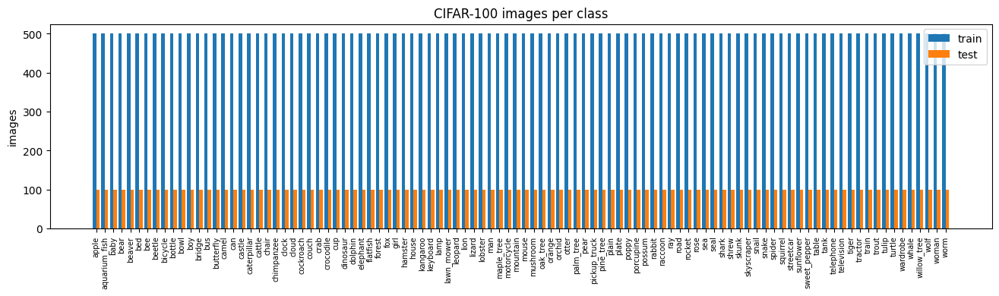

Train: min 500, max 500 per class | Test: min 100, max 100 per class -> the dataset is perfectly balanced


In [ ]:
train_counts = np.bincount(c100_train_y, minlength=NUM_CLASSES)
test_counts = np.bincount(c100_test_y, minlength=NUM_CLASSES)
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.bar(np.arange(NUM_CLASSES) - 0.2, train_counts, width=0.4, label="train")
ax.bar(np.arange(NUM_CLASSES) + 0.2, test_counts, width=0.4, label="test")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
ax.set_ylabel("images"); ax.set_title("CIFAR-100 images per class"); ax.legend()
save_fig("eda_cifar100_class_distribution.png"); plt.show()
print(f"Train: min {train_counts.min()}, max {train_counts.max()} per class | "
      f"Test: min {test_counts.min()}, max {test_counts.max()} per class -> the dataset is perfectly balanced")

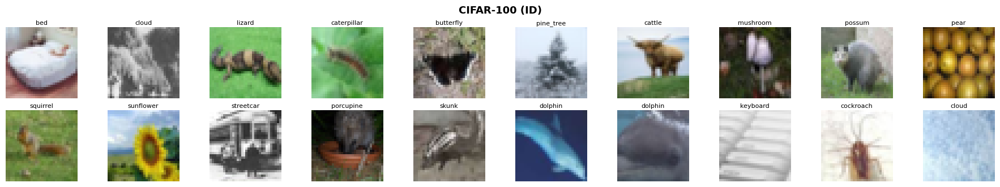

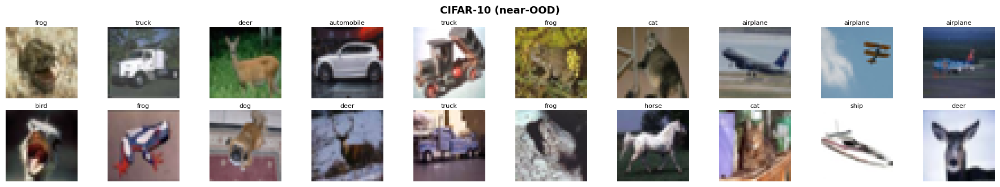

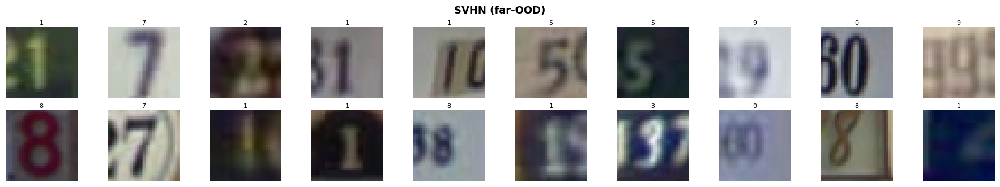

In [ ]:
def show_grid(x, titles, title, fname, n=20):
    fig, axes = plt.subplots(
        2, n // 2,
        figsize=(n * 0.9, 3.2),     # a bit taller to leave room for the titles
        layout="constrained"        # reserves space for the suptitle automatically
    )
    for ax, img, t in zip(axes.ravel(), x[:n], titles[:n]):
        ax.imshow(img.transpose(1, 2, 0))
        ax.set_title(str(t), fontsize=8, pad=3)
        ax.axis("off")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    save_fig(fname)
    plt.show()

rng = np.random.default_rng(0)
i = rng.choice(len(c100_train_x), 20, replace=False)
show_grid(c100_train_x[i], [CLASS_NAMES[c] for c in c100_train_y[i]], "CIFAR-100 (ID)", "eda_samples_cifar100.png")
i = rng.choice(len(c10_x), 20, replace=False)
show_grid(c10_x[i], c10_labels[i], "CIFAR-10 (near-OOD)", "eda_samples_cifar10.png")
i = rng.choice(len(svhn_x), 20, replace=False)
show_grid(svhn_x[i], svhn_y[i], "SVHN (far-OOD)", "eda_samples_svhn.png")

,mean_R,mean_G,mean_B,std_R,std_G,std_B,brightness
CIFAR-100 train,0.5071,0.4865,0.4409,0.2673,0.2564,0.2762,0.4782
CIFAR-100 test,0.5088,0.4874,0.4419,0.2683,0.2574,0.2771,0.4794
CIFAR-10,0.4942,0.4851,0.4504,0.2467,0.2429,0.2616,0.4766
SVHN,0.4524,0.4525,0.4690,0.2194,0.2266,0.2285,0.4580


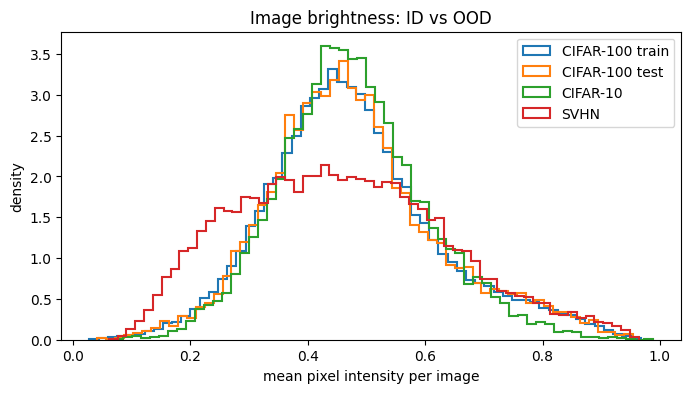

In [ ]:
def pixel_stats(x):
    v = x.astype(np.float32) / 255.0
    return {f"mean_{c}": v[:, k].mean() for k, c in enumerate("RGB")} | \
           {f"std_{c}": v[:, k].std() for k, c in enumerate("RGB")} | {"brightness": v.mean()}

datasets_eda = {"CIFAR-100 train": c100_train_x, "CIFAR-100 test": c100_test_x, "CIFAR-10": c10_x, "SVHN": svhn_x}
pix = pd.DataFrame({k: pixel_stats(v) for k, v in datasets_eda.items()}).T.round(4)
pix.to_csv(os.path.join(DIRS["tables"], "eda_pixel_statistics.csv"))
display(pix)

fig, ax = plt.subplots(figsize=(8, 4))
for name, x in datasets_eda.items():
    ax.hist(x.reshape(len(x), -1).mean(1) / 255.0, bins=60, histtype="step", density=True, label=name, linewidth=1.5)
ax.set_xlabel("mean pixel intensity per image"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Image brightness: ID vs OOD")
save_fig("eda_brightness_histogram.png"); plt.show()

# 5. Preprocessing

In [ ]:
VAL_PER_CLASS = 50          # 50 x 100 classes = 5,000 validation images
VAL_SEED = 12345

rng = np.random.default_rng(VAL_SEED)
val_idx = np.sort(np.concatenate([rng.choice(np.where(c100_train_y == c)[0], VAL_PER_CLASS, replace=False)
                                  for c in range(NUM_CLASSES)]))
pool_idx = np.setdiff1d(np.arange(len(c100_train_y)), val_idx)
N_POOL = len(pool_idx)
np.save(os.path.join(DIRS["preprocessing"], "validation_indices.npy"), val_idx)
np.save(os.path.join(DIRS["preprocessing"], "pool_indices.npy"), pool_idx)
print(f"Selection pool: {N_POOL} images | validation: {len(val_idx)} images "
      f"({VAL_PER_CLASS} per class) | CIFAR-100 test: {len(c100_test_y)}")

Selection pool: 45000 images | validation: 5000 images (50 per class) | CIFAR-100 test: 10000


In [ ]:
MODEL_NAME = "google/vit-base-patch16-224"

processor = ViTImageProcessor.from_pretrained(MODEL_NAME)
IMG_SIZE = processor.size["height"]
IMG_MEAN, IMG_STD = list(processor.image_mean), list(processor.image_std)
processor.save_pretrained(os.path.join(DIRS["preprocessing"], "vit_image_processor"))
print(f"Input size: {IMG_SIZE}x{IMG_SIZE} | mean: {IMG_MEAN} | std: {IMG_STD}")

Input size: 224x224 | mean: [0.5, 0.5, 0.5] | std: [0.5, 0.5, 0.5]


In [ ]:
MEAN_T = torch.tensor(IMG_MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(IMG_STD, device=device).view(1, 3, 1, 1)
CROP_PADDING = 4

def preprocess(x_uint8, train=False):
    x = x_uint8.float() / 255.0
    if train:
        B, _, H, W = x.shape
        xp = F.pad(x, (CROP_PADDING,) * 4)
        oy = torch.randint(0, 2 * CROP_PADDING + 1, (B,), device=x.device)
        ox = torch.randint(0, 2 * CROP_PADDING + 1, (B,), device=x.device)
        rows = (oy[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
        cols = (ox[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
        x = xp[torch.arange(B, device=x.device)[:, None, None, None],
               torch.arange(3, device=x.device)[None, :, None, None], rows, cols]
        flip = torch.rand(B, device=x.device) < 0.5
        x[flip] = x[flip].flip(-1)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return (x - MEAN_T) / STD_T

# move all images to the device once (uint8: about 0.3 GB)
pool_x = torch.from_numpy(c100_train_x[pool_idx]).to(device)
pool_y = torch.from_numpy(c100_train_y[pool_idx]).to(device)
val_x = torch.from_numpy(c100_train_x[val_idx]).to(device)
val_y = torch.from_numpy(c100_train_y[val_idx]).to(device)
test_x = torch.from_numpy(c100_test_x).to(device)
test_y = torch.from_numpy(c100_test_y).to(device)
ood_sets = {"cifar10": torch.from_numpy(c10_x).to(device), "svhn": torch.from_numpy(svhn_x).to(device)}

# check: GPU pipeline vs. the official processor on the same images
sample = c100_test_x[:8]
official = processor(images=[Image.fromarray(im.transpose(1, 2, 0)) for im in sample], return_tensors="pt")["pixel_values"]
ours = preprocess(torch.from_numpy(sample).to(device)).cpu()
print(f"Processor output {tuple(official.shape)} vs GPU pipeline {tuple(ours.shape)} | "
      f"mean absolute difference: {(official - ours).abs().mean():.4f} (small differences come from the resampling filter)")

json.dump({"model": MODEL_NAME, "image_size": IMG_SIZE, "mean": IMG_MEAN, "std": IMG_STD,
           "train_augmentation": f"random crop 32x32 with padding {CROP_PADDING} + horizontal flip, then resize",
           "resize": "bilinear", "validation_per_class": VAL_PER_CLASS, "validation_seed": VAL_SEED,
           "cifar10_ood_images": int(len(c10_x)), "cifar10_ood_seed": OOD_SEED},
          open(os.path.join(DIRS["preprocessing"], "preprocessing_config.json"), "w"), indent=2)

Processor output (8, 3, 224, 224) vs GPU pipeline (8, 3, 224, 224) | mean absolute difference: 0.0022 (small differences come from the resampling filter)


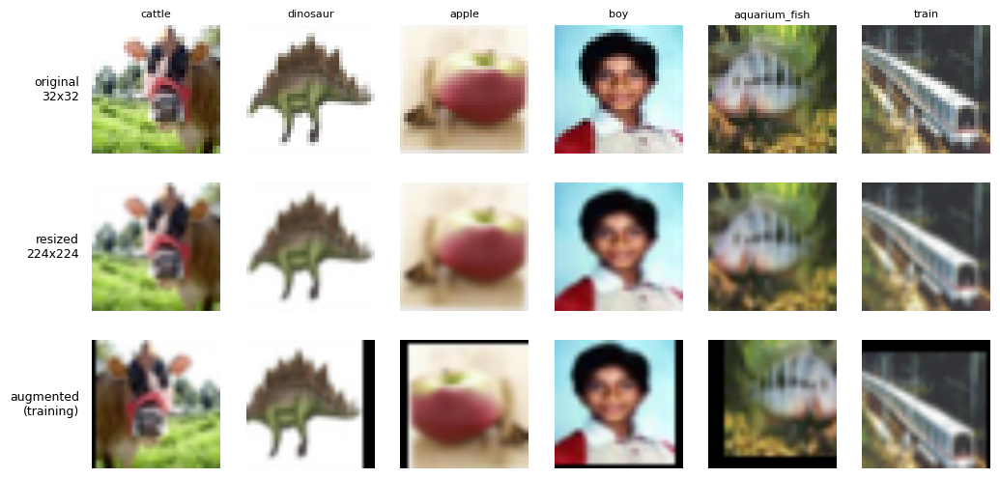

In [ ]:
# what the model actually sees: original, augmented, and resized training images
imgs = pool_x[:6]
aug = preprocess(imgs, train=True)
plain = preprocess(imgs, train=False)
show = lambda t: ((t * STD_T[0] + MEAN_T[0]).clamp(0, 1)).permute(1, 2, 0).cpu().numpy()
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for j in range(6):
    axes[0, j].imshow(imgs[j].permute(1, 2, 0).cpu().numpy()); axes[0, j].set_title(CLASS_NAMES[int(pool_y[j])], fontsize=8)
    axes[1, j].imshow(show(plain[j])); axes[2, j].imshow(show(aug[j]))
for ax in axes.ravel(): ax.axis("off")
for r, label in enumerate(["original\n32x32", f"resized\n{IMG_SIZE}x{IMG_SIZE}", "augmented\n(training)"]):
    axes[r, 0].text(-0.1, 0.5, label, fontsize=9, ha="right", va="center", transform=axes[r, 0].transAxes)
save_fig("preprocessing_examples.png"); plt.show()

# 6. Pretrained model

In [ ]:
base_model = ViTForImageClassification.from_pretrained(MODEL_NAME).to(device).eval()
n_params = sum(p.numel() for p in base_model.parameters())
FEAT_DIM = base_model.config.hidden_size
print(f"{MODEL_NAME}: {n_params/1e6:.1f}M parameters | feature dimension {FEAT_DIM} | "
      f"{base_model.config.num_labels} ImageNet classes")

google/vit-base-patch16-224: 86.6M parameters | feature dimension 768 | 1000 ImageNet classes


In [ ]:
EVAL_BATCH = 256

def amp_ctx():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if USE_AMP else torch.autocast("cpu", enabled=False)

def cls_features(model, pixel_values):
    return model.vit(pixel_values=pixel_values).last_hidden_state[:, 0]

@torch.no_grad()
def infer(model, X, with_logits=True):
    # returns ([CLS] features, logits) as float32 CPU tensors
    model.eval(); feats, logits = [], []
    for i in range(0, len(X), EVAL_BATCH):
        with amp_ctx():
            f = cls_features(model, preprocess(X[i:i + EVAL_BATCH]))
            feats.append(f.float().cpu())
            if with_logits:
                logits.append(model.classifier(f).float().cpu())
    return torch.cat(feats), (torch.cat(logits) if with_logits else None)

# sanity check: ImageNet predictions of the pretrained model on a few CIFAR-100 test images
_, lg = infer(base_model, test_x[:5])
for j, p in enumerate(lg.argmax(1).tolist()):
    print(f"CIFAR-100 label: {CLASS_NAMES[int(test_y[j])]:<15} -> pretrained ImageNet prediction: {base_model.config.id2label[p]}")

CIFAR-100 label: mountain        -> pretrained ImageNet prediction: solar dish, solar collector, solar furnace
CIFAR-100 label: forest          -> pretrained ImageNet prediction: worm fence, snake fence, snake-rail fence, Virginia fence
CIFAR-100 label: seal            -> pretrained ImageNet prediction: sea lion
CIFAR-100 label: mushroom        -> pretrained ImageNet prediction: bolete
CIFAR-100 label: sea             -> pretrained ImageNet prediction: airliner


# 7. Pretrained embeddings

In [ ]:
EMB_PATH = os.path.join(DIRS["embeddings"], "pool_embeddings_pretrained.npy")
if os.path.exists(EMB_PATH):
    # saved earlier: the subsets of Section 8 were built from exactly these embeddings
    pool_emb = F.normalize(torch.from_numpy(np.load(EMB_PATH)).float(), dim=1)
    print(f"Loaded the pretrained pool embeddings saved earlier from Drive -> {tuple(pool_emb.shape)}")
else:
    t0 = time.time()
    pool_emb, _ = infer(base_model, pool_x, with_logits=False)
    pool_emb = F.normalize(pool_emb, dim=1)
    np.save(EMB_PATH, pool_emb.numpy().astype(np.float16))
    print(f"Embedded {len(pool_emb)} pool images in {time.time()-t0:.1f}s -> {tuple(pool_emb.shape)}")

Embedded 45000 pool images in 60.1s -> (45000, 768)


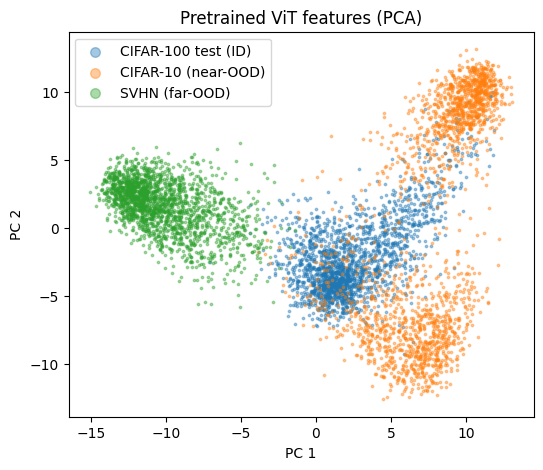

In [ ]:
# 2-D PCA view of the pretrained feature space: ID vs. OOD
n_vis = min(2000, len(test_x), len(ood_sets["cifar10"]), len(ood_sets["svhn"]))
vis = {"CIFAR-100 test (ID)": infer(base_model, test_x[:n_vis], False)[0],
       "CIFAR-10 (near-OOD)": infer(base_model, ood_sets["cifar10"][:n_vis], False)[0],
       "SVHN (far-OOD)": infer(base_model, ood_sets["svhn"][:n_vis], False)[0]}
pca = PCA(2, random_state=0).fit(torch.cat(list(vis.values())).numpy())
plt.figure(figsize=(6, 5))
for name, f in vis.items():
    z = pca.transform(f.numpy()); plt.scatter(z[:, 0], z[:, 1], s=3, alpha=0.4, label=name)
plt.legend(markerscale=4); plt.title("Pretrained ViT features (PCA)"); plt.xlabel("PC 1"); plt.ylabel("PC 2")
save_fig("pretrained_features_pca.png"); plt.show()

# 8. Training subsets

In [ ]:
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
STRATEGIES = ["random", "representative"]
SEEDS = [0, 1, 2]
KMEANS_ITERS = 50       # maximum Lloyd iterations (stops earlier if assignments no longer change)
NEIGHBOURS = 20         # nearest images retrieved per centroid (used only when centroids share a nearest image)

def kmeans_lloyd(X, k, iters, seed, chunk=2048):
    # standard k-means: k random images as initial centroids, then assignment / update steps
    g = torch.Generator().manual_seed(seed)
    n = X.shape[0]
    C = X[torch.randperm(n, generator=g)[:k].to(X.device)].clone()
    prev, n_iter = None, 0
    for n_iter in range(1, iters + 1):
        c2 = (C * C).sum(1)
        assign = torch.empty(n, dtype=torch.long, device=X.device)
        for i in range(0, n, chunk):
            assign[i:i + chunk] = (c2[None, :] - 2 * X[i:i + chunk] @ C.T).argmin(1)
        if prev is not None and torch.equal(assign, prev):
            break
        prev = assign
        counts = torch.bincount(assign, minlength=k)
        sums = torch.zeros_like(C).index_add_(0, assign, X)
        nonempty = counts > 0
        C[nonempty] = sums[nonempty] / counts[nonempty, None]
        if (~nonempty).any():                                    # empty cluster -> new random image
            C[~nonempty] = X[torch.randint(0, n, (int((~nonempty).sum()),), generator=g).to(X.device)]
    return C, n_iter

def nearest_images(X, C, m, chunk=1024):
    # the m pool images nearest to every centroid, nearest first
    x2 = (X * X).sum(1); dist, idx = [], []
    for i in range(0, C.shape[0], chunk):
        c = C[i:i + chunk]
        d = (x2[None, :] - 2 * c @ X.T + (c * c).sum(1)[:, None]).clamp_min(0)
        v, j = d.topk(m, dim=1, largest=False)
        dist.append(v.cpu()); idx.append(j.cpu())
    return torch.cat(dist).numpy(), torch.cat(idx).numpy()

def random_subset(n_select, seed):
    return np.sort(np.random.default_rng(seed).choice(N_POOL, n_select, replace=False))

def representative_subset(n_select, seed):
    X = pool_emb.to(device).float()
    C, n_iter = kmeans_lloyd(X, n_select, KMEANS_ITERS, seed)
    dist, nn_idx = nearest_images(X, C, min(NEIGHBOURS, N_POOL))
    taken = np.zeros(N_POOL, dtype=bool); chosen = []
    for c in np.argsort(dist[:, 0], kind="stable"):              # closest centroid-image pairs first
        for j in nn_idx[c]:
            if not taken[j]:
                taken[j] = True; chosen.append(j); break
    chosen = np.array(chosen, dtype=np.int64)
    if len(chosen) < n_select:                                    # practically never needed
        extra = np.random.default_rng(seed).choice(np.where(~taken)[0], n_select - len(chosen), replace=False)
        chosen = np.concatenate([chosen, extra])
    return np.sort(chosen), C.cpu().numpy().astype(np.float16), n_iter

labels_pool = pool_y.cpu().numpy()
_paths = {(s, f, sd): os.path.join(DIRS["subsets"], f"{s}_{f:.2f}_seed{sd}.npy")
          for s in STRATEGIES for f in FRACTIONS for sd in SEEDS}
_table = os.path.join(DIRS["tables"], "subset_class_balance.csv")
if all(os.path.exists(p) for p in _paths.values()):
    # the subsets used for training are loaded, never rebuilt (k-means on the GPU is not bit-identical)
    SUBSETS = {k: np.load(p) for k, p in _paths.items()}
    if os.path.exists(_table):
        subset_table = pd.read_csv(_table)
    else:
        subset_table = pd.DataFrame([dict(strategy=s, fraction=f, seed=sd, n_train=len(idx), kmeans_iterations=np.nan,
                                          classes_present=int((np.bincount(labels_pool[idx], minlength=NUM_CLASSES) > 0).sum()),
                                          min_per_class=int(np.bincount(labels_pool[idx], minlength=NUM_CLASSES).min()),
                                          max_per_class=int(np.bincount(labels_pool[idx], minlength=NUM_CLASSES).max()),
                                          std_per_class=round(float(np.bincount(labels_pool[idx], minlength=NUM_CLASSES).std()), 2))
                                     for (s, f, sd), idx in SUBSETS.items()])
        subset_table.to_csv(_table, index=False)
    print(f"Loaded the {len(SUBSETS)} subsets saved earlier from Drive")
else:
    subset_rows, SUBSETS = [], {}
    t0 = time.time()
    for strategy in STRATEGIES:
        for frac in FRACTIONS:
            for seed in SEEDS:
                n_select = int(round(frac * N_POOL)); n_iter = 0
                if frac >= 1.0:
                    idx = np.arange(N_POOL)
                elif strategy == "random":
                    idx = random_subset(n_select, seed)
                else:
                    idx, centroids, n_iter = representative_subset(n_select, seed)
                    np.save(os.path.join(DIRS["subsets"], f"centroids_{frac:.2f}_seed{seed}.npy"), centroids)
                assert len(idx) == n_select and len(np.unique(idx)) == n_select
                np.save(_paths[(strategy, frac, seed)], idx)
                SUBSETS[(strategy, frac, seed)] = idx
                cnt = np.bincount(labels_pool[idx], minlength=NUM_CLASSES)
                subset_rows.append(dict(strategy=strategy, fraction=frac, seed=seed, n_train=n_select,
                                        kmeans_iterations=n_iter, classes_present=int((cnt > 0).sum()),
                                        min_per_class=int(cnt.min()), max_per_class=int(cnt.max()),
                                        std_per_class=round(float(cnt.std()), 2)))
    subset_table = pd.DataFrame(subset_rows)
    subset_table.to_csv(_table, index=False)
    print(f"Built {len(subset_table)} subsets in {time.time()-t0:.1f}s")
subset_table.groupby(["strategy", "fraction"])[["n_train", "classes_present", "min_per_class",
                                                 "max_per_class", "std_per_class"]].mean().round(2)

Built 36 subsets in 22.3s


n_train  classes_present  min_per_class  \
strategy       fraction                                            
random         0.05       2250.0            100.0          12.33   
               0.10       4500.0            100.0          31.33   
               0.25      11250.0            100.0          89.33   
               0.50      22500.0            100.0         197.00   
               0.75      33750.0            100.0         317.00   
               1.00      45000.0            100.0         450.00   
representative 0.05       2250.0            100.0          12.00   
               0.10       4500.0            100.0          29.00   
               0.25      11250.0            100.0          88.67   
               0.50      22500.0            100.0         197.00   
               0.75      33750.0            100.0         311.67   
               1.00      45000.0            100.0         450.00   

                         max_per_class  std_per_class  
strategy       fraction                                
random         0.05              35.33           4.74  
               0.10              64.67           6.39  
               0.25             135.33           9.13  
               0.50             249.33          10.83  
               0.75             358.33           8.80  
               1.00             450.00           0.00  
representative 0.05              35.00           4.72  
               0.10              61.00           6.72  
               0.25             136.67           9.45  
               0.50             257.00          11.40  
               0.75             362.00           9.59  
               1.00             450.00           0.00

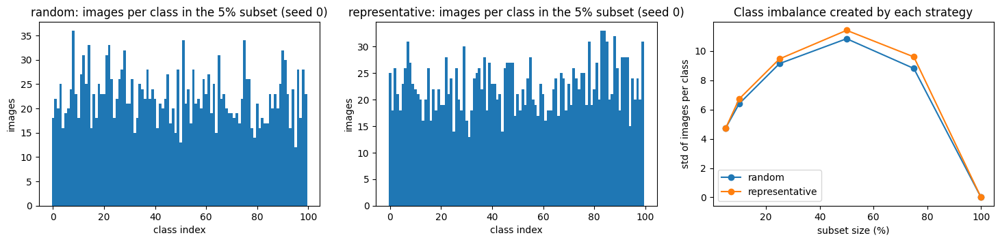

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, s in zip(axes[:2], STRATEGIES):
    idx = SUBSETS[(s, FRACTIONS[0], SEEDS[0])]
    ax.bar(range(NUM_CLASSES), np.bincount(labels_pool[idx], minlength=NUM_CLASSES), width=1.0)
    ax.set_title(f"{s}: images per class in the {FRACTIONS[0]:.0%} subset (seed {SEEDS[0]})")
    ax.set_xlabel("class index"); ax.set_ylabel("images")
for s in STRATEGIES:
    d = subset_table[subset_table.strategy == s].groupby("fraction").std_per_class.mean()
    axes[2].plot(d.index * 100, d.values, marker="o", label=s)
axes[2].set_xlabel("subset size (%)"); axes[2].set_ylabel("std of images per class"); axes[2].legend()
axes[2].set_title("Class imbalance created by each strategy")
save_fig("subset_class_balance.png"); plt.show()

# 9. Fine-tuning

In [ ]:
TRAIN_STEPS = 1000          # same for every subset size
BATCH_SIZE = 128
LR_BACKBONE = 1e-5
LR_HEAD = 1e-4
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05
GRAD_CLIP = 1.0
LOG_EVERY = 250

def build_finetune_model(seed):
    torch.manual_seed(seed)                                    # seeds the new classification head
    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_CLASSES, ignore_mismatched_sizes=True,
        id2label=dict(enumerate(CLASS_NAMES)), label2id={n: i for i, n in enumerate(CLASS_NAMES)})
    return model.to(device)

def make_optimizer(model):
    head = {id(p) for p in model.classifier.parameters()}
    groups = {}
    for n, p in model.named_parameters():
        part = "head" if id(p) in head else "backbone"
        decay = p.ndim > 1 and "cls_token" not in n and "position_embeddings" not in n
        groups.setdefault((part, decay), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": LR_HEAD if part == "head" else LR_BACKBONE,
                               "weight_decay": WEIGHT_DECAY if decay else 0.0}
                              for (part, decay), ps in groups.items()])

def lr_lambda(step):
    warm = max(1, int(WARMUP_FRAC * TRAIN_STEPS))
    if step < warm:
        return (step + 1) / warm
    return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, TRAIN_STEPS - warm)))

def train_one(subset_idx, seed):
    set_seed(seed)
    model = build_finetune_model(seed).train()
    opt = make_optimizer(model)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and AMP_DTYPE == torch.float16))
    idx_t = torch.as_tensor(subset_idx, device=device)
    g = torch.Generator().manual_seed(seed)
    order = torch.empty(0, dtype=torch.long)
    losses, t0 = [], time.time()
    for step in range(TRAIN_STEPS):
        while len(order) < BATCH_SIZE:                           # reshuffle each pass over the subset
            order = torch.cat([order, torch.randperm(len(idx_t), generator=g)])
        b, order = order[:BATCH_SIZE].to(device), order[BATCH_SIZE:]
        xb, yb = preprocess(pool_x[idx_t[b]], train=True), pool_y[idx_t[b]]
        with amp_ctx():
            loss = F.cross_entropy(model(pixel_values=xb).logits, yb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if (step + 1) % LOG_EVERY == 0 or step + 1 == TRAIN_STEPS:
            print(f"    step {step+1:>5}/{TRAIN_STEPS}  loss {np.mean(losses[-LOG_EVERY:]):.4f}  "
                  f"{(time.time()-t0)/60:.1f} min")
    return model.eval(), losses, (time.time() - t0) / 60

# 10. Evaluation metrics

In [ ]:
ECE_BINS = 15
CKA_N = 2000                # ID test images used for feature drift
CKA_SEED = 0

def ood_scores(logits):
    return {"msp": F.softmax(logits, 1).max(1).values.numpy(), "energy": torch.logsumexp(logits, 1).numpy()}

def auroc(id_s, ood_s):
    return roc_auc_score(np.r_[np.ones(len(id_s)), np.zeros(len(ood_s))], np.r_[id_s, ood_s])

def fpr_at_95_tpr(id_s, ood_s):
    threshold = np.percentile(id_s, 5)                 # 95% of ID scores are above it
    return float((ood_s >= threshold).mean())

def ece(logits, labels, n_bins=ECE_BINS):
    conf, pred = F.softmax(logits, 1).max(1)
    acc = (pred == labels).float(); edges = torch.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

def fit_temperature(logits, labels):
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(logits / log_t.exp(), labels); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.detach().exp())

def linear_cka(X, Y):
    X = X.double() - X.double().mean(0); Y = Y.double() - Y.double().mean(0)
    return float((Y.T @ X).norm() ** 2 / ((X.T @ X).norm() * (Y.T @ Y).norm()))

# fixed images for feature drift and their pretrained features (computed once)
cka_idx = np.sort(np.random.default_rng(CKA_SEED).choice(len(test_y), min(CKA_N, len(test_y)), replace=False))
pre_feats_cka, _ = infer(base_model, test_x[torch.as_tensor(cka_idx, device=device)], with_logits=False)
np.save(os.path.join(DIRS["embeddings"], "cka_test_indices.npy"), cka_idx)
np.save(os.path.join(DIRS["embeddings"], "cka_pretrained_features.npy"), pre_feats_cka.numpy().astype(np.float16))

def evaluate(model):
    r, pred_store = {}, {}
    feats_id, logits_id = infer(model, test_x)
    y = test_y.cpu(); pred = logits_id.argmax(1)
    r["id_acc"] = (pred == y).float().mean().item()
    r["id_bal_acc"] = balanced_accuracy_score(y.numpy(), pred.numpy())
    _, logits_val = infer(model, val_x)
    r["val_acc"] = (logits_val.argmax(1) == val_y.cpu()).float().mean().item()
    s_id = ood_scores(logits_id)
    pred_store["cifar100_test"], pred_store["cifar100_val"] = logits_id, logits_val
    for name, X in ood_sets.items():
        _, logits_ood = infer(model, X); s_ood = ood_scores(logits_ood); pred_store[name] = logits_ood
        for sc in ["msp", "energy"]:
            r[f"auroc_{sc}_{name}"] = auroc(s_id[sc], s_ood[sc])
            r[f"fpr95_{sc}_{name}"] = fpr_at_95_tpr(s_id[sc], s_ood[sc])
    r["ece"] = ece(logits_id, y)
    T = fit_temperature(logits_val, val_y.cpu())
    r["temperature"], r["ece_after_temp_scaling"] = T, ece(logits_id / T, y)
    r["cka"] = linear_cka(pre_feats_cka, feats_id[cka_idx])
    r["feature_drift"] = 1 - r["cka"]
    return r, pred_store

# self-checks of the metric functions on known answers
a, b = np.array([3., 4., 5.]), np.array([0., 1., 2.])
assert auroc(a, b) == 1.0 and fpr_at_95_tpr(a, b) == 0.0 and auroc(b, a) == 0.0
f = torch.randn(50, 8); assert abs(linear_cka(f, f) - 1) < 1e-9 and abs(linear_cka(f, 3 * f + 1) - 1) < 1e-9
print("Metric self-checks passed. Pretrained reference features:", tuple(pre_feats_cka.shape))

# the pretrained model is no longer needed
del base_model; gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()

Metric self-checks passed. Pretrained reference features: (2000, 768)


# 11. Run all experiments

In [ ]:
SAVE_MODELS = True
RES_PATH = os.path.join(DIRS["tables"], "results_all_runs.csv")
LOSS_PATH = os.path.join(DIRS["tables"], "training_loss_curves.csv")
jobs = [(s, f, sd) for sd in SEEDS for f in FRACTIONS for s in STRATEGIES]

if os.path.exists(RES_PATH) and os.path.exists(LOSS_PATH) and len(pd.read_csv(RES_PATH)) == len(jobs):
    # every run is finished and saved: load the results and print the training log
    res = pd.read_csv(RES_PATH)
    res["shared_full_run"] = res.shared_full_run.astype(str).str.lower().eq("true")
    _lc = pd.read_csv(LOSS_PATH, index_col="step")
    loss_curves = {c: _lc[c].dropna().tolist() for c in _lc.columns}
    results = res.to_dict("records")
    for k, (strategy, frac, seed) in enumerate(jobs, 1):
        if frac >= 1.0 and strategy != "random": continue
        run = f"{strategy}_{frac:.2f}_seed{seed}"
        row = res[(res.strategy == strategy) & (res.fraction == frac) & (res.seed == seed)].iloc[0]
        print(f"[{k}/{len(jobs)}] {run}  ({int(row.n_train)} training images)")
        for s in range(LOG_EVERY, TRAIN_STEPS + 1, LOG_EVERY):
            print(f"    step {s:>5}/{TRAIN_STEPS}  loss {np.mean(loss_curves[run][s-LOG_EVERY:s]):.4f}  "
                  f"{row.train_minutes * s / TRAIN_STEPS:.1f} min")
        print(f"    ID acc {row['id_acc']:.4f} | bal acc {row['id_bal_acc']:.4f} | "
              f"AUROC(energy) CIFAR-10 {row['auroc_energy_cifar10']:.4f} SVHN {row['auroc_energy_svhn']:.4f} | "
              f"ECE {row['ece']:.4f} | CKA {row['cka']:.4f}")
    print(f"Finished {len(res)} result rows (all saved on Drive; training time {res[~res.shared_full_run].train_minutes.sum():.1f} min)")
else:

    results, loss_curves = [], {}
    jobs = [(s, f, sd) for sd in SEEDS for f in FRACTIONS for s in STRATEGIES]
    t_all = time.time()
    for k, (strategy, frac, seed) in enumerate(jobs, 1):
        if frac >= 1.0 and strategy != "random":                    # identical full-data run
            shared = next(r for r in results if r["strategy"] == "random" and r["fraction"] == frac and r["seed"] == seed)
            results.append({**shared, "strategy": strategy, "shared_full_run": True})
            continue
        run = f"{strategy}_{frac:.2f}_seed{seed}"
        print(f"[{k}/{len(jobs)}] {run}  ({len(SUBSETS[(strategy, frac, seed)])} training images)")
        model, losses, minutes = train_one(SUBSETS[(strategy, frac, seed)], seed)
        metrics, preds = evaluate(model)
        loss_curves[run] = losses
        np.savez_compressed(os.path.join(DIRS["predictions"], f"logits_{run}.npz"),
                            **{k2: v.numpy().astype(np.float16) for k2, v in preds.items()})
        if SAVE_MODELS:
            model.to(torch.float16).save_pretrained(os.path.join(DIRS["models"], run))
        row = dict(strategy=strategy, fraction=frac, seed=seed, n_train=len(SUBSETS[(strategy, frac, seed)]),
                   train_minutes=round(minutes, 2), shared_full_run=False, **metrics)
        results.append(row)
        pd.DataFrame(results).to_csv(os.path.join(DIRS["tables"], "results_all_runs.csv"), index=False)
        print(f"    ID acc {row['id_acc']:.4f} | bal acc {row['id_bal_acc']:.4f} | "
              f"AUROC(energy) CIFAR-10 {row['auroc_energy_cifar10']:.4f} SVHN {row['auroc_energy_svhn']:.4f} | "
              f"ECE {row['ece']:.4f} | CKA {row['cka']:.4f}")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()

    res = pd.DataFrame(results)
    res.to_csv(os.path.join(DIRS["tables"], "results_all_runs.csv"), index=False)
    pd.DataFrame({k: pd.Series(v) for k, v in loss_curves.items()}).to_csv(
        os.path.join(DIRS["tables"], "training_loss_curves.csv"), index_label="step")
    print(f"Finished {len(res)} result rows in {(time.time()-t_all)/60:.1f} min")

[1/36] random_0.05_seed0  (2250 training images)
    step   250/1000  loss 2.3418  2.4 min
    step   500/1000  loss 0.1175  4.7 min
    step   750/1000  loss 0.0261  7.1 min
    step  1000/1000  loss 0.0190  9.5 min
    ID acc 0.8658 | bal acc 0.8658 | AUROC(energy) CIFAR-10 0.9205 SVHN 0.9726 | ECE 0.0307 | CKA 0.7666
[2/36] representative_0.05_seed0  (2250 training images)
    step   250/1000  loss 2.3015  2.4 min
    step   500/1000  loss 0.0971  4.7 min
    step   750/1000  loss 0.0234  7.1 min
    step  1000/1000  loss 0.0176  9.5 min
    ID acc 0.8710 | bal acc 0.8710 | AUROC(energy) CIFAR-10 0.9299 SVHN 0.9748 | ECE 0.0327 | CKA 0.7654
[3/36] random_0.10_seed0  (4500 training images)
    step   250/1000  loss 2.4519  2.4 min
    step   500/1000  loss 0.2308  4.7 min
    step   750/1000  loss 0.0609  7.1 min
    step  1000/1000  loss 0.0404  9.5 min
    ID acc 0.8861 | bal acc 0.8861 | AUROC(energy) CIFAR-10 0.9278 SVHN 0.9699 | ECE 0.0235 | CKA 0.7498
[4/36] representative_0.10

# 12. Results tables

In [ ]:
main_cols = ["id_acc", "id_bal_acc", "auroc_energy_cifar10", "fpr95_energy_cifar10",
             "auroc_energy_svhn", "fpr95_energy_svhn", "ece", "ece_after_temp_scaling", "cka"]
grp = res.groupby(["fraction", "strategy"])[main_cols]
mean, std = grp.mean(), grp.std().fillna(0)
main_table = mean.round(4).astype(str) + " ± " + std.round(4).astype(str)
main_table.index = pd.MultiIndex.from_tuples([(f"{f:.0%}", s) for f, s in main_table.index], names=["subset", "strategy"])
mean.to_csv(os.path.join(DIRS["tables"], "results_mean.csv"))
std.to_csv(os.path.join(DIRS["tables"], "results_std.csv"))
main_table.to_csv(os.path.join(DIRS["tables"], "results_mean_std.csv"))
main_table

id_acc       id_bal_acc auroc_energy_cifar10  \
subset strategy                                                                
5%     random          0.8653 ± 0.0027  0.8653 ± 0.0027      0.9281 ± 0.0069   
       representative  0.8672 ± 0.0044  0.8672 ± 0.0044      0.9295 ± 0.0039   
10%    random          0.8849 ± 0.0011  0.8849 ± 0.0011      0.9358 ± 0.0074   
       representative   0.887 ± 0.0027   0.887 ± 0.0027      0.9373 ± 0.0057   
25%    random          0.8996 ± 0.0007  0.8996 ± 0.0007      0.9431 ± 0.0053   
       representative  0.9004 ± 0.0008  0.9004 ± 0.0008      0.9461 ± 0.0045   
50%    random          0.9028 ± 0.0011  0.9028 ± 0.0011      0.9459 ± 0.0052   
       representative  0.9045 ± 0.0011  0.9045 ± 0.0011      0.9456 ± 0.0053   
75%    random          0.9056 ± 0.0015  0.9056 ± 0.0015      0.9454 ± 0.0051   
       representative   0.9042 ± 0.002   0.9042 ± 0.002      0.9455 ± 0.0052   
100%   random          0.9053 ± 0.0008  0.9053 ± 0.0008       0.946 ± 0.0037   
       representative  0.9053 ± 0.0008  0.9053 ± 0.0008       0.946 ± 0.0037   

                      fpr95_energy_cifar10 auroc_energy_svhn  \
subset strategy                                                
5%     random               0.308 ± 0.0152   0.9639 ± 0.0078   
       representative      0.3196 ± 0.0064   0.9679 ± 0.0069   
10%    random              0.2827 ± 0.0034    0.968 ± 0.0035   
       representative      0.2867 ± 0.0095   0.9741 ± 0.0091   
25%    random              0.2566 ± 0.0116   0.9724 ± 0.0037   
       representative      0.2473 ± 0.0132   0.9748 ± 0.0049   
50%    random              0.2519 ± 0.0022   0.9749 ± 0.0019   
       representative      0.2477 ± 0.0077   0.9753 ± 0.0027   
75%    random               0.249 ± 0.0059   0.9742 ± 0.0034   
       representative       0.248 ± 0.0047     0.974 ± 0.005   
100%   random              0.2488 ± 0.0063   0.9753 ± 0.0007   
       representative      0.2488 ± 0.0063   0.9753 ± 0.0007   

                      fpr95_energy_svhn              ece  \
subset strategy                                            
5%     random           0.1481 ± 0.0272  0.0319 ± 0.0071   
       representative   0.1325 ± 0.0381   0.032 ± 0.0011   
10%    random           0.1291 ± 0.0126  0.0246 ± 0.0023   
       representative   0.1044 ± 0.0337  0.0243 ± 0.0012   
25%    random           0.1077 ± 0.0122  0.0493 ± 0.0056   
       representative   0.0992 ± 0.0227    0.05 ± 0.0026   
50%    random           0.1041 ± 0.0081   0.061 ± 0.0049   
       representative   0.0974 ± 0.0088  0.0632 ± 0.0028   
75%    random           0.1046 ± 0.0121  0.0654 ± 0.0021   
       representative   0.1031 ± 0.0159  0.0664 ± 0.0038   
100%   random            0.1014 ± 0.005  0.0669 ± 0.0027   
       representative    0.1014 ± 0.005  0.0669 ± 0.0027   

                      ece_after_temp_scaling              cka  
subset strategy                                                
5%     random                0.0261 ± 0.0031  0.7659 ± 0.0008  
       representative        0.0286 ± 0.0048  0.7648 ± 0.0043  
10%    random                0.0209 ± 0.0013    0.75 ± 0.0024  
       representative        0.0216 ± 0.0022  0.7526 ± 0.0047  
25%    random                 0.0154 ± 0.002  0.7562 ± 0.0004  
       representative        0.0142 ± 0.0011  0.7554 ± 0.0008  
50%    random                0.0123 ± 0.0016  0.7643 ± 0.0014  
       representative        0.0119 ± 0.0016   0.7619 ± 0.002  
75%    random                0.0114 ± 0.0018  0.7631 ± 0.0016  
       representative         0.012 ± 0.0006  0.7667 ± 0.0014  
100%   random                 0.0121 ± 0.001  0.7656 ± 0.0004  
       representative         0.0121 ± 0.001  0.7656 ± 0.0004

In [ ]:
ood_cols = [c for c in res.columns if c.startswith(("auroc_", "fpr95_"))]
ood_table = res.groupby(["fraction", "strategy"])[ood_cols].mean().round(4)
ood_table.to_csv(os.path.join(DIRS["tables"], "results_ood_both_scores.csv"))
ood_table

auroc_msp_cifar10  fpr95_msp_cifar10  \
fraction strategy                                               
0.05     random                     0.9186             0.3639   
         representative             0.9181             0.3633   
0.10     random                     0.9249             0.3387   
         representative             0.9246             0.3368   
0.25     random                     0.9291             0.3192   
         representative             0.9317             0.3122   
0.50     random                     0.9306             0.3148   
         representative             0.9309             0.3124   
0.75     random                     0.9323             0.3067   
         representative             0.9314             0.3115   
1.00     random                     0.9316             0.3083   
         representative             0.9316             0.3083   

                         auroc_energy_cifar10  fpr95_energy_cifar10  \
fraction strategy                                                     
0.05     random                        0.9281                0.3080   
         representative                0.9295                0.3196   
0.10     random                        0.9358                0.2827   
         representative                0.9373                0.2867   
0.25     random                        0.9431                0.2566   
         representative                0.9461                0.2473   
0.50     random                        0.9459                0.2519   
         representative                0.9456                0.2477   
0.75     random                        0.9454                0.2490   
         representative                0.9455                0.2480   
1.00     random                        0.9460                0.2488   
         representative                0.9460                0.2488   

                         auroc_msp_svhn  fpr95_msp_svhn  auroc_energy_svhn  \
fraction strategy                                                            
0.05     random                  0.9455          0.2413             0.9639   
         representative          0.9518          0.2133             0.9679   
0.10     random                  0.9482          0.2262             0.9680   
         representative          0.9598          0.1745             0.9741   
0.25     random                  0.9539          0.1987             0.9724   
         representative          0.9557          0.1919             0.9748   
0.50     random                  0.9547          0.1998             0.9749   
         representative          0.9556          0.1931             0.9753   
0.75     random                  0.9540          0.2022             0.9742   
         representative          0.9534          0.2007             0.9740   
1.00     random                  0.9555          0.1966             0.9753   
         representative          0.9555          0.1966             0.9753   

                         fpr95_energy_svhn  
fraction strategy                           
0.05     random                     0.1481  
         representative             0.1325  
0.10     random                     0.1291  
         representative             0.1044  
0.25     random                     0.1077  
         representative             0.0992  
0.50     random                     0.1041  
         representative             0.0974  
0.75     random                     0.1046  
         representative             0.1031  
1.00     random                     0.1014  
         representative             0.1014

In [ ]:
diff = (mean.xs("representative", level="strategy") - mean.xs("random", level="strategy")).round(4)
diff.index = [f"{f:.0%}" for f in diff.index]
diff.to_csv(os.path.join(DIRS["tables"], "representative_minus_random.csv"))
diff

,id_acc,id_bal_acc,auroc_energy_cifar10,fpr95_energy_cifar10,auroc_energy_svhn,fpr95_energy_svhn,ece,ece_after_temp_scaling,cka
5%,0.0019,0.0019,0.0014,0.0116,0.0040,-0.0156,0.0000,0.0025,-0.0011
10%,0.0020,0.0020,0.0016,0.0040,0.0061,-0.0248,-0.0003,0.0007,0.0025
25%,0.0009,0.0009,0.0030,-0.0093,0.0024,-0.0085,0.0007,-0.0012,-0.0008
50%,0.0017,0.0017,-0.0003,-0.0042,0.0004,-0.0067,0.0021,-0.0004,-0.0024
75%,-0.0014,-0.0014,0.0001,-0.0010,-0.0001,-0.0015,0.0010,0.0006,0.0036
100%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


# 13. Figures

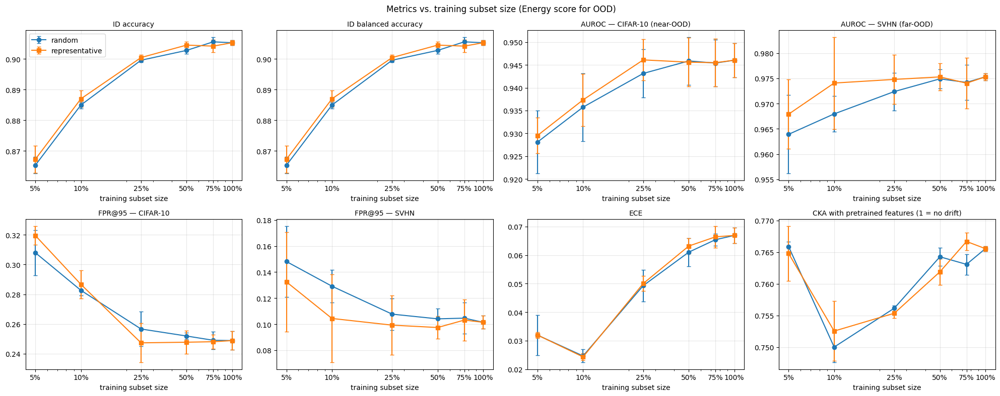

In [ ]:
plot_metrics = [("id_acc", "ID accuracy"), ("id_bal_acc", "ID balanced accuracy"),
                ("auroc_energy_cifar10", "AUROC — CIFAR-10 (near-OOD)"), ("auroc_energy_svhn", "AUROC — SVHN (far-OOD)"),
                ("fpr95_energy_cifar10", "FPR@95 — CIFAR-10"), ("fpr95_energy_svhn", "FPR@95 — SVHN"),
                ("ece", "ECE"), ("cka", "CKA with pretrained features (1 = no drift)")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (col, title) in zip(axes.ravel(), plot_metrics):
    for s, mk in zip(STRATEGIES, ["o", "s"]):
        d = res[res.strategy == s].groupby("fraction")[col]
        ax.errorbar(d.mean().index * 100, d.mean().values, yerr=d.std().fillna(0).values, marker=mk, capsize=3, label=s)
    ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
    ax.set_title(title, fontsize=10); ax.set_xlabel("training subset size"); ax.grid(alpha=0.3)
axes[0, 0].legend(); fig.suptitle("Metrics vs. training subset size (Energy score for OOD)")
plt.tight_layout(); save_fig("metrics_vs_subset_size.png"); plt.show()

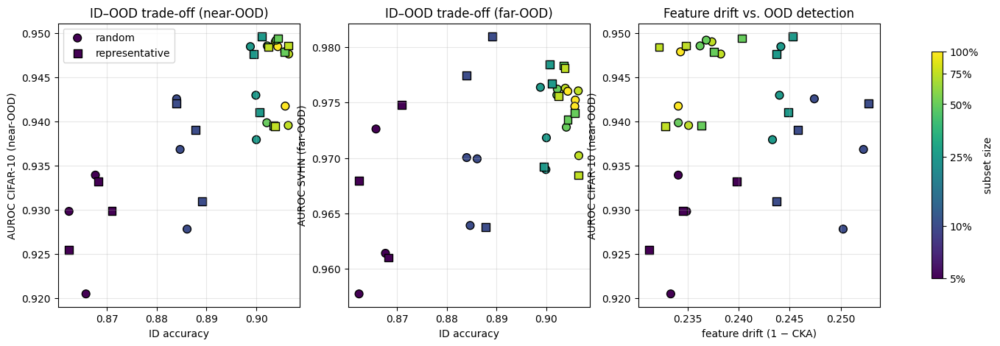

,ood_dataset,score,spearman_rho,p_value
0,cifar10,msp,-0.0037,0.9828
1,cifar10,energy,0.0900,0.6017
2,svhn,msp,-0.0385,0.8236
3,svhn,energy,-0.0194,0.9104


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
panels = [("id_acc", "auroc_energy_cifar10", "ID accuracy", "AUROC CIFAR-10 (near-OOD)", "ID–OOD trade-off (near-OOD)"),
          ("id_acc", "auroc_energy_svhn", "ID accuracy", "AUROC SVHN (far-OOD)", "ID–OOD trade-off (far-OOD)"),
          ("feature_drift", "auroc_energy_cifar10", "feature drift (1 − CKA)", "AUROC CIFAR-10 (near-OOD)", "Feature drift vs. OOD detection")]
for ax, (x, y, xl, yl, t) in zip(axes, panels):
    for s, mk in zip(STRATEGIES, ["o", "s"]):
        d = res[(res.strategy == s) & ~res.shared_full_run]
        sc = ax.scatter(d[x], d[y], c=np.log10(d.fraction * 100), cmap="viridis", vmin=np.log10(5), vmax=2,
                        marker=mk, s=60, edgecolors="k", label=s)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(t); ax.grid(alpha=0.3)
axes[0].legend()
cb = fig.colorbar(sc, ax=axes, shrink=0.8); cb.set_ticks(np.log10([f * 100 for f in FRACTIONS]))
cb.set_ticklabels([f"{f:.0%}" for f in FRACTIONS]); cb.set_label("subset size")
save_fig("tradeoff_and_feature_drift.png"); plt.show()

corr = pd.DataFrame([dict(ood_dataset=o, score=sc, **dict(zip(["spearman_rho", "p_value"],
                     spearmanr(res.feature_drift, res[f"auroc_{sc}_{o}"]))))
                     for o in ood_sets for sc in ["msp", "energy"]]).round(4)
corr.to_csv(os.path.join(DIRS["tables"], "drift_vs_auroc_spearman.csv"), index=False)
corr

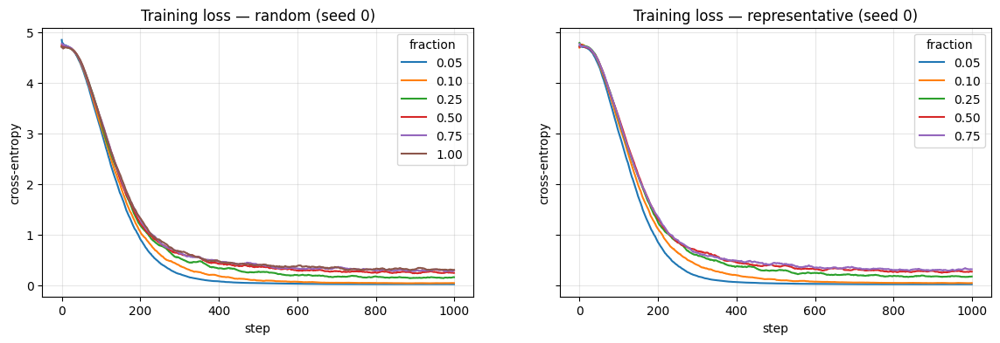

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, s in zip(axes, STRATEGIES):
    for run, l in loss_curves.items():
        if run.startswith(s) and run.endswith(f"seed{SEEDS[0]}"):
            ax.plot(pd.Series(l).rolling(25, min_periods=1).mean(), label=run.split("_")[1])
    ax.set_title(f"Training loss — {s} (seed {SEEDS[0]})"); ax.set_xlabel("step"); ax.set_ylabel("cross-entropy")
    ax.legend(title="fraction"); ax.grid(alpha=0.3)
save_fig("training_loss_curves.png"); plt.show()

# 14. Zip all outputs

In [ ]:
json.dump({"model": MODEL_NAME, "fractions": FRACTIONS, "strategies": STRATEGIES, "seeds": SEEDS,
           "kmeans_iterations_max": KMEANS_ITERS, "train_steps": TRAIN_STEPS, "batch_size": BATCH_SIZE,
           "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD, "weight_decay": WEIGHT_DECAY,
           "warmup_fraction": WARMUP_FRAC, "grad_clip": GRAD_CLIP, "ece_bins": ECE_BINS, "cka_images": int(len(cka_idx)),
           "ood_datasets": list(ood_sets)}, open(os.path.join(OUTPUT_DIR, "experiment_settings.json"), "w"), indent=2)

ZIP_PATH = os.path.join(WORK_DIR, "outputs.zip")
already_compressed = (".npz", ".png", ".safetensors")
_new_zip = not os.path.exists(ZIP_PATH)
if _new_zip:                                         # the zip (about 6 GB) is created only once
    with zipfile.ZipFile(ZIP_PATH + ".part", "w") as zf:
        for dp, _, fs in os.walk(OUTPUT_DIR):
            for f in sorted(fs):
                full = os.path.join(dp, f)
                zf.write(full, os.path.relpath(full, WORK_DIR),
                         compress_type=zipfile.ZIP_STORED if f.endswith(already_compressed) else zipfile.ZIP_DEFLATED)
    os.replace(ZIP_PATH + ".part", ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
contents = pd.Series([n.split("/")[1] if n.count("/") > 1 else "(top level)" for n in names]).value_counts()
print(f"{'Created' if _new_zip else 'Already on Drive:'} {ZIP_PATH}  ({os.path.getsize(ZIP_PATH)/1e9:.2f} GB, {len(names)} files)")
contents.rename("files").to_frame()

Created /content/outputs.zip  (6.31 GB, 180 files)


,files
models,66
subsets,51
predictions,33
tables,11
figures,11
preprocessing,4
embeddings,3
(top level),1


# 15. Parts A–D: setup
Part A-D resolves the point of diversity, per-class metrics and significance, and class-balanced vs. naturally imbalanced selection.

In [ ]:
# Parts A-D ("Part 2" in folder and variable names) write next to the baseline copy on Drive
BASELINE_DIR = OUTPUT_DIR                                      # baseline outputs (Sections 1-14)
PART2_DIR = os.path.join(RESULTS_DIR, "outputs_part2")
DIRS = {d: os.path.join(PART2_DIR, d) for d in ["figures", "tables", "subsets", "runs", "predictions", "models"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

def save_table(df, name, index=True):
    df.to_csv(os.path.join(DIRS["tables"], name), index=index)

# pretrained pool embeddings (Section 7), float16 as saved, L2-normalised
POOL_EMB = F.normalize(pool_emb.half().float(), dim=1).to(device)

# 16. Part A — Diversity

In [ ]:
def diversity_metrics(sel, cand=None, chunk=2048):
    # sel, cand: positions in the selection pool; cand = the set the subset was chosen from (default: whole pool)
    S_ = POOL_EMB[torch.as_tensor(sel, device=device)]
    C_ = POOL_EMB if cand is None else POOL_EMB[torch.as_tensor(cand, device=device)]
    d = torch.cat([(1 - (C_[i:i + chunk] @ S_.T).max(1).values).clamp_min(0) for i in range(0, len(C_), chunk)])
    m, s = len(sel), S_.sum(0)
    mean_pair_sim = float((s @ s - (S_ * S_).sum()) / (m * (m - 1)))     # excludes self-pairs
    cnt = np.bincount(labels_pool[sel], minlength=NUM_CLASSES)
    p = cnt[cnt > 0] / m
    return dict(coverage_mean=float(d.mean()), coverage_p95=float(torch.quantile(d.float().cpu(), 0.95)),
                pairwise_diversity=1 - mean_pair_sim,
                label_entropy=float(-(p * np.log(p)).sum() / np.log(NUM_CLASSES)))

# the 36 baseline subsets from Section 8 (at 100% both strategies use the whole pool)
base_subsets = dict(SUBSETS)

t0 = time.time()
div_rows = [dict(strategy=s, fraction=f, seed=sd, **diversity_metrics(idx)) for (s, f, sd), idx in base_subsets.items()]
div_base = pd.DataFrame(div_rows)
save_table(div_base, "A_diversity_baseline_subsets.csv", index=False)
print(f"Diversity of {len(div_base)} subsets computed in {time.time()-t0:.1f}s")
div_cols = ["coverage_mean", "coverage_p95", "pairwise_diversity", "label_entropy"]
div_base.groupby(["fraction", "strategy"])[div_cols].agg(["mean", "std"]).round(4)

Diversity of 36 subsets computed in 7.2s


coverage_mean         coverage_p95          \
                                 mean     std         mean     std   
fraction strategy                                                    
0.05     random                0.3113  0.0006       0.5194  0.0011   
         representative        0.2878  0.0003       0.5045  0.0011   
0.10     random                0.2755  0.0004       0.4950  0.0003   
         representative        0.2621  0.0002       0.4850  0.0004   
0.25     random                0.2110  0.0001       0.4596  0.0010   
         representative        0.2041  0.0001       0.4510  0.0008   
0.50     random                0.1321  0.0001       0.4181  0.0011   
         representative        0.1259  0.0002       0.4034  0.0016   
0.75     random                0.0635  0.0003       0.3539  0.0016   
         representative        0.0588  0.0003       0.3310  0.0019   
1.00     random                0.0000  0.0000       0.0000  0.0000   
         representative        0.0000  0.0000       0.0000  0.0000   

                        pairwise_diversity         label_entropy          
                                      mean     std          mean     std  
fraction strategy                                                         
0.05     random                     0.8316  0.0009        0.9952  0.0007  
         representative             0.8273  0.0004        0.9952  0.0005  
0.10     random                     0.8315  0.0008        0.9978  0.0006  
         representative             0.8300  0.0003        0.9976  0.0001  
0.25     random                     0.8313  0.0006        0.9993  0.0001  
         representative             0.8311  0.0006        0.9992  0.0000  
0.50     random                     0.8315  0.0004        0.9997  0.0000  
         representative             0.8319  0.0002        0.9997  0.0001  
0.75     random                     0.8317  0.0001        0.9999  0.0000  
         representative             0.8319  0.0001        0.9999  0.0000  
1.00     random                     0.8318  0.0000        1.0000  0.0000  
         representative             0.8318  0.0000        1.0000  0.0000

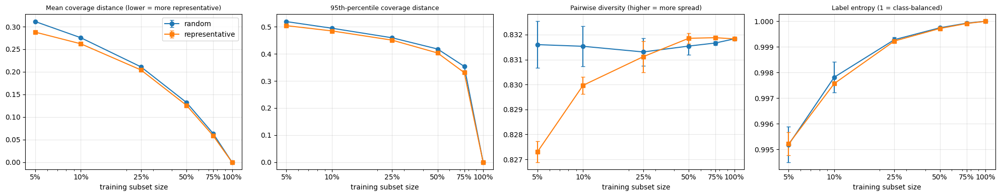

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
titles = {"coverage_mean": "Mean coverage distance (lower = more representative)",
          "coverage_p95": "95th-percentile coverage distance",
          "pairwise_diversity": "Pairwise diversity (higher = more spread)",
          "label_entropy": "Label entropy (1 = class-balanced)"}
for ax, col in zip(axes, div_cols):
    for s, mk in zip(STRATEGIES, ["o", "s"]):
        d = div_base[div_base.strategy == s].groupby("fraction")[col]
        ax.errorbar(d.mean().index * 100, d.mean().values, yerr=d.std().fillna(0).values, marker=mk, capsize=3, label=s)
    ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
    ax.set_title(titles[col], fontsize=9); ax.set_xlabel("training subset size"); ax.grid(alpha=0.3)
axes[0].legend(); plt.tight_layout(); save_fig("A_diversity_vs_subset_size.png"); plt.show()

In [ ]:
res_base = res.copy()                     # baseline results of all runs (Section 11)
base_all = res_base.merge(div_base, on=["strategy", "fraction", "seed"], how="left")

OUTCOMES = ["id_acc", "auroc_energy_cifar10", "fpr95_energy_cifar10", "auroc_energy_svhn",
            "fpr95_energy_svhn", "ece", "feature_drift"]

def within_size_spearman(df, xcols, ycols):
    d = df[df.fraction < 1].copy()
    for c in set(xcols) | set(ycols):
        d[c] = d[c] - d.groupby("fraction")[c].transform("mean")
    rows = []
    for x in xcols:
        for y in ycols:
            rho, p = spearmanr(d[x], d[y])
            rows.append(dict(diversity_metric=x, outcome=y, spearman_rho=rho, p_value=p, n_runs=len(d)))
    return pd.DataFrame(rows).round(4)

corr_div = within_size_spearman(base_all, div_cols[:3], OUTCOMES)
save_table(corr_div, "A_diversity_vs_outcomes_spearman_within_size.csv", index=False)
corr_div.pivot(index="outcome", columns="diversity_metric", values="spearman_rho").style.format("{:.3f}") \
    .background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

diversity_metric,coverage_mean,coverage_p95,pairwise_diversity
outcome,,,
auroc_energy_cifar10,-0.081,-0.016,-0.118
auroc_energy_svhn,-0.341,-0.248,-0.228
ece,0.080,-0.046,-0.028
feature_drift,-0.014,0.154,-0.161
fpr95_energy_cifar10,-0.141,0.056,-0.225
fpr95_energy_svhn,0.371,0.299,0.286
id_acc,-0.364,-0.112,-0.333


In [ ]:
print("Significant within-size correlations (p < 0.05):")
sig = corr_div[corr_div.p_value < 0.05]
print(sig.to_string(index=False) if len(sig) else "  none")

Significant within-size correlations (p < 0.05):
diversity_metric           outcome  spearman_rho  p_value  n_runs
   coverage_mean            id_acc       -0.3636   0.0482      30
   coverage_mean fpr95_energy_svhn        0.3709   0.0436      30


# 17. Part B — Per-class metrics and significance

In [ ]:
def per_class_metrics(logits, y, groups=None):
    pred = np.asarray(logits).argmax(1)
    acc_c = np.array([(pred[y == c] == c).mean() for c in range(NUM_CLASSES)])
    r = dict(worst_class_acc=acc_c.min(), worst10_class_acc=np.sort(acc_c)[:10].mean(), class_acc_std=acc_c.std())
    for g, cls in (groups or {}).items():
        r[f"acc_{g}"] = acc_c[cls].mean() if len(cls) else np.nan
    return r, acc_c

def load_logits(folder, run):
    with np.load(os.path.join(folder, f"logits_{run}.npz")) as z:
        return {k: z[k].astype(np.float32) for k in z.files}

pc_rows = []
for _, row in res_base.iterrows():
    src = "random" if row.shared_full_run else row.strategy           # the 100% run is shared
    lg = load_logits(os.path.join(BASELINE_DIR, "predictions"), f"{src}_{row.fraction:.2f}_seed{row.seed}")
    r, _ = per_class_metrics(lg["cifar100_test"], c100_test_y)
    r["bal_acc_check"] = balanced_accuracy_score(c100_test_y, lg["cifar100_test"].argmax(1))
    pc_rows.append(dict(strategy=row.strategy, fraction=row.fraction, seed=row.seed, **r))
pc_base = pd.DataFrame(pc_rows)
base_all = base_all.merge(pc_base.drop(columns="bal_acc_check"), on=["strategy", "fraction", "seed"])
save_table(base_all, "B_baseline_all_metrics_per_run.csv", index=False)

print("Test images per class:", np.unique(np.bincount(c100_test_y)),
      f"| max |balanced acc - acc| over all runs: {np.abs(pc_base.bal_acc_check.values - res_base.id_acc.values).max():.2e}")
pc_cols = ["worst_class_acc", "worst10_class_acc", "class_acc_std"]
base_all.groupby(["fraction", "strategy"])[pc_cols].agg(["mean", "std"]).round(4)

Test images per class: [100] | max |balanced acc - acc| over all runs: 2.79e-08


worst_class_acc         worst10_class_acc          \
                                   mean     std              mean     std   
fraction strategy                                                           
0.05     random                  0.3900  0.0557            0.6167  0.0121   
         representative          0.4733  0.0569            0.6450  0.0191   
0.10     random                  0.5600  0.0173            0.6837  0.0110   
         representative          0.5433  0.0289            0.6950  0.0070   
0.25     random                  0.5733  0.0462            0.6997  0.0015   
         representative          0.5567  0.0153            0.6947  0.0084   
0.50     random                  0.5500  0.0200            0.6963  0.0025   
         representative          0.5733  0.0451            0.6973  0.0012   
0.75     random                  0.5467  0.0289            0.7023  0.0055   
         representative          0.5367  0.0289            0.6897  0.0023   
1.00     random                  0.5333  0.0208            0.6977  0.0080   
         representative          0.5333  0.0208            0.6977  0.0080   

                        class_acc_std          
                                 mean     std  
fraction strategy                              
0.05     random                0.1071  0.0050  
         representative        0.0986  0.0032  
0.10     random                0.0880  0.0040  
         representative        0.0844  0.0017  
0.25     random                0.0843  0.0015  
         representative        0.0852  0.0021  
0.50     random                0.0858  0.0003  
         representative        0.0863  0.0016  
0.75     random                0.0843  0.0019  
         representative        0.0882  0.0018  
1.00     random                0.0863  0.0028  
         representative        0.0863  0.0028

In [ ]:
TEST_METRICS = OUTCOMES + ["worst_class_acc", "class_acc_std"] + div_cols

def paired_tests(df, group_col, a, b, metrics, by="fraction"):
    rows = []
    for f in sorted(df[by].unique()):
        if f >= 1: continue
        A = df[(df[group_col] == a) & (df[by] == f)]
        B = df[(df[group_col] == b) & (df[by] == f)]
        common = sorted(set(A.seed) & set(B.seed))              # pair seed s with seed s
        A = A.set_index("seed").loc[common]; B = B.set_index("seed").loc[common]
        for m in metrics:
            diff = A[m].values - B[m].values
            t, p = ttest_rel(A[m].values, B[m].values) if len(diff) > 1 and np.std(diff) > 0 else (np.nan, np.nan)
            rows.append(dict(fraction=f, metric=m, mean_diff=diff.mean(), std_diff=diff.std(ddof=1) if len(diff) > 1 else np.nan,
                             t_stat=t, p_value=p, n_pairs=len(diff)))
    return pd.DataFrame(rows)

tests_rep = paired_tests(base_all, "strategy", "representative", "random", TEST_METRICS)
save_table(tests_rep.round(5), "B_paired_ttest_representative_vs_random.csv", index=False)

show = tests_rep.copy()
show["cell"] = show.apply(lambda r: f"{r.mean_diff:+.4f}" + ("*" if r.p_value < 0.05 else ""), axis=1)
show.pivot(index="metric", columns="fraction", values="cell").reindex(TEST_METRICS) \
    .rename(columns=lambda f: f"{f:.0%}")

fraction,5%,10%,25%,50%,75%
metric,,,,,
id_acc,+0.0019,+0.0020,+0.0009,+0.0017*,-0.0014
auroc_energy_cifar10,+0.0014,+0.0016,+0.0030,-0.0003,+0.0001
fpr95_energy_cifar10,+0.0116,+0.0040,-0.0093*,-0.0042,-0.0010
auroc_energy_svhn,+0.0040,+0.0061,+0.0024,+0.0004,-0.0001
fpr95_energy_svhn,-0.0156,-0.0248,-0.0085,-0.0067,-0.0015
ece,+0.0000,-0.0003,+0.0007,+0.0021,+0.0010
feature_drift,+0.0011,-0.0025,+0.0008,+0.0024,-0.0036
worst_class_acc,+0.0833,-0.0167,-0.0167,+0.0233,-0.0100
class_acc_std,-0.0085,-0.0035,+0.0009,+0.0005,+0.0039*


# 18. Part C — Class-balanced vs. naturally imbalanced selection

## 18.1 The naturally imbalanced (long-tailed) pool

Long-tailed pool: 9754 images | head class 450, tail class 4 (ratio 112) | many/medium/few classes: 33/34/33
Subset sizes: {'5%': 488, '10%': 975, '25%': 2438, '50%': 4877, '75%': 7316, '100%': 9754}


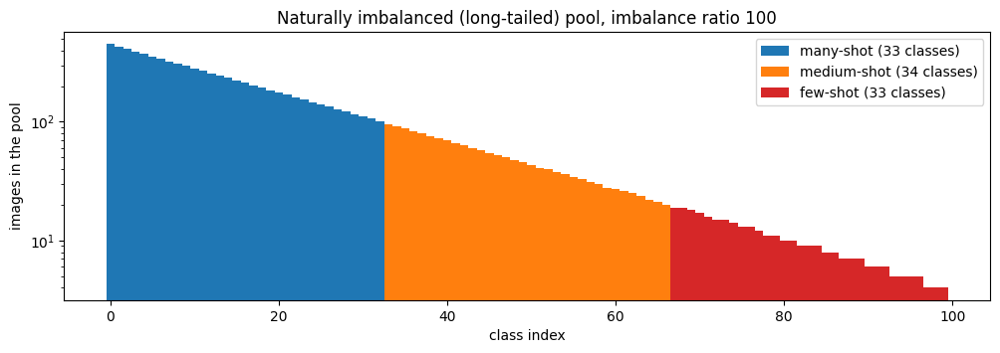

In [ ]:
IMB_RATIO = 100
LT_SEED = 0
SEEDS_C = SEEDS
SAVE_MODELS_C = False

n_max = int(np.bincount(labels_pool, minlength=NUM_CLASSES).max())
lt_counts = np.array([int(n_max * IMB_RATIO ** (-c / (NUM_CLASSES - 1))) for c in range(NUM_CLASSES)])
rng = np.random.default_rng(LT_SEED)
lt_pool = np.sort(np.concatenate([rng.choice(np.where(labels_pool == c)[0], lt_counts[c], replace=False)
                                  for c in range(NUM_CLASSES)]))
N_LT = len(lt_pool)
assert np.array_equal(np.bincount(labels_pool[lt_pool], minlength=NUM_CLASSES), lt_counts)

GROUPS = {"many": np.where(lt_counts > 100)[0], "medium": np.where((lt_counts >= 20) & (lt_counts <= 100))[0],
          "few": np.where(lt_counts < 20)[0]}
np.save(os.path.join(DIRS["subsets"], "lt_pool_indices.npy"), lt_pool)
json.dump({"imbalance_ratio": IMB_RATIO, "lt_seed": LT_SEED, "n_lt_pool": int(N_LT), "class_counts": lt_counts.tolist(),
           "groups": {g: v.tolist() for g, v in GROUPS.items()}},
          open(os.path.join(DIRS["subsets"], "lt_pool_config.json"), "w"), indent=2)

print(f"Long-tailed pool: {N_LT} images | head class {lt_counts.max()}, tail class {lt_counts.min()} "
      f"(ratio {lt_counts.max()/lt_counts.min():.0f}) | many/medium/few classes: "
      f"{len(GROUPS['many'])}/{len(GROUPS['medium'])}/{len(GROUPS['few'])}")
print("Subset sizes:", {f"{f:.0%}": int(round(f * N_LT)) for f in FRACTIONS})

fig, ax = plt.subplots(figsize=(12, 3.5))
cols = {"many": "tab:blue", "medium": "tab:orange", "few": "tab:red"}
for g, cls in GROUPS.items():
    ax.bar(cls, lt_counts[cls], width=1.0, color=cols[g], label=f"{g}-shot ({len(cls)} classes)")
ax.set_xlabel("class index"); ax.set_ylabel("images in the pool"); ax.set_yscale("log"); ax.legend()
ax.set_title(f"Naturally imbalanced (long-tailed) pool, imbalance ratio {IMB_RATIO}")
save_fig("C_long_tailed_pool.png"); plt.show()

## 18.2 Building the subsets

In [ ]:
BALANCES = ["natural", "balanced"]
SELECTIONS = ["random", "representative"]
lt_avail = {c: lt_pool[labels_pool[lt_pool] == c] for c in range(NUM_CLASSES)}

def waterfill_quotas(avail, n, seed):
    # equal images per class, capped by what each class has; leftover images go to randomly chosen larger classes
    avail = np.asarray(avail)
    lo, hi = 0, int(avail.max())
    while lo < hi:                                        # largest level L with sum(min(avail, L)) <= n
        mid = (lo + hi + 1) // 2
        lo, hi = (mid, hi) if np.minimum(avail, mid).sum() <= n else (lo, mid - 1)
    q = np.minimum(avail, lo)
    rest = n - q.sum()
    if rest > 0:
        q[np.random.default_rng(seed).choice(np.where(avail > lo)[0], rest, replace=False)] += 1
    assert q.sum() == n and (q <= avail).all()
    return q

def representative_from(cand, k, seed):
    # baseline method on a candidate set: k-means with k clusters, then the nearest unused image to every centroid
    cand = np.asarray(cand)
    if k >= len(cand): return np.sort(cand), 0
    X = POOL_EMB[torch.as_tensor(cand, device=device)]
    C, n_iter = kmeans_lloyd(X, k, KMEANS_ITERS, seed)
    dist, nn_idx = nearest_images(X, C, min(NEIGHBOURS, len(cand)))
    taken = np.zeros(len(cand), dtype=bool); chosen = []
    for c in np.argsort(dist[:, 0], kind="stable"):
        for j in nn_idx[c]:
            if not taken[j]:
                taken[j] = True; chosen.append(j); break
    chosen = np.array(chosen, dtype=np.int64)
    if len(chosen) < k:
        chosen = np.concatenate([chosen, np.random.default_rng(seed).choice(np.where(~taken)[0], k - len(chosen), replace=False)])
    return np.sort(cand[chosen]), n_iter

def build_subset(balance, selection, n, seed):
    if n >= N_LT: return lt_pool.copy()
    if balance == "natural":
        if selection == "random":
            return np.sort(np.random.default_rng(seed).choice(lt_pool, n, replace=False))
        return representative_from(lt_pool, n, seed)[0]
    q = waterfill_quotas(lt_counts, n, seed)
    rng = np.random.default_rng(seed)
    parts = []
    for c in range(NUM_CLASSES):
        if q[c] == 0: continue
        if selection == "random":
            parts.append(rng.choice(lt_avail[c], q[c], replace=False))
        else:
            parts.append(representative_from(lt_avail[c], int(q[c]), seed * 1000 + c)[0])
    return np.sort(np.concatenate(parts))

SUBSETS_C, rows = {}, []
t0 = time.time()
for seed in SEEDS_C:
    for frac in FRACTIONS:
        n = int(round(frac * N_LT))
        for bal in BALANCES:
            for sel in SELECTIONS:
                path = os.path.join(DIRS["subsets"], f"{bal}-{sel}_{frac:.2f}_seed{seed}.npy")
                if os.path.exists(path):
                    idx = np.load(path)                     # reuse after a restart -> identical subsets
                else:
                    idx = build_subset(bal, sel, n, seed); np.save(path, idx)
                assert len(idx) == n and len(np.unique(idx)) == n and np.isin(idx, lt_pool).all()
                SUBSETS_C[(bal, sel, frac, seed)] = idx
                cnt = np.bincount(labels_pool[idx], minlength=NUM_CLASSES)
                rows.append(dict(balance=bal, selection=sel, fraction=frac, seed=seed, n_train=n,
                                 classes_present=int((cnt > 0).sum()), min_per_class=int(cnt.min()),
                                 max_per_class=int(cnt.max()),
                                 imbalance_ratio=cnt.max() / max(cnt[cnt > 0].min(), 1),
                                 **{f"n_{g}": int(cnt[cls].sum()) for g, cls in GROUPS.items()},
                                 **diversity_metrics(idx, cand=lt_pool)))
subset_c = pd.DataFrame(rows)
save_table(subset_c, "C_subsets_class_balance_and_diversity.csv", index=False)
print(f"Built {len(subset_c)} subsets in {time.time()-t0:.1f}s")
subset_c.groupby(["fraction", "balance", "selection"])[
    ["n_train", "classes_present", "min_per_class", "max_per_class", "imbalance_ratio",
     "n_few", "label_entropy", "coverage_mean"]].mean().round(3)

Built 72 subsets in 42.2s


n_train  classes_present  min_per_class  \
fraction balance  selection                                                 
0.05     balanced random            488.0          100.000          4.000   
                  representative    488.0          100.000          4.000   
         natural  random            488.0           72.333          0.000   
                  representative    488.0           80.333          0.000   
0.10     balanced random            975.0          100.000          4.000   
                  representative    975.0          100.000          4.000   
         natural  random            975.0           87.000          0.000   
                  representative    975.0           89.000          0.000   
0.25     balanced random           2438.0          100.000          4.000   
                  representative   2438.0          100.000          4.000   
         natural  random           2438.0           96.333          0.000   
                  representative   2438.0           97.667          0.000   
0.50     balanced random           4877.0          100.000          4.000   
                  representative   4877.0          100.000          4.000   
         natural  random           4877.0          100.000          1.333   
                  representative   4877.0          100.000          1.000   
0.75     balanced random           7316.0          100.000          4.000   
                  representative   7316.0          100.000          4.000   
         natural  random           7316.0          100.000          2.000   
                  representative   7316.0          100.000          2.333   
1.00     balanced random           9754.0          100.000          4.000   
                  representative   9754.0          100.000          4.000   
         natural  random           9754.0          100.000          4.000   
                  representative   9754.0          100.000          4.000   

                                  max_per_class  imbalance_ratio    n_few  \
fraction balance  selection                                                 
0.05     balanced random                  5.000            1.250  159.000   
                  representative          5.000            1.250  159.000   
         natural  random                 28.667           28.667   18.333   
                  representative         24.000           24.000   16.000   
0.10     balanced random                 11.000            2.750  271.000   
                  representative         11.000            2.750  271.000   
         natural  random                 48.000           48.000   33.000   
                  representative         45.000           45.000   33.000   
0.25     balanced random                 33.000            8.250  327.000   
                  representative         33.000            8.250  327.000   
         natural  random                107.667          107.667   73.333   
                  representative        115.333          115.333   84.667   
0.50     balanced random                 88.000           22.000  327.000   
                  representative         88.000           22.000  327.000   
         natural  random                228.667          190.000  163.000   
                  representative        224.667          224.667  169.667   
0.75     balanced random                178.000           44.500  327.000   
                  representative        178.000           44.500  327.000   
         natural  random                330.667          200.333  245.333   
                  representative        332.333          147.222  246.667   
1.00     balanced random                450.000          112.500  327.000   
                  representative        450.000          112.500  327.000   
         natural  random                450.000          112.500  327.000   
                  representative        450.000          112.500  327.000   

                            

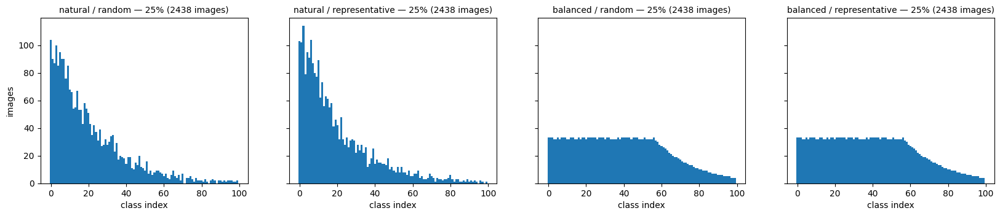

In [ ]:
f_show = 0.25 if 0.25 in FRACTIONS else FRACTIONS[len(FRACTIONS) // 2]
fig, axes = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)
for ax, (bal, sel) in zip(axes, [(b, s) for b in BALANCES for s in SELECTIONS]):
    idx = SUBSETS_C[(bal, sel, f_show, SEEDS_C[0])]
    ax.bar(range(NUM_CLASSES), np.bincount(labels_pool[idx], minlength=NUM_CLASSES), width=1.0)
    ax.set_title(f"{bal} / {sel} — {f_show:.0%} ({len(idx)} images)", fontsize=10); ax.set_xlabel("class index")
axes[0].set_ylabel("images")
save_fig("C_subset_class_distributions.png"); plt.show()

## 18.3 Fine-tuning and evaluation (63 runs)

In [ ]:
def evaluate_c(model):
    # baseline evaluation + worst-class accuracy, class-accuracy spread and many/medium/few-shot accuracy
    r, store = evaluate(model)
    r.update(per_class_metrics(store["cifar100_test"].numpy(), test_y.cpu().numpy(), GROUPS)[0])
    return r, store

In [ ]:
jobs = [(bal, sel, f, sd) for sd in SEEDS_C for f in FRACTIONS for bal in BALANCES for sel in SELECTIONS
        if not (f >= 1 and (bal, sel) != ("natural", "random"))]          # 100%: one shared run per seed
run_name = lambda bal, sel, f, sd: f"{bal}-{sel}_{f:.2f}_seed{sd}"
todo = [j for j in jobs if not os.path.exists(os.path.join(DIRS["runs"], run_name(*j) + ".json"))]

if not todo:
    # every run is finished and saved: print the complete training log from the saved run files
    recs = [json.load(open(os.path.join(DIRS["runs"], run_name(*j) + ".json"))) for j in jobs]
    print(f"Part C: {len(jobs)} training runs | total training time {sum(r['train_minutes'] for r in recs)/60:.1f} h")
    for k, (j, r) in enumerate(zip(jobs, recs), 1):
        print(f"[{k}/{len(jobs)}] {run_name(*j)}  ({int(r['n_train'])} training images)")
        for s in range(LOG_EVERY, TRAIN_STEPS + 1, LOG_EVERY):
            print(f"    step {s:>5}/{TRAIN_STEPS}  loss {np.mean(r['losses'][s-LOG_EVERY:s]):.4f}  {r['train_minutes'] * s / TRAIN_STEPS:.1f} min")
        print(f"    ID acc {r['id_acc']:.4f} | few-shot acc {r['acc_few']:.4f} | AUROC(energy) CIFAR-10 "
              f"{r['auroc_energy_cifar10']:.4f} SVHN {r['auroc_energy_svhn']:.4f} | ECE {r['ece']:.4f} | CKA {r['cka']:.4f}")
    print(f"Part C: done, {len(jobs)} of {len(jobs)} runs finished and saved on Drive")
else:
    todo = [j for j in jobs if not os.path.exists(os.path.join(DIRS["runs"], run_name(*j) + ".json"))]
    print(f"{len(jobs)} training runs in Part C, {len(jobs)-len(todo)} already finished, {len(todo)} to go "
          f"(about {len(todo)*10/60:.1f} h at ~10 min per run)")

    t_all = time.time()
    for k, (bal, sel, frac, seed) in enumerate(todo, 1):
        run = run_name(bal, sel, frac, seed)
        idx = SUBSETS_C[(bal, sel, frac, seed)]
        print(f"[{k}/{len(todo)}] {run}  ({len(idx)} training images)")
        model, losses, minutes = train_one(idx, seed)
        metrics, preds = evaluate_c(model)
        np.savez_compressed(os.path.join(DIRS["predictions"], f"logits_{run}.npz"),
                            **{k2: v.numpy().astype(np.float16) for k2, v in preds.items()})
        if SAVE_MODELS_C:
            model.to(torch.float16).save_pretrained(os.path.join(DIRS["models"], run))
        row = dict(balance=bal, selection=sel, fraction=frac, seed=seed, n_train=len(idx),
                   train_minutes=round(minutes, 2), shared_full_run=False, losses=losses, **metrics)
        json.dump({k2: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k2, v in row.items()},
                  open(os.path.join(DIRS["runs"], run + ".json"), "w"))
        print(f"    ID acc {row['id_acc']:.4f} | few-shot acc {row['acc_few']:.4f} | AUROC(energy) CIFAR-10 "
              f"{row['auroc_energy_cifar10']:.4f} SVHN {row['auroc_energy_svhn']:.4f} | ECE {row['ece']:.4f} | CKA {row['cka']:.4f}")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()
    print(f"Done in {(time.time()-t_all)/60:.1f} min")

Part C: 63 training runs | total training time 10.2 h
[1/63] natural-random_0.05_seed0  (488 training images)
    step   250/1000  loss 1.4233  2.5 min
    step   500/1000  loss 0.0159  5.1 min
    step   750/1000  loss 0.0072  7.6 min
    step  1000/1000  loss 0.0059  10.1 min
    ID acc 0.4474 | few-shot acc 0.1430 | AUROC(energy) CIFAR-10 0.7348 SVHN 0.8294 | ECE 0.0607 | CKA 0.8402
[2/63] natural-representative_0.05_seed0  (488 training images)
    step   250/1000  loss 1.4611  2.5 min
    step   500/1000  loss 0.0170  5.1 min
    step   750/1000  loss 0.0077  7.6 min
    step  1000/1000  loss 0.0063  10.1 min
    ID acc 0.5296 | few-shot acc 0.1764 | AUROC(energy) CIFAR-10 0.7667 SVHN 0.8883 | ECE 0.0397 | CKA 0.8275
[3/63] balanced-random_0.05_seed0  (488 training images)
    step   250/1000  loss 1.7865  2.5 min
    step   500/1000  loss 0.0272  5.1 min
    step   750/1000  loss 0.0116  7.6 min
    step  1000/1000  loss 0.0094  10.1 min
    ID acc 0.7774 | few-shot acc 0.7952 | 

## 18.4 Results

In [ ]:
# collect every finished run (also the ones from earlier sessions); add the shared 100% rows
recs = [json.load(open(p)) for p in sorted(glob.glob(os.path.join(DIRS["runs"], "*.json")))]
loss_c = {run_name(r["balance"], r["selection"], r["fraction"], r["seed"]): r.pop("losses") for r in recs}
res_c = pd.DataFrame(recs)
full = res_c[res_c.fraction >= 1]
extra = [{**r, "balance": b, "selection": s, "shared_full_run": True} for r in full.to_dict("records")
         for b in BALANCES for s in SELECTIONS if (b, s) != ("natural", "random")]
res_c = pd.concat([res_c, pd.DataFrame(extra)], ignore_index=True)
res_c = res_c.merge(subset_c[["balance", "selection", "fraction", "seed", "imbalance_ratio", "n_few"] + div_cols],
                    on=["balance", "selection", "fraction", "seed"], how="left")
res_c = res_c.sort_values(["seed", "fraction", "balance", "selection"]).reset_index(drop=True)
save_table(res_c, "C_results_all_runs.csv", index=False)
pd.DataFrame({k: pd.Series(v) for k, v in loss_c.items()}).to_csv(
    os.path.join(DIRS["tables"], "C_training_loss_curves.csv"), index_label="step")
print(f"{len(res_c)} result rows | seeds finished per setting:")
res_c.groupby(["balance", "selection", "fraction"]).seed.nunique().unstack("fraction")

72 result rows | seeds finished per setting:


fraction                 0.05  0.10  0.25  0.50  0.75  1.00
balance  selection                                         
balanced random             3     3     3     3     3     3
         representative     3     3     3     3     3     3
natural  random             3     3     3     3     3     3
         representative     3     3     3     3     3     3

## 18.5 Results tables (mean ± std over seeds, Energy score)

In [ ]:
C_COLS = ["id_acc", "acc_many", "acc_medium", "acc_few", "worst_class_acc", "auroc_energy_cifar10",
          "fpr95_energy_cifar10", "auroc_energy_svhn", "fpr95_energy_svhn", "ece", "ece_after_temp_scaling", "cka"]
g = res_c.groupby(["fraction", "balance", "selection"])[C_COLS]
mean_c, std_c = g.mean(), g.std().fillna(0)
tab_c = mean_c.round(4).astype(str) + " ± " + std_c.round(4).astype(str)
tab_c.index = pd.MultiIndex.from_tuples([(f"{f:.0%}", b, s) for f, b, s in tab_c.index],
                                        names=["subset", "balance", "selection"])
save_table(mean_c, "C_results_mean.csv"); save_table(std_c, "C_results_std.csv"); save_table(tab_c, "C_results_mean_std.csv")
tab_c

id_acc         acc_many  \
subset balance  selection                                          
5%     balanced random          0.7634 ± 0.0149   0.767 ± 0.0094   
                representative  0.7809 ± 0.0121  0.7952 ± 0.0029   
       natural  random          0.4521 ± 0.0045  0.8448 ± 0.0252   
                representative   0.5348 ± 0.006  0.8664 ± 0.0107   
10%    balanced random          0.8239 ± 0.0013  0.8342 ± 0.0124   
                representative  0.8321 ± 0.0023   0.847 ± 0.0048   
       natural  random          0.5538 ± 0.0337  0.8977 ± 0.0076   
                representative  0.5975 ± 0.0132  0.8956 ± 0.0026   
25%    balanced random          0.8458 ± 0.0047  0.8893 ± 0.0006   
                representative  0.8437 ± 0.0021  0.8892 ± 0.0057   
       natural  random           0.6739 ± 0.021  0.9183 ± 0.0032   
                representative  0.6954 ± 0.0081  0.9177 ± 0.0027   
50%    balanced random          0.8291 ± 0.0049  0.9186 ± 0.0028   
                representative  0.8306 ± 0.0007  0.9211 ± 0.0015   
       natural  random          0.7562 ± 0.0063   0.9286 ± 0.004   
                representative  0.7508 ± 0.0073  0.9316 ± 0.0026   
75%    balanced random           0.804 ± 0.0054  0.9318 ± 0.0018   
                representative  0.8027 ± 0.0027  0.9331 ± 0.0015   
       natural  random          0.7716 ± 0.0047  0.9339 ± 0.0035   
                representative  0.7671 ± 0.0015  0.9331 ± 0.0028   
100%   balanced random          0.7718 ± 0.0011  0.9354 ± 0.0035   
                representative  0.7718 ± 0.0011  0.9354 ± 0.0035   
       natural  random          0.7718 ± 0.0011  0.9354 ± 0.0035   
                representative  0.7718 ± 0.0011  0.9354 ± 0.0035   

                                     acc_medium          acc_few  \
subset balance  selection                                          
5%     balanced random          0.7445 ± 0.0389  0.7793 ± 0.0143   
                representative  0.7596 ± 0.0109  0.7887 ± 0.0287   
       natural  random          0.3914 ± 0.0564  0.1218 ± 0.0564   
                representative  0.5664 ± 0.0094  0.1707 ± 0.0067   
10%    balanced random          0.8251 ± 0.0038  0.8123 ± 0.0069   
                representative  0.8309 ± 0.0115  0.8185 ± 0.0029   
       natural  random           0.578 ± 0.0446  0.1848 ± 0.0511   
                representative  0.6471 ± 0.0079  0.2483 ± 0.0406   
25%    balanced random          0.8733 ± 0.0017   0.774 ± 0.0128   
                representative  0.8699 ± 0.0008  0.7711 ± 0.0021   
       natural  random           0.751 ± 0.0141    0.35 ± 0.0472   
                representative  0.7487 ± 0.0063  0.4182 ± 0.0255   
50%    balanced random          0.8674 ± 0.0052  0.7002 ± 0.0104   
                representative  0.8673 ± 0.0012  0.7023 ± 0.0031   
       natural  random           0.8095 ± 0.004   0.529 ± 0.0229   
                representative  0.7976 ± 0.0028   0.5218 ± 0.021   
75%    balanced random          0.8483 ± 0.0043  0.6304 ± 0.0102   
                representative  0.8468 ± 0.0028  0.6268 ± 0.0071   
       natural  random          0.8222 ± 0.0035  0.5571 ± 0.0121   
                representative  0.8197 ± 0.0038  0.5468 ± 0.0076   
100%   balanced random          0.8299 ± 0.0022  0.5484 ± 0.0052   
                representative  0.8299 ± 0.0022  0.5484 ± 0.0052   
       natural  random          0.8299 ± 0.0022  0.5484 ± 0.0052   
                representative  0.8299 ± 0.0022  0.5484 ± 0.0052   

                                worst_class_acc auroc_energy_cifar10  \
subset balance  selection                                              
5%     balanced random          0.2533 ± 0.0603       0.8551 ± 0.007   
                representative  0.3233 ± 0.0551      0.8535 ± 0.0102   
       natural  random                0.0 ± 0.0        0.7447 ± 0.02   
                representative        0.0 ± 0.0      0.7596 ± 0.0062   
10%    balanced random          0.2567 ± 0.1069      0.8891 ± 0.0053   

Effect of class balancing (*balanced − natural*) for each selection rule and subset size:

In [ ]:
# effect of class balancing: balanced minus natural, for each selection rule and subset size
diff_c = (mean_c.xs("balanced", level="balance") - mean_c.xs("natural", level="balance")).round(4)
diff_c.index = pd.MultiIndex.from_tuples([(f"{f:.0%}", s) for f, s in diff_c.index], names=["subset", "selection"])
save_table(diff_c, "C_balanced_minus_natural.csv")
diff_c

id_acc  acc_many  acc_medium  acc_few  worst_class_acc  \
subset selection                                                                
5%     random          0.3113   -0.0779      0.3531   0.6575           0.2533   
       representative  0.2461   -0.0712      0.1932   0.6180           0.3233   
10%    random          0.2701   -0.0634      0.2471   0.6275           0.2567   
       representative  0.2346   -0.0486      0.1838   0.5702           0.2333   
25%    random          0.1720   -0.0290      0.1224   0.4240           0.1700   
       representative  0.1483   -0.0285      0.1212   0.3529           0.1300   
50%    random          0.0729   -0.0100      0.0578   0.1712           0.0533   
       representative  0.0798   -0.0105      0.0696   0.1805           0.0533   
75%    random          0.0324   -0.0021      0.0262   0.0733           0.0067   
       representative  0.0356    0.0000      0.0271   0.0800           0.0033   
100%   random          0.0000    0.0000      0.0000   0.0000           0.0000   
       representative  0.0000    0.0000      0.0000   0.0000           0.0000   

                       auroc_energy_cifar10  fpr95_energy_cifar10  \
subset selection                                                    
5%     random                        0.1104               -0.2588   
       representative                0.0939               -0.2446   
10%    random                        0.1069               -0.3046   
       representative                0.0977               -0.2578   
25%    random                        0.0770               -0.2243   
       representative                0.0755               -0.2079   
50%    random                        0.0403               -0.1141   
       representative                0.0468               -0.1250   
75%    random                        0.0169               -0.0478   
       representative                0.0157               -0.0546   
100%   random                        0.0000                0.0000   
       representative                0.0000                0.0000   

                       auroc_energy_svhn  fpr95_energy_svhn     ece  \
subset selection                                                      
5%     random                     0.0796            -0.3602  0.1304   
       representative             0.0409            -0.2214  0.1430   
10%    random                     0.0829            -0.4941  0.0184   
       representative             0.0415            -0.2979  0.0260   
25%    random                     0.0541            -0.2923 -0.0343   
       representative             0.0335            -0.1734 -0.0333   
50%    random                     0.0304            -0.1476 -0.0182   
       representative             0.0166            -0.0883 -0.0178   
75%    random                     0.0052            -0.0336 -0.0058   
       representative             0.0144            -0.0796 -0.0013   
100%   random                     0.0000             0.0000  0.0000   
       representative             0.0000             0.0000  0.0000   

                       ece_after_temp_scaling     cka  
subset selection                                       
5%     random                         -0.0134 -0.0033  
       representative                 -0.0143 -0.0072  
10%    random                         -0.0133 -0.0092  
       representative                 -0.0246 -0.0079  
25%    random                         -0.0342 -0.0163  
       representative                 -0.0346 -0.0115  
50%    random                         -0.0225 -0.0102  
       representative                 -0.0274 -0.0069  
75%    random                         -0.0063 -0.0048  
       representative                 -0.0094 -0.0033  
100%   random                          0.0000  0.0000  
       representative                  0.0000  0.0000

## 18.6 Significance tests

In [ ]:
if len(SEEDS_C) > 1 and res_c.groupby(["balance", "selection", "fraction"]).seed.nunique().min() > 1:
    tests_bal = pd.concat([paired_tests(res_c[res_c.selection == s], "balance", "balanced", "natural",
                                        C_COLS[:-1] + ["feature_drift"]).assign(selection=s) for s in SELECTIONS])
    tests_rep_c = pd.concat([paired_tests(res_c[res_c.balance == b], "selection", "representative", "random",
                                          C_COLS[:-1] + ["feature_drift"]).assign(balance=b) for b in BALANCES])
    save_table(tests_bal.round(5), "C_paired_ttest_balanced_vs_natural.csv", index=False)
    save_table(tests_rep_c.round(5), "C_paired_ttest_representative_vs_random.csv", index=False)
    t = tests_bal.copy()
    t["cell"] = t.apply(lambda r: f"{r.mean_diff:+.4f}" + ("*" if r.p_value < 0.05 else ""), axis=1)
    display(t.pivot_table(index=["selection", "metric"], columns="fraction", values="cell", aggfunc="first")
            .rename(columns=lambda f: f"{f:.0%}"))
else:
    tests_bal = tests_rep_c = None
    print("Significance tests need at least two finished seeds per setting.")

fraction                                     5%       10%       25%       50%  \
selection      metric                                                           
random         acc_few                 +0.6575*  +0.6275*  +0.4240*  +0.1712*   
               acc_many                -0.0779*  -0.0634*  -0.0290*  -0.0100*   
               acc_medium              +0.3531*  +0.2471*  +0.1224*  +0.0578*   
               auroc_energy_cifar10    +0.1104*  +0.1069*  +0.0770*  +0.0403*   
               auroc_energy_svhn       +0.0796*   +0.0829  +0.0541*  +0.0304*   
               ece                     +0.1304*   +0.0184  -0.0343*  -0.0182*   
               ece_after_temp_scaling  -0.0134*   -0.0133  -0.0342*  -0.0225*   
               feature_drift            +0.0033   +0.0092  +0.0163*  +0.0102*   
               fpr95_energy_cifar10    -0.2588*  -0.3046*  -0.2243*  -0.1141*   
               fpr95_energy_svhn       -0.3602*   -0.4941  -0.2923*  -0.1476*   
               id_acc                  +0.3113*  +0.2701*  +0.1720*  +0.0729*   
               worst_class_acc         +0.2533*   +0.2567   +0.1700   +0.0533   
representative acc_few                 +0.6180*  +0.5702*  +0.3529*  +0.1805*   
               acc_many                -0.0712*  -0.0486*  -0.0285*  -0.0105*   
               acc_medium              +0.1932*  +0.1838*  +0.1212*  +0.0696*   
               auroc_energy_cifar10    +0.0939*  +0.0977*  +0.0755*  +0.0468*   
               auroc_energy_svhn        +0.0409   +0.0415   +0.0335  +0.0166*   
               ece                     +0.1430*   +0.0260   -0.0333  -0.0178*   
               ece_after_temp_scaling  -0.0143*   -0.0246  -0.0346*  -0.0274*   
               feature_drift            +0.0072   +0.0079   +0.0115  +0.0069*   
               fpr95_energy_cifar10    -0.2446*  -0.2578*  -0.2079*  -0.1250*   
               fpr95_energy_svhn        -0.2214   -0.2979   -0.1734  -0.0883*   
               id_acc                  +0.2461*  +0.2346*  +0.1483*  +0.0798*   
               worst_class_acc         +0.3233*  +0.2333*   +0.1300   +0.0533   

fraction                                    75%  
selection      metric                            
random         acc_few                 +0.0733*  
               acc_many                 -0.0021  
               acc_medium              +0.0262*  
               auroc_energy_cifar10    +0.0169*  
               auroc_energy_svhn        +0.0052  
               ece                      -0.0058  
               ece_after_temp_scaling   -0.0063  
               feature_drift            +0.0048  
               fpr95_energy_cifar10    -0.0478*  
               fpr95_energy_svhn        -0.0336  
               id_acc                  +0.0324*  
               worst_class_acc          +0.0067  
representative acc_few                 +0.0800*  
               acc_many                 +0.0000  
               acc_medium              +0.0271*  
               auroc_energy_cifar10    +0.0157*  
               auroc_energy_svhn        +0.0144  
               ece                      -0.0013  
               ece_after_temp_scaling   -0.0094  
               feature_drift            +0.0033  
               fpr95_energy_cifar10    -0.0546*  
               fpr95_energy_svhn       -0.0796*  
               id_acc                  +0.0356*  
               worst_class_acc          +0.0033

## 18.7 Figures

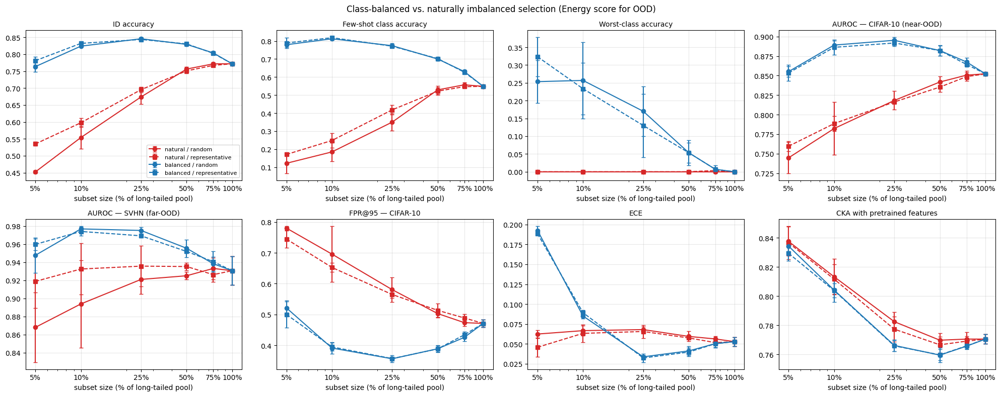

In [ ]:
SETTINGS = [(b, s) for b in BALANCES for s in SELECTIONS]
style = {("natural", "random"): ("tab:red", "o", "-"), ("natural", "representative"): ("tab:red", "s", "--"),
         ("balanced", "random"): ("tab:blue", "o", "-"), ("balanced", "representative"): ("tab:blue", "s", "--")}
panels = [("id_acc", "ID accuracy"), ("acc_few", "Few-shot class accuracy"), ("worst_class_acc", "Worst-class accuracy"),
          ("auroc_energy_cifar10", "AUROC — CIFAR-10 (near-OOD)"), ("auroc_energy_svhn", "AUROC — SVHN (far-OOD)"),
          ("fpr95_energy_cifar10", "FPR@95 — CIFAR-10"), ("ece", "ECE"), ("cka", "CKA with pretrained features")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    for b, s in SETTINGS:
        d = res_c[(res_c.balance == b) & (res_c.selection == s)].groupby("fraction")[col]
        c, mk, ls = style[(b, s)]
        ax.errorbar(d.mean().index * 100, d.mean().values, yerr=d.std().fillna(0).values,
                    color=c, marker=mk, ls=ls, capsize=3, label=f"{b} / {s}")
    ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
    ax.set_title(title, fontsize=10); ax.set_xlabel("subset size (% of long-tailed pool)"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8); fig.suptitle("Class-balanced vs. naturally imbalanced selection (Energy score for OOD)")
plt.tight_layout(); save_fig("C_metrics_vs_subset_size.png"); plt.show()

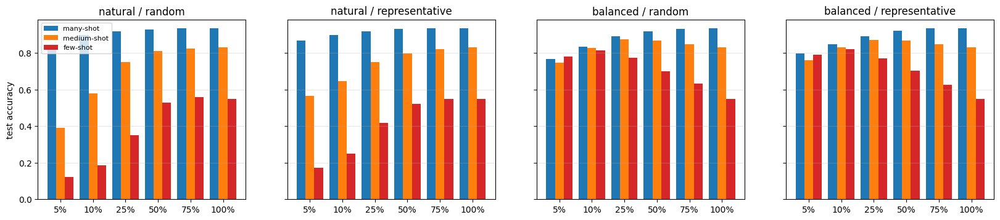

In [ ]:
fig, axes = plt.subplots(1, len(SETTINGS), figsize=(20, 3.8), sharey=True)
for ax, (b, s) in zip(axes, SETTINGS):
    d = res_c[(res_c.balance == b) & (res_c.selection == s)].groupby("fraction")[["acc_many", "acc_medium", "acc_few"]].mean()
    x = np.arange(len(d)); w = 0.27
    for i, (gcol, c) in enumerate(zip(d.columns, ["tab:blue", "tab:orange", "tab:red"])):
        ax.bar(x + (i - 1) * w, d[gcol], w, color=c, label=gcol.replace("acc_", "") + "-shot")
    ax.set_xticks(x); ax.set_xticklabels([f"{f:.0%}" for f in d.index]); ax.set_title(f"{b} / {s}"); ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=8)
save_fig("C_accuracy_by_class_group.png"); plt.show()

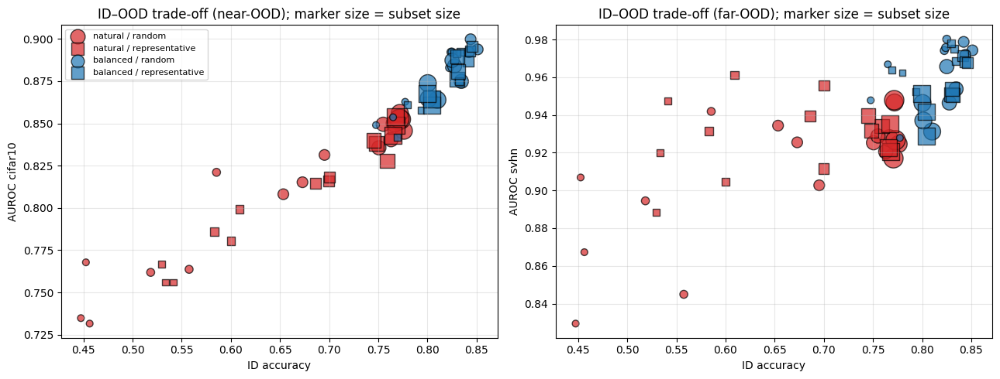

In [ ]:
# ID-OOD trade-off: does class balancing move models along the same curve or to a better one?
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ood in zip(axes, ["cifar10", "svhn"]):
    for b, s in SETTINGS:
        d = res_c[(res_c.balance == b) & (res_c.selection == s) & ~res_c.shared_full_run]
        c, mk, _ = style[(b, s)]
        ax.scatter(d.id_acc, d[f"auroc_energy_{ood}"], color=c, marker=mk, s=25 + 300 * d.fraction,
                   alpha=0.7, edgecolors="k", label=f"{b} / {s}")
    ax.set_xlabel("ID accuracy"); ax.set_ylabel(f"AUROC {ood}"); ax.grid(alpha=0.3)
    ax.set_title(f"ID–OOD trade-off ({'near' if ood == 'cifar10' else 'far'}-OOD); marker size = subset size")
axes[0].legend(fontsize=8); plt.tight_layout(); save_fig("C_tradeoff.png"); plt.show()

# 19. Summary across the three dimensions

In [ ]:
KEY = ["id_acc", "worst_class_acc", "auroc_energy_cifar10", "fpr95_energy_cifar10",
       "auroc_energy_svhn", "fpr95_energy_svhn", "ece", "feature_drift"]
mb = base_all.groupby(["strategy", "fraction"])[KEY].mean()
mc = res_c.groupby(["balance", "selection", "fraction"])[KEY + ["acc_few"]].mean()
small = [f for f in FRACTIONS if f < 1]
rows = [
    dict(dimension="1. Dataset size", comparison="100% minus 5% (baseline, random)",
         **(mb.loc[("random", 1.0)] - mb.loc[("random", FRACTIONS[0])]).to_dict()),
    dict(dimension="1. Dataset size", comparison="100% minus 5% (long-tailed pool, natural random)",
         **(mc.loc[("natural", "random", 1.0)] - mc.loc[("natural", "random", FRACTIONS[0])]).to_dict()),
    dict(dimension="2. Random vs. representative", comparison="representative minus random (baseline, mean over 5-75%)",
         **(mb.loc["representative"].loc[small] - mb.loc["random"].loc[small]).mean().to_dict()),
    dict(dimension="2. Random vs. representative", comparison="representative minus random (long-tailed, natural)",
         **(mc.loc[("natural", "representative")].loc[small] - mc.loc[("natural", "random")].loc[small]).mean().to_dict()),
    dict(dimension="3. Balanced vs. imbalanced", comparison="balanced minus natural (random selection)",
         **(mc.loc[("balanced", "random")].loc[small] - mc.loc[("natural", "random")].loc[small]).mean().to_dict()),
    dict(dimension="3. Balanced vs. imbalanced", comparison="balanced minus natural (representative selection)",
         **(mc.loc[("balanced", "representative")].loc[small] - mc.loc[("natural", "representative")].loc[small]).mean().to_dict()),
]
summary = pd.DataFrame(rows).set_index(["dimension", "comparison"])
save_table(summary.round(4), "D_summary_three_dimensions.csv")
summary.round(4)

id_acc  \
dimension                    comparison                                                   
1. Dataset size              100% minus 5% (baseline, random)                    0.0400   
                             100% minus 5% (long-tailed pool, natural random)    0.3197   
2. Random vs. representative representative minus random (baseline, mean ove...  0.0010   
                             representative minus random (long-tailed, natural)  0.0276   
3. Balanced vs. imbalanced   balanced minus natural (random selection)           0.1717   
                             balanced minus natural (representative selection)   0.1489   

                                                                                 worst_class_acc  \
dimension                    comparison                                                            
1. Dataset size              100% minus 5% (baseline, random)                             0.1433   
                             100% minus 5% (long-tailed pool, natural random)             0.0000   
2. Random vs. representative representative minus random (baseline, mean ove...           0.0127   
                             representative minus random (long-tailed, natural)           0.0007   
3. Balanced vs. imbalanced   balanced minus natural (random selection)                    0.1480   
                             balanced minus natural (representative selection)            0.1487   

                                                                                 auroc_energy_cifar10  \
dimension                    comparison                                                                 
1. Dataset size              100% minus 5% (baseline, random)                                  0.0179   
                             100% minus 5% (long-tailed pool, natural random)                  0.1076   
2. Random vs. representative representative minus random (baseline, mean ove...                0.0012   
                             representative minus random (long-tailed, natural)                0.0022   
3. Balanced vs. imbalanced   balanced minus natural (random selection)                         0.0703   
                             balanced minus natural (representative selection)                 0.0659   

                                                                                 fpr95_energy_cifar10  \
dimension                    comparison                                                                 
1. Dataset size              100% minus 5% (baseline, random)                                 -0.0592   
                             100% minus 5% (long-tailed pool, natural random)                 -0.3091   
2. Random vs. representative representative minus random (baseline, mean ove...                0.0002   
                             representative minus random (long-tailed, natural)               -0.0138   
3. Balanced vs. imbalanced   balanced minus natural (random selection)                        -0.1899   
                             balanced minus natural (representative selection)                -0.1780   

                                                                                 auroc_energy_svhn  \
dimension                    comparison                                                              
1. Dataset size              100% minus 5% (baseline, random)                               0.0114   
                             100% minus 5% (long-tailed pool, natural random)               0.0627   
2. Random vs. representative representative minus random (baseline, mean ove...             0.0026   
                             representative minus random (long-tailed, natural)             0.0215   
3. Balanced vs. imbalanced   balanced minus natural (random selection)                      0.0505   
                             balanced minus natural (representative selection)              0.0294   

                                                    

In [ ]:
# short auto-generated summary of Part C (fills in whatever has been run so far)
def pts(x): return f"{100*x:+.1f} pts"
for s in SELECTIONS:
    d = (mc.loc[("balanced", s)].loc[small] - mc.loc[("natural", s)].loc[small])
    best = d.acc_few.idxmax()
    print(f"[{s} selection] balanced vs. natural, averaged over 5-75%: ID acc {pts(d.id_acc.mean())}, "
          f"few-shot acc {pts(d.acc_few.mean())} (largest at {best:.0%}: {pts(d.acc_few.max())}), "
          f"worst-class acc {pts(d.worst_class_acc.mean())}, AUROC CIFAR-10 {pts(d.auroc_energy_cifar10.mean())}, "
          f"AUROC SVHN {pts(d.auroc_energy_svhn.mean())}, FPR@95 CIFAR-10 {pts(d.fpr95_energy_cifar10.mean())}, "
          f"ECE {pts(d.ece.mean())}, feature drift {d.feature_drift.mean():+.4f}")
if tests_bal is not None:
    n_sig = (tests_bal.p_value < 0.05).groupby(tests_bal.metric).sum()
    print("\nNumber of (selection, size) cells with p < 0.05 for balanced vs. natural:", n_sig[n_sig > 0].to_dict())

[random selection] balanced vs. natural, averaged over 5-75%: ID acc +17.2 pts, few-shot acc +39.1 pts (largest at 5%: +65.7 pts), worst-class acc +14.8 pts, AUROC CIFAR-10 +7.0 pts, AUROC SVHN +5.0 pts, FPR@95 CIFAR-10 -19.0 pts, ECE +1.8 pts, feature drift +0.0088
[representative selection] balanced vs. natural, averaged over 5-75%: ID acc +14.9 pts, few-shot acc +36.0 pts (largest at 5%: +61.8 pts), worst-class acc +14.9 pts, AUROC CIFAR-10 +6.6 pts, AUROC SVHN +2.9 pts, FPR@95 CIFAR-10 -17.8 pts, ECE +2.3 pts, feature drift +0.0073

Number of (selection, size) cells with p < 0.05 for balanced vs. natural: {'acc_few': 10, 'acc_many': 8, 'acc_medium': 10, 'auroc_energy_cifar10': 10, 'auroc_energy_svhn': 4, 'ece': 5, 'ece_after_temp_scaling': 6, 'feature_drift': 3, 'fpr95_energy_cifar10': 10, 'fpr95_energy_svhn': 5, 'id_acc': 10, 'worst_class_acc': 3}


# 20. Save the outputs of Parts A–D in google drive

In [ ]:
json.dump({"baseline_dir": BASELINE_DIR, "imbalance_ratio": IMB_RATIO, "lt_seed": LT_SEED, "n_lt_pool": int(N_LT),
           "seeds_part_c": SEEDS_C, "fractions": FRACTIONS, "balances": BALANCES, "selections": SELECTIONS,
           "train_steps": TRAIN_STEPS, "batch_size": BATCH_SIZE, "save_models_part_c": SAVE_MODELS_C},
          open(os.path.join(PART2_DIR, "part2_settings.json"), "w"), indent=2)

print(f"All Part 2 outputs are saved in {PART2_DIR}")
for sub, path in DIRS.items():
    files = sorted(os.listdir(path))
    size = sum(os.path.getsize(os.path.join(path, f)) for f in files if os.path.isfile(os.path.join(path, f)))
    print(f"  {sub:<12} {len(files):>4} files  ({size/1e6:.1f} MB)")

All Part 2 outputs are saved in /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22/outputs_part2
  figures         6 files  (0.8 MB)
  tables         14 files  (1.3 MB)
  subsets        74 files  (2.6 MB)
  runs           63 files  (1.4 MB)
  predictions    63 files  (492.4 MB)
  models          0 files  (0.0 MB)


# 21. Part E — Response to the supervisor feedback (round 2)

## 21.0 Restore the earlier results from Drive

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass                                                      # not running in Colab
if "PROJECT_DIR" not in globals():                            # Section 0 was not run
    PROJECT_DIR = "/content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD"; os.makedirs(PROJECT_DIR, exist_ok=True)

OLD_DRIVE_DIR = "/content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22"   # <<< folder of the first run (read only; nothing is copied)

# where the EARLIER results are read from: the project folder if it holds a complete baseline, otherwise the old folder
_marker = os.path.join("outputs_part2", "tables", "C_results_all_runs.csv")
SRC_DIR = PROJECT_DIR if os.path.isfile(os.path.join(PROJECT_DIR, _marker)) else OLD_DRIVE_DIR
assert os.path.isfile(os.path.join(SRC_DIR, _marker)), (f"No earlier results found in {SRC_DIR}. Set OLD_DRIVE_DIR to the folder of the first run "
                                                       f"(it contains outputs/ and outputs_part2/).")
DRIVE_DIR = SRC_DIR
BASELINE_DIR = os.path.join(SRC_DIR, "outputs")
PART2_DIR = os.path.join(SRC_DIR, "outputs_part2")
assert os.path.isdir(BASELINE_DIR) and os.path.isdir(PART2_DIR), f"{SRC_DIR} must contain outputs/ and outputs_part2/"
DIRS = {d: os.path.join(PART2_DIR, d) for d in ["figures", "tables", "subsets", "runs", "predictions", "models"]}   # as in Section 15 (read only here)
print("Earlier results are read from :", SRC_DIR)
print("New results are written to    :", PROJECT_DIR)

# constants of Sections 8 and 18 (unchanged)
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
STRATEGIES = ["random", "representative"]
SEEDS = [0, 1, 2]
BALANCES = ["natural", "balanced"]; SELECTIONS = ["random", "representative"]; SEEDS_C = SEEDS
labels_pool = pool_y.cpu().numpy()

# helpers of Section 17
def per_class_metrics(logits, y, groups=None):
    pred = np.asarray(logits).argmax(1)
    acc_c = np.array([(pred[y == c] == c).mean() for c in range(NUM_CLASSES)])
    r = dict(worst_class_acc=acc_c.min(), worst10_class_acc=np.sort(acc_c)[:10].mean(), class_acc_std=acc_c.std())
    for g, cls in (groups or {}).items():
        r[f"acc_{g}"] = acc_c[cls].mean() if len(cls) else np.nan
    return r, acc_c

def load_logits(folder, run):
    with np.load(os.path.join(folder, f"logits_{run}.npz")) as z:
        return {k: z[k].astype(np.float32) for k in z.files}

# long-tailed pool of Section 18.1, exactly as saved
_cfg = json.load(open(os.path.join(DIRS["subsets"], "lt_pool_config.json")))
IMB_RATIO, LT_SEED, N_LT = _cfg["imbalance_ratio"], _cfg["lt_seed"], _cfg["n_lt_pool"]
lt_counts = np.array(_cfg["class_counts"]); GROUPS = {g: np.array(v, dtype=int) for g, v in _cfg["groups"].items()}
lt_pool = np.load(os.path.join(DIRS["subsets"], "lt_pool_indices.npy"))
assert np.array_equal(np.bincount(labels_pool[lt_pool], minlength=NUM_CLASSES), lt_counts), "long-tailed pool does not match the saved one"

# results and the exact subsets used for training (loaded, not re-built)
res = pd.read_csv(os.path.join(BASELINE_DIR, "tables", "results_all_runs.csv"))
base_all = pd.read_csv(os.path.join(DIRS["tables"], "B_baseline_all_metrics_per_run.csv"))
res_c = pd.read_csv(os.path.join(DIRS["tables"], "C_results_all_runs.csv"))
SUBSETS = {(s, f, sd): np.load(os.path.join(BASELINE_DIR, "subsets", f"{s}_{f:.2f}_seed{sd}.npy"))
           for s in STRATEGIES for f in FRACTIONS for sd in SEEDS}
SUBSETS_C = {(b, s, f, sd): np.load(os.path.join(DIRS["subsets"], f"{b}-{s}_{f:.2f}_seed{sd}.npy"))
             for b in BALANCES for s in SELECTIONS for f in FRACTIONS for sd in SEEDS_C}
n_models = len(glob.glob(os.path.join(BASELINE_DIR, "models", "*", "config.json")))
print(f"Restored: {len(res)} baseline rows, {len(res_c)} Part C rows, {len(SUBSETS)} + {len(SUBSETS_C)} subsets, "
      f"long-tailed pool of {N_LT} images, {n_models} saved baseline models (33 expected).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earlier results are read from : /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22
New results are written to    : /content/drive/MyDrive/OOD_ID_Baseline_Results/Data_Splitting_ID_OOD
Restored: 36 baseline rows, 72 Part C rows, 36 + 72 subsets, long-tailed pool of 9754 images, 33 saved baseline models (33 expected).


## 21.1 Setup and settings

In [ ]:
from scipy.stats import ttest_rel, kendalltau, t as t_dist   # NOTE: ttest_rel is also required by paired_tests() in Section 17
import re

# output folders (next to outputs_part2 on Drive)
PART3_DIR = os.path.join(os.path.dirname(BASELINE_DIR), "outputs_part3")
DIRS3 = {d: os.path.join(PART3_DIR, d) for d in ["figures", "tables", "runs", "posthoc", "predictions"]}
for d in DIRS3.values():
    os.makedirs(d, exist_ok=True)

def save_table3(df, name, index=True):
    df.to_csv(os.path.join(DIRS3["tables"], name), index=index)

def save_fig3(name):
    plt.savefig(os.path.join(DIRS3["figures"], name), dpi=150, bbox_inches="tight")

def _json_default(o):
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f"not JSON serialisable: {type(o)}")

# training protocols
def atomic_json(obj, path, **kw):
    # write to a temporary file, then rename: a crash can never leave a half-written (unreadable) result file
    tmp = path + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(obj, fh, default=_json_default, **kw); fh.flush(); os.fsync(fh.fileno())
    os.replace(tmp, path)

def atomic_npz(path, **arrays):
    tmp = path + ".tmp.npz"; np.savez_compressed(tmp, **arrays); os.replace(tmp, path)

def log_line(text):
    with open(os.path.join(PART3_DIR, "run_log.txt"), "a") as fh: fh.write(time.strftime("%Y-%m-%d %H:%M:%S ") + text + "\n")

SAVE_MODELS_E = False            # True = also store every new fine-tuned model (fp16, ~170 MB each; 537 runs = ~90 GB, only for selected blocks!)

PROTOCOL_SPECS = {"steps1000": ("steps", TRAIN_STEPS), "E3": ("epochs", 3), "E10": ("epochs", 10)}
EPOCH_BUDGETS = [3, 10]          # fixed-epoch protocols on the baseline pool (3 epochs = same budget as 1,000 steps on the full 45k pool)
EPOCH_SEEDS = list(SEEDS)
STEP_SWEEP = {0.05: [250, 3000], 0.25: [250, 3000]}     # extra step budgets at FIXED subset size (random selection)
STEP_SWEEP_SEEDS = list(SEEDS)

# class-balancing controls (Section 27)
CTRL_FRACS = list(FRACTIONS)                 # all sizes -> the controls fully re-run Part C with the new evaluation (incl. Mahalanobis)
CTRL_BALANCES = ["natural", "balanced"]      # which images: natural long-tailed subset | class-balanced subset
CTRL_SELECTIONS = ["random", "representative"]
CTRL_PROCESSES = ["plain", "wloss", "balsamp"]                       # how they are used (core factorial)
CTRL_EXT_PROCESSES = ["wsqrt", "cbeff", "logitadj", "sqrtsamp"]      # additional balancing methods (natural subsets)
CTRL_EXT_FRACS = [0.05, 0.25, 1.00]
CTRL_EPOCH_PROTOCOLS = ["E3", "E10"]         # the controls are repeated under these fixed-epoch protocols ...
CTRL_EPOCH_SELECTIONS = ["random"]           # ... for these selection rules
CTRL_SEEDS = list(SEEDS)
PROCESS_SPEC = {"plain": ("ce", "uniform"), "wloss": ("weighted", "uniform"), "balsamp": ("ce", "balanced"),
                "wsqrt": ("weighted_sqrt", "uniform"), "cbeff": ("cb_effective", "uniform"),
                "logitadj": ("logit_adjust", "uniform"), "sqrtsamp": ("ce", "sqrt")}

# fine-tuning regimes / backbones (Section 28)
BACKBONES = {"in1k": MODEL_NAME, "in21k": "google/vit-base-patch16-224-in21k"}
REGIMES = {"probe": dict(head_only=True),            # frozen backbone, only the new head is trained (linear probe)
           "lr0.1x": dict(lr_mult=0.1), "lr10x": dict(lr_mult=10.0),   # backbone learning rate x0.1 / x10
           "in21k": dict(backbone="in21k")}           # a differently pretrained backbone, baseline recipe
REGIME_FRACS = [0.05, 0.25, 1.00]
REGIME_SEEDS = list(SEEDS)

SAVE_PREDICTIONS_E = True        # logits and detector scores of every new run (small)

# OOD detectors
MAHA_MAX_PER_CLASS = 100         # at most this many (non-augmented) training images per class are used to fit the detectors
MAHA_SHRINK = 0.01               # covariance shrinkage towards a scaled identity
KNN_K = 20                       # k of the k-nearest-neighbour detector
SCORES = ["msp", "energy", "maha_train", "maha_val", "knn"]
SCORE_NAME = {"msp": "MSP", "energy": "Energy", "maha_train": "Mahalanobis (fit on training subset)",
              "maha_val": "Mahalanobis (fit on held-out validation set)", "knn": f"kNN (k={KNN_K}, cosine, training subset)"}

# re-load earlier results if a variable is missing (restart)
if "res" not in globals():
    res = pd.read_csv(os.path.join(BASELINE_DIR, "tables", "results_all_runs.csv"))

# run-time estimate, based on the speed measured in the baseline
_trained = res[~res.shared_full_run.astype(bool)]
SEC_PER_STEP = _trained.train_minutes.sum() * 60 / (len(_trained) * TRAIN_STEPS)
EVAL_MIN_PER_RUN = 2.2            # rough time of one evaluation (test + validation + 5 OOD sets + training features)

def protocol_steps(kind, value, n_train):
    # number of optimisation steps for a subset of n_train images: fixed steps, or a fixed number of epochs
    return int(value) if kind == "steps" else max(1, int(round(value * n_train / BATCH_SIZE)))

def estimate_hours(jobs):
    return (sum(j["steps"] for j in jobs) * SEC_PER_STEP + len(jobs) * EVAL_MIN_PER_RUN * 60) / 3600

print(f"Measured training speed in the baseline: {SEC_PER_STEP:.3f} s per step "
      f"({SEC_PER_STEP*TRAIN_STEPS/60:.1f} min per 1,000-step run)")
print("Part E outputs:", PART3_DIR)

Measured training speed in the baseline: 0.570 s per step (9.5 min per 1,000-step run)
Part E outputs: /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22/outputs_part3


## 21.2 Additional OOD datasets

In [ ]:
import torchvision
def _to32(pil):
    return np.asarray(pil.convert("RGB").resize((32, 32), Image.BILINEAR), dtype=np.uint8).transpose(2, 0, 1)

extra_np = {}
try:
    _dtd = [torchvision.datasets.DTD(os.path.join(DATA_DIR, "dtd"), split=s, download=True) for s in ("train", "val", "test")]
    extra_np["textures"] = np.stack([_to32(im) for d in _dtd for im, _ in d])
except Exception as e:
    print("Textures (DTD) not available -> skipped:", repr(e)[:200])
try:
    _mn = torchvision.datasets.MNIST(os.path.join(DATA_DIR, "mnist"), train=False, download=True)
    extra_np["mnist"] = np.stack([_to32(Image.fromarray(np.asarray(x))) for x in _mn.data])
except Exception as e:
    print("MNIST not available -> skipped:", repr(e)[:200])
extra_np["noise"] = np.clip(np.random.default_rng(0).normal(127.5, 50, (5000, 3, 32, 32)), 0, 255).astype(np.uint8)

ood_all = dict(ood_sets)                                              # CIFAR-10, SVHN (as in the baseline) + the new sets
for k, v in extra_np.items():
    ood_all[k] = torch.from_numpy(np.ascontiguousarray(v)).to(device)
OODS_CORE = list(ood_sets)                                            # available for the old runs too
OODS = list(ood_all)
OOD_NAME = {"cifar10": "CIFAR-10 (near-OOD)", "svhn": "SVHN (far-OOD)", "textures": "Textures (far-OOD)",
            "mnist": "MNIST (far-OOD)", "noise": "Gaussian noise"}
AUROC_COLS = [f"auroc_{sc}_{o}" for o in OODS for sc in SCORES]
FPR_COLS = [f"fpr95_{sc}_{o}" for o in OODS for sc in SCORES]
CORE = ["id_acc", "worst_class_acc"] + AUROC_COLS + FPR_COLS + ["ece", "ece_after_temp_scaling", "feature_drift"]
print("OOD sets:", {k: len(v) for k, v in ood_all.items()})

OOD sets: {'cifar10': 10000, 'svhn': 26032, 'textures': 5640, 'mnist': 10000, 'noise': 5000}


# 22. Feature-based OOD detectors: Mahalanobis distance and kNN

In [ ]:
def capped_train_idx(subset_idx, cap=MAHA_MAX_PER_CLASS, seed=0):
    # at most `cap` images per class (all images of rare classes are kept); positions in the selection pool
    subset_idx = np.asarray(subset_idx); y = labels_pool[subset_idx]; rng = np.random.default_rng(seed); keep = []
    for c in np.unique(y):
        ids = subset_idx[y == c]
        keep.append(ids if len(ids) <= cap else rng.choice(ids, cap, replace=False))
    return np.sort(np.concatenate(keep))

@torch.no_grad()
def fit_gaussians(feats, labels, shrink=None):
    # class means + ONE shared (tied) covariance, shrunk towards a scaled identity; classes without images are skipped
    shrink = MAHA_SHRINK if shrink is None else shrink
    X, y = feats.to(device).double(), torch.as_tensor(labels).to(device)
    D = X.shape[1]
    cnt = torch.bincount(y, minlength=NUM_CLASSES).double(); present = cnt > 0
    mu = torch.zeros(NUM_CLASSES, D, dtype=torch.double, device=device).index_add_(0, y, X)
    mu[present] /= cnt[present, None]
    Xc = X - mu[y]
    cov = Xc.T @ Xc / len(X)
    cov = (1 - shrink) * cov + shrink * (torch.trace(cov) / D) * torch.eye(D, dtype=torch.double, device=device)
    prec = torch.linalg.inv(cov); mu = mu[present]
    return dict(mu=mu, classes=torch.where(present)[0], prec=prec, mpm=((mu @ prec) * mu).sum(1))

@torch.no_grad()
def maha_score(feats, G, chunk=4096):
    # returns (score = -min_c squared Mahalanobis distance [higher = more ID], predicted class) as numpy arrays
    out, cls = [], []
    for i in range(0, len(feats), chunk):
        X = feats[i:i + chunk].to(device).double(); XP = X @ G["prec"]
        d2 = (XP * X).sum(1, keepdim=True) - 2 * XP @ G["mu"].T + G["mpm"][None]
        m, a = d2.min(1)
        out.append((-m).float().cpu()); cls.append(G["classes"][a].cpu())
    return torch.cat(out).numpy(), torch.cat(cls).numpy()

@torch.no_grad()
def knn_bank(feats):
    return F.normalize(feats.to(device).float(), dim=1)

@torch.no_grad()
def knn_score(feats, bank, k=None, chunk=2048):
    # cosine similarity to the k-th nearest training feature (higher = more ID)
    k = min(k or KNN_K, len(bank)); out = []
    for i in range(0, len(feats), chunk):
        X = F.normalize(feats[i:i + chunk].to(device).float(), dim=1)
        out.append((X @ bank.T).topk(k, dim=1).values[:, -1].cpu())
    return torch.cat(out).numpy()

# self-check on synthetic Gaussians: ID classes are recovered and far-away points are flagged as OOD by both detectors
_g = torch.Generator().manual_seed(0)
_mu = torch.randn(NUM_CLASSES, 16, generator=_g) * 3
_y = torch.randint(0, NUM_CLASSES, (3000,), generator=_g); _ftr = _mu[_y] + torch.randn(3000, 16, generator=_g); _G = fit_gaussians(_ftr, _y)
_y2 = torch.randint(0, NUM_CLASSES, (500,), generator=_g); _fid = _mu[_y2] + torch.randn(500, 16, generator=_g)
_fo = torch.randn(500, 16, generator=_g) * 4 + 15
_s_id, _pred = maha_score(_fid, _G); _s_ood, _ = maha_score(_fo, _G)
assert auroc(_s_id, _s_ood) > 0.99 and (_pred == _y2.numpy()).mean() > 0.95
_bank = knn_bank(_ftr); assert auroc(knn_score(_fid, _bank), knn_score(torch.randn(500, 16, generator=_g) * 3, _bank)) > 0.9
print("Mahalanobis and kNN self-checks passed.")

Mahalanobis and kNN self-checks passed.


## 22.1 Mechanism diagnostics

In [ ]:
def feature_diagnostics(feats_id, y, logits_id, feats_o, logits_o, n=2000):
    X = feats_id.float(); yy = torch.as_tensor(y); d = {}
    sel = np.sort(np.random.default_rng(0).choice(len(X), min(n, len(X)), replace=False))
    s = torch.linalg.svdvals(X[sel] - X[sel].mean(0)); p = s / s.sum()
    d["diag_eff_rank"] = float(torch.exp(-(p * torch.log(p.clamp_min(1e-12))).sum()))
    mu = X.mean(0)
    cm = torch.stack([X[yy == c].mean(0) if (yy == c).any() else mu for c in range(NUM_CLASSES)])
    d["diag_nc1"] = float(((X - cm[yy]) ** 2).sum(1).mean() / ((cm - mu) ** 2).sum(1).mean())
    d["diag_feat_norm_id"] = float(X.norm(dim=1).mean()); d["diag_maxlogit_id"] = float(logits_id.max(1).values.mean())
    for o in feats_o:
        d[f"diag_feat_norm_{o}"] = float(feats_o[o].float().norm(dim=1).mean())
        d[f"diag_maxlogit_{o}"] = float(logits_o[o].max(1).values.mean())
    return d

## 22.2 Reference point: the pretrained backbones

In [ ]:
BACKBONE_REF = {}
cka_idx_t = torch.as_tensor(cka_idx, device=device)

def backbone_reference(name):
    if name in BACKBONE_REF: return BACKBONE_REF[name]
    path = os.path.join(DIRS3["tables"], f"E_pretrained_reference_{name}.json")
    if name == "in1k" and "pre_feats_cka" in globals():
        pre_feats, m = pre_feats_cka, None
    else:
        m = ViTForImageClassification.from_pretrained(BACKBONES[name]).to(device).eval()
        pre_feats = infer(m, test_x[cka_idx_t], with_logits=False)[0]
    if os.path.exists(path):
        ref = json.load(open(path))
    else:
        if m is None: m = ViTForImageClassification.from_pretrained(BACKBONES[name]).to(device).eval()
        tr = capped_train_idx(np.arange(N_POOL))
        f_tr = infer(m, pool_x[torch.as_tensor(tr, device=device)], with_logits=False)[0]
        f_val = infer(m, val_x, with_logits=False)[0]; f_id = infer(m, test_x, with_logits=False)[0]
        G = {"maha_train": fit_gaussians(f_tr, labels_pool[tr]), "maha_val": fit_gaussians(f_val, val_y.cpu())}; bank = knn_bank(f_tr)
        s_id = {k: maha_score(f_id, g) for k, g in G.items()}; k_id = knn_score(f_id, bank)
        ref = {"maha_cls_acc_train": float((s_id["maha_train"][1] == test_y.cpu().numpy()).mean())}
        for o, X in ood_all.items():
            f_o = infer(m, X, with_logits=False)[0]
            for k, g in G.items():
                s_o = maha_score(f_o, g)[0]
                ref[f"auroc_{k}_{o}"] = auroc(s_id[k][0], s_o); ref[f"fpr95_{k}_{o}"] = fpr_at_95_tpr(s_id[k][0], s_o)
            k_o = knn_score(f_o, bank); ref[f"auroc_knn_{o}"] = auroc(k_id, k_o); ref[f"fpr95_knn_{o}"] = fpr_at_95_tpr(k_id, k_o)
        atomic_json(ref, path, indent=2)
    del m; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    BACKBONE_REF[name] = dict(ref=ref, pre_feats=pre_feats)
    return BACKBONE_REF[name]

PRETRAINED_REF = backbone_reference("in1k")["ref"]
pd.Series(PRETRAINED_REF).round(4).to_frame("pretrained ViT (ImageNet-1k, no fine-tuning)")

,"pretrained ViT (ImageNet-1k, no fine-tuning)"
maha_cls_acc_train,0.8326
auroc_maha_train_cifar10,0.8280
fpr95_maha_train_cifar10,0.6287
auroc_maha_val_cifar10,0.8241
fpr95_maha_val_cifar10,0.6469
auroc_knn_cifar10,0.7798
fpr95_knn_cifar10,0.7159
auroc_maha_train_svhn,0.9303
fpr95_maha_train_svhn,0.3604
auroc_maha_val_svhn,0.9317


## 22.3 Extended evaluation

In [ ]:
def evaluate_v2(model, train_idx, groups=None, backbone="in1k"):
    # train_idx: positions (in the selection pool) of the images the model was trained on -> used to fit the training-subset detectors
    pre_feats = backbone_reference(backbone)["pre_feats"]
    r, store = {}, {}
    y = test_y.cpu()
    feats_id, logits_id = infer(model, test_x)
    r["id_acc"] = (logits_id.argmax(1) == y).float().mean().item()
    r["id_bal_acc"] = balanced_accuracy_score(y.numpy(), logits_id.argmax(1).numpy())
    feats_val, logits_val = infer(model, val_x)
    r["val_acc"] = (logits_val.argmax(1) == val_y.cpu()).float().mean().item()

    tr_idx = capped_train_idx(train_idx)                                   # clean (non-augmented) training images
    feats_tr, _ = infer(model, pool_x[torch.as_tensor(tr_idx, device=device)], with_logits=False)
    G = {"maha_train": fit_gaussians(feats_tr, labels_pool[tr_idx]), "maha_val": fit_gaussians(feats_val, val_y.cpu())}
    bank = knn_bank(feats_tr)
    r["n_maha_fit_train"] = int(len(tr_idx))

    def all_scores(feats, logits):
        s = ood_scores(logits); pred = None
        for k, g in G.items():
            s[k], p = maha_score(feats, g)
            if k == "maha_train": pred = p
        s["knn"] = knn_score(feats, bank)
        return s, pred

    s_id, pred_id = all_scores(feats_id, logits_id)
    r["maha_cls_acc_train"] = float((pred_id == y.numpy()).mean())
    store.update(logits_cifar100_test=logits_id.numpy(), logits_cifar100_val=logits_val.numpy(),
                 **{f"{k}_cifar100_test": s_id[k] for k in SCORES[2:]})
    feats_o, logits_o = {}, {}
    for name, X in ood_all.items():
        f_o, l_o = infer(model, X); s_o, _ = all_scores(f_o, l_o)
        feats_o[name], logits_o[name] = f_o, l_o
        store[f"logits_{name}"] = l_o.numpy(); store.update({f"{k}_{name}": s_o[k] for k in SCORES[2:]})
        for sc in SCORES:
            r[f"auroc_{sc}_{name}"] = auroc(s_id[sc], s_o[sc])
            r[f"fpr95_{sc}_{name}"] = fpr_at_95_tpr(s_id[sc], s_o[sc])
    r["ece"] = ece(logits_id, y)
    T = fit_temperature(logits_val, val_y.cpu())
    r["temperature"], r["ece_after_temp_scaling"] = T, ece(logits_id / T, y)
    r["cka"] = linear_cka(pre_feats, feats_id[cka_idx]); r["feature_drift"] = 1 - r["cka"]
    pc, _ = per_class_metrics(logits_id.numpy(), y.numpy(), groups)
    r.update(pc)
    r.update(feature_diagnostics(feats_id, y, logits_id, feats_o, logits_o))
    return r, store

# 23. Trainer with an explicit protocol, balancing options and fine-tuning regimes

In [ ]:
def build_model_v2(seed, backbone):
    if backbone == "in1k": return build_finetune_model(seed)
    torch.manual_seed(seed)
    m = ViTForImageClassification.from_pretrained(
        BACKBONES[backbone], num_labels=NUM_CLASSES, ignore_mismatched_sizes=True,
        id2label=dict(enumerate(CLASS_NAMES)), label2id={n: i for i, n in enumerate(CLASS_NAMES)})
    return m.to(device)

def train_one_v2(subset_idx, seed, steps, loss_kind="ce", sampler="uniform", backbone="in1k", lr_mult=1.0, head_only=False, log_every=250):
    set_seed(seed)
    model = build_model_v2(seed, backbone).train()
    if head_only:
        for p in model.vit.parameters(): p.requires_grad_(False)
    opt = make_optimizer(model)
    for gp in opt.param_groups:
        if gp["lr"] == LR_BACKBONE: gp["lr"] = LR_BACKBONE * (0.0 if head_only else lr_mult)
    warm = max(1, int(WARMUP_FRAC * steps))
    def lam(step):
        if step < warm: return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, steps - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and AMP_DTYPE == torch.float16))
    idx_t = torch.as_tensor(subset_idx, device=device)
    y_sub = pool_y[idx_t]
    counts = torch.bincount(y_sub, minlength=NUM_CLASSES).float(); present = counts > 0; n_all = float(len(idx_t))
    cw, log_prior = None, None
    if loss_kind == "weighted":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = n_all / (present.sum() * counts[present])
    elif loss_kind == "weighted_sqrt":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = counts[present] ** -0.5
    elif loss_kind == "cb_effective":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = (1 - 0.999) / (1 - 0.999 ** counts[present])
    elif loss_kind == "logit_adjust":
        log_prior = torch.log(counts.clamp_min(1) / n_all)
    elif loss_kind != "ce":
        raise ValueError(loss_kind)
    p_sample = None
    if sampler == "balanced": p_sample = counts.clamp_min(1)[y_sub].pow(-1.0).cpu()      # P(image) ∝ 1 / n_class
    elif sampler == "sqrt": p_sample = counts.clamp_min(1)[y_sub].pow(-0.5).cpu()        # class prob ∝ sqrt(n_class)
    elif sampler != "uniform": raise ValueError(sampler)
    g = torch.Generator().manual_seed(seed)
    order = torch.empty(0, dtype=torch.long)
    losses, t0 = [], time.time()
    for step in range(steps):
        if p_sample is not None:
            b = torch.multinomial(p_sample, BATCH_SIZE, replacement=True, generator=g).to(device)
        else:
            while len(order) < BATCH_SIZE:                           # reshuffle each pass over the subset
                order = torch.cat([order, torch.randperm(len(idx_t), generator=g)])
            b, order = order[:BATCH_SIZE].to(device), order[BATCH_SIZE:]
        xb, yb = preprocess(pool_x[idx_t[b]], train=True), pool_y[idx_t[b]]
        with amp_ctx():
            logits = model(pixel_values=xb).logits
            if log_prior is not None: logits = logits.float() + log_prior
            loss = F.cross_entropy(logits, yb, weight=cw)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if (step + 1) % log_every == 0 or step + 1 == steps:
            print(f"    step {step+1:>5}/{steps}  loss {np.mean(losses[-log_every:]):.4f}  {(time.time()-t0)/60:.1f} min")
    return model.eval(), losses, (time.time() - t0) / 60

def mkjob(run, idx, seed, steps, meta, loss="ce", sampler="uniform", groups=None, backbone="in1k", lr_mult=1.0, head_only=False):
    return dict(run=run, idx=idx, seed=seed, steps=int(steps), loss=loss, sampler=sampler, groups=groups, backbone=backbone,
                lr_mult=lr_mult, head_only=head_only, meta=meta)

def run_jobs(jobs, tag):
    # every finished run is saved as <run>.json and skipped next time
    todo = [j for j in jobs if not os.path.exists(os.path.join(DIRS3["runs"], j["run"] + ".json"))]
    print(f"[{tag}] {len(jobs)} runs, {len(jobs)-len(todo)} already finished, {len(todo)} to go "
          f"(about {estimate_hours(todo):.1f} h on this GPU)")
    t_all = time.time()
    for k, j in enumerate(todo, 1):
        print(f"[{k}/{len(todo)}] {j['run']}  ({len(j['idx'])} images, {j['steps']} steps = "
              f"{j['steps']*BATCH_SIZE/len(j['idx']):.1f} epochs)")
        model, losses, minutes = train_one_v2(j["idx"], j["seed"], j["steps"], j["loss"], j["sampler"], j["backbone"], j["lr_mult"], j["head_only"])
        metrics, store = evaluate_v2(model, j["idx"], j["groups"], j["backbone"])
        if SAVE_PREDICTIONS_E:
            atomic_npz(os.path.join(DIRS3["predictions"], f"{j['run']}.npz"),
                       **{k2: (v.astype(np.float16) if k2.startswith("logits") else v.astype(np.float32)) for k2, v in store.items()})
        if SAVE_MODELS_E:
            mdir = os.path.join(PART3_DIR, "models", j["run"]); os.makedirs(mdir, exist_ok=True)
            model.half().save_pretrained(mdir)
        row = dict(run=j["run"], **j["meta"], seed=j["seed"], n_train=len(j["idx"]), steps=j["steps"],
                   epochs_seen=j["steps"] * BATCH_SIZE / len(j["idx"]), train_minutes=round(minutes, 2),
                   final_train_loss=float(np.mean(losses[-50:])), shared_full_run=False, losses=losses, **metrics)
        atomic_json(row, os.path.join(DIRS3["runs"], j["run"] + ".json"))          # written last: its existence = "run finished and saved"
        log_line(f"{j['run']}  id_acc={row['id_acc']:.4f}  {minutes:.1f} min")
        print(f"    ID acc {row['id_acc']:.4f} | AUROC CIFAR-10: energy {row['auroc_energy_cifar10']:.4f} "
              f"maha {row['auroc_maha_train_cifar10']:.4f} knn {row['auroc_knn_cifar10']:.4f} | SVHN: energy {row['auroc_energy_svhn']:.4f} "
              f"maha {row['auroc_maha_train_svhn']:.4f} | ECE {row['ece']:.4f}")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()
    print(f"[{tag}] done in {(time.time()-t_all)/60:.1f} min")

def load_runs(prefix):
    recs = []
    for p in sorted(glob.glob(os.path.join(DIRS3["runs"], prefix + "*.json"))):
        try: recs.append(json.load(open(p)))
        except Exception as e:                                   # unreadable file (should not happen with atomic writes): re-run it
            print("unreadable run file moved aside, will be re-run:", os.path.basename(p), repr(e)[:80]); os.replace(p, p + ".corrupt")
    loss = {r["run"]: r.pop("losses") for r in recs}
    return pd.DataFrame(recs), loss

### Check: does the new trainer reproduce the baseline?

In [ ]:
RUN_REPRO_CHECK = True
_chk_path = os.path.join(DIRS3["tables"], "E_repro_check_train_one_v2.csv")
if RUN_REPRO_CHECK and os.path.exists(_chk_path):
    chk = pd.read_csv(_chk_path, index_col=0)
    print("Done earlier; the saved comparison is shown:")
    display(chk.round(5))
elif RUN_REPRO_CHECK:
    _s, _f, _sd = "random", FRACTIONS[0], SEEDS[0]
    _ref = res[(res.strategy == _s) & (res.fraction == _f) & (res.seed == _sd)].iloc[0]
    _m, _l, _ = train_one_v2(SUBSETS[(_s, _f, _sd)], _sd, TRAIN_STEPS)
    _r, _ = evaluate_v2(_m, SUBSETS[(_s, _f, _sd)])
    _keys = ["id_acc", "auroc_msp_cifar10", "auroc_energy_cifar10", "auroc_energy_svhn", "ece", "cka"]
    chk = pd.DataFrame({"recorded (Section 11)": {k: _ref[k] for k in _keys}, "train_one_v2 re-run": {k: _r[k] for k in _keys}})
    chk["abs. difference"] = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs()
    save_table3(chk.round(5), "E_repro_check_train_one_v2.csv")
    del _m; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    display(chk.round(5))

    step   250/1000  loss 2.3418  2.4 min
    step   500/1000  loss 0.1175  4.8 min
    step   750/1000  loss 0.0261  7.2 min
    step  1000/1000  loss 0.0190  9.7 min


,recorded (Section 11),train_one_v2 re-run,abs. difference
id_acc,0.86580,0.86580,0.0
auroc_msp_cifar10,0.91777,0.91777,0.0
auroc_energy_cifar10,0.92051,0.92051,0.0
auroc_energy_svhn,0.97262,0.97262,0.0
ece,0.03074,0.03074,0.0
cka,0.76663,0.76663,0.0


## 23.1 Job definitions and the run plan

In [ ]:
def protocol_jobs():                                 # 25.2a: fixed-epoch protocols on the baseline pool
    jobs = []
    for E in EPOCH_BUDGETS:
        for sd in EPOCH_SEEDS:
            for f in FRACTIONS:
                for s in STRATEGIES:
                    if f >= 1 and s != "random": continue              # identical full-data run (as in Section 11)
                    idx = SUBSETS[(s, f, sd)]
                    jobs.append(mkjob(f"E{E}_{s}_{f:.2f}_seed{sd}", idx, sd, protocol_steps("epochs", E, len(idx)),
                                      dict(experiment="protocol", protocol=f"E{E}", strategy=s, fraction=f)))
    return jobs

def sweep_jobs():                                    # 25.2b: step sweep at fixed subset size (random selection)
    jobs = []
    for sd in STEP_SWEEP_SEEDS:
        for f, steps_list in STEP_SWEEP.items():
            for st in steps_list:
                jobs.append(mkjob(f"S{st}_random_{f:.2f}_seed{sd}", SUBSETS[("random", f, sd)], sd, st,
                                  dict(experiment="protocol", protocol=f"steps{st}", strategy="random", fraction=f)))
    return jobs

def ctrl_jobs(protos, sels, bals, procs, fracs, seeds=None):    # 27.2: which images x how they are used
    jobs = []
    for sd in (seeds or CTRL_SEEDS):
        for proto in protos:
            kind, val = PROTOCOL_SPECS[proto]
            for sel in sels:
                for f in fracs:
                    for bal in bals:
                        if f >= 1 and (bal != "natural" or sel != "random"): continue   # the full pool is one single (natural) subset
                        for proc in procs:
                            idx = lt_pool.copy() if f >= 1 else SUBSETS_C[(bal, sel, f, sd)]    # the same subsets as in Part C
                            loss, samp = PROCESS_SPEC[proc]
                            jobs.append(mkjob(f"ctrl_{proto}_{sel}_{bal}-{proc}_{f:.2f}_seed{sd}", idx, sd, protocol_steps(kind, val, len(idx)),
                                              dict(experiment="controls", protocol=proto, selection=sel, balance=bal, process=proc,
                                                   arm=f"{bal}/{proc}", fraction=f), loss=loss, sampler=samp, groups=GROUPS))
    return jobs

def regime_jobs():                                   # 28.1: fine-tuning regimes and backbones (random selection, baseline pool)
    jobs = []
    for sd in REGIME_SEEDS:
        for name, spec in REGIMES.items():
            for f in REGIME_FRACS:
                jobs.append(mkjob(f"reg_{name}_random_{f:.2f}_seed{sd}", SUBSETS[("random", f, sd)], sd, TRAIN_STEPS,
                                  dict(experiment="regimes", regime=name, strategy="random", fraction=f), **spec))
    return jobs

RUN_PLAN = {
    "25.2a  fixed-epoch protocols (baseline pool, both selection rules)": protocol_jobs,
    "25.2b  step sweep at fixed subset size": sweep_jobs,
    "27.2a  controls: random selection, 1,000 steps (supersedes Part C incl. Mahalanobis)":
        lambda: ctrl_jobs(["steps1000"], ["random"], CTRL_BALANCES, CTRL_PROCESSES, CTRL_FRACS),
    "27.2b  controls: representative selection, 1,000 steps":
        lambda: ctrl_jobs(["steps1000"], ["representative"], CTRL_BALANCES, CTRL_PROCESSES, [f for f in CTRL_FRACS if f < 1]),
    "27.2c  controls: additional balancing methods (natural subsets)":
        lambda: ctrl_jobs(["steps1000"], ["random"], ["natural"], CTRL_EXT_PROCESSES, CTRL_EXT_FRACS),
    "27.2d  controls under fixed-epoch protocols":
        lambda: ctrl_jobs(CTRL_EPOCH_PROTOCOLS, CTRL_EPOCH_SELECTIONS, CTRL_BALANCES, CTRL_PROCESSES, CTRL_FRACS),
    "28.1   fine-tuning regimes and second backbone": regime_jobs,
}
plan = []
for name, fn in RUN_PLAN.items():
    jobs = fn(); todo = [j for j in jobs if not os.path.exists(os.path.join(DIRS3["runs"], j["run"] + ".json"))]
    plan.append(dict(block=name, runs=len(jobs), finished=len(jobs) - len(todo), est_hours_remaining=round(estimate_hours(todo), 1)))
plan = pd.DataFrame(plan).set_index("block")
plan.loc["TOTAL"] = [plan.runs.sum(), plan.finished.sum(), round(plan.est_hours_remaining.sum(), 1)]
print("(plus ~1.5 h for the post-hoc evaluation of the 33 saved baseline models in Section 24; estimates scale with your GPU speed)")
save_table3(plan, "E_run_plan.csv")
plan

(plus ~1.5 h for the post-hoc evaluation of the 33 saved baseline models in Section 24; estimates scale with your GPU speed)


,runs,finished,est_hours_remaining
block,,,
"25.2a fixed-epoch protocols (baseline pool, both selection rules)",66.0,66.0,0.0
25.2b step sweep at fixed subset size,12.0,12.0,0.0
"27.2a controls: random selection, 1,000 steps (supersedes Part C incl. Mahalanobis)",99.0,99.0,0.0
"27.2b controls: representative selection, 1,000 steps",90.0,90.0,0.0
27.2c controls: additional balancing methods (natural subsets),36.0,36.0,0.0
27.2d controls under fixed-epoch protocols,198.0,198.0,0.0
28.1 fine-tuning regimes and second backbone,36.0,36.0,0.0
TOTAL,537.0,537.0,0.0


# 24. Feature-based detectors for the baseline runs

In [ ]:
KEYS = ["strategy", "fraction", "seed"]
base_trained = res[~res.shared_full_run.astype(bool)][KEYS].drop_duplicates().values.tolist()
RETRAIN_DIR = os.path.join(PART3_DIR, "models_retrained")      # re-trained replacements are stored here (new folder)

def model_dir(s, f, sd): return os.path.join(BASELINE_DIR, "models", f"{s}_{f:.2f}_seed{sd}")
def has_weights(d):
    return any(os.path.isfile(os.path.join(d, w)) and os.path.getsize(os.path.join(d, w)) > 0
               for w in ("model.safetensors", "pytorch_model.bin"))

# 1. which saved models are incomplete?
broken = [(s, f, sd) for s, f, sd in base_trained
          if not os.path.exists(os.path.join(DIRS3["posthoc"], f"{s}_{f:.2f}_seed{sd}.json")) and not has_weights(model_dir(s, f, sd))]
pending = [k for k in base_trained if not os.path.exists(os.path.join(DIRS3["posthoc"], f"{k[0]}_{k[1]:.2f}_seed{k[2]}.json"))]
if not pending:
    print(f"All {len(base_trained)} baseline models are evaluated already; their saved results are loaded from Drive:")
    for k, (s, f, sd) in enumerate(base_trained, 1):
        r = json.load(open(os.path.join(DIRS3["posthoc"], f"{s}_{f:.2f}_seed{sd}.json")))
        print(f"[{k}/{len(base_trained)}] {s} {f:.0%} seed {sd}{' (RE-TRAINED)' if r.get('posthoc_retrained') else ''}: ID acc {r['id_acc']:.4f} | "
              f"AUROC maha(train) CIFAR-10 {r['auroc_maha_train_cifar10']:.4f} SVHN {r['auroc_maha_train_svhn']:.4f}")
elif broken:
    print(f"{len(broken)} saved baseline models have no weights file on Drive (they will be re-trained with the identical recipe, ~12 min each):")
    for s, f, sd in broken:
        d = model_dir(s, f, sd)
        print(f"   {s}_{f:.2f}_seed{sd}: folder contents = {sorted(os.listdir(d)) if os.path.isdir(d) else 'FOLDER MISSING'}")
else:
    print("All saved baseline models contain their weights.")

# 2. post-hoc evaluation (resumable)
t0 = time.time()
for k, (s, f, sd) in enumerate(base_trained, 1):
    path = os.path.join(DIRS3["posthoc"], f"{s}_{f:.2f}_seed{sd}.json")
    if os.path.exists(path): continue
    m, retrained = None, 0
    if has_weights(model_dir(s, f, sd)):
        for attempt in range(3):                                 # Drive can be slow to deliver a file: retry
            try:
                m = ViTForImageClassification.from_pretrained(model_dir(s, f, sd)).float().to(device).eval(); break
            except Exception as e:
                print(f"   loading {s}_{f:.2f}_seed{sd} failed (attempt {attempt+1}/3): {repr(e)[:100]}"); time.sleep(10)
    if m is None:                                                # weights missing or unreadable -> same recipe, same subset, same seed
        print(f"   re-training {s}_{f:.2f}_seed{sd} ({len(SUBSETS[(s, f, sd)])} images, {TRAIN_STEPS} steps) ...")
        m, _, _ = train_one_v2(SUBSETS[(s, f, sd)], sd, TRAIN_STEPS)
        retrained = 1
        os.makedirs(RETRAIN_DIR, exist_ok=True)
        m.half().save_pretrained(os.path.join(RETRAIN_DIR, f"{s}_{f:.2f}_seed{sd}")); m.float()
    r, _ = evaluate_v2(m, SUBSETS[(s, f, sd)])
    atomic_json(dict(strategy=s, fraction=f, seed=sd, posthoc_retrained=retrained, **r), path)
    print(f"[{k}/{len(base_trained)}] {s} {f:.0%} seed {sd}{' (RE-TRAINED)' if retrained else ''}: ID acc {r['id_acc']:.4f} | "
          f"AUROC maha(train) CIFAR-10 {r['auroc_maha_train_cifar10']:.4f} SVHN {r['auroc_maha_train_svhn']:.4f}  "
          f"({(time.time()-t0)/60:.1f} min)")
    del m; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()

post = pd.DataFrame([json.load(open(p)) for p in sorted(glob.glob(os.path.join(DIRS3["posthoc"], "*.json")))])
if "posthoc_retrained" not in post: post["posthoc_retrained"] = 0
post["posthoc_retrained"] = post.posthoc_retrained.fillna(0).astype(int)
print(f"\n{len(post)} runs evaluated, {int(post.posthoc_retrained.sum())} of them re-trained because the saved model was incomplete.")

# consistency with the numbers recorded in Section 11 (re-trained runs can differ slightly: GPU non-determinism)
rec = res.merge(post, on=KEYS, suffixes=("", "_re"))
cols = ["id_acc", "auroc_msp_cifar10", "auroc_energy_cifar10", "auroc_msp_svhn", "auroc_energy_svhn", "ece", "cka"]
for name, sel in [("loaded from saved models", rec.posthoc_retrained == 0), ("re-trained", rec.posthoc_retrained == 1)]:
    if sel.any():
        print(f"Largest |recorded - recomputed| ({name}, {int(sel.sum())} runs):")
        print((rec[sel][cols].values - rec[sel][[c + "_re" for c in cols]].values).__abs__().max(0).round(5), cols)
save_table3(post, "E_posthoc_baseline_all_metrics.csv", index=False)

# the 100 % representative run is the same run as the random one (as in Section 11)
shared = post[post.fraction >= 1].assign(strategy="representative")
NEW_COLS = [c for c in post.columns if c not in base_all.columns and c not in KEYS]
base_v2 = base_all.merge(pd.concat([post, shared])[KEYS + NEW_COLS], on=KEYS, how="left")
assert base_v2[NEW_COLS].notna().all().all()
save_table3(base_v2, "E_baseline_with_new_detectors.csv", index=False)
print(f"base_v2: {len(base_v2)} baseline rows with MSP, Energy, Mahalanobis, kNN, {len(OODS)} OOD sets and diagnostics")

[1/33] random 5% seed 0: ID acc 0.8659 | AUROC maha(train) CIFAR-10 0.9283 SVHN 0.9793  (1.9 min)
[2/33] representative 5% seed 0: ID acc 0.8710 | AUROC maha(train) CIFAR-10 0.9245 SVHN 0.9827  (3.7 min)
[3/33] random 10% seed 0: ID acc 0.8865 | AUROC maha(train) CIFAR-10 0.9413 SVHN 0.9769  (5.6 min)
[4/33] representative 10% seed 0: ID acc 0.8888 | AUROC maha(train) CIFAR-10 0.9419 SVHN 0.9865  (7.6 min)
[5/33] random 25% seed 0: ID acc 0.9002 | AUROC maha(train) CIFAR-10 0.9529 SVHN 0.9793  (9.7 min)
[6/33] representative 25% seed 0: ID acc 0.9007 | AUROC maha(train) CIFAR-10 0.9517 SVHN 0.9862  (11.7 min)
[7/33] random 50% seed 0: ID acc 0.9019 | AUROC maha(train) CIFAR-10 0.9548 SVHN 0.9828  (13.7 min)
[8/33] representative 50% seed 0: ID acc 0.9037 | AUROC maha(train) CIFAR-10 0.9528 SVHN 0.9848  (15.7 min)
[9/33] random 75% seed 0: ID acc 0.9064 | AUROC maha(train) CIFAR-10 0.9550 SVHN 0.9826  (17.7 min)
[10/33] representative 75% seed 0: ID acc 0.9041 | AUROC maha(train) CIFAR-

1 saved baseline models have no weights file on Drive (they will be re-trained with the identical recipe, ~12 min each):
   random_0.50_seed1: folder contents = ['config.json']
   re-training random_0.50_seed1 (22500 images, 1000 steps) ...
    step   250/1000  loss 2.6328  2.3 min
    step   500/1000  loss 0.5171  4.7 min
    step   750/1000  loss 0.3154  7.2 min
    step  1000/1000  loss 0.2717  9.6 min
[18/33] random 50% seed 1 (RE-TRAINED): ID acc 0.9026 | AUROC maha(train) CIFAR-10 0.9527 SVHN 0.9831  (11.5 min)
[19/33] representative 50% seed 1: ID acc 0.9043 | AUROC maha(train) CIFAR-10 0.9529 SVHN 0.9796  (13.5 min)
[20/33] random 75% seed 1: ID acc 0.9036 | AUROC maha(train) CIFAR-10 0.9507 SVHN 0.9809  (15.6 min)
[21/33] representative 75% seed 1: ID acc 0.9022 | AUROC maha(train) CIFAR-10 0.9519 SVHN 0.9807  (17.6 min)
[22/33] random 100% seed 1: ID acc 0.9044 | AUROC maha(train) CIFAR-10 0.9541 SVHN 0.9811  (19.6 min)
[23/33] random 5% seed 2: ID acc 0.8623 | AUROC maha(tra

### Sensitivity of the detectors to their hyper-parameters

In [ ]:
_s, _f, _sd = "random", 0.25 if 0.25 in FRACTIONS else FRACTIONS[len(FRACTIONS) // 2], SEEDS[0]
_m = ViTForImageClassification.from_pretrained(os.path.join(BASELINE_DIR, "models", f"{_s}_{_f:.2f}_seed{_sd}")).float().to(device).eval()
_idx = SUBSETS[(_s, _f, _sd)]; _tr = capped_train_idx(_idx)
_f_tr, _ = infer(_m, pool_x[torch.as_tensor(_tr, device=device)], with_logits=False)
_f_val, _ = infer(_m, val_x, with_logits=False); _f_id, _ = infer(_m, test_x, with_logits=False)
_f_ood = {n: infer(_m, X, with_logits=False)[0] for n, X in ood_all.items()}
rows = []
for sh in [1e-4, 1e-3, 1e-2, 1e-1, 5e-1]:
    for k, (ft, lab) in {"maha_train": (_f_tr, labels_pool[_tr]), "maha_val": (_f_val, val_y.cpu())}.items():
        g = fit_gaussians(ft, lab, shrink=sh); s_id, _ = maha_score(_f_id, g)
        rows.append(dict(detector=k, setting=f"shrinkage={sh:g}", **{f"auroc_{o}": auroc(s_id, maha_score(f, g)[0]) for o, f in _f_ood.items()}))
_bank = knn_bank(_f_tr)
for kk in [1, 5, 20, 50, 100]:
    s_id = knn_score(_f_id, _bank, k=kk)
    rows.append(dict(detector="knn", setting=f"k={kk}", **{f"auroc_{o}": auroc(s_id, knn_score(f, _bank, k=kk)) for o, f in _f_ood.items()}))
sens_table = pd.DataFrame(rows).set_index(["detector", "setting"]).round(4)
save_table3(sens_table, "E_detector_hyperparameter_sensitivity.csv")
del _m; gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()
sens_table

,,auroc_cifar10,auroc_svhn,auroc_textures,auroc_mnist,auroc_noise
detector,setting,,,,,
maha_train,shrinkage=0.0001,0.9526,0.9796,0.9764,0.8150,0.9970
maha_val,shrinkage=0.0001,0.9464,0.9782,0.9769,0.7902,0.9973
maha_train,shrinkage=0.001,0.9527,0.9795,0.9763,0.8153,0.9968
maha_val,shrinkage=0.001,0.9465,0.9781,0.9768,0.7906,0.9972
maha_train,shrinkage=0.01,0.9529,0.9793,0.9763,0.8148,0.9968
maha_val,shrinkage=0.01,0.9468,0.9779,0.9768,0.7905,0.9972
maha_train,shrinkage=0.1,0.9540,0.9782,0.9760,0.8080,0.9969
maha_val,shrinkage=0.1,0.9490,0.9770,0.9767,0.7860,0.9974
maha_train,shrinkage=0.5,0.9557,0.9758,0.9745,0.7844,0.9971


# 25. Training protocol: 1,000 steps vs. a fixed number of epochs

## 25.0 Helper functions for paired comparisons

In [ ]:
def paired_compare(df, group_col, a, b, metrics, by="fraction"):
    # mean over seeds of (condition a - condition b), paired by seed, separately inside every level of `by`
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for lvl, d in df.groupby(by):
        lvl = lvl if isinstance(lvl, tuple) else (lvl,)
        A, B = d[d[group_col] == a], d[d[group_col] == b]
        if A.seed.duplicated().any() or B.seed.duplicated().any():
            raise ValueError(f"more than one run per seed inside {dict(zip(by, lvl))}: filter the data further")
        A, B = A.set_index("seed"), B.set_index("seed")
        common = sorted(set(A.index) & set(B.index))
        for m in metrics:
            if not common or m not in d.columns: continue
            x, y = A.loc[common, m].astype(float).values, B.loc[common, m].astype(float).values
            diff = x - y; ok = ~np.isnan(diff); x, y, diff = x[ok], y[ok], diff[ok]
            if len(diff) == 0: continue
            n = len(diff); sd = diff.std(ddof=1) if n > 1 else np.nan
            t, p = ttest_rel(x, y) if n > 1 and np.std(diff) > 0 else (np.nan, np.nan)
            half = t_dist.ppf(0.975, n - 1) * sd / np.sqrt(n) if n > 1 and sd == sd else np.nan
            rows.append(dict(**dict(zip(by, lvl)), metric=m, mean_a=x.mean(), mean_b=y.mean(), mean_diff=diff.mean(), std_diff=sd,
                             ci95_low=diff.mean() - half, ci95_high=diff.mean() + half, t_stat=t, p_value=p, n_pairs=n, n_pos=int((diff > 0).sum())))
    return pd.DataFrame(rows)

def star_pivot(t, index, columns="fraction", digits=4):
    # mean difference with a * when p < 0.05 (paired t-test over seeds)
    t = t.copy()
    t["cell"] = [f"{d:+.{digits}f}" + ("*" if p < 0.05 else "") for d, p in zip(t.mean_diff, t.p_value)]
    out = t.pivot_table(index=index, columns=columns, values="cell", aggfunc="first")
    if columns == "fraction": out.columns = [f"{c:.0%}" for c in out.columns]
    return out

def concat_nonempty(frames):
    frames = [f for f in frames if len(f)]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def assoc(df, x_col, y_col, cell_cols):
    # Spearman correlation over all runs ("pooled") and after removing the mean of every cell ("within cell")
    d = df[[x_col, y_col] + cell_cols].dropna()
    if len(d) < 4: return dict(n_runs=len(d), rho_pooled=np.nan, p_pooled=np.nan, rho_within=np.nan, p_within=np.nan)
    rho, p = spearmanr(d[x_col], d[y_col])
    dd = d.copy()
    for c in (x_col, y_col): dd[c] = dd[c] - dd.groupby(cell_cols)[c].transform("mean")
    rho_w, p_w = spearmanr(dd[x_col], dd[y_col]) if dd.groupby(cell_cols).size().max() > 1 else (np.nan, np.nan)
    return dict(n_runs=len(d), rho_pooled=rho, p_pooled=p, rho_within=rho_w, p_within=p_w)

## 25.1 How many times does each subset get seen in the baseline?

In [ ]:
eff = pd.DataFrame([dict(subset=f"{f:.0%}", n_train=int(round(f * N_POOL)),
                         steps_per_epoch=round(int(round(f * N_POOL)) / BATCH_SIZE, 1),
                         epochs_in_1000_steps=round(TRAIN_STEPS * BATCH_SIZE / int(round(f * N_POOL)), 1),
                         **{f"steps_for_{E}_epochs": protocol_steps("epochs", E, int(round(f * N_POOL))) for E in EPOCH_BUDGETS})
                    for f in FRACTIONS])
save_table3(eff, "E1_epochs_seen_by_protocol.csv", index=False)
display(eff)

# train loss vs. test cross-entropy of the baseline runs (loss curves and logits from Section 11)
loss_base = pd.read_csv(os.path.join(BASELINE_DIR, "tables", "training_loss_curves.csv"), index_col="step")
rows = []
for _, r in res.iterrows():
    col = f"{'random' if r.fraction >= 1 else r.strategy}_{r.fraction:.2f}_seed{int(r.seed)}"
    lg = load_logits(os.path.join(BASELINE_DIR, "predictions"), col)
    rows.append(dict(strategy=r.strategy, fraction=r.fraction, seed=r.seed, id_acc=r.id_acc,
                     train_loss_last50=loss_base[col].dropna().tail(50).mean(),
                     test_ce=float(F.cross_entropy(torch.from_numpy(lg["cifar100_test"]), torch.from_numpy(c100_test_y)))))
fit_diag = pd.DataFrame(rows)
fit_diag["epochs_seen"] = TRAIN_STEPS * BATCH_SIZE / (fit_diag.fraction * N_POOL).round()
fit_diag = fit_diag.groupby(["strategy", "fraction"]).mean().drop(columns="seed")
fit_diag["test_ce - train_loss"] = fit_diag.test_ce - fit_diag.train_loss_last50
save_table3(fit_diag.round(4), "E1_baseline_train_vs_test_loss.csv")
fit_diag.round(4)

,subset,n_train,steps_per_epoch,epochs_in_1000_steps,steps_for_3_epochs,steps_for_10_epochs
0,5%,2250,17.6,56.9,53,176
1,10%,4500,35.2,28.4,105,352
2,25%,11250,87.9,11.4,264,879
3,50%,22500,175.8,5.7,527,1758
4,75%,33750,263.7,3.8,791,2637
5,100%,45000,351.6,2.8,1055,3516


id_acc  train_loss_last50  test_ce  epochs_seen  \
strategy       fraction                                                    
random         0.05      0.8653             0.0192   0.5235      56.8889   
               0.10      0.8849             0.0433   0.4345      28.4444   
               0.25      0.8996             0.1636   0.3892      11.3778   
               0.50      0.9028             0.2583   0.3823       5.6889   
               0.75      0.9056             0.2941   0.3766       3.7926   
               1.00      0.9053             0.3054   0.3778       2.8444   
representative 0.05      0.8672             0.0183   0.5224      56.8889   
               0.10      0.8870             0.0420   0.4313      28.4444   
               0.25      0.9004             0.1691   0.3866      11.3778   
               0.50      0.9045             0.2646   0.3782       5.6889   
               0.75      0.9042             0.3109   0.3790       3.7926   
               1.00      0.9053             0.3054   0.3778       2.8444   

                         test_ce - train_loss  
strategy       fraction                        
random         0.05                    0.5043  
               0.10                    0.3913  
               0.25                    0.2255  
               0.50                    0.1240  
               0.75                    0.0825  
               1.00                    0.0724  
representative 0.05                    0.5041  
               0.10                    0.3893  
               0.25                    0.2175  
               0.50                    0.1136  
               0.75                    0.0681  
               1.00                    0.0724

## Shared code for Sections 25 to 31

In [ ]:
%%writefile /content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py
# shared code for Sections 25 to 31
# this file is written to Google Drive by the cell below and loaded by every later cell
# it only defines things and loads small tables; it never trains anything by itself

import os, gc, json, math, time, glob, pickle, random, shutil, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, ttest_rel, t as t_dist
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
from transformers import ViTForImageClassification
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from IPython.display import display

transformers.logging.set_verbosity_error()
try:
    transformers.utils.logging.disable_progress_bar()
except Exception:
    pass
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# settings you may change
ALLOW_PARTIAL_ANALYSIS = False   # True = analysis cells also run before their training block is complete (not marked as done)
FORCE_RERUN_ANALYSIS = True      # True = analysis cells always run (they take seconds to minutes); False = skip the ones already done
SAVE_MODELS_E = False            # True = also store every new fine-tuned model (fp16, ~170 MB each)
SAVE_PREDICTIONS_E = True        # logits and detector scores of every new run (small)

# folders (same logic as Section 21.0)
LIB_PATH = "/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"
DRIVE_ROOT = "/content/drive/MyDrive/OOD_ID_Baseline_Results"
PROJECT_DIR = os.path.join(DRIVE_ROOT, "Data_Splitting_ID_OOD")      # datasets are cached here
OLD_DRIVE_DIR = os.path.join(DRIVE_ROOT, "2026-10-03_13-22")          # folder of the first run (baseline, Part 2, Part E)
DATA_DIR = os.path.join(PROJECT_DIR, "data_cache")
os.makedirs(DATA_DIR, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.join(DATA_DIR, "kagglehub")

_marker = os.path.join("outputs_part2", "tables", "C_results_all_runs.csv")
SRC_DIR = PROJECT_DIR if os.path.isfile(os.path.join(PROJECT_DIR, _marker)) else OLD_DRIVE_DIR
assert os.path.isfile(os.path.join(SRC_DIR, _marker)), f"No earlier results found in {SRC_DIR} (outputs/ and outputs_part2/ expected)."
BASELINE_DIR = os.path.join(SRC_DIR, "outputs")
PART2_DIR = os.path.join(SRC_DIR, "outputs_part2")
PART3_DIR = os.path.join(SRC_DIR, "outputs_part3")
DIRS2 = {d: os.path.join(PART2_DIR, d) for d in ["figures", "tables", "subsets", "runs", "predictions", "models"]}
DIRS3 = {d: os.path.join(PART3_DIR, d) for d in ["figures", "tables", "runs", "posthoc", "predictions"]}
for _d in DIRS3.values():
    os.makedirs(_d, exist_ok=True)
ANALYSIS_DONE_DIR = os.path.join(PART3_DIR, "analysis_done")           # one small marker file per finished analysis cell
os.makedirs(ANALYSIS_DONE_DIR, exist_ok=True)
ARRAY_CACHE = os.path.join(DATA_DIR, "image_arrays_cache_v1.npz")      # all images as uint8 arrays (built once)

# device and constants (same values as in Sections 2 to 10)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
torch.backends.cudnn.benchmark = True

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

MODEL_NAME = "google/vit-base-patch16-224"
IMG_SIZE, IMG_MEAN, IMG_STD = 224, [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]     # values of the ViT image processor (Section 5)
CROP_PADDING = 4
EVAL_BATCH = 256
VAL_PER_CLASS, VAL_SEED = 50, 12345
OOD_N_CIFAR10, OOD_SEED = 10000, 0
TRAIN_STEPS, BATCH_SIZE = 1000, 128
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY, WARMUP_FRAC, GRAD_CLIP = 1e-5, 1e-4, 0.05, 0.05, 1.0
ECE_BINS, CKA_N, CKA_SEED = 15, 2000, 0

FRACTIONS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
STRATEGIES = ["random", "representative"]
SEEDS = [0, 1, 2]
BALANCES = ["natural", "balanced"]; SELECTIONS = ["random", "representative"]; SEEDS_C = SEEDS

# Part E settings (Section 21.1)
PROTOCOL_SPECS = {"steps1000": ("steps", TRAIN_STEPS), "E3": ("epochs", 3), "E10": ("epochs", 10)}
EPOCH_BUDGETS = [3, 10]
EPOCH_SEEDS = list(SEEDS)
STEP_SWEEP = {0.05: [250, 3000], 0.25: [250, 3000]}
STEP_SWEEP_SEEDS = list(SEEDS)
CTRL_FRACS = list(FRACTIONS)
CTRL_BALANCES = ["natural", "balanced"]
CTRL_SELECTIONS = ["random", "representative"]
CTRL_PROCESSES = ["plain", "wloss", "balsamp"]
CTRL_EXT_PROCESSES = ["wsqrt", "cbeff", "logitadj", "sqrtsamp"]
CTRL_EXT_FRACS = [0.05, 0.25, 1.00]
CTRL_EPOCH_PROTOCOLS = ["E3", "E10"]
CTRL_EPOCH_SELECTIONS = ["random"]
CTRL_SEEDS = list(SEEDS)
PROCESS_SPEC = {"plain": ("ce", "uniform"), "wloss": ("weighted", "uniform"), "balsamp": ("ce", "balanced"),
                "wsqrt": ("weighted_sqrt", "uniform"), "cbeff": ("cb_effective", "uniform"),
                "logitadj": ("logit_adjust", "uniform"), "sqrtsamp": ("ce", "sqrt")}
BACKBONES = {"in1k": MODEL_NAME, "in21k": "google/vit-base-patch16-224-in21k"}
REGIMES = {"probe": dict(head_only=True), "lr0.1x": dict(lr_mult=0.1), "lr10x": dict(lr_mult=10.0), "in21k": dict(backbone="in21k")}
REGIME_FRACS = [0.05, 0.25, 1.00]
REGIME_SEEDS = list(SEEDS)

MAHA_MAX_PER_CLASS = 100
MAHA_SHRINK = 0.01
KNN_K = 20
SCORES = ["msp", "energy", "maha_train", "maha_val", "knn"]
SCORE_NAME = {"msp": "MSP", "energy": "Energy", "maha_train": "Mahalanobis (fit on training subset)",
              "maha_val": "Mahalanobis (fit on held-out validation set)", "knn": f"kNN (k={KNN_K}, cosine, training subset)"}
OODS_CORE = ["cifar10", "svhn"]
OODS = ["cifar10", "svhn", "textures", "mnist", "noise"]
OOD_NAME = {"cifar10": "CIFAR-10 (near-OOD)", "svhn": "SVHN (far-OOD)", "textures": "Textures (far-OOD)",
            "mnist": "MNIST (far-OOD)", "noise": "Gaussian noise"}
AUROC_COLS = [f"auroc_{sc}_{o}" for o in OODS for sc in SCORES]
FPR_COLS = [f"fpr95_{sc}_{o}" for o in OODS for sc in SCORES]
CORE = ["id_acc", "worst_class_acc"] + AUROC_COLS + FPR_COLS + ["ece", "ece_after_temp_scaling", "feature_drift"]
CTRL_COLS = ["id_acc", "acc_many", "acc_medium", "acc_few", "worst_class_acc"] + AUROC_COLS + \
            ["fpr95_energy_cifar10", "fpr95_energy_svhn", "ece", "ece_after_temp_scaling", "cka", "feature_drift"]

# small file helpers
def _json_default(o):
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f"not JSON serialisable: {type(o)}")

def atomic_json(obj, path, **kw):
    # write to a temporary file, then rename: a crash can never leave a half-written result file
    tmp = path + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(obj, fh, default=_json_default, **kw); fh.flush(); os.fsync(fh.fileno())
    os.replace(tmp, path)

def atomic_npz(path, **arrays):
    tmp = path + ".tmp.npz"; np.savez_compressed(tmp, **arrays); os.replace(tmp, path)

def log_line(text):
    with open(os.path.join(PART3_DIR, "run_log.txt"), "a") as fh:
        fh.write(time.strftime("%Y-%m-%d %H:%M:%S ") + text + "\n")

def save_table3(df, name, index=True):
    df.to_csv(os.path.join(DIRS3["tables"], name), index=index)

def save_fig3(name):
    plt.savefig(os.path.join(DIRS3["figures"], name), dpi=150, bbox_inches="tight")

# image cache: every dataset is read from its original files once and stored as one .npz file on Drive
def _find_files(root, name):
    return sorted(os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if f == name)

def _unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")

def _to32(pil):
    return np.asarray(pil.convert("RGB").resize((32, 32), Image.BILINEAR), dtype=np.uint8).transpose(2, 0, 1)

def _build_array_cache():
    import torchvision
    print("Building the image cache on Drive (first time only, takes a few minutes) ...")
    out = {}
    # CIFAR-100 (Section 3.1)
    root = os.path.join(DATA_DIR, "kagglehub", "datasets", "fedesoriano", "cifar100")
    if not _find_files(root, "train"):
        import kagglehub; root = kagglehub.dataset_download("fedesoriano/cifar100")
    tr = _unpickle([p for p in _find_files(root, "train") if b"fine_labels" in _unpickle(p)][0])
    te = _unpickle([p for p in _find_files(root, "test") if b"fine_labels" in _unpickle(p)][0])
    meta = _unpickle([p for p in _find_files(root, "meta") if b"fine_label_names" in _unpickle(p)][0])
    to_img = lambda d: np.asarray(d[b"data"], dtype=np.uint8).reshape(-1, 3, 32, 32)
    out["c100_train_x"], out["c100_train_y"] = to_img(tr), np.asarray(tr[b"fine_labels"], dtype=np.int64)
    out["c100_test_x"], out["c100_test_y"] = to_img(te), np.asarray(te[b"fine_labels"], dtype=np.int64)
    out["class_names"] = np.array([n.decode() for n in meta[b"fine_label_names"]])
    # CIFAR-10 (Section 3.2): the full test split, same selection as before
    root = os.path.join(DATA_DIR, "kagglehub", "datasets", "ayush1220", "cifar10")
    pngs = sorted(glob.glob(os.path.join(root, "**", "test", "*", "*.png"), recursive=True))
    if not pngs:
        import kagglehub; root = kagglehub.dataset_download("ayush1220/cifar10")
        pngs = sorted(glob.glob(os.path.join(root, "**", "test", "*", "*.png"), recursive=True))
    pick = np.sort(np.random.default_rng(OOD_SEED).choice(len(pngs), min(OOD_N_CIFAR10, len(pngs)), replace=False))
    out["cifar10"] = np.ascontiguousarray(np.stack([np.asarray(Image.open(pngs[i]).convert("RGB")) for i in pick]).transpose(0, 3, 1, 2), dtype=np.uint8)
    # SVHN (Section 3.3)
    out["svhn"] = np.ascontiguousarray(torchvision.datasets.SVHN(os.path.join(DATA_DIR, "svhn"), split="test", download=True).data, dtype=np.uint8)
    # Textures, MNIST, noise (Section 21.2)
    _dtd = [torchvision.datasets.DTD(os.path.join(DATA_DIR, "dtd"), split=s, download=True) for s in ("train", "val", "test")]
    out["textures"] = np.stack([_to32(im) for d in _dtd for im, _ in d])
    _mn = torchvision.datasets.MNIST(os.path.join(DATA_DIR, "mnist"), train=False, download=True)
    out["mnist"] = np.stack([_to32(Image.fromarray(np.asarray(x))) for x in _mn.data])
    out["noise"] = np.clip(np.random.default_rng(0).normal(127.5, 50, (5000, 3, 32, 32)), 0, 255).astype(np.uint8)
    local = "/content/_arrays_tmp.npz"
    np.savez(local, **out)
    shutil.copy2(local, ARRAY_CACHE + ".part"); os.replace(ARRAY_CACHE + ".part", ARRAY_CACHE); os.remove(local)
    print("Image cache saved:", ARRAY_CACHE, {k: v.shape for k, v in out.items()})

if not os.path.exists(ARRAY_CACHE):
    _build_array_cache()

with np.load(ARRAY_CACHE) as _z:
    CLASS_NAMES = [str(n) for n in _z["class_names"]]
    c100_train_y = _z["c100_train_y"]; c100_test_y = _z["c100_test_y"]
NUM_CLASSES = len(CLASS_NAMES)

# validation / selection-pool split (Section 5), recomputed and checked against the saved one
_rng = np.random.default_rng(VAL_SEED)
val_idx = np.sort(np.concatenate([_rng.choice(np.where(c100_train_y == c)[0], VAL_PER_CLASS, replace=False) for c in range(NUM_CLASSES)]))
pool_idx = np.setdiff1d(np.arange(len(c100_train_y)), val_idx)
_saved = os.path.join(BASELINE_DIR, "preprocessing", "validation_indices.npy")
if os.path.exists(_saved):
    assert np.array_equal(np.load(_saved), val_idx), "validation split differs from the saved one"
N_POOL = len(pool_idx)
labels_pool = c100_train_y[pool_idx]
cka_idx = np.sort(np.random.default_rng(CKA_SEED).choice(len(c100_test_y), min(CKA_N, len(c100_test_y)), replace=False))

MEAN_T = torch.tensor(IMG_MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(IMG_STD, device=device).view(1, 3, 1, 1)

def load_data():
    # images on the GPU (only needed for training / evaluation; analysis cells do not call this)
    global pool_x, pool_y, val_x, val_y, test_x, test_y, ood_sets, ood_all
    if "ood_all" in globals():
        return
    t0 = time.time()
    with np.load(ARRAY_CACHE) as z:
        tr = z["c100_train_x"]
        pool_x = torch.from_numpy(tr[pool_idx]).to(device); pool_y = torch.from_numpy(c100_train_y[pool_idx]).to(device)
        val_x = torch.from_numpy(tr[val_idx]).to(device); val_y = torch.from_numpy(c100_train_y[val_idx]).to(device)
        test_x = torch.from_numpy(z["c100_test_x"]).to(device); test_y = torch.from_numpy(c100_test_y).to(device)
        ood_sets = {o: torch.from_numpy(np.ascontiguousarray(z[o])).to(device) for o in OODS_CORE}
        ood_all = dict(ood_sets)
        for o in OODS:
            if o not in ood_all: ood_all[o] = torch.from_numpy(np.ascontiguousarray(z[o])).to(device)
    print(f"Images loaded to {device} in {time.time()-t0:.0f}s | OOD sets:", {k: len(v) for k, v in ood_all.items()})

# preprocessing, inference and metrics (Sections 5, 6, 10, 17)
def preprocess(x_uint8, train=False):
    x = x_uint8.float() / 255.0
    if train:
        B, _, H, W = x.shape
        xp = F.pad(x, (CROP_PADDING,) * 4)
        oy = torch.randint(0, 2 * CROP_PADDING + 1, (B,), device=x.device)
        ox = torch.randint(0, 2 * CROP_PADDING + 1, (B,), device=x.device)
        rows = (oy[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
        cols = (ox[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
        x = xp[torch.arange(B, device=x.device)[:, None, None, None],
               torch.arange(3, device=x.device)[None, :, None, None], rows, cols]
        flip = torch.rand(B, device=x.device) < 0.5
        x[flip] = x[flip].flip(-1)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return (x - MEAN_T) / STD_T

def amp_ctx():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if USE_AMP else torch.autocast("cpu", enabled=False)

def cls_features(model, pixel_values):
    return model.vit(pixel_values=pixel_values).last_hidden_state[:, 0]

@torch.no_grad()
def infer(model, X, with_logits=True):
    model.eval(); feats, logits = [], []
    for i in range(0, len(X), EVAL_BATCH):
        with amp_ctx():
            f = cls_features(model, preprocess(X[i:i + EVAL_BATCH]))
            feats.append(f.float().cpu())
            if with_logits:
                logits.append(model.classifier(f).float().cpu())
    return torch.cat(feats), (torch.cat(logits) if with_logits else None)

def ood_scores(logits):
    return {"msp": F.softmax(logits, 1).max(1).values.numpy(), "energy": torch.logsumexp(logits, 1).numpy()}

def auroc(id_s, ood_s):
    return roc_auc_score(np.r_[np.ones(len(id_s)), np.zeros(len(ood_s))], np.r_[id_s, ood_s])

def fpr_at_95_tpr(id_s, ood_s):
    threshold = np.percentile(id_s, 5)
    return float((ood_s >= threshold).mean())

def ece(logits, labels, n_bins=ECE_BINS):
    conf, pred = F.softmax(logits, 1).max(1)
    acc = (pred == labels).float(); edges = torch.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

def fit_temperature(logits, labels):
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(logits / log_t.exp(), labels); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.detach().exp())

def linear_cka(X, Y):
    X = X.double() - X.double().mean(0); Y = Y.double() - Y.double().mean(0)
    return float((Y.T @ X).norm() ** 2 / ((X.T @ X).norm() * (Y.T @ Y).norm()))

def per_class_metrics(logits, y, groups=None):
    pred = np.asarray(logits).argmax(1)
    acc_c = np.array([(pred[y == c] == c).mean() for c in range(NUM_CLASSES)])
    r = dict(worst_class_acc=acc_c.min(), worst10_class_acc=np.sort(acc_c)[:10].mean(), class_acc_std=acc_c.std())
    for g, cls in (groups or {}).items():
        r[f"acc_{g}"] = acc_c[cls].mean() if len(cls) else np.nan
    return r, acc_c

# feature-based detectors and diagnostics (Sections 22, 22.1)
def capped_train_idx(subset_idx, cap=MAHA_MAX_PER_CLASS, seed=0):
    subset_idx = np.asarray(subset_idx); y = labels_pool[subset_idx]; rng = np.random.default_rng(seed); keep = []
    for c in np.unique(y):
        ids = subset_idx[y == c]
        keep.append(ids if len(ids) <= cap else rng.choice(ids, cap, replace=False))
    return np.sort(np.concatenate(keep))

@torch.no_grad()
def fit_gaussians(feats, labels, shrink=None):
    shrink = MAHA_SHRINK if shrink is None else shrink
    X, y = feats.to(device).double(), torch.as_tensor(labels).to(device)
    D = X.shape[1]
    cnt = torch.bincount(y, minlength=NUM_CLASSES).double(); present = cnt > 0
    mu = torch.zeros(NUM_CLASSES, D, dtype=torch.double, device=device).index_add_(0, y, X)
    mu[present] /= cnt[present, None]
    Xc = X - mu[y]
    cov = Xc.T @ Xc / len(X)
    cov = (1 - shrink) * cov + shrink * (torch.trace(cov) / D) * torch.eye(D, dtype=torch.double, device=device)
    prec = torch.linalg.inv(cov); mu = mu[present]
    return dict(mu=mu, classes=torch.where(present)[0], prec=prec, mpm=((mu @ prec) * mu).sum(1))

@torch.no_grad()
def maha_score(feats, G, chunk=4096):
    out, cls = [], []
    for i in range(0, len(feats), chunk):
        X = feats[i:i + chunk].to(device).double(); XP = X @ G["prec"]
        d2 = (XP * X).sum(1, keepdim=True) - 2 * XP @ G["mu"].T + G["mpm"][None]
        m, a = d2.min(1)
        out.append((-m).float().cpu()); cls.append(G["classes"][a].cpu())
    return torch.cat(out).numpy(), torch.cat(cls).numpy()

@torch.no_grad()
def knn_bank(feats):
    return F.normalize(feats.to(device).float(), dim=1)

@torch.no_grad()
def knn_score(feats, bank, k=None, chunk=2048):
    k = min(k or KNN_K, len(bank)); out = []
    for i in range(0, len(feats), chunk):
        X = F.normalize(feats[i:i + chunk].to(device).float(), dim=1)
        out.append((X @ bank.T).topk(k, dim=1).values[:, -1].cpu())
    return torch.cat(out).numpy()

def feature_diagnostics(feats_id, y, logits_id, feats_o, logits_o, n=2000):
    X = feats_id.float(); yy = torch.as_tensor(y); d = {}
    sel = np.sort(np.random.default_rng(0).choice(len(X), min(n, len(X)), replace=False))
    s = torch.linalg.svdvals(X[sel] - X[sel].mean(0)); p = s / s.sum()
    d["diag_eff_rank"] = float(torch.exp(-(p * torch.log(p.clamp_min(1e-12))).sum()))
    mu = X.mean(0)
    cm = torch.stack([X[yy == c].mean(0) if (yy == c).any() else mu for c in range(NUM_CLASSES)])
    d["diag_nc1"] = float(((X - cm[yy]) ** 2).sum(1).mean() / ((cm - mu) ** 2).sum(1).mean())
    d["diag_feat_norm_id"] = float(X.norm(dim=1).mean()); d["diag_maxlogit_id"] = float(logits_id.max(1).values.mean())
    for o in feats_o:
        d[f"diag_feat_norm_{o}"] = float(feats_o[o].float().norm(dim=1).mean())
        d[f"diag_maxlogit_{o}"] = float(logits_o[o].max(1).values.mean())
    return d

# pretrained reference (Section 22.2)
BACKBONE_REF = globals().get("BACKBONE_REF", {})

def load_reference(name):
    # the saved reference numbers only (no model needed); computes them if they do not exist yet
    path = os.path.join(DIRS3["tables"], f"E_pretrained_reference_{name}.json")
    if os.path.exists(path):
        return json.load(open(path))
    return backbone_reference(name)["ref"]

def backbone_reference(name):
    if name in BACKBONE_REF: return BACKBONE_REF[name]
    load_data()
    path = os.path.join(DIRS3["tables"], f"E_pretrained_reference_{name}.json")
    m = ViTForImageClassification.from_pretrained(BACKBONES[name]).to(device).eval()
    pre_feats = infer(m, test_x[torch.as_tensor(cka_idx, device=device)], with_logits=False)[0]
    if os.path.exists(path):
        ref = json.load(open(path))
    else:
        tr = capped_train_idx(np.arange(N_POOL))
        f_tr = infer(m, pool_x[torch.as_tensor(tr, device=device)], with_logits=False)[0]
        f_val = infer(m, val_x, with_logits=False)[0]; f_id = infer(m, test_x, with_logits=False)[0]
        G = {"maha_train": fit_gaussians(f_tr, labels_pool[tr]), "maha_val": fit_gaussians(f_val, val_y.cpu())}; bank = knn_bank(f_tr)
        s_id = {k: maha_score(f_id, g) for k, g in G.items()}; k_id = knn_score(f_id, bank)
        ref = {"maha_cls_acc_train": float((s_id["maha_train"][1] == test_y.cpu().numpy()).mean())}
        for o, X in ood_all.items():
            f_o = infer(m, X, with_logits=False)[0]
            for k, g in G.items():
                s_o = maha_score(f_o, g)[0]
                ref[f"auroc_{k}_{o}"] = auroc(s_id[k][0], s_o); ref[f"fpr95_{k}_{o}"] = fpr_at_95_tpr(s_id[k][0], s_o)
            k_o = knn_score(f_o, bank); ref[f"auroc_knn_{o}"] = auroc(k_id, k_o); ref[f"fpr95_knn_{o}"] = fpr_at_95_tpr(k_id, k_o)
        atomic_json(ref, path, indent=2)
    del m; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    BACKBONE_REF[name] = dict(ref=ref, pre_feats=pre_feats)
    if name == "in1k":
        globals()["PRETRAINED_REF"] = ref
    return BACKBONE_REF[name]

# extended evaluation (Section 22.3)
def evaluate_v2(model, train_idx, groups=None, backbone="in1k"):
    pre_feats = backbone_reference(backbone)["pre_feats"]
    r, store = {}, {}
    y = test_y.cpu()
    feats_id, logits_id = infer(model, test_x)
    r["id_acc"] = (logits_id.argmax(1) == y).float().mean().item()
    r["id_bal_acc"] = balanced_accuracy_score(y.numpy(), logits_id.argmax(1).numpy())
    feats_val, logits_val = infer(model, val_x)
    r["val_acc"] = (logits_val.argmax(1) == val_y.cpu()).float().mean().item()
    tr_idx = capped_train_idx(train_idx)
    feats_tr, _ = infer(model, pool_x[torch.as_tensor(tr_idx, device=device)], with_logits=False)
    G = {"maha_train": fit_gaussians(feats_tr, labels_pool[tr_idx]), "maha_val": fit_gaussians(feats_val, val_y.cpu())}
    bank = knn_bank(feats_tr)
    r["n_maha_fit_train"] = int(len(tr_idx))

    def all_scores(feats, logits):
        s = ood_scores(logits); pred = None
        for k, g in G.items():
            s[k], p = maha_score(feats, g)
            if k == "maha_train": pred = p
        s["knn"] = knn_score(feats, bank)
        return s, pred

    s_id, pred_id = all_scores(feats_id, logits_id)
    r["maha_cls_acc_train"] = float((pred_id == y.numpy()).mean())
    store.update(logits_cifar100_test=logits_id.numpy(), logits_cifar100_val=logits_val.numpy(),
                 **{f"{k}_cifar100_test": s_id[k] for k in SCORES[2:]})
    feats_o, logits_o = {}, {}
    for name, X in ood_all.items():
        f_o, l_o = infer(model, X); s_o, _ = all_scores(f_o, l_o)
        feats_o[name], logits_o[name] = f_o, l_o
        store[f"logits_{name}"] = l_o.numpy(); store.update({f"{k}_{name}": s_o[k] for k in SCORES[2:]})
        for sc in SCORES:
            r[f"auroc_{sc}_{name}"] = auroc(s_id[sc], s_o[sc])
            r[f"fpr95_{sc}_{name}"] = fpr_at_95_tpr(s_id[sc], s_o[sc])
    r["ece"] = ece(logits_id, y)
    T = fit_temperature(logits_val, val_y.cpu())
    r["temperature"], r["ece_after_temp_scaling"] = T, ece(logits_id / T, y)
    r["cka"] = linear_cka(pre_feats, feats_id[cka_idx]); r["feature_drift"] = 1 - r["cka"]
    pc, _ = per_class_metrics(logits_id.numpy(), y.numpy(), groups)
    r.update(pc)
    r.update(feature_diagnostics(feats_id, y, logits_id, feats_o, logits_o))
    return r, store

# trainer (Sections 9 and 23)
def build_finetune_model(seed):
    torch.manual_seed(seed)
    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_CLASSES, ignore_mismatched_sizes=True,
        id2label=dict(enumerate(CLASS_NAMES)), label2id={n: i for i, n in enumerate(CLASS_NAMES)})
    return model.to(device)

def make_optimizer(model):
    head = {id(p) for p in model.classifier.parameters()}
    groups = {}
    for n, p in model.named_parameters():
        part = "head" if id(p) in head else "backbone"
        decay = p.ndim > 1 and "cls_token" not in n and "position_embeddings" not in n
        groups.setdefault((part, decay), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": LR_HEAD if part == "head" else LR_BACKBONE,
                               "weight_decay": WEIGHT_DECAY if decay else 0.0}
                              for (part, decay), ps in groups.items()])

def build_model_v2(seed, backbone):
    if backbone == "in1k": return build_finetune_model(seed)
    torch.manual_seed(seed)
    m = ViTForImageClassification.from_pretrained(
        BACKBONES[backbone], num_labels=NUM_CLASSES, ignore_mismatched_sizes=True,
        id2label=dict(enumerate(CLASS_NAMES)), label2id={n: i for i, n in enumerate(CLASS_NAMES)})
    return m.to(device)

def train_one_v2(subset_idx, seed, steps, loss_kind="ce", sampler="uniform", backbone="in1k", lr_mult=1.0, head_only=False, log_every=250):
    set_seed(seed)
    model = build_model_v2(seed, backbone).train()
    if head_only:
        for p in model.vit.parameters(): p.requires_grad_(False)
    opt = make_optimizer(model)
    for gp in opt.param_groups:
        if gp["lr"] == LR_BACKBONE: gp["lr"] = LR_BACKBONE * (0.0 if head_only else lr_mult)
    warm = max(1, int(WARMUP_FRAC * steps))
    def lam(step):
        if step < warm: return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, steps - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and AMP_DTYPE == torch.float16))
    idx_t = torch.as_tensor(subset_idx, device=device)
    y_sub = pool_y[idx_t]
    counts = torch.bincount(y_sub, minlength=NUM_CLASSES).float(); present = counts > 0; n_all = float(len(idx_t))
    cw, log_prior = None, None
    if loss_kind == "weighted":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = n_all / (present.sum() * counts[present])
    elif loss_kind == "weighted_sqrt":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = counts[present] ** -0.5
    elif loss_kind == "cb_effective":
        cw = torch.zeros(NUM_CLASSES, device=device); cw[present] = (1 - 0.999) / (1 - 0.999 ** counts[present])
    elif loss_kind == "logit_adjust":
        log_prior = torch.log(counts.clamp_min(1) / n_all)
    elif loss_kind != "ce":
        raise ValueError(loss_kind)
    p_sample = None
    if sampler == "balanced": p_sample = counts.clamp_min(1)[y_sub].pow(-1.0).cpu()
    elif sampler == "sqrt": p_sample = counts.clamp_min(1)[y_sub].pow(-0.5).cpu()
    elif sampler != "uniform": raise ValueError(sampler)
    g = torch.Generator().manual_seed(seed)
    order = torch.empty(0, dtype=torch.long)
    losses, t0 = [], time.time()
    for step in range(steps):
        if p_sample is not None:
            b = torch.multinomial(p_sample, BATCH_SIZE, replacement=True, generator=g).to(device)
        else:
            while len(order) < BATCH_SIZE:
                order = torch.cat([order, torch.randperm(len(idx_t), generator=g)])
            b, order = order[:BATCH_SIZE].to(device), order[BATCH_SIZE:]
        xb, yb = preprocess(pool_x[idx_t[b]], train=True), pool_y[idx_t[b]]
        with amp_ctx():
            logits = model(pixel_values=xb).logits
            if log_prior is not None: logits = logits.float() + log_prior
            loss = F.cross_entropy(logits, yb, weight=cw)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if (step + 1) % log_every == 0 or step + 1 == steps:
            print(f"    step {step+1:>5}/{steps}  loss {np.mean(losses[-log_every:]):.4f}  {(time.time()-t0)/60:.1f} min")
    return model.eval(), losses, (time.time() - t0) / 60

# earlier results (read only, never computed again)
res = pd.read_csv(os.path.join(BASELINE_DIR, "tables", "results_all_runs.csv"))
base_all = pd.read_csv(os.path.join(DIRS2["tables"], "B_baseline_all_metrics_per_run.csv"))
res_c = pd.read_csv(os.path.join(DIRS2["tables"], "C_results_all_runs.csv"))
_bv2 = os.path.join(DIRS3["tables"], "E_baseline_with_new_detectors.csv")
assert os.path.exists(_bv2), f"{_bv2} is missing: run Section 24 first."
base_v2 = pd.read_csv(_bv2)
for _df in (res, base_all, res_c, base_v2):
    _df["shared_full_run"] = _df.shared_full_run.astype(str).str.lower().eq("true")

_cfg = json.load(open(os.path.join(DIRS2["subsets"], "lt_pool_config.json")))
IMB_RATIO, LT_SEED, N_LT = _cfg["imbalance_ratio"], _cfg["lt_seed"], _cfg["n_lt_pool"]
lt_counts = np.array(_cfg["class_counts"]); GROUPS = {g: np.array(v, dtype=int) for g, v in _cfg["groups"].items()}
lt_pool = np.load(os.path.join(DIRS2["subsets"], "lt_pool_indices.npy"))
assert np.array_equal(np.bincount(labels_pool[lt_pool], minlength=NUM_CLASSES), lt_counts), "long-tailed pool does not match the saved one"

if "SUBSETS" not in globals() or "SUBSETS_C" not in globals():
    SUBSETS = {(s, f, sd): np.load(os.path.join(BASELINE_DIR, "subsets", f"{s}_{f:.2f}_seed{sd}.npy"))
               for s in STRATEGIES for f in FRACTIONS for sd in SEEDS}
    SUBSETS_C = {(b, s, f, sd): np.load(os.path.join(DIRS2["subsets"], f"{b}-{s}_{f:.2f}_seed{sd}.npy"))
                 for b in BALANCES for s in SELECTIONS for f in FRACTIONS for sd in SEEDS_C}

PRETRAINED_REF = load_reference("in1k") if os.path.exists(os.path.join(DIRS3["tables"], "E_pretrained_reference_in1k.json")) else {}

_trained = res[~res.shared_full_run]
SEC_PER_STEP = _trained.train_minutes.sum() * 60 / (len(_trained) * TRAIN_STEPS)
EVAL_MIN_PER_RUN = 2.2

# jobs and the resumable runner (Sections 23, 23.1)
def protocol_steps(kind, value, n_train):
    return int(value) if kind == "steps" else max(1, int(round(value * n_train / BATCH_SIZE)))

def estimate_hours(jobs):
    return (sum(j["steps"] for j in jobs) * SEC_PER_STEP + len(jobs) * EVAL_MIN_PER_RUN * 60) / 3600

def mkjob(run, idx, seed, steps, meta, loss="ce", sampler="uniform", groups=None, backbone="in1k", lr_mult=1.0, head_only=False):
    return dict(run=run, idx=idx, seed=seed, steps=int(steps), loss=loss, sampler=sampler, groups=groups, backbone=backbone,
                lr_mult=lr_mult, head_only=head_only, meta=meta)

def protocol_jobs():
    jobs = []
    for E in EPOCH_BUDGETS:
        for sd in EPOCH_SEEDS:
            for f in FRACTIONS:
                for s in STRATEGIES:
                    if f >= 1 and s != "random": continue
                    idx = SUBSETS[(s, f, sd)]
                    jobs.append(mkjob(f"E{E}_{s}_{f:.2f}_seed{sd}", idx, sd, protocol_steps("epochs", E, len(idx)),
                                      dict(experiment="protocol", protocol=f"E{E}", strategy=s, fraction=f)))
    return jobs

def sweep_jobs():
    jobs = []
    for sd in STEP_SWEEP_SEEDS:
        for f, steps_list in STEP_SWEEP.items():
            for st in steps_list:
                jobs.append(mkjob(f"S{st}_random_{f:.2f}_seed{sd}", SUBSETS[("random", f, sd)], sd, st,
                                  dict(experiment="protocol", protocol=f"steps{st}", strategy="random", fraction=f)))
    return jobs

def ctrl_jobs(protos, sels, bals, procs, fracs, seeds=None):
    jobs = []
    for sd in (seeds or CTRL_SEEDS):
        for proto in protos:
            kind, val = PROTOCOL_SPECS[proto]
            for sel in sels:
                for f in fracs:
                    for bal in bals:
                        if f >= 1 and (bal != "natural" or sel != "random"): continue
                        for proc in procs:
                            idx = lt_pool.copy() if f >= 1 else SUBSETS_C[(bal, sel, f, sd)]
                            loss, samp = PROCESS_SPEC[proc]
                            jobs.append(mkjob(f"ctrl_{proto}_{sel}_{bal}-{proc}_{f:.2f}_seed{sd}", idx, sd, protocol_steps(kind, val, len(idx)),
                                              dict(experiment="controls", protocol=proto, selection=sel, balance=bal, process=proc,
                                                   arm=f"{bal}/{proc}", fraction=f), loss=loss, sampler=samp, groups=GROUPS))
    return jobs

def regime_jobs():
    jobs = []
    for sd in REGIME_SEEDS:
        for name, spec in REGIMES.items():
            for f in REGIME_FRACS:
                jobs.append(mkjob(f"reg_{name}_random_{f:.2f}_seed{sd}", SUBSETS[("random", f, sd)], sd, TRAIN_STEPS,
                                  dict(experiment="regimes", regime=name, strategy="random", fraction=f), **spec))
    return jobs

BLOCKS = {
    "25.2a": ("fixed-epoch protocols (baseline pool, both selection rules)", protocol_jobs),
    "25.2b": ("step sweep at fixed subset size", sweep_jobs),
    "27.2a": ("controls: random selection, 1,000 steps", lambda: ctrl_jobs(["steps1000"], ["random"], CTRL_BALANCES, CTRL_PROCESSES, CTRL_FRACS)),
    "27.2b": ("controls: representative selection, 1,000 steps", lambda: ctrl_jobs(["steps1000"], ["representative"], CTRL_BALANCES, CTRL_PROCESSES, [f for f in CTRL_FRACS if f < 1])),
    "27.2c": ("controls: additional balancing methods (natural subsets)", lambda: ctrl_jobs(["steps1000"], ["random"], ["natural"], CTRL_EXT_PROCESSES, CTRL_EXT_FRACS)),
    "27.2d": ("controls under fixed-epoch protocols", lambda: ctrl_jobs(CTRL_EPOCH_PROTOCOLS, CTRL_EPOCH_SELECTIONS, CTRL_BALANCES, CTRL_PROCESSES, CTRL_FRACS)),
    "28.1": ("fine-tuning regimes and second backbone", regime_jobs),
}
ALL_BLOCKS = list(BLOCKS)
_JOBS = {}

def block_jobs(name):
    if name not in _JOBS: _JOBS[name] = BLOCKS[name][1]()
    return _JOBS[name]

def _finished_runs():
    return {f[:-5] for f in os.listdir(DIRS3["runs"]) if f.endswith(".json")}

def block_counts(name, finished=None):
    finished = _finished_runs() if finished is None else finished
    jobs = block_jobs(name)
    return sum(j["run"] in finished for j in jobs), len(jobs)

def run_jobs(jobs, tag):
    # every finished run is saved as runs/<run>.json and skipped next time
    todo = [j for j in jobs if not os.path.exists(os.path.join(DIRS3["runs"], j["run"] + ".json"))]
    print(f"[{tag}] {len(jobs)} runs, {len(jobs)-len(todo)} already finished, {len(todo)} to go "
          f"(about {estimate_hours(todo):.1f} h on this GPU)")
    t_all = time.time()
    for k, j in enumerate(todo, 1):
        if os.path.exists(os.path.join(DIRS3["runs"], j["run"] + ".json")): continue
        print(f"[{k}/{len(todo)}] {j['run']}  ({len(j['idx'])} images, {j['steps']} steps = "
              f"{j['steps']*BATCH_SIZE/len(j['idx']):.1f} epochs)")
        model, losses, minutes = train_one_v2(j["idx"], j["seed"], j["steps"], j["loss"], j["sampler"], j["backbone"], j["lr_mult"], j["head_only"])
        metrics, store = evaluate_v2(model, j["idx"], j["groups"], j["backbone"])
        if SAVE_PREDICTIONS_E:
            atomic_npz(os.path.join(DIRS3["predictions"], f"{j['run']}.npz"),
                       **{k2: (v.astype(np.float16) if k2.startswith("logits") else v.astype(np.float32)) for k2, v in store.items()})
        if SAVE_MODELS_E:
            mdir = os.path.join(PART3_DIR, "models", j["run"]); os.makedirs(mdir, exist_ok=True)
            model.half().save_pretrained(mdir)
        row = dict(run=j["run"], **j["meta"], seed=j["seed"], n_train=len(j["idx"]), steps=j["steps"],
                   epochs_seen=j["steps"] * BATCH_SIZE / len(j["idx"]), train_minutes=round(minutes, 2),
                   final_train_loss=float(np.mean(losses[-50:])), shared_full_run=False, losses=losses, **metrics)
        atomic_json(row, os.path.join(DIRS3["runs"], j["run"] + ".json"))     # written last: its existence = "run finished and saved"
        log_line(f"{j['run']}  id_acc={row['id_acc']:.4f}  {minutes:.1f} min")
        print(f"    ID acc {row['id_acc']:.4f} | AUROC CIFAR-10: energy {row['auroc_energy_cifar10']:.4f} "
              f"maha {row['auroc_maha_train_cifar10']:.4f} knn {row['auroc_knn_cifar10']:.4f} | SVHN: energy {row['auroc_energy_svhn']:.4f} "
              f"maha {row['auroc_maha_train_svhn']:.4f} | ECE {row['ece']:.4f}")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()
    print(f"[{tag}] done in {(time.time()-t_all)/60:.1f} min")

def print_block_log(name):
    # the complete training log of a finished block, rebuilt from the saved run files (same lines as run_jobs prints)
    tag = f"{name} {BLOCKS[name][0]}"
    jobs = block_jobs(name)
    recs = [json.load(open(os.path.join(DIRS3["runs"], j["run"] + ".json"))) for j in jobs]
    total_min = sum(r["train_minutes"] for r in recs)
    print(f"[{tag}] {len(jobs)} runs | total training time {total_min/60:.1f} h")
    for k, (j, r) in enumerate(zip(jobs, recs), 1):
        n, steps, L = int(r["n_train"]), int(r["steps"]), r["losses"]
        print(f"[{k}/{len(jobs)}] {j['run']}  ({n} images, {steps} steps = {steps*BATCH_SIZE/n:.1f} epochs)")
        for s in list(range(250, steps + 1, 250)) + ([steps] if steps % 250 else []):
            print(f"    step {s:>5}/{steps}  loss {np.mean(L[max(0, s - 250):s]):.4f}  {r['train_minutes'] * s / steps:.1f} min")
        print(f"    ID acc {r['id_acc']:.4f} | AUROC CIFAR-10: energy {r['auroc_energy_cifar10']:.4f} "
              f"maha {r['auroc_maha_train_cifar10']:.4f} knn {r['auroc_knn_cifar10']:.4f} | SVHN: energy {r['auroc_energy_svhn']:.4f} "
              f"maha {r['auroc_maha_train_svhn']:.4f} | ECE {r['ece']:.4f}")
    print(f"[{tag}] done: {len(jobs)} of {len(jobs)} runs finished and saved on Drive")

def run_block(name):
    # runs every unfinished training run of one block; finished runs are skipped
    desc = BLOCKS[name][0]
    done, total = block_counts(name)
    if done == total:
        print_block_log(name)
        return
    if device.type != "cuda":
        raise RuntimeError("No GPU. Choose Runtime > Change runtime type > GPU, then run this cell again.")
    load_data()
    run_jobs(block_jobs(name), f"{name} {desc}")

# run-once logic for the analysis cells
_CURRENT_STEP = {}

def start(name, needs=()):
    # True = run the cell body. False = skip (already done with the same finished runs, or training still missing).
    fin = _finished_runs()
    status = {b: list(block_counts(b, fin)) for b in needs}
    missing = {b: s for b, s in status.items() if s[0] < s[1]}
    if missing and not ALLOW_PARTIAL_ANALYSIS:
        print(f"[{name}] waiting for training: " + ", ".join(f"block {b} has {s[0]}/{s[1]} runs" for b, s in missing.items())
              + ". Run the training cells above first (or set ALLOW_PARTIAL_ANALYSIS = True for a preview).")
        return False
    marker = os.path.join(ANALYSIS_DONE_DIR, re.sub(r"[^A-Za-z0-9._-]+", "_", name) + ".json")
    if os.path.exists(marker) and not FORCE_RERUN_ANALYSIS and not missing:
        try:
            if json.load(open(marker)).get("fingerprint") == status:
                print(f"[{name}] already done. Its tables and figures are in {PART3_DIR} (tables/, figures/). Skipped.")
                return False
        except Exception:
            pass
    _CURRENT_STEP[name] = (marker, status, bool(missing))
    if missing: print(f"[{name}] PREVIEW with incomplete training (will run again later).")
    return True

def finish(name):
    marker, status, partial = _CURRENT_STEP.pop(name)
    if not partial:
        atomic_json(dict(name=name, fingerprint=status, finished=time.strftime("%Y-%m-%d %H:%M:%S")), marker)
        print(f"[{name}] finished and marked as done.")

# loading the new results (rebuilt from runs/*.json, cached for the session)
_CACHE = globals().get("_CACHE", {})

def _nruns(prefix):
    return len(glob.glob(os.path.join(DIRS3["runs"], prefix + "*.json")))

def load_runs(prefix):
    recs = []
    for p in sorted(glob.glob(os.path.join(DIRS3["runs"], prefix + "*.json"))):
        try: recs.append(json.load(open(p)))
        except Exception as e:
            print("unreadable run file moved aside, will be re-run:", os.path.basename(p), repr(e)[:80]); os.replace(p, p + ".corrupt")
    loss = {r["run"]: r.pop("losses") for r in recs}
    return pd.DataFrame(recs), loss

def get_res_proto():
    # Section 25.3: baseline (1,000 steps) + fixed-epoch protocols + step sweep
    key = ("proto", _nruns("E"), _nruns("S"))
    if key not in _CACHE:
        res_E, _ = load_runs("E"); res_S, _ = load_runs("S")
        parts = []
        if len(res_E):
            parts += [res_E, res_E[(res_E.strategy == "random") & (res_E.fraction >= 1)].assign(strategy="representative", shared_full_run=True)]
        if len(res_S): parts.append(res_S)
        _b = base_v2.assign(protocol="steps1000", steps=TRAIN_STEPS, experiment="protocol")
        _b["epochs_seen"] = _b.steps * BATCH_SIZE / _b.n_train
        rp = pd.concat([_b] + parts, ignore_index=True)
        rp["shared_full_run"] = rp.shared_full_run.astype(bool)
        present = set(rp.protocol)
        P = (["steps1000"] + [f"E{E}" for E in EPOCH_BUDGETS if f"E{E}" in present] +
             sorted([p for p in present if p.startswith("steps") and p != "steps1000"], key=lambda p: int(p[5:])))
        _CACHE[key] = (rp, P)
    rp, P = _CACHE[key]
    return rp.copy(), list(P)

def get_res_ctrl():
    # Section 27.3: all control runs
    key = ("ctrl", _nruns("ctrl_"))
    if key not in _CACHE:
        rc, _ = load_runs("ctrl_")
        if len(rc) == 0:
            _CACHE[key] = (rc, [], [], [])
        else:
            rc["shared_full_run"] = False
            procs_all = CTRL_PROCESSES + CTRL_EXT_PROCESSES
            rc["arm"] = rc.balance + "/" + rc.process
            arms = [f"{b}/{p}" for p in procs_all for b in CTRL_BALANCES if f"{b}/{p}" in set(rc.arm)]
            arms = sorted(arms, key=lambda a: (procs_all.index(a.split("/")[1]), a))
            cprotos = [p for p in PROTOCOL_SPECS if p in set(rc.protocol)]
            csels = [s for s in CTRL_SELECTIONS if s in set(rc.selection)]
            _CACHE[key] = (rc, arms, cprotos, csels)
    rc, a, p, s = _CACHE[key]
    return rc.copy(), list(a), list(p), list(s)

def get_res_reg():
    # Section 28.2: baseline recipe + fine-tuning regimes
    key = ("reg", _nruns("reg_"))
    if key not in _CACHE:
        rr, _ = load_runs("reg_")
        if len(rr):
            rr["shared_full_run"] = False
        _b = base_v2[(base_v2.strategy == "random") & base_v2.fraction.isin(REGIME_FRACS)].assign(regime="baseline", backbone="in1k", steps=TRAIN_STEPS)
        _b["epochs_seen"] = _b.steps * BATCH_SIZE / _b.n_train
        rr = pd.concat([_b, rr], ignore_index=True)
        rr["backbone"] = rr.regime.map(lambda r: "in21k" if r == "in21k" else "in1k")
        regs = [r for r in ["baseline", "probe", "lr0.1x", "lr10x", "in21k"] if r in set(rr.regime)]
        ref21 = load_reference("in21k") if "in21k" in regs else {}
        _CACHE[key] = (rr, regs, ref21)
    rr, regs, ref21 = _CACHE[key]
    return rr.copy(), list(regs), dict(ref21)

# analysis helpers (Sections 25.0, 26.2, 26.3, 27.5, 28.5)
def paired_compare(df, group_col, a, b, metrics, by="fraction"):
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for lvl, d in df.groupby(by):
        lvl = lvl if isinstance(lvl, tuple) else (lvl,)
        A, B = d[d[group_col] == a], d[d[group_col] == b]
        if A.seed.duplicated().any() or B.seed.duplicated().any():
            raise ValueError(f"more than one run per seed inside {dict(zip(by, lvl))}: filter the data further")
        A, B = A.set_index("seed"), B.set_index("seed")
        common = sorted(set(A.index) & set(B.index))
        for m in metrics:
            if not common or m not in d.columns: continue
            x, y = A.loc[common, m].astype(float).values, B.loc[common, m].astype(float).values
            diff = x - y; ok = ~np.isnan(diff); x, y, diff = x[ok], y[ok], diff[ok]
            if len(diff) == 0: continue
            n = len(diff); sd = diff.std(ddof=1) if n > 1 else np.nan
            t, p = ttest_rel(x, y) if n > 1 and np.std(diff) > 0 else (np.nan, np.nan)
            half = t_dist.ppf(0.975, n - 1) * sd / np.sqrt(n) if n > 1 and sd == sd else np.nan
            rows.append(dict(**dict(zip(by, lvl)), metric=m, mean_a=x.mean(), mean_b=y.mean(), mean_diff=diff.mean(), std_diff=sd,
                             ci95_low=diff.mean() - half, ci95_high=diff.mean() + half, t_stat=t, p_value=p, n_pairs=n, n_pos=int((diff > 0).sum())))
    return pd.DataFrame(rows)

def star_pivot(t, index, columns="fraction", digits=4):
    t = t.copy()
    t["cell"] = [f"{d:+.{digits}f}" + ("*" if p < 0.05 else "") for d, p in zip(t.mean_diff, t.p_value)]
    out = t.pivot_table(index=index, columns=columns, values="cell", aggfunc="first")
    if columns == "fraction": out.columns = [f"{c:.0%}" for c in out.columns]
    return out

def concat_nonempty(frames):
    frames = [f for f in frames if len(f)]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def assoc(df, x_col, y_col, cell_cols):
    d = df[[x_col, y_col] + cell_cols].dropna()
    if len(d) < 4: return dict(n_runs=len(d), rho_pooled=np.nan, p_pooled=np.nan, rho_within=np.nan, p_within=np.nan)
    rho, p = spearmanr(d[x_col], d[y_col])
    dd = d.copy()
    for c in (x_col, y_col): dd[c] = dd[c] - dd.groupby(cell_cols)[c].transform("mean")
    rho_w, p_w = spearmanr(dd[x_col], dd[y_col]) if dd.groupby(cell_cols).size().max() > 1 else (np.nan, np.nan)
    return dict(n_runs=len(d), rho_pooled=rho, p_pooled=p, rho_within=rho_w, p_within=p_w)

def fam(df, family, group_col, a, b, metrics, by="fraction"):
    t = paired_compare(df, group_col, a, b, metrics, by=by)
    if t.empty: return t
    t["level"] = t[by].map(lambda v: f"{v:.0%}") if by == "fraction" else t[by].astype(str)
    return t.assign(family=family)

def agreement_tables(fam_list):
    long = concat_nonempty(fam_list)
    long[["kind", "score", "ood"]] = long.metric.str.extract(rf"^(auroc|fpr95)_(.+)_({'|'.join(OODS)})$")
    au = long[long.kind == "auroc"].copy()
    au["cell"] = [f"{d:+.4f}" + ("*" if p < 0.05 else "") for d, p in zip(au.mean_diff, au.p_value)]
    present = [s for s in SCORES if s in set(au.score)]
    idx = ["family", "level", "ood"]
    effects = au.pivot_table(index=idx, columns="score", values="cell", aggfunc="first")[present]
    w = au.pivot_table(index=idx, columns="score", values="mean_diff")[present]
    wp = au.pivot_table(index=idx, columns="score", values="p_value")[present]
    agree = pd.DataFrame(index=w.index)
    for sc in present:
        if sc == "energy": continue
        agree[f"sign({sc})==sign(energy)"] = (np.sign(w[sc]) == np.sign(w["energy"])).where(w[sc].notna())
        agree[f"significant only under {sc}"] = ((wp[sc] < .05) & ~(wp["energy"] < .05)).where(wp[sc].notna())
    others = [s for s in present if s != "energy"]
    agree["significant only under energy"] = (wp["energy"] < .05) & ~(wp[others] < .05).any(axis=1)
    summary = agree.astype(float).groupby(level="family").mean().round(2)
    flips = agree.filter(like="sign(").eq(False).any(axis=1)
    return long, effects, w, summary, w.loc[flips[flips].index]

def tradeoff_summary(df, cell_cols, scores, label, oods=None):
    rows = []
    for sc in scores:
        for o in (oods or OODS):
            y = f"auroc_{sc}_{o}"
            if y not in df.columns: continue
            a, b = assoc(df, "id_acc", y, cell_cols), assoc(df, "feature_drift", y, cell_cols)
            rows.append(dict(experiment=label, score=sc, ood=o, n_runs=a["n_runs"],
                             rho_acc_pooled=a["rho_pooled"], p_acc_pooled=a["p_pooled"],
                             rho_acc_within=a["rho_within"], p_acc_within=a["p_within"],
                             rho_drift_pooled=b["rho_pooled"], rho_drift_within=b["rho_within"]))
    return pd.DataFrame(rows)

def discordance(df, cell_cols, scores, oods, label):
    rows = []
    for sc in scores:
        for o in oods:
            y = f"auroc_{sc}_{o}"
            if y not in df.columns: continue
            conc = disc = 0
            for _, d in df.groupby(cell_cols):
                v = d[["id_acc", y]].dropna().values
                for i in range(len(v)):
                    for j in range(i + 1, len(v)):
                        da, dy = v[i, 0] - v[j, 0], v[i, 1] - v[j, 1]
                        if da * dy > 0: conc += 1
                        elif da * dy < 0: disc += 1
            a = assoc(df, "id_acc", y, cell_cols)
            rows.append(dict(experiment=label, score=sc, ood=o, pairs=conc + disc, discordant_share=disc / max(conc + disc, 1),
                             rho_within=a["rho_within"], p_within=a["p_within"]))
    return pd.DataFrame(rows)

CONTRASTS = {
    "A.  selection: balanced - natural subset (plain CE)":          ("balanced/plain", "natural/plain"),
    "B1. process: class-weighted loss (natural subset)":            ("natural/wloss", "natural/plain"),
    "B2. process: balanced sampling (natural subset)":              ("natural/balsamp", "natural/plain"),
    "B3. process: sqrt class weights (natural subset)":             ("natural/wsqrt", "natural/plain"),
    "B4. process: class-balanced loss, effective number":           ("natural/cbeff", "natural/plain"),
    "B5. process: logit-adjusted loss":                             ("natural/logitadj", "natural/plain"),
    "B6. process: sqrt sampling":                                   ("natural/sqrtsamp", "natural/plain"),
    "C1. selection given weighted loss (balanced - natural)":       ("balanced/wloss", "natural/wloss"),
    "C2. selection given balanced sampling (balanced - natural)":   ("balanced/balsamp", "natural/balsamp"),
    "D1. balanced subset (plain) - natural subset + weighted loss": ("balanced/plain", "natural/wloss"),
    "D2. balanced subset (plain) - natural subset + balanced sampling": ("balanced/plain", "natural/balsamp"),
}

def contrast_tests(df, metrics):
    parts = []
    for (proto, sel), d in df.groupby(["protocol", "selection"]):
        have = set(d.arm)
        for name, (a, b) in CONTRASTS.items():
            if a in have and b in have:
                parts.append(paired_compare(d[d.arm.isin([a, b])], "arm", a, b, metrics).assign(contrast=name, protocol=proto, selection=sel))
    return concat_nonempty(parts)

def get_ctrl_tests():
    key = ("ctrl_tests", _nruns("ctrl_"))
    if key not in _CACHE:
        rc = get_res_ctrl()[0]
        t = contrast_tests(rc, CTRL_COLS)
        if len(t): t["level"] = t.fraction.map(lambda v: f"{v:.0%}")
        _CACHE[key] = t
    return _CACHE[key].copy()

# status
def show_status():
    print("Earlier results are read from :", SRC_DIR)
    print("New results are written to    :", PART3_DIR)
    print(f"GPU: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'NONE (training cells need a GPU)'} | "
          f"measured speed {SEC_PER_STEP:.3f} s per step\n")
    checks = [
        ("Baseline, 36 runs (Sections 1-14)", os.path.join(BASELINE_DIR, "tables", "results_all_runs.csv")),
        ("Parts A-D incl. 63 Part C runs (Sections 15-20)", os.path.join(DIRS2["tables"], "C_results_all_runs.csv")),
        ("Pretrained reference in1k (Section 22.2)", os.path.join(DIRS3["tables"], "E_pretrained_reference_in1k.json")),
        ("Repro check of the new trainer (Section 23)", os.path.join(DIRS3["tables"], "E_repro_check_train_one_v2.csv")),
        ("Post hoc detectors for the 33 baseline models (Section 24)", os.path.join(DIRS3["tables"], "E_baseline_with_new_detectors.csv")),
        ("Detector sensitivity table (Section 24)", os.path.join(DIRS3["tables"], "E_detector_hyperparameter_sensitivity.csv")),
        ("Epochs seen / train vs test loss (Section 25.1)", os.path.join(DIRS3["tables"], "E1_baseline_train_vs_test_loss.csv")),
        ("Image cache (all datasets)", ARRAY_CACHE),
    ]
    print("Results of the earlier sections:")
    for desc, p in checks:
        print(f"  [{'done' if os.path.exists(p) else 'MISSING'}] {desc}")
    fin = _finished_runs(); rows = []
    for b in ALL_BLOCKS:
        jobs = block_jobs(b); todo = [j for j in jobs if j["run"] not in fin]
        rows.append(dict(block=f"{b}  {BLOCKS[b][0]}", runs=len(jobs), finished=len(jobs) - len(todo), est_hours_remaining=round(estimate_hours(todo), 1)))
    plan = pd.DataFrame(rows).set_index("block")
    plan.loc["TOTAL"] = [plan.runs.sum(), plan.finished.sum(), round(plan.est_hours_remaining.sum(), 1)]
    save_table3(plan, "E_run_plan.csv")
    print("\nTraining blocks of Sections 25 to 28 (finished runs are never trained again):")
    display(plan)

LIB_READY = True
LIB_MTIME = os.path.getmtime(LIB_PATH) if os.path.exists(LIB_PATH) else None
print(f"Shared code loaded | device {device} | results folder {PART3_DIR}")

Overwriting /content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py


### Status of all training blocks

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

show_status()

Shared code loaded | device cuda | results folder /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22/outputs_part3
Earlier results are read from : /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22
New results are written to    : /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22/outputs_part3
GPU: NVIDIA L4 | measured speed 0.570 s per step

Results of the earlier sections:
  [done] Baseline, 36 runs (Sections 1-14)
  [done] Parts A-D incl. 63 Part C runs (Sections 15-20)
  [done] Pretrained reference in1k (Section 22.2)
  [done] Repro check of the new trainer (Section 23)
  [done] Post hoc detectors for the 33 baseline models (Section 24)
  [done] Detector sensitivity table (Section 24)
  [done] Epochs seen / train vs test loss (Section 25.1)
  [done] Image cache (all datasets)

Training blocks of Sections 25 to 28 (finished runs are never trained again):


,runs,finished,est_hours_remaining
block,,,
"25.2a fixed-epoch protocols (baseline pool, both selection rules)",66.0,66.0,0.0
25.2b step sweep at fixed subset size,12.0,12.0,0.0
"27.2a controls: random selection, 1,000 steps",99.0,99.0,0.0
"27.2b controls: representative selection, 1,000 steps",90.0,90.0,0.0
27.2c controls: additional balancing methods (natural subsets),36.0,36.0,0.0
27.2d controls under fixed-epoch protocols,198.0,198.0,0.0
28.1 fine-tuning regimes and second backbone,36.0,36.0,0.0
TOTAL,537.0,537.0,0.0


## 25.2a Fixed-epoch protocols

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("25.2a")

[25.2a fixed-epoch protocols (baseline pool, both selection rules)] 66 runs | total training time 9.5 h
[1/66] E3_random_0.05_seed0  (2250 images, 53 steps = 3.0 epochs)
    step    53/53  loss 4.2493  0.5 min
    ID acc 0.1317 | AUROC CIFAR-10: energy 0.5284 maha 0.8271 knn 0.6835 | SVHN: energy 0.2284 maha 0.9444 | ECE 0.0986
[2/66] E3_representative_0.05_seed0  (2250 images, 53 steps = 3.0 epochs)
    step    53/53  loss 4.2291  0.5 min
    ID acc 0.1462 | AUROC CIFAR-10: energy 0.5186 maha 0.8356 knn 0.7047 | SVHN: energy 0.2354 maha 0.9544 | ECE 0.1130
[3/66] E3_random_0.10_seed0  (4500 images, 105 steps = 3.0 epochs)
    step   105/105  loss 3.8267  1.0 min
    ID acc 0.4290 | AUROC CIFAR-10: energy 0.5773 maha 0.8568 knn 0.8109 | SVHN: energy 0.4117 maha 0.9458 | ECE 0.3836
[4/66] E3_representative_0.10_seed0  (4500 images, 105 steps = 3.0 epochs)
    step   105/105  loss 3.8600  1.0 min
    ID acc 0.4092 | AUROC CIFAR-10: energy 0.5688 maha 0.8540 knn 0.7987 | SVHN: energy 0.35

## 25.2b Step sweep at fixed subset size

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("25.2b")

[25.2b step sweep at fixed subset size] 12 runs | total training time 3.1 h
[1/12] S250_random_0.05_seed0  (2250 images, 250 steps = 14.2 epochs)
    step   250/250  loss 2.4999  2.4 min
    ID acc 0.7698 | AUROC CIFAR-10: energy 0.8075 maha 0.8848 knn 0.7990 | SVHN: energy 0.8586 maha 0.9713 | ECE 0.5635
[2/12] S3000_random_0.05_seed0  (2250 images, 3000 steps = 170.7 epochs)
    step   250/3000  loss 3.0719  2.4 min
    step   500/3000  loss 0.1815  4.8 min
    step   750/3000  loss 0.0179  7.2 min
    step  1000/3000  loss 0.0077  9.7 min
    step  1250/3000  loss 0.0047  12.1 min
    step  1500/3000  loss 0.0033  14.5 min
    step  1750/3000  loss 0.0026  16.9 min
    step  2000/3000  loss 0.0022  19.3 min
    step  2250/3000  loss 0.0019  21.7 min
    step  2500/3000  loss 0.0018  24.1 min
    step  2750/3000  loss 0.0017  26.6 min
    step  3000/3000  loss 0.0017  29.0 min
    ID acc 0.8638 | AUROC CIFAR-10: energy 0.9218 maha 0.9266 knn 0.8456 | SVHN: energy 0.9697 maha 0.9750 |

## 25.3 and 25.4 Results tables and paired tests

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("25.3-25.4 protocol tables", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    save_table3(res_proto.drop(columns=["losses"], errors="ignore"), "E1_protocol_all_runs.csv", index=False)
    print(f"{len(res_proto)} rows | protocols: {PROTOS} | seeds finished per setting:")
    display(res_proto.groupby(["protocol", "strategy", "fraction"]).seed.nunique().unstack("fraction"))

    # 25.4 results tables (mean ± std over seeds)
    SHOW = (["id_acc", "worst_class_acc"] + [f"auroc_{sc}_{o}" for o in OODS_CORE for sc in ("msp", "energy", "maha_train", "knn")] +
            ["ece", "feature_drift"])
    SHOW_EXTRA = [f"auroc_{sc}_{o}" for o in OODS if o not in OODS_CORE for sc in ("energy", "maha_train", "knn")]
    g = res_proto.groupby(["protocol", "strategy", "fraction"])
    mean_p, std_p = g[CORE + ["steps", "epochs_seen"]].mean(), g[CORE + ["steps", "epochs_seen"]].std().fillna(0)
    def _fmt(cols): return mean_p[cols].round(4).astype(str) + " ± " + std_p[cols].round(4).astype(str)
    tab_p = mean_p[["steps", "epochs_seen"]].round(1).astype(str).join(_fmt(SHOW)).reindex(PROTOS, level="protocol")
    save_table3(mean_p, "E1_protocol_mean.csv"); save_table3(std_p, "E1_protocol_std.csv"); save_table3(tab_p, "E1_protocol_mean_std.csv")
    display(tab_p)
    if SHOW_EXTRA:
        print("Additional OOD datasets:")
        display(_fmt(SHOW_EXTRA).reindex(PROTOS, level="protocol"))

    # differences to the 1,000-step protocol
    base_mean = mean_p.loc["steps1000"]
    diff_p = pd.concat({p: mean_p.loc[p] - base_mean for p in PROTOS[1:]}, names=["protocol"])[CORE]
    save_table3(diff_p, "E1_protocol_minus_steps1000.csv")
    print("Other protocol minus 1,000-step protocol (mean over seeds):")
    display(diff_p[SHOW].round(4))

    # seed-paired tests
    proto_tests = concat_nonempty([paired_compare(res_proto[(res_proto.strategy == s) & res_proto.protocol.isin([p, "steps1000"])],
                                                  "protocol", p, "steps1000", CORE).assign(strategy=s, comparison=f"{p} - steps1000")
                                   for s in STRATEGIES for p in PROTOS[1:]])
    save_table3(proto_tests.round(5), "E1_paired_tests_protocol_vs_steps1000.csv", index=False)
    for s in STRATEGIES:
        t = proto_tests[proto_tests.strategy == s]
        if not len(t): continue
        print(f"\n=== {s} selection: other protocol minus 1,000 steps (mean difference over seeds; * = paired t-test p < 0.05) ===")
        display(star_pivot(t, ["comparison", "metric"]).reindex(CORE, level="metric"))
    finish("25.3-25.4 protocol tables")

120 rows | protocols: ['steps1000', 'E3', 'E10', 'steps250', 'steps3000'] | seeds finished per setting:


fraction                  0.05  0.10  0.25  0.50  0.75  1.00
protocol  strategy                                          
E10       random           3.0   3.0   3.0   3.0   3.0   3.0
          representative   3.0   3.0   3.0   3.0   3.0   3.0
E3        random           3.0   3.0   3.0   3.0   3.0   3.0
          representative   3.0   3.0   3.0   3.0   3.0   3.0
steps1000 random           3.0   3.0   3.0   3.0   3.0   3.0
          representative   3.0   3.0   3.0   3.0   3.0   3.0
steps250  random           3.0   NaN   3.0   NaN   NaN   NaN
steps3000 random           3.0   NaN   3.0   NaN   NaN   NaN

steps epochs_seen           id_acc  \
protocol  strategy       fraction                                        
steps1000 random         0.05      1000.0        56.9  0.8653 ± 0.0027   
                         0.10      1000.0        28.4  0.8849 ± 0.0011   
                         0.25      1000.0        11.4  0.8996 ± 0.0007   
                         0.50      1000.0         5.7  0.9028 ± 0.0011   
                         0.75      1000.0         3.8  0.9056 ± 0.0015   
                         1.00      1000.0         2.8  0.9053 ± 0.0008   
          representative 0.05      1000.0        56.9  0.8672 ± 0.0044   
                         0.10      1000.0        28.4   0.887 ± 0.0027   
                         0.25      1000.0        11.4  0.9004 ± 0.0008   
                         0.50      1000.0         5.7  0.9045 ± 0.0011   
                         0.75      1000.0         3.8   0.9042 ± 0.002   
                         1.00      1000.0         2.8  0.9053 ± 0.0008   
E3        random         0.05        53.0         3.0  0.1311 ± 0.0057   
                         0.10       105.0         3.0  0.4165 ± 0.0133   
                         0.25       264.0         3.0  0.8076 ± 0.0052   
                         0.50       527.0         3.0  0.8816 ± 0.0031   
                         0.75       791.0         3.0  0.8989 ± 0.0024   
                         1.00      1055.0         3.0  0.9064 ± 0.0004   
          representative 0.05        53.0         3.0  0.1356 ± 0.0111   
                         0.10       105.0         3.0  0.4147 ± 0.0057   
                         0.25       264.0         3.0  0.8067 ± 0.0042   
                         0.50       527.0         3.0  0.8832 ± 0.0025   
                         0.75       791.0         3.0  0.8978 ± 0.0016   
                         1.00      1055.0         3.0  0.9064 ± 0.0004   
E10       random         0.05       176.0        10.0  0.6584 ± 0.0072   
                         0.10       352.0        10.0   0.842 ± 0.0044   
                         0.25       879.0        10.0  0.8965 ± 0.0005   
                         0.50      1758.0        10.0  0.9131 ± 0.0007   
                         0.75      2637.0        10.0  0.9197 ± 0.0015   
                         1.00      3516.0        10.0  0.9228 ± 0.0004   
          representative 0.05       176.0        10.0   0.664 ± 0.0063   
                         0.10       352.0        10.0  0.8408 ± 0.0035   
                         0.25       879.0        10.0  0.8986 ± 0.0008   
                         0.50      1758.0        10.0  0.9148 ± 0.0008   
                         0.75      2637.0        10.0  0.9197 ± 0.0012   
                         1.00      3516.0        10.0  0.9228 ± 0.0004   
steps250  random         0.05       250.0        14.2   0.7652 ± 0.004   
                         0.25       250.0         2.8  0.7986 ± 0.0046   
steps3000 random         0.05      3000.0       170.7   0.865 ± 0.0038   
                         0.25      3000.0        34.1  0.9038 ± 0.0013   

                                   worst_class_acc auroc_msp_cifar10  \
protocol  strategy       fraction                                      
steps1000 random         0.05        0.39 ± 0.0557   0.9186 ± 0.0017   
                         0.10        0.56 ± 0.0173    0.9249 ± 0.005   
                         0.25      0.5733 ± 0.0462   0.9291 ± 0.0062   
                         0.50          0.55 ± 0.02   0.9306 ± 0.0021   
                         0.75      0.5467 ± 0.0289   0.9323 ± 0.0026   
                         1.00      0.5333 ± 0.0208   0.9316 ± 0.0032   
          representative 0.05      0.4733 ± 0.0569    0.9181 ± 0.007   
                         0.10      0.5433 ± 0.0289   0.9246 ± 0.0024   
                         0.25      0.5567 ± 0.0153   0.9317 ± 0.0028   
                         0.50      0.5733 ± 0.0451   0.9309 ± 0.0028   
                         0.75      0.5367 ± 0.0289   0.9314 ± 0

Additional OOD datasets:


auroc_energy_textures  \
protocol  strategy       fraction                         
steps1000 random         0.05           0.9654 ± 0.0011   
                         0.10           0.9687 ± 0.0011   
                         0.25           0.9728 ± 0.0016   
                         0.50           0.9741 ± 0.0006   
                         0.75           0.9744 ± 0.0004   
                         1.00           0.9745 ± 0.0011   
          representative 0.05           0.9658 ± 0.0011   
                         0.10           0.9691 ± 0.0024   
                         0.25           0.9733 ± 0.0006   
                         0.50           0.9742 ± 0.0008   
                         0.75              0.9748 ± 0.0   
                         1.00           0.9745 ± 0.0011   
E3        random         0.05            0.5035 ± 0.073   
                         0.10           0.5557 ± 0.0499   
                         0.25           0.9027 ± 0.0081   
                         0.50           0.9677 ± 0.0003   
                         0.75           0.9728 ± 0.0007   
                         1.00           0.9747 ± 0.0011   
          representative 0.05           0.5084 ± 0.0785   
                         0.10           0.5513 ± 0.0546   
                         0.25            0.8967 ± 0.009   
                         0.50           0.9678 ± 0.0013   
                         0.75           0.9731 ± 0.0006   
                         1.00           0.9747 ± 0.0011   
E10       random         0.05           0.7273 ± 0.0061   
                         0.10           0.9462 ± 0.0032   
                         0.25           0.9723 ± 0.0014   
                         0.50           0.9751 ± 0.0009   
                         0.75           0.9757 ± 0.0007   
                         1.00            0.9762 ± 0.001   
          representative 0.05           0.7376 ± 0.0166   
                         0.10           0.9435 ± 0.0038   
                         0.25           0.9728 ± 0.0007   
                         0.50           0.9748 ± 0.0013   
                         0.75           0.9761 ± 0.0007   
                         1.00            0.9762 ± 0.001   
steps250  random         0.05           0.8731 ± 0.0094   
                         0.25           0.8867 ± 0.0085   
steps3000 random         0.05           0.9639 ± 0.0011   
                         0.25           0.9702 ± 0.0025   

                                  auroc_maha_train_textures  \
protocol  strategy       fraction                             
steps1000 random         0.05               0.9702 ± 0.0029   
                         0.10               0.9736 ± 0.0019   
                         0.25               0.9778 ± 0.0023   
                         0.50               0.9785 ± 0.0009   
                         0.75               0.9787 ± 0.0005   
                         1.00               0.9792 ± 0.0012   
          representative 0.05               0.9706 ± 0.0018   
                         0.10               0.9747 ± 0.0024   
                         0.25               0.9777 ± 0.0008   
                         0.50               0.9791 ± 0.0006   
                         0.75               0.9798 ± 0.0007   
                         1.00               0.9792 ± 0.0012   
E3        random         0.05               0.9382 ± 0.0063   
                         0.10               0.9479 ± 0.0038   
                         0.25               0.9676 ± 0.0024   
                         0.50               0.9758 ± 0.0011   
                         0.75               0.9776 ± 0.0008   
                         1.00               0.9793 ± 0.0012   
          representative 0.05               0.9389 ± 0.0052   
                         0.10               0.9496 ± 0.0035   
                         0.25               0.9672 ± 0.0018   
                         0.50                0.9763 ± 0.001   
                         0.75              

...


=== random selection: other protocol minus 1,000 steps (mean difference over seeds; * = paired t-test p < 0.05) ===


5%       10%       25%  \
comparison            metric                                                   
E10 - steps1000       id_acc                    -0.2069*  -0.0429*  -0.0030*   
                      worst_class_acc           -0.3767*  -0.3633*  -0.0300*   
                      auroc_msp_cifar10         -0.1054*  -0.0229*   -0.0011   
                      auroc_energy_cifar10      -0.2014*  -0.0439*   -0.0020   
                      auroc_maha_train_cifar10  -0.0569*  -0.0257*  -0.0018*   
...                                                  ...       ...       ...   
steps3000 - steps1000 fpr95_maha_val_noise       +0.0000       NaN   +0.0000   
                      fpr95_knn_noise            +0.0091       NaN   +0.0001   
                      ece                        +0.0117       NaN   -0.0061   
                      ece_after_temp_scaling    +0.0074*       NaN  +0.0083*   
                      feature_drift             +0.0383*       NaN  +0.0689*   

                                                     50%       75%      100%  
comparison            metric                                                  
E10 - steps1000       id_acc                    +0.0103*  +0.0142*  +0.0176*  
                      worst_class_acc           +0.1033*  +0.1067*  +0.1567*  
                      auroc_msp_cifar10         +0.0036*   +0.0034   +0.0056  
                      auroc_energy_cifar10      +0.0060*   +0.0071  +0.0095*  
                      auroc_maha_train_cifar10  +0.0059*  +0.0093*  +0.0110*  
...                                                  ...       ...       ...  
steps3000 - steps1000 fpr95_maha_val_noise           NaN       NaN       NaN  
                      fpr95_knn_noise                NaN       NaN       NaN  
                      ece                            NaN       NaN       NaN  
                      ece_after_temp_scaling         NaN       NaN       NaN  
                      feature_drift                  NaN       NaN       NaN  

[220 rows x 6 columns]


=== representative selection: other protocol minus 1,000 steps (mean difference over seeds; * = paired t-test p < 0.05) ===


5%       10%       25%  \
comparison      metric                                                   
E10 - steps1000 id_acc                    -0.2032*  -0.0462*   -0.0019   
                worst_class_acc           -0.4633*   -0.3200  -0.0267*   
                auroc_msp_cifar10         -0.0995*  -0.0234*  -0.0015*   
                auroc_energy_cifar10      -0.1976*  -0.0422*  -0.0022*   
                auroc_maha_train_cifar10  -0.0472*  -0.0226*  -0.0020*   
...                                            ...       ...       ...   
E3 - steps1000  fpr95_maha_val_noise       +0.0000   +0.0000   +0.0000   
                fpr95_knn_noise            -0.0281   -0.0001   -0.0001   
                ece                       +0.0707*  +0.3461*  +0.5261*   
                ece_after_temp_scaling     -0.0072   +0.0044   +0.0052   
                feature_drift             -0.2212*  -0.2013*  -0.1053*   

                                               50%       75%      100%  
comparison      metric                                                  
E10 - steps1000 id_acc                    +0.0103*  +0.0155*  +0.0176*  
                worst_class_acc            +0.0767  +0.1067*  +0.1567*  
                auroc_msp_cifar10          +0.0029   +0.0040   +0.0056  
                auroc_energy_cifar10      +0.0051*  +0.0074*  +0.0095*  
                auroc_maha_train_cifar10  +0.0058*  +0.0101*  +0.0110*  
...                                            ...       ...       ...  
E3 - steps1000  fpr95_maha_val_noise       +0.0000   +0.0000   +0.0000  
                fpr95_knn_noise            +0.0000   +0.0000   +0.0000  
                ece                       +0.1617*  +0.0379*  -0.0068*  
                ece_after_temp_scaling     -0.0000   +0.0004   +0.0000  
                feature_drift             -0.0387*  -0.0112*  +0.0023*  

[110 rows x 6 columns]

[25.3-25.4 protocol tables] finished and marked as done.


## 25.5 Figures

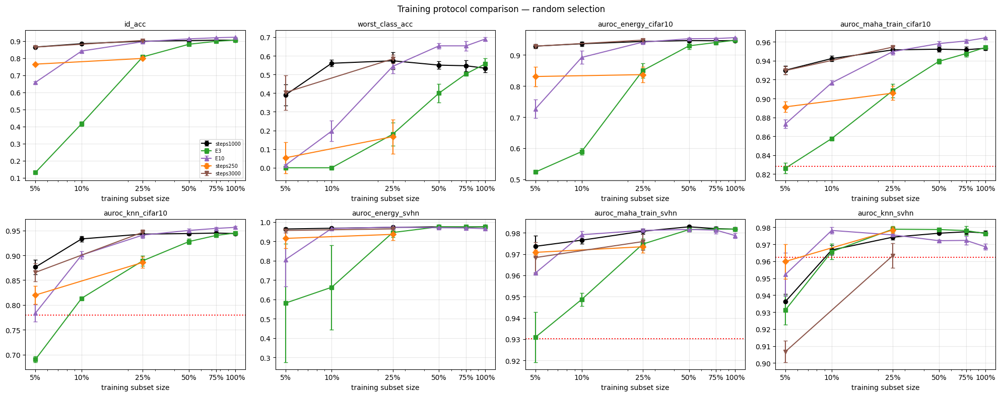

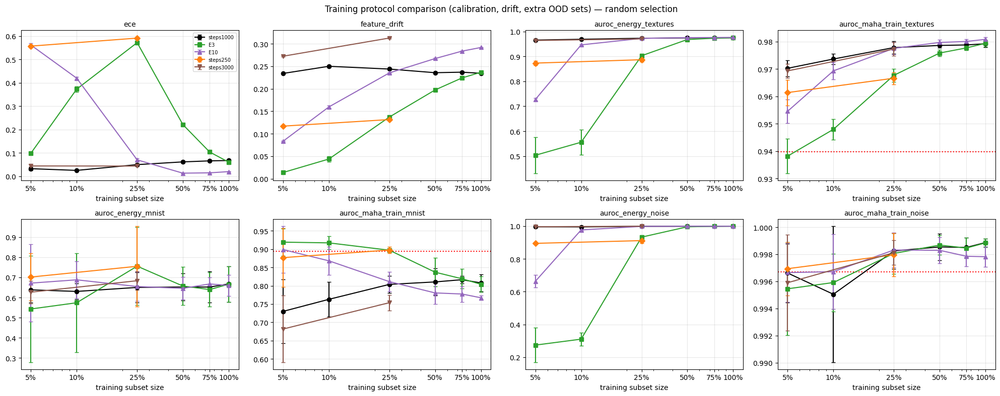

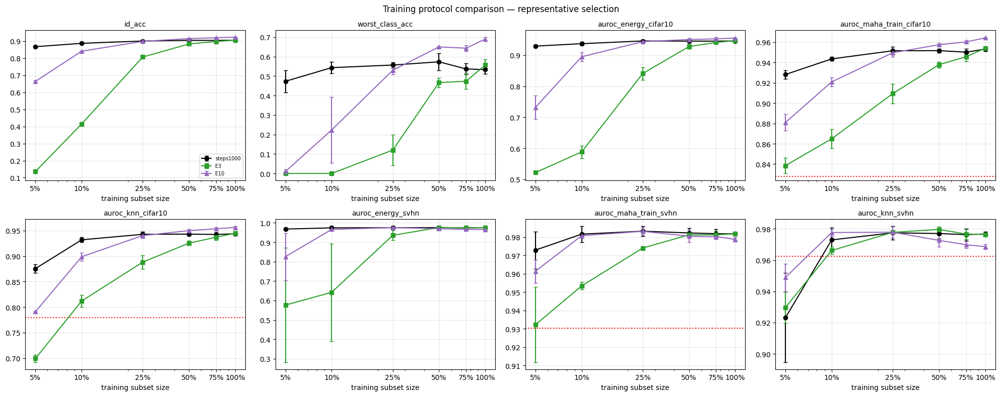

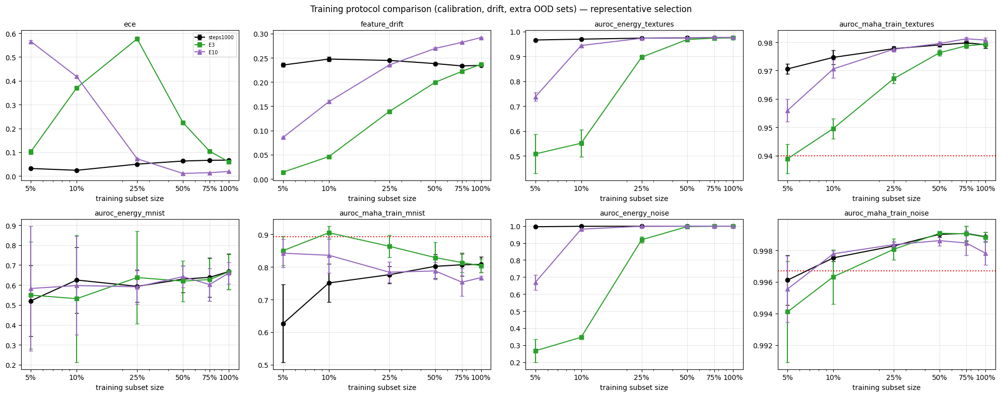

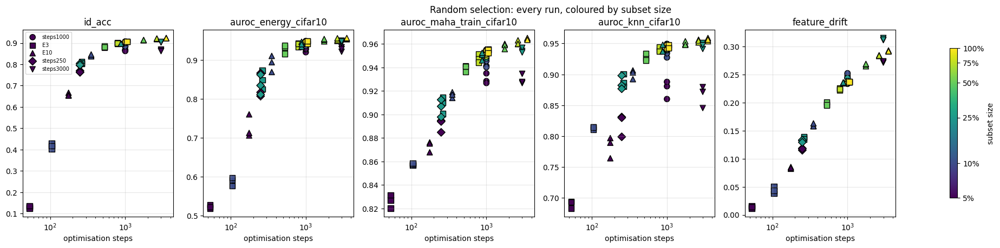

[25.5 protocol figures] finished and marked as done.


In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("25.5 protocol figures", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    P_COL = dict(zip(PROTOS, ["black", "tab:green", "tab:purple", "tab:orange", "tab:brown", "tab:red", "tab:cyan"]))
    P_MK = dict(zip(PROTOS, ["o", "s", "^", "D", "v", "P", "X"]))

    def plot_protocols(strategy, panels, fname, title, ncols=4):
        nrows = int(np.ceil(len(panels) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
        for ax, col in zip(axes.ravel(), panels):
            for p in PROTOS:
                d = res_proto[(res_proto.protocol == p) & (res_proto.strategy == strategy)]
                if not len(d): continue
                d = d.groupby("fraction")[col]
                ax.errorbar(d.mean().index * 100, d.mean().values, yerr=d.std().fillna(0).values, color=P_COL[p], marker=P_MK[p], capsize=3, label=p)
            if col in PRETRAINED_REF: ax.axhline(PRETRAINED_REF[col], color="red", ls=":", label="pretrained (no fine-tuning)")
            ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
            ax.set_title(col, fontsize=10); ax.set_xlabel("training subset size"); ax.grid(alpha=0.3)
        for ax in axes.ravel()[len(panels):]: ax.axis("off")
        axes[0, 0].legend(fontsize=7); fig.suptitle(title); plt.tight_layout(); save_fig3(fname); plt.show()

    main_panels = ["id_acc", "worst_class_acc", "auroc_energy_cifar10", "auroc_maha_train_cifar10", "auroc_knn_cifar10",
                   "auroc_energy_svhn", "auroc_maha_train_svhn", "auroc_knn_svhn"]
    extra_panels = ["ece", "feature_drift"] + [f"auroc_{sc}_{o}" for o in OODS if o not in OODS_CORE for sc in ("energy", "maha_train")]
    for s in STRATEGIES:
        plot_protocols(s, main_panels, f"E1_protocol_comparison_{s}.png", f"Training protocol comparison — {s} selection")
        plot_protocols(s, extra_panels, f"E1_protocol_comparison_extra_{s}.png", f"Training protocol comparison (calibration, drift, extra OOD sets) — {s} selection")

    # the same runs against the number of optimisation steps: separates "more data" from "more training"
    panels_s = ["id_acc", "auroc_energy_cifar10", "auroc_maha_train_cifar10", "auroc_knn_cifar10", "feature_drift"]
    fig, axes = plt.subplots(1, len(panels_s), figsize=(5.2 * len(panels_s), 4.5))
    d0 = res_proto[(res_proto.strategy == "random")]
    for ax, col in zip(axes, panels_s):
        for p in PROTOS:
            d = d0[d0.protocol == p]
            if not len(d): continue
            sc = ax.scatter(d.steps, d[col], c=np.log10(d.fraction * 100), cmap="viridis", vmin=np.log10(5), vmax=2,
                            marker=P_MK[p], s=55, edgecolors="k", label=p)
        ax.set_xscale("log"); ax.set_xlabel("optimisation steps"); ax.set_title(col); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    cb = fig.colorbar(sc, ax=axes, shrink=0.8); cb.set_ticks(np.log10([f * 100 for f in FRACTIONS])); cb.set_ticklabels([f"{f:.0%}" for f in FRACTIONS])
    cb.set_label("subset size"); fig.suptitle("Random selection: every run, coloured by subset size")
    save_fig3("E1_metrics_vs_steps.png"); plt.show()
    finish("25.5 protocol figures")

## 25.6 Effect of more data vs. more training steps

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("25.6 size vs steps regression", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    def ols_size_vs_steps(df, metrics):
        rows = []
        for s in STRATEGIES:
            d = df[(df.strategy == s) & ~df.shared_full_run]
            X = np.column_stack([np.ones(len(d)), np.log10(d.n_train.values.astype(float)), np.log10(d.steps.values.astype(float))])
            for m in metrics:
                y = d[m].values.astype(float); beta = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ beta
                se = np.sqrt(np.diag(e @ e / (len(y) - 3) * np.linalg.inv(X.T @ X)))
                ss_tot = (y - y.mean()) @ (y - y.mean())
                rows.append(dict(strategy=s, metric=m, per10x_more_images=beta[1], se_images=se[1], per10x_more_steps=beta[2],
                                 se_steps=se[2], r2=1 - e @ e / ss_tot if ss_tot > 1e-12 else np.nan, n_runs=len(y)))
        return pd.DataFrame(rows).set_index(["strategy", "metric"])

    _d = res_proto[(res_proto.strategy == "random")]
    print(f"correlation between log10(n_train) and log10(steps) in the design: {np.corrcoef(np.log10(_d.n_train.astype(float)), np.log10(_d.steps.astype(float)))[0,1]:.2f}")
    size_vs_steps = ols_size_vs_steps(res_proto, ["id_acc", "worst_class_acc"] + AUROC_COLS + ["ece", "feature_drift"])
    save_table3(size_vs_steps.round(5), "E1_size_vs_steps_regression.csv")
    display(size_vs_steps.round(4))
    finish("25.6 size vs steps regression")

correlation between log10(n_train) and log10(steps) in the design: 0.50


per10x_more_images  se_images  \
strategy       metric                                                     
random         id_acc                                 0.0727     0.0324   
               worst_class_acc                        0.1631     0.0249   
               auroc_msp_cifar10                      0.0316     0.0183   
               auroc_energy_cifar10                   0.0443     0.0177   
               auroc_maha_train_cifar10               0.0264     0.0036   
               auroc_maha_val_cifar10                 0.0208     0.0030   
               auroc_knn_cifar10                      0.0688     0.0091   
               auroc_msp_svhn                         0.0247     0.0176   
               auroc_energy_svhn                      0.0375     0.0295   
               auroc_maha_train_svhn                  0.0100     0.0025   
               auroc_maha_val_svhn                    0.0066     0.0021   
               auroc_knn_svhn                         0.0347     0.0037   
               auroc_msp_textures                     0.0281     0.0215   
               auroc_energy_textures                  0.0443     0.0231   
               auroc_maha_train_textures              0.0096     0.0015   
               auroc_maha_val_textures                0.0065     0.0012   
               auroc_knn_textures                     0.0288     0.0028   
               auroc_msp_mnist                       -0.0131     0.0293   
               auroc_energy_mnist                     0.0201     0.0339   
               auroc_maha_train_mnist                 0.0466     0.0120   
               auroc_maha_val_mnist                   0.0305     0.0095   
               auroc_knn_mnist                        0.0589     0.0218   
               auroc_msp_noise                        0.0140     0.0224   
               auroc_energy_noise                     0.0554     0.0395   
               auroc_maha_train_noise                 0.0021     0.0005   
               auroc_maha_val_noise                   0.0011     0.0003   
               auroc_knn_noise                        0.0040     0.0006   
               ece                                   -0.0311     0.0468   
               feature_drift                          0.0115     0.0044   
representative id_acc                                 0.0259     0.0461   
               worst_class_acc                        0.0517     0.0374   
               auroc_msp_cifar10                      0.0055     0.0252   
               auroc_energy_cifar10                   0.0139     0.0245   
               auroc_maha_train_cifar10               0.0147     0.0044   
               auroc_maha_val_cifar10                 0.0162     0.0035   
               auroc_knn_cifar10                      0.0490     0.0120   
               auroc_msp_svhn                        -0.0055     0.0270   
               auroc_energy_svhn                      0.0048     0.0494   
               auroc_maha_train_svhn                  0.0048     0.0041   
               auroc_maha_val_svhn                    0.0007     0.0029   
               auroc_knn_svhn                         0.0313     0.0065   
               auroc_msp_textures                     0.0021     0.0310   
               auroc_energy_textures                  0.0141     0.0332   
               auroc_maha_train_textures              0.0069     0.0019   
               auroc_maha_val_textures                0.0049     0.0016   
               auroc_knn_textures                     0.0280     0.0044   
               auroc_msp_mnist                        0.0472     0.0614   
               auroc_energy_mnist                     0.0620     0.0703   
               auroc_maha_train_mnist                 0.1111     0.0225   
               auroc_maha_val_mnist                   0.0651     0.0164   
               auroc_knn_mnist                        0.1956     0.0320   
               auroc_msp_noise                       -0.0035     0.

[25.6 size vs steps regression] finished and marked as done.


## 25.7 Which conclusions of the baseline survive a change of protocol?

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("25.7 conclusions by protocol", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    rep_tests = concat_nonempty([paired_compare(res_proto[(res_proto.protocol == p) & (res_proto.fraction < 1)], "strategy", "representative",
                                                "random", CORE).assign(protocol=p) for p in PROTOS])
    save_table3(rep_tests.round(5), "E1_paired_tests_representative_vs_random_by_protocol.csv", index=False)
    print("Representative minus random, per protocol (* = p < 0.05):")
    display(star_pivot(rep_tests, ["protocol", "metric"]).reindex(PROTOS, level="protocol").reindex(CORE, level="metric"))

    size_tests = concat_nonempty([paired_compare(res_proto[(res_proto.strategy == "random") & res_proto.fraction.isin([FRACTIONS[0], 1.0])],
                                                 "fraction", 1.0, FRACTIONS[0], CORE, by="protocol")])
    save_table3(size_tests.round(5), "E1_paired_tests_size_effect_by_protocol.csv", index=False)
    print(f"\nEffect of dataset size (100% minus {FRACTIONS[0]:.0%}, random selection), per protocol:")
    display(star_pivot(size_tests, "metric", columns="protocol").reindex(CORE))
    finish("25.7 conclusions by protocol")

Representative minus random, per protocol (* = p < 0.05):


5%      10%      25%       50%  \
protocol  metric                                                          
steps1000 id_acc                    +0.0019  +0.0020  +0.0009  +0.0017*   
          worst_class_acc           +0.0833  -0.0167  -0.0167   +0.0233   
          auroc_msp_cifar10         -0.0005  -0.0003  +0.0026   +0.0002   
          auroc_energy_cifar10      +0.0014  +0.0016  +0.0030   -0.0003   
          auroc_maha_train_cifar10  -0.0018  +0.0013  +0.0001   -0.0005   
...                                     ...      ...      ...       ...   
E10       fpr95_maha_val_noise      +0.0000  +0.0000  +0.0000   +0.0000   
          fpr95_knn_noise           +0.0009  +0.0000  +0.0001   +0.0000   
          ece                       +0.0039  -0.0015  +0.0029   -0.0015   
          ece_after_temp_scaling    -0.0019  -0.0002  -0.0000   +0.0007   
          feature_drift             +0.0024  -0.0002  +0.0000   +0.0022   

                                        75%  
protocol  metric                             
steps1000 id_acc                    -0.0014  
          worst_class_acc           -0.0100  
          auroc_msp_cifar10         -0.0010  
          auroc_energy_cifar10      +0.0001  
          auroc_maha_train_cifar10  -0.0015  
...                                     ...  
E10       fpr95_maha_val_noise      +0.0000  
          fpr95_knn_noise           +0.0000  
          ece                       +0.0000  
          ece_after_temp_scaling    +0.0015  
          feature_drift             -0.0016  

[165 rows x 5 columns]


Effect of dataset size (100% minus 5%, random selection), per protocol:


protocol,E10,E3,steps1000
metric,,,
id_acc,+0.2645*,+0.7754*,+0.0400*
worst_class_acc,+0.6767*,+0.5567*,+0.1433*
auroc_msp_cifar10,+0.1239*,+0.4165*,+0.0129*
auroc_energy_cifar10,+0.2288*,+0.4237*,+0.0179*
auroc_maha_train_cifar10,+0.0911*,+0.1278*,+0.0232*
auroc_maha_val_cifar10,+0.0749*,+0.1081*,+0.0194*
auroc_knn_cifar10,+0.1727*,+0.2544*,+0.0675*
auroc_msp_svhn,+0.0409,+0.3282*,+0.0100
auroc_energy_svhn,+0.1597,+0.3940,+0.0114


[25.7 conclusions by protocol] finished and marked as done.


# 26. OOD evaluation: MSP, Energy, Mahalanobis and kNN

## 26.1 MSP vs. Energy on the existing results

Baseline pool — mean over seeds:


auroc_msp_cifar10  auroc_energy_cifar10  \
fraction strategy                                                  
0.05     random                     0.9186                0.9281   
         representative             0.9181                0.9295   
0.10     random                     0.9249                0.9358   
         representative             0.9246                0.9373   
0.25     random                     0.9291                0.9431   
         representative             0.9317                0.9461   
0.50     random                     0.9306                0.9459   
         representative             0.9309                0.9456   
0.75     random                     0.9323                0.9454   
         representative             0.9314                0.9455   
1.00     random                     0.9316                0.9460   
         representative             0.9316                0.9460   

                         fpr95_msp_cifar10  fpr95_energy_cifar10  \
fraction strategy                                                  
0.05     random                     0.3639                0.3080   
         representative             0.3633                0.3196   
0.10     random                     0.3387                0.2827   
         representative             0.3368                0.2867   
0.25     random                     0.3192                0.2566   
         representative             0.3122                0.2473   
0.50     random                     0.3148                0.2519   
         representative             0.3124                0.2477   
0.75     random                     0.3067                0.2490   
         representative             0.3115                0.2480   
1.00     random                     0.3083                0.2488   
         representative             0.3083                0.2488   

                         auroc_msp_svhn  auroc_energy_svhn  fpr95_msp_svhn  \
fraction strategy                                                            
0.05     random                  0.9455             0.9639          0.2413   
         representative          0.9518             0.9679          0.2133   
0.10     random                  0.9482             0.9680          0.2262   
         representative          0.9598             0.9741          0.1745   
0.25     random                  0.9539             0.9724          0.1987   
         representative          0.9557             0.9748          0.1919   
0.50     random                  0.9547             0.9749          0.1998   
         representative          0.9556             0.9753          0.1931   
0.75     random                  0.9540             0.9742          0.2022   
         representative          0.9534             0.9740          0.2007   
1.00     random                  0.9555             0.9753          0.1966   
         representative          0.9555             0.9753          0.1966   

                         fpr95_energy_svhn  
fraction strategy                           
0.05     random                     0.1481  
         representative             0.1325  
0.10     random                     0.1291  
         representative             0.1044  
0.25     random                     0.1077  
         representative             0.0992  
0.50     random                     0.1041  
         representative             0.0974  
0.75     random                     0.1046  
         representative             0.1031  
1.00     random                     0.1014  
         representative             0.1014

cifar10: AUROC energy - msp  svhn: AUROC energy - msp
fraction strategy                                                             
0.05     random                               0.0095                    0.0184
         representative                       0.0114                    0.0161
0.10     random                               0.0109                    0.0198
         representative                       0.0127                    0.0143
0.25     random                               0.0140                    0.0185
         representative                       0.0144                    0.0191
0.50     random                               0.0153                    0.0202
         representative                       0.0147                    0.0197
0.75     random                               0.0131                    0.0202
         representative                       0.0141                    0.0206
1.00     random                               0.0144                    0.0198
         representative                       0.0144                    0.0198


Part C (long-tailed pool) — mean over seeds:


auroc_msp_cifar10  auroc_energy_cifar10  \
fraction balance  selection                                                 
0.05     balanced random                     0.8482                0.8551   
                  representative             0.8466                0.8535   
         natural  random                     0.7228                0.7447   
                  representative             0.7421                0.7596   
0.10     balanced random                     0.8788                0.8891   
                  representative             0.8794                0.8862   
         natural  random                     0.7646                0.7822   
                  representative             0.7653                0.7885   
0.25     balanced random                     0.8867                0.8952   
                  representative             0.8814                0.8918   
         natural  random                     0.7989                0.8182   
                  representative             0.8008                0.8162   
0.50     balanced random                     0.8680                0.8821   
                  representative             0.8678                0.8821   
         natural  random                     0.8244                0.8418   
                  representative             0.8177                0.8353   
0.75     balanced random                     0.8502                0.8675   
                  representative             0.8467                0.8643   
         natural  random                     0.8334                0.8506   
                  representative             0.8307                0.8486   
1.00     balanced random                     0.8352                0.8523   
                  representative             0.8352                0.8523   
         natural  random                     0.8352                0.8523   
                  representative             0.8352                0.8523   

                                  fpr95_msp_cifar10  fpr95_energy_cifar10  \
fraction balance  selection                                                 
0.05     balanced random                     0.5798                0.5213   
                  representative             0.5599                0.5000   
         natural  random                     0.7977                0.7802   
                  representative             0.7501                0.7447   
0.10     balanced random                     0.4537                0.3912   
                  representative             0.4446                0.3948   
         natural  random                     0.7254                0.6958   
                  representative             0.6994                0.6526   
0.25     balanced random                     0.4126                0.3563   
                  representative             0.4108                0.3570   
         natural  random                     0.6373                0.5806   
                  representative             0.6232                0.5648   
0.50     balanced random                     0.4513                0.3888   
                  representative             0.4494                0.3884   
         natural  random                     0.5723                0.5029   
                  representative             0.5753                0.5134   
0.75     balanced random                     0.4954                0.4258   
                  representative             0.5060                0.4341   
         natural  random                     0.5360                0.4736   
                  representative             0.5533                0.4887   
1.00     balanced random                     0.5360                0.4711   
                  representative             0.5360                0.4711   
         natural  random                     0.5360                0.4711   
                  representative             0.5360                0.4711   

                            

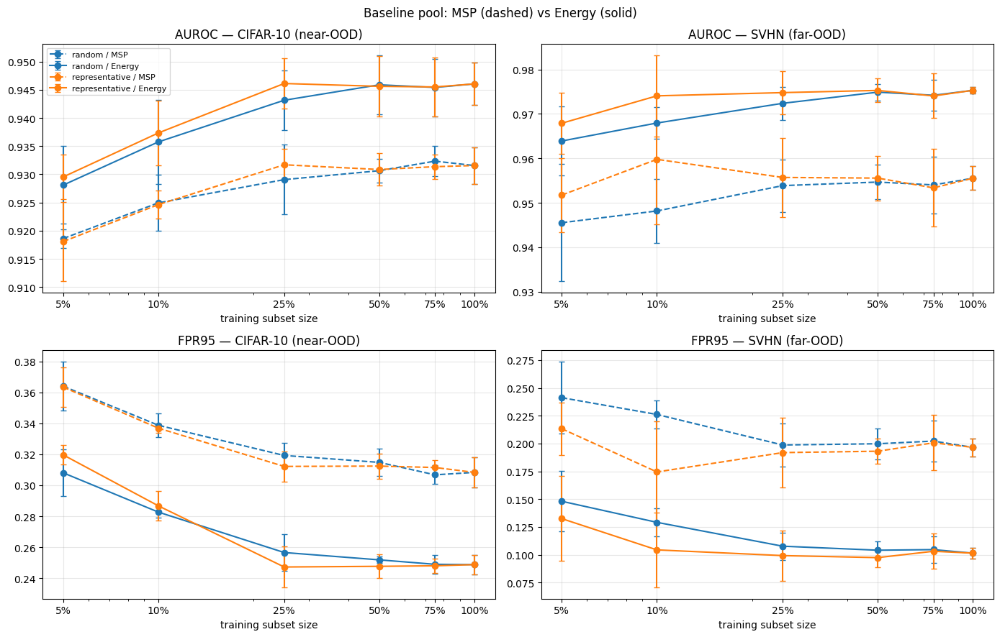

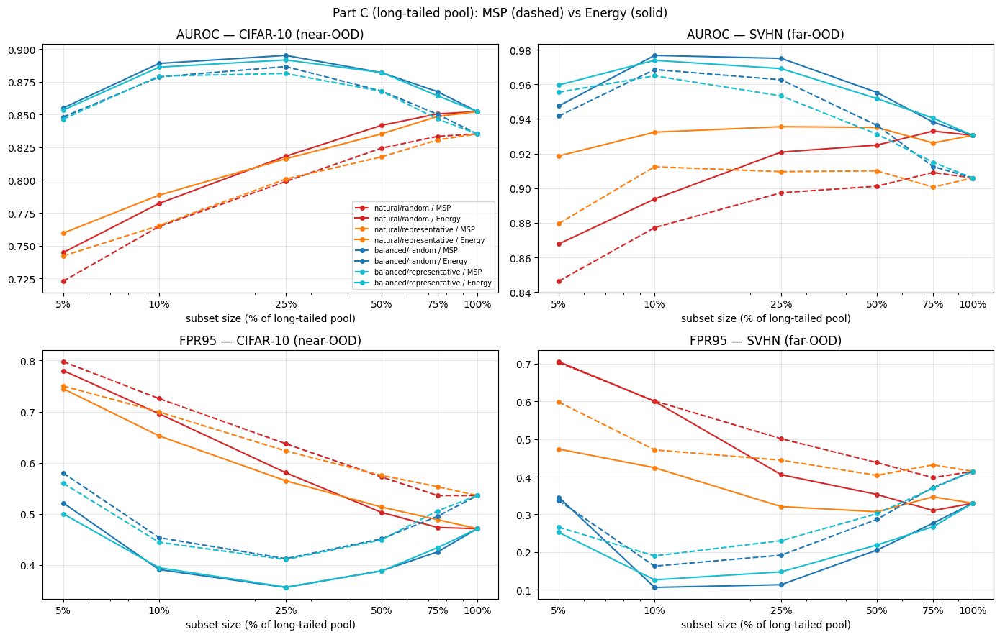

[26.1 MSP vs Energy] finished and marked as done.


In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("26.1 MSP vs Energy", needs=[]):
    sc2 = [f"{m}_{sc}_{o}" for o in OODS_CORE for m in ["auroc", "fpr95"] for sc in ("msp", "energy")]
    tab_sc_base = base_all.groupby(["fraction", "strategy"])[sc2].mean().round(4)
    save_table3(tab_sc_base, "E2_msp_vs_energy_baseline.csv")
    print("Baseline pool — mean over seeds:")
    display(tab_sc_base)
    gap_base = pd.DataFrame({f"{o}: AUROC energy - msp": tab_sc_base[f"auroc_energy_{o}"] - tab_sc_base[f"auroc_msp_{o}"] for o in OODS_CORE}).round(4)
    save_table3(gap_base, "E2_energy_minus_msp_auroc_baseline.csv"); display(gap_base)
    tab_sc_c = res_c.groupby(["fraction", "balance", "selection"])[sc2].mean().round(4)
    save_table3(tab_sc_c, "E2_msp_vs_energy_partC.csv")
    print("\nPart C (long-tailed pool) — mean over seeds:")
    display(tab_sc_c)

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for r_, kind in enumerate(["auroc", "fpr95"]):
        for c_, o in enumerate(OODS_CORE):
            ax = axes[r_, c_]
            for s, colr in zip(STRATEGIES, ["tab:blue", "tab:orange"]):
                for sc, ls in [("msp", "--"), ("energy", "-")]:
                    d = base_all[base_all.strategy == s].groupby("fraction")[f"{kind}_{sc}_{o}"]
                    ax.errorbar(d.mean().index * 100, d.mean().values, yerr=d.std().fillna(0).values, color=colr, ls=ls, marker="o",
                                capsize=3, label=f"{s} / {SCORE_NAME[sc]}")
            ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
            ax.set_title(f"{kind.upper()} — {OOD_NAME[o]}"); ax.set_xlabel("training subset size"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8); fig.suptitle("Baseline pool: MSP (dashed) vs Energy (solid)")
    plt.tight_layout(); save_fig3("E2_msp_vs_energy_baseline.png"); plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    cstyle = {("natural", "random"): "tab:red", ("natural", "representative"): "tab:orange",
              ("balanced", "random"): "tab:blue", ("balanced", "representative"): "tab:cyan"}
    for r_, kind in enumerate(["auroc", "fpr95"]):
        for c_, o in enumerate(OODS_CORE):
            ax = axes[r_, c_]
            for (b, s), colr in cstyle.items():
                for sc, ls in [("msp", "--"), ("energy", "-")]:
                    d = res_c[(res_c.balance == b) & (res_c.selection == s)].groupby("fraction")[f"{kind}_{sc}_{o}"]
                    ax.plot(d.mean().index * 100, d.mean().values, color=colr, ls=ls, marker="o", ms=4, label=f"{b}/{s} / {SCORE_NAME[sc]}")
            ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{f:.0%}" for f in FRACTIONS])
            ax.set_title(f"{kind.upper()} — {OOD_NAME[o]}"); ax.set_xlabel("subset size (% of long-tailed pool)"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7); fig.suptitle("Part C (long-tailed pool): MSP (dashed) vs Energy (solid)")
    plt.tight_layout(); save_fig3("E2_msp_vs_energy_partC.png"); plt.show()
    finish("26.1 MSP vs Energy")

## 26.2 Do the baseline conclusions depend on the OOD score?

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("26.2 score agreement", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    M_BASE = [f"{m}_{sc}_{o}" for m in ("auroc", "fpr95") for sc in SCORES for o in OODS]
    M_C = [f"{m}_{sc}_{o}" for m in ("auroc", "fpr95") for sc in ("msp", "energy") for o in OODS_CORE]
    fams = [fam(base_v2[base_v2.fraction < 1], "Selection: representative - random (baseline pool)", "strategy", "representative", "random", M_BASE)]
    for s in SELECTIONS:
        fams.append(fam(res_c[(res_c.selection == s) & (res_c.fraction < 1)], f"Balance: balanced - natural ({s} selection)", "balance", "balanced", "natural", M_C))
    for b in BALANCES:
        fams.append(fam(res_c[(res_c.balance == b) & (res_c.fraction < 1)], f"Selection: representative - random ({b} long-tailed)", "selection", "representative", "random", M_C))
    fams.append(fam(base_v2[(base_v2.strategy == "random") & base_v2.fraction.isin([FRACTIONS[0], 1.0])].assign(w="100% - 5%"),
                    "Size: 100% - 5% (baseline, random)", "fraction", 1.0, FRACTIONS[0], M_BASE, by="w"))
    fams.append(fam(res_c[(res_c.balance == "natural") & (res_c.selection == "random") & res_c.fraction.isin([FRACTIONS[0], 1.0])].assign(w="100% - 5%"),
                    "Size: 100% - 5% (long-tailed, natural random)", "fraction", 1.0, FRACTIONS[0], M_C, by="w"))
    for p in PROTOS[1:]:
        fams.append(fam(res_proto[(res_proto.strategy == "random") & res_proto.protocol.isin([p, "steps1000"])], f"Protocol: {p} - steps1000 (random)",
                        "protocol", p, "steps1000", M_BASE))
    long26, effects_by_score, w26, agree_summary, flips26 = agreement_tables(fams)
    save_table3(long26.round(5), "E2_effects_by_score_long.csv", index=False)
    save_table3(effects_by_score, "E2_auroc_effects_by_score.csv")
    display(effects_by_score)

    save_table3(agree_summary, "E2_score_agreement_by_family.csv")
    print("Share of comparisons (size levels x OOD sets) in which a score agrees with Energy on the direction of the AUROC effect, "
          "or where only one score finds a significant effect:")
    display(agree_summary)
    print(f"\n{len(flips26)} comparisons change direction between Energy and at least one other score:")
    display(flips26.round(4))
    finish("26.2 score agreement")

score                                                                   msp  \
family                                         level     ood                  
Balance: balanced - natural (random selection) 10%       cifar10   +0.1141*   
                                                         svhn      +0.0913*   
                                               25%       cifar10   +0.0877*   
                                                         svhn      +0.0652*   
                                               5%        cifar10   +0.1254*   
...                                                                     ...   
Size: 100% - 5% (baseline, random)             100% - 5% noise      +0.0029   
                                                         svhn       +0.0100   
                                                         textures  +0.0082*   
Size: 100% - 5% (long-tailed, natural random)  100% - 5% cifar10   +0.1124*   
                                                         svhn       +0.0596   

score                                                                energy  \
family                                         level     ood                  
Balance: balanced - natural (random selection) 10%       cifar10   +0.1069*   
                                                         svhn       +0.0829   
                                               25%       cifar10   +0.0770*   
                                                         svhn      +0.0541*   
                                               5%        cifar10   +0.1104*   
...                                                                     ...   
Size: 100% - 5% (baseline, random)             100% - 5% noise      +0.0037   
                                                         svhn       +0.0114   
                                                         textures  +0.0091*   
Size: 100% - 5% (long-tailed, natural random)  100% - 5% cifar10   +0.1076*   
                                                         svhn      +0.0627*   

score                                                             maha_train  \
family                                         level     ood                   
Balance: balanced - natural (random selection) 10%       cifar10         NaN   
                                                         svhn            NaN   
                                               25%       cifar10         NaN   
                                                         svhn            NaN   
                                               5%        cifar10         NaN   
...                                                                      ...   
Size: 100% - 5% (baseline, random)             100% - 5% noise       +0.0022   
                                                         svhn        +0.0080   
                                                         textures   +0.0090*   
Size: 100% - 5% (long-tailed, natural random)  100% - 5% cifar10         NaN   
                                                         svhn            NaN   

score                                                              maha_val  \
family                                         level     ood                  
Balance: balanced - natural (random selection) 10%       cifar10        NaN   
                                                         svhn           NaN   
                                               25%       cifar10        NaN   
                                                         svhn           NaN   
                                               5%        cifar10        NaN   
...                                                                     ...   
Size: 100% - 5% (baseline, random)             100% - 5% noise      +0.0014   
                                                         svhn       +0.0045   
                                                         textures  +0.0057*   
Size: 100% - 5% (long-tailed, natu

Share of comparisons (size levels x OOD sets) in which a score agrees with Energy on the direction of the AUROC effect, or where only one score finds a significant effect:


,sign(msp)==sign(energy),significant only under msp,sign(maha_train)==sign(energy),significant only under maha_train,sign(maha_val)==sign(energy),significant only under maha_val,sign(knn)==sign(energy),significant only under knn,significant only under energy
family,,,,,,,,,
Balance: balanced - natural (random selection),1.00,0.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00
Balance: balanced - natural (representative selection),1.00,0.30,NaN,NaN,NaN,NaN,NaN,NaN,0.00
Protocol: E10 - steps1000 (random),0.77,0.07,0.80,0.33,0.83,0.23,0.77,0.20,0.07
Protocol: E3 - steps1000 (random),0.90,0.10,0.70,0.27,0.73,0.27,0.77,0.17,0.07
Protocol: steps250 - steps1000 (random),0.90,0.00,0.90,0.30,0.90,0.30,0.50,0.30,0.10
Protocol: steps3000 - steps1000 (random),0.80,0.40,0.70,0.10,0.50,0.00,0.70,0.30,0.20
Selection: representative - random (balanced long-tailed),0.80,0.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00
Selection: representative - random (baseline pool),0.76,0.00,0.76,0.00,0.60,0.04,0.64,0.00,0.00
Selection: representative - random (natural long-tailed),0.90,0.10,NaN,NaN,NaN,NaN,NaN,NaN,0.10



55 comparisons change direction between Energy and at least one other score:


score                                                                     msp  \
family                                             level     ood                
Protocol: E10 - steps1000 (random)                 10%       noise     0.0008   
                                                             svhn      0.0119   
                                                   100%      mnist     0.0100   
                                                             textures -0.0029   
                                                   25%       noise    -0.0001   
                                                             textures  0.0002   
                                                   5%        noise    -0.0221   
                                                             svhn     -0.0512   
                                                   50%       noise     0.0001   
                                                             textures -0.0015   
                                                   75%       mnist     0.0248   
                                                             textures -0.0027   
Protocol: E3 - steps1000 (random)                  10%       mnist     0.1019   
                                                             noise    -0.1802   
                                                   100%      noise     0.0000   
                                                             svhn     -0.0008   
                                                             textures -0.0002   
                                                   25%       noise    -0.0046   
                                                             svhn      0.0039   
                                                   5%        mnist    -0.0460   
                                                             noise    -0.3275   
                                                   50%       noise    -0.0006   
                                                             svhn      0.0066   
                                                   75%       mnist    -0.0108   
                                                             noise    -0.0000   
                                                             svhn      0.0032   
Protocol: steps250 - steps1000 (random)            25%       noise    -0.0057   
                                                             svhn      0.0012   
                                                   5%        noise    -0.0072   
                                                             svhn     -0.0098   
                                                             textures -0.0280   
Protocol: steps3000 - steps1000 (random)           25%       mnist     0.0542   
                                                             noise    -0.0006   
                                                             textures -0.0055   
                                                   5%        cifar10  -0.0032   
                                                             noise    -0.0016   
                                                             textures -0.0052   
Selection: representative - random (balanced lo... 10%       cifar10   0.0006   
                                                   50%       cifar10  -0.0003   
Selection: representative - random (baseline pool) 10%       cifar10  -0.0003   
                                                             mnist    -0.0003   
                                                             textures  0.0010   
                                                   25%       cifar10   0.0026   
                                                             noise     0.0003   
                                                             textures  0.0000   
                                                   5%        cifar10  -0.0005   
                                                             noise    -0.0005   
                               

[26.2 score agreement] finished and marked as done.


## 26.3 Is the absence of an ID/OOD trade-off general?

rho < 0 would indicate a trade-off (higher ID accuracy / more drift <-> lower AUROC). 'within' removes the data-size effect.


,experiment,score,ood,n_runs,rho_acc_pooled,p_acc_pooled,rho_acc_within,p_acc_within,rho_drift_pooled,rho_drift_within
0,"baseline (1,000 steps)",msp,cifar10,33,0.652,0.000,-0.096,0.597,0.028,0.134
1,"baseline (1,000 steps)",msp,svhn,33,0.113,0.531,-0.076,0.676,-0.025,-0.276
2,"baseline (1,000 steps)",msp,textures,33,0.783,0.000,-0.179,0.318,-0.145,-0.031
3,"baseline (1,000 steps)",msp,mnist,33,-0.004,0.984,-0.165,0.358,-0.169,-0.178
4,"baseline (1,000 steps)",msp,noise,33,0.485,0.004,-0.119,0.508,-0.180,0.066
5,"baseline (1,000 steps)",energy,cifar10,33,0.675,0.000,-0.096,0.594,0.114,0.504
6,"baseline (1,000 steps)",energy,svhn,33,0.375,0.031,-0.150,0.406,0.002,-0.340
7,"baseline (1,000 steps)",energy,textures,33,0.893,0.000,0.154,0.392,-0.234,-0.274
8,"baseline (1,000 steps)",energy,mnist,33,0.094,0.602,-0.234,0.191,-0.159,-0.130
9,"baseline (1,000 steps)",energy,noise,33,0.631,0.000,-0.092,0.610,-0.158,0.058


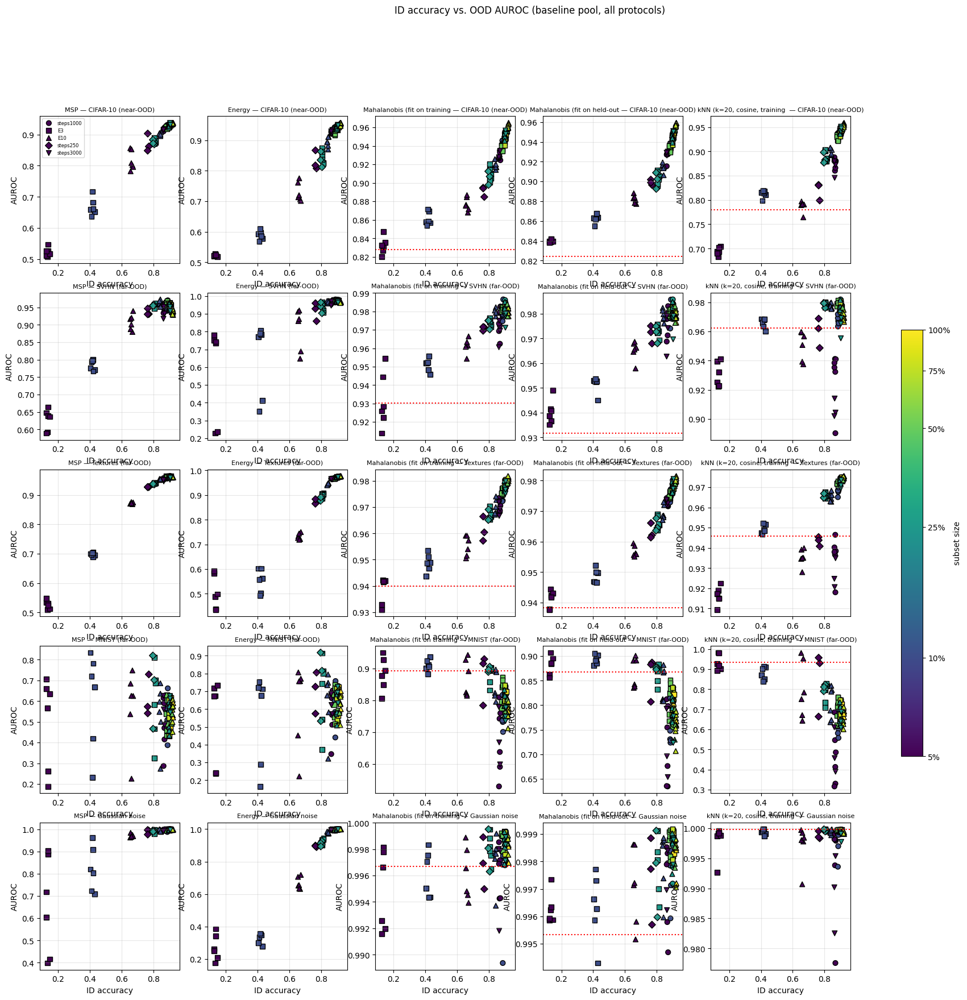

Number of (strategy, size) cells showing each pattern when the same subset is trained longer:


,score,ood,n_cells,ID up / AUROC down (trade-off pattern),ID up / AUROC up,ID down / AUROC up,ID down / AUROC down,median AUROC slope per 10x steps
0,msp,cifar10,11,0,11,0,0,0.0589
1,msp,svhn,11,6,5,0,0,-0.0119
2,msp,textures,11,5,6,0,0,0.0204
3,msp,mnist,11,8,3,0,0,-0.0278
4,msp,noise,11,3,8,0,0,0.0051
5,energy,cifar10,11,0,11,0,0,0.1113
6,energy,svhn,11,5,6,0,0,0.0280
7,energy,textures,11,0,11,0,0,0.0824
8,energy,mnist,11,6,5,0,0,-0.0129
9,energy,noise,11,1,10,0,0,0.0831


AUROC of the fine-tuned model minus AUROC of the pretrained features (negative = fine-tuning lost OOD information):


,protocol,strategy,fraction,id_acc,maha_train_cifar10,maha_train_svhn,maha_train_textures,maha_train_mnist,maha_train_noise,maha_val_cifar10,maha_val_svhn,maha_val_textures,maha_val_mnist,maha_val_noise,knn_cifar10,knn_svhn,knn_textures,knn_mnist,knn_noise
0,steps1000,random,0.05,0.8653,0.1020,0.0433,0.0304,-0.1634,-0.0001,0.1040,0.0441,0.0345,-0.1198,0.0020,0.0965,-0.0262,-0.0047,-0.3845,-0.0031
1,steps1000,random,0.10,0.8849,0.1143,0.0462,0.0337,-0.1305,-0.0017,0.1135,0.0460,0.0372,-0.1111,0.0021,0.1533,0.0042,0.0224,-0.2842,-0.0033
2,steps1000,random,0.25,0.8996,0.1235,0.0504,0.0379,-0.0898,0.0015,0.1220,0.0479,0.0393,-0.0808,0.0030,0.1629,0.0118,0.0272,-0.2479,-0.0003
3,steps1000,random,0.50,0.9028,0.1242,0.0525,0.0387,-0.0831,0.0018,0.1221,0.0493,0.0397,-0.0733,0.0032,0.1640,0.0141,0.0278,-0.2446,-0.0002
4,steps1000,random,0.75,0.9056,0.1237,0.0516,0.0389,-0.0770,0.0018,0.1240,0.0492,0.0402,-0.0618,0.0032,0.1651,0.0149,0.0286,-0.2291,-0.0002
5,steps1000,random,1.00,0.9053,0.1252,0.0514,0.0393,-0.0857,0.0022,0.1234,0.0486,0.0402,-0.0678,0.0034,0.1640,0.0142,0.0287,-0.2401,-0.0001
6,steps1000,representative,0.05,0.8672,0.1002,0.0425,0.0307,-0.2667,-0.0006,0.0994,0.0457,0.0341,-0.1781,0.0017,0.0957,-0.0393,-0.0143,-0.5553,-0.0083
7,steps1000,representative,0.10,0.8870,0.1156,0.0512,0.0348,-0.1425,0.0008,0.1106,0.0502,0.0366,-0.1041,0.0025,0.1521,0.0105,0.0221,-0.3217,-0.0008
8,steps1000,representative,0.25,0.9004,0.1236,0.0528,0.0379,-0.1172,0.0016,0.1205,0.0507,0.0391,-0.0902,0.0030,0.1629,0.0150,0.0273,-0.2771,-0.0004
9,steps1000,representative,0.50,0.9045,0.1237,0.0519,0.0392,-0.0916,0.0023,0.1228,0.0497,0.0401,-0.0748,0.0034,0.1634,0.0145,0.0285,-0.2478,-0.0001


ID accuracy vs. AUROC, Spearman rho (pooled | within size cell), all protocols:
  MSP                                      cifar10   pooled +0.94 | within +0.97 (p=0.000)
  MSP                                      svhn      pooled +0.24 | within +0.61 (p=0.000)
  MSP                                      textures  pooled +0.76 | within +0.85 (p=0.000)
  MSP                                      mnist     pooled -0.20 | within -0.16 (p=0.102)
  MSP                                      noise     pooled +0.70 | within +0.77 (p=0.000)
  Energy                                   cifar10   pooled +0.95 | within +0.94 (p=0.000)
  Energy                                   svhn      pooled +0.61 | within +0.77 (p=0.000)
  Energy                                   textures  pooled +0.97 | within +0.95 (p=0.000)
  Energy                                   mnist     pooled -0.11 | within -0.06 (p=0.542)
  Energy                                   noise     pooled +0.89 | within +0.93 (p=0.000)
  Mahalano

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("26.3 tradeoff", needs=['25.2a', '25.2b']):
    res_proto, PROTOS = get_res_proto()
    P_MK = dict(zip(PROTOS, ["o", "s", "^", "D", "v", "P", "X"]))
    to_ = [tradeoff_summary(base_v2[~base_v2.shared_full_run], ["strategy", "fraction"], SCORES, "baseline (1,000 steps)"),
           tradeoff_summary(res_c[~res_c.shared_full_run], ["balance", "selection", "fraction"], ["msp", "energy"], "Part C long-tailed (1,000 steps)", OODS_CORE),
           tradeoff_summary(res_proto[~res_proto.shared_full_run], ["strategy", "fraction"], SCORES, "all protocols (1,000 steps, fixed epochs, step sweep)")]
    tradeoff = pd.concat(to_, ignore_index=True)
    save_table3(tradeoff.round(4), "E2_tradeoff_correlations.csv", index=False)
    print("rho < 0 would indicate a trade-off (higher ID accuracy / more drift <-> lower AUROC). 'within' removes the data-size effect.")
    display(tradeoff.round(3))

    # ID accuracy vs. AUROC for every score and OOD set (all protocols)
    d0 = res_proto[~res_proto.shared_full_run]
    fig, axes = plt.subplots(len(OODS), len(SCORES), figsize=(4.6 * len(SCORES), 3.9 * len(OODS)), squeeze=False)
    for r_, o in enumerate(OODS):
        for c_, sc in enumerate(SCORES):
            ax = axes[r_, c_]; col = f"auroc_{sc}_{o}"
            for p in PROTOS:
                d = d0[d0.protocol == p]
                if not len(d): continue
                sct = ax.scatter(d.id_acc, d[col], c=np.log10(d.fraction * 100), cmap="viridis", vmin=np.log10(5), vmax=2,
                                 marker=P_MK[p], s=40, edgecolors="k", label=p)
            if col in PRETRAINED_REF: ax.axhline(PRETRAINED_REF[col], color="red", ls=":", label="pretrained")
            ax.set_xlabel("ID accuracy"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3)
            ax.set_title(f"{SCORE_NAME[sc][:28]} — {OOD_NAME[o][:22]}", fontsize=8)
    axes[0, 0].legend(fontsize=6)
    cb = fig.colorbar(sct, ax=axes, shrink=0.5); cb.set_ticks(np.log10([f * 100 for f in FRACTIONS])); cb.set_ticklabels([f"{f:.0%}" for f in FRACTIONS])
    cb.set_label("subset size"); fig.suptitle("ID accuracy vs. OOD AUROC (baseline pool, all protocols)")
    save_fig3("E2_tradeoff_all_scores.png"); plt.show()

    # training-intensity slopes: inside each (strategy, size) cell, change per 10x more optimisation steps
    def intensity_slopes(df, metrics):
        rows = []
        for (s, f), d in df[~df.shared_full_run].groupby(["strategy", "fraction"]):
            m = d.groupby("protocol")[["steps"] + metrics].mean()
            if len(m) < 2 or m.steps.nunique() < 2: continue
            x = np.log10(m.steps.values)
            for c in metrics: rows.append(dict(strategy=s, fraction=f, metric=c, slope_per10x_steps=np.polyfit(x, m[c].values, 1)[0], n_protocols=len(m)))
        return pd.DataFrame(rows)

    slopes = intensity_slopes(res_proto, ["id_acc", "feature_drift"] + AUROC_COLS)
    save_table3(slopes.round(5), "E2_training_intensity_slopes.csv", index=False)
    sl = slopes.pivot_table(index=["strategy", "fraction"], columns="metric", values="slope_per10x_steps")
    rows = []
    for sc in SCORES:
        for o in OODS:
            y = f"auroc_{sc}_{o}"
            a, b = sl["id_acc"], sl[y]
            rows.append(dict(score=sc, ood=o, n_cells=len(sl),
                             **{"ID up / AUROC down  (trade-off pattern)": int(((a > 0) & (b < 0)).sum()),
                                "ID up / AUROC up": int(((a > 0) & (b > 0)).sum()),
                                "ID down / AUROC up": int(((a < 0) & (b > 0)).sum()),
                                "ID down / AUROC down": int(((a < 0) & (b < 0)).sum()),
                                "median AUROC slope per 10x steps": float(b.median())}))
    intensity = pd.DataFrame(rows)
    save_table3(intensity.round(4), "E2_training_intensity_pattern_counts.csv", index=False)
    print("Number of (strategy, size) cells showing each pattern when the same subset is trained longer:")
    display(intensity.round(4))

    # how far does fine-tuning move the feature-based AUROC away from the pretrained features?
    rows = []
    for p in PROTOS:
        for (s, f), d in res_proto[(res_proto.protocol == p) & ~res_proto.shared_full_run].groupby(["strategy", "fraction"]):
            rows.append(dict(protocol=p, strategy=s, fraction=f, id_acc=d.id_acc.mean(),
                             **{f"{k}_{o}": d[f"auroc_{k}_{o}"].mean() - PRETRAINED_REF[f"auroc_{k}_{o}"]
                                for k in ("maha_train", "maha_val", "knn") for o in OODS}))
    vs_pre = pd.DataFrame(rows)
    save_table3(vs_pre.round(4), "E2_feature_detector_auroc_minus_pretrained.csv", index=False)
    print("AUROC of the fine-tuned model minus AUROC of the pretrained features (negative = fine-tuning lost OOD information):")
    display(vs_pre.round(4))

    # short summary
    t = tradeoff[tradeoff.experiment.str.startswith("all protocols")]
    print("ID accuracy vs. AUROC, Spearman rho (pooled | within size cell), all protocols:")
    for _, r in t.iterrows():
        print(f"  {SCORE_NAME[r.score][:40]:<40} {r.ood:<9} pooled {r.rho_acc_pooled:+.2f} | within {r.rho_acc_within:+.2f} (p={r.p_acc_within:.3f})")
    print("\nTraining the same subset longer (cells with the 'ID up / AUROC down' pattern):")
    for _, r in intensity.iterrows():
        print(f"  {SCORE_NAME[r.score][:40]:<40} {r.ood:<9} {int(r['ID up / AUROC down  (trade-off pattern)'])} of {int(r.n_cells)} cells")
    finish("26.3 tradeoff")

# 27. Class imbalance: selecting balanced data vs. balancing the training process

## 27.1 What the subsets contain

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.1 control subsets content", needs=[]):
    assert all(f in FRACTIONS for f in CTRL_FRACS), "CTRL_FRACS must be a subset of FRACTIONS"
    rows = []
    for sel in CTRL_SELECTIONS:
        for f in CTRL_FRACS:
            for bal in CTRL_BALANCES:
                if f >= 1 and (bal != "natural" or sel != "random"): continue
                for sd in CTRL_SEEDS:
                    idx = lt_pool if f >= 1 else SUBSETS_C[(bal, sel, f, sd)]; cnt = np.bincount(labels_pool[idx], minlength=NUM_CLASSES)
                    rows.append(dict(selection=sel, fraction=f, balance=bal, seed=sd, n_train=len(idx), classes_present=int((cnt > 0).sum()),
                                     min_per_class=int(cnt.min()), max_per_class=int(cnt.max()), imbalance_ratio=cnt.max() / max(cnt[cnt > 0].min(), 1),
                                     **{f"images_{g}_shot_classes": int(cnt[cls].sum()) for g, cls in GROUPS.items()}))
    ctrl_content = pd.DataFrame(rows).groupby(["selection", "fraction", "balance"]).mean().drop(columns="seed").round(1)
    save_table3(ctrl_content, "E3_control_subsets_content.csv")
    print("What the subsets contain (mean over seeds). 'images_few_shot_classes' = number of training images of the rarest classes:")
    display(ctrl_content)
    finish("27.1 control subsets content")

What the subsets contain (mean over seeds). 'images_few_shot_classes' = number of training images of the rarest classes:


n_train  classes_present  min_per_class  \
selection      fraction balance                                             
random         0.05     balanced    488.0            100.0            4.0   
                        natural     488.0             72.3            0.0   
               0.10     balanced    975.0            100.0            4.0   
                        natural     975.0             87.0            0.0   
               0.25     balanced   2438.0            100.0            4.0   
                        natural    2438.0             96.3            0.0   
               0.50     balanced   4877.0            100.0            4.0   
                        natural    4877.0            100.0            1.3   
               0.75     balanced   7316.0            100.0            4.0   
                        natural    7316.0            100.0            2.0   
               1.00     natural    9754.0            100.0            4.0   
representative 0.05     balanced    488.0            100.0            4.0   
                        natural     488.0             80.3            0.0   
               0.10     balanced    975.0            100.0            4.0   
                        natural     975.0             89.0            0.0   
               0.25     balanced   2438.0            100.0            4.0   
                        natural    2438.0             97.7            0.0   
               0.50     balanced   4877.0            100.0            4.0   
                        natural    4877.0            100.0            1.0   
               0.75     balanced   7316.0            100.0            4.0   
                        natural    7316.0            100.0            2.3   

                                  max_per_class  imbalance_ratio  \
selection      fraction balance                                    
random         0.05     balanced            5.0              1.2   
                        natural            28.7             28.7   
               0.10     balanced           11.0              2.8   
                        natural            48.0             48.0   
               0.25     balanced           33.0              8.2   
                        natural           107.7            107.7   
               0.50     balanced           88.0             22.0   
                        natural           228.7            190.0   
               0.75     balanced          178.0             44.5   
                        natural           330.7            200.3   
               1.00     natural           450.0            112.5   
representative 0.05     balanced            5.0              1.2   
                        natural            24.0             24.0   
               0.10     balanced           11.0              2.8   
                        natural            45.0             45.0   
               0.25     balanced           33.0              8.2   
                        natural           115.3            115.3   
               0.50     balanced           88.0             22.0   
                        natural           224.7            224.7   
               0.75     balanced          178.0             44.5   
                        natural           332.3            147.2   

                                  images_many_shot_classes  \
selection      fraction balance                              
random         0.05     balanced                     161.0   
                        natural                      397.0   
               0.10     balanced                     346.7   
                        natural                      783.7   
               0.25     balanced                    1073.7   
                        natural                     1923.3   
               0.50     balanced                    2887.7   
                        natural                     3860.7   
               0.75     balanced                    5313.0   
               

[27.1 control subsets content] finished and marked as done.


## 27.2 Run the controls

### 27.2a Random selection, 1,000 steps

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("27.2a")

[27.2a controls: random selection, 1,000 steps] 99 runs | total training time 15.7 h
[1/99] ctrl_steps1000_random_natural-plain_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.4228  2.5 min
    step   500/1000  loss 0.0159  4.9 min
    step   750/1000  loss 0.0072  7.4 min
    step  1000/1000  loss 0.0059  9.8 min
    ID acc 0.4490 | AUROC CIFAR-10: energy 0.7348 maha 0.7700 knn 0.6615 | SVHN: energy 0.8299 maha 0.8636 | ECE 0.0601
[2/99] ctrl_steps1000_random_natural-wloss_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.5757  2.5 min
    step   500/1000  loss 0.0163  4.9 min
    step   750/1000  loss 0.0073  7.4 min
    step  1000/1000  loss 0.0059  9.8 min
    ID acc 0.4623 | AUROC CIFAR-10: energy 0.7544 maha 0.7711 knn 0.6674 | SVHN: energy 0.7982 maha 0.8512 | ECE 0.0498
[3/99] ctrl_steps1000_random_natural-balsamp_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.4617  2.5 min
    step  

### 27.2b Representative selection, 1,000 steps

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("27.2b")

[27.2b controls: representative selection, 1,000 steps] 90 runs | total training time 14.6 h
[1/90] ctrl_steps1000_representative_natural-plain_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.4594  2.4 min
    step   500/1000  loss 0.0170  4.8 min
    step   750/1000  loss 0.0077  7.2 min
    step  1000/1000  loss 0.0063  9.6 min
    ID acc 0.5294 | AUROC CIFAR-10: energy 0.7665 maha 0.7843 knn 0.6542 | SVHN: energy 0.8884 maha 0.9295 | ECE 0.0408
[2/90] ctrl_steps1000_representative_natural-wloss_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.6293  2.4 min
    step   500/1000  loss 0.0172  4.8 min
    step   750/1000  loss 0.0076  7.2 min
    step  1000/1000  loss 0.0062  9.6 min
    ID acc 0.5410 | AUROC CIFAR-10: energy 0.7784 maha 0.7790 knn 0.6835 | SVHN: energy 0.8560 maha 0.8990 | ECE 0.0617
[3/90] ctrl_steps1000_representative_natural-balsamp_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000 

### 27.2c Additional balancing methods

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("27.2c")

[27.2c controls: additional balancing methods (natural subsets)] 36 runs | total training time 5.7 h
[1/36] ctrl_steps1000_random_natural-wsqrt_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.5347  2.4 min
    step   500/1000  loss 0.0174  4.7 min
    step   750/1000  loss 0.0078  7.1 min
    step  1000/1000  loss 0.0063  9.5 min
    ID acc 0.4525 | AUROC CIFAR-10: energy 0.7394 maha 0.7668 knn 0.6586 | SVHN: energy 0.8144 maha 0.8619 | ECE 0.0463
[2/36] ctrl_steps1000_random_natural-cbeff_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.5782  2.4 min
    step   500/1000  loss 0.0163  4.7 min
    step   750/1000  loss 0.0072  7.1 min
    step  1000/1000  loss 0.0059  9.5 min
    ID acc 0.4615 | AUROC CIFAR-10: energy 0.7541 maha 0.7709 knn 0.6668 | SVHN: energy 0.7981 maha 0.8504 | ECE 0.0478
[3/36] ctrl_steps1000_random_natural-logitadj_0.05_seed0  (488 images, 1000 steps = 262.3 epochs)
    step   250/1000  loss 1.2566  2

### 27.2d Fixed-epoch protocols

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("27.2d")

[27.2d controls under fixed-epoch protocols] 198 runs | total training time 6.2 h
[1/198] ctrl_E3_random_natural-plain_0.05_seed0  (488 images, 11 steps = 2.9 epochs)
    step    11/11  loss 4.4646  0.1 min
    ID acc 0.0259 | AUROC CIFAR-10: energy 0.5182 maha 0.7041 knn 0.5595 | SVHN: energy 0.1705 maha 0.8419 | ECE 0.0058
[2/198] ctrl_E3_random_natural-wloss_0.05_seed0  (488 images, 11 steps = 2.9 epochs)
    step    11/11  loss 4.5365  0.1 min
    ID acc 0.0260 | AUROC CIFAR-10: energy 0.5171 maha 0.7034 knn 0.5529 | SVHN: energy 0.1860 maha 0.8366 | ECE 0.0055
[3/198] ctrl_E3_random_natural-balsamp_0.05_seed0  (488 images, 11 steps = 2.9 epochs)
    step    11/11  loss 4.4680  0.1 min
    ID acc 0.0285 | AUROC CIFAR-10: energy 0.5154 maha 0.7028 knn 0.5563 | SVHN: energy 0.1864 maha 0.8271 | ECE 0.0031
[4/198] ctrl_E3_random_balanced-plain_0.05_seed0  (488 images, 11 steps = 2.9 epochs)
    step    11/11  loss 4.5921  0.1 min
    ID acc 0.0316 | AUROC CIFAR-10: energy 0.5052 maha 

## 27.3 Collected results and check against Part C

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.3 controls collect", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    save_table3(res_ctrl, "E3_controls_all_runs.csv", index=False)
    print(f"{len(res_ctrl)} control runs | protocols {CPROTOS} | selections {CSELS} | seeds finished per setting:")
    display(res_ctrl.groupby(["protocol", "selection", "arm", "fraction"]).seed.nunique().unstack("fraction"))
    ref = res_ctrl[(res_ctrl.process == "plain") & (res_ctrl.protocol == "steps1000")].merge(
        res_c, on=["balance", "selection", "fraction", "seed"], suffixes=("_ctrl", "_partC"))
    if len(ref):
        chk_c = pd.DataFrame({m: (ref[m + "_ctrl"] - ref[m + "_partC"]).abs().groupby([ref.selection, ref.balance, ref.fraction]).mean()
                              for m in ["id_acc", "acc_few", "worst_class_acc", "auroc_energy_cifar10", "auroc_energy_svhn", "ece"]})
        save_table3(chk_c.round(5), "E3_reference_arms_vs_partC.csv")
        print("\nMean |re-run - Part C| for the plain-CE reference arms (small = the new pipeline is equivalent; differences = GPU non-determinism):")
        display(chk_c.round(4))
    finish("27.3 controls collect")

423 control runs | protocols ['steps1000', 'E3', 'E10'] | selections ['random', 'representative'] | seeds finished per setting:


fraction                                   0.05  0.10  0.25  0.50  0.75  1.00
protocol  selection      arm                                                 
E10       random         balanced/balsamp   3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/plain     3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/wloss     3.0   3.0   3.0   3.0   3.0   NaN
                         natural/balsamp    3.0   3.0   3.0   3.0   3.0   3.0
                         natural/plain      3.0   3.0   3.0   3.0   3.0   3.0
                         natural/wloss      3.0   3.0   3.0   3.0   3.0   3.0
E3        random         balanced/balsamp   3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/plain     3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/wloss     3.0   3.0   3.0   3.0   3.0   NaN
                         natural/balsamp    3.0   3.0   3.0   3.0   3.0   3.0
                         natural/plain      3.0   3.0   3.0   3.0   3.0   3.0
                         natural/wloss      3.0   3.0   3.0   3.0   3.0   3.0
steps1000 random         balanced/balsamp   3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/plain     3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/wloss     3.0   3.0   3.0   3.0   3.0   NaN
                         natural/balsamp    3.0   3.0   3.0   3.0   3.0   3.0
                         natural/cbeff      3.0   NaN   3.0   NaN   NaN   3.0
                         natural/logitadj   3.0   NaN   3.0   NaN   NaN   3.0
                         natural/plain      3.0   3.0   3.0   3.0   3.0   3.0
                         natural/sqrtsamp   3.0   NaN   3.0   NaN   NaN   3.0
                         natural/wloss      3.0   3.0   3.0   3.0   3.0   3.0
                         natural/wsqrt      3.0   NaN   3.0   NaN   NaN   3.0
          representative balanced/balsamp   3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/plain     3.0   3.0   3.0   3.0   3.0   NaN
                         balanced/wloss     3.0   3.0   3.0   3.0   3.0   NaN
                         natural/balsamp    3.0   3.0   3.0   3.0   3.0   NaN
                         natural/plain      3.0   3.0   3.0   3.0   3.0   NaN
                         natural/wloss      3.0   3.0   3.0   3.0   3.0   NaN


Mean |re-run - Part C| for the plain-CE reference arms (small = the new pipeline is equivalent; differences = GPU non-determinism):


id_acc  acc_few  worst_class_acc  \
selection      balance  fraction                                     
random         balanced 0.05      0.0001   0.0013           0.0033   
                        0.10      0.0000   0.0000           0.0000   
                        0.25      0.0000   0.0000           0.0000   
                        0.50      0.0000   0.0000           0.0000   
                        0.75      0.0000   0.0000           0.0000   
               natural  0.05      0.0005   0.0004           0.0000   
                        0.10      0.0000   0.0000           0.0000   
                        0.25      0.0000   0.0000           0.0000   
                        0.50      0.0000   0.0000           0.0000   
                        0.75      0.0000   0.0000           0.0000   
                        1.00      0.0000   0.0000           0.0000   
representative balanced 0.05      0.0000   0.0008           0.0000   
                        0.10      0.0000   0.0000           0.0000   
                        0.25      0.0000   0.0000           0.0000   
                        0.50      0.0000   0.0000           0.0000   
                        0.75      0.0000   0.0000           0.0000   
               natural  0.05      0.0001   0.0002           0.0000   
                        0.10      0.0000   0.0000           0.0000   
                        0.25      0.0000   0.0000           0.0000   
                        0.50      0.0000   0.0000           0.0000   
                        0.75      0.0000   0.0000           0.0000   

                                  auroc_energy_cifar10  auroc_energy_svhn  \
selection      balance  fraction                                            
random         balanced 0.05                    0.0001             0.0000   
                        0.10                    0.0000             0.0000   
                        0.25                    0.0000             0.0000   
                        0.50                    0.0000             0.0000   
                        0.75                    0.0000             0.0000   
               natural  0.05                    0.0000             0.0002   
                        0.10                    0.0000             0.0000   
                        0.25                    0.0000             0.0000   
                        0.50                    0.0000             0.0000   
                        0.75                    0.0000             0.0000   
                        1.00                    0.0000             0.0000   
representative balanced 0.05                    0.0003             0.0001   
                        0.10                    0.0000             0.0000   
                        0.25                    0.0000             0.0000   
                        0.50                    0.0000             0.0000   
                        0.75                    0.0000             0.0000   
               natural  0.05                    0.0000             0.0000   
                        0.10                    0.0000             0.0000   
                        0.25                    0.0000             0.0000   
                        0.50                    0.0000             0.0000   
                        0.75                    0.0000             0.0000   

                                     ece  
selection      balance  fraction          
random         balanced 0.05      0.0003  
                        0.10      0.0000  
                        0.25      0.0000  
                        0.50      0.0000  
                        0.75      0.0000  
               natural  0.05      0.0002  
                        0.10      0.0000  
                        0.25      0.0000  
                        0.50      0.0000  
                        0.75      0.0000  
                        1.00      0.0000  
representative balanced 0.05      0.0003  
                        0.10      0.0000  
      

[27.3 controls collect] finished and marked as done.


## 27.4 Results (mean ± std over seeds)

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.4 controls tables", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    KEYC = ["id_acc", "acc_many", "acc_few", "worst_class_acc", "auroc_energy_cifar10", "auroc_msp_cifar10", "auroc_maha_train_cifar10",
            "auroc_knn_cifar10", "auroc_energy_svhn", "auroc_maha_train_svhn", "auroc_knn_svhn", "ece"]
    g = res_ctrl.groupby(["protocol", "selection", "fraction", "arm"])[CTRL_COLS]
    mean_k, std_k = g.mean(), g.std().fillna(0)
    tab_k = mean_k.round(4).astype(str) + " ± " + std_k.round(4).astype(str)
    save_table3(mean_k, "E3_controls_mean.csv"); save_table3(std_k, "E3_controls_std.csv"); save_table3(tab_k, "E3_controls_mean_std.csv")
    display(tab_k[KEYC])
    finish("27.4 controls tables")

id_acc  \
protocol  selection      fraction arm                                 
E10       random         0.05     balanced/balsamp  0.0693 ± 0.0102   
                                  balanced/plain    0.0739 ± 0.0106   
                                  balanced/wloss    0.0743 ± 0.0109   
                                  natural/balsamp   0.0715 ± 0.0082   
                                  natural/plain     0.0726 ± 0.0145   
...                                                             ...   
steps1000 representative 0.75     balanced/plain    0.8027 ± 0.0027   
                                  balanced/wloss    0.8502 ± 0.0011   
                                  natural/balsamp   0.8282 ± 0.0009   
                                  natural/plain     0.7671 ± 0.0015   
                                  natural/wloss     0.8289 ± 0.0035   

                                                           acc_many  \
protocol  selection      fraction arm                                 
E10       random         0.05     balanced/balsamp  0.0605 ± 0.0058   
                                  balanced/plain     0.0623 ± 0.016   
                                  balanced/wloss     0.0621 ± 0.015   
                                  natural/balsamp     0.09 ± 0.0193   
                                  natural/plain     0.1897 ± 0.0422   
...                                                             ...   
steps1000 representative 0.75     balanced/plain    0.9331 ± 0.0015   
                                  balanced/wloss    0.9207 ± 0.0017   
                                  natural/balsamp   0.9248 ± 0.0027   
                                  natural/plain     0.9331 ± 0.0028   
                                  natural/wloss     0.9219 ± 0.0012   

                                                            acc_few  \
protocol  selection      fraction arm                                 
E10       random         0.05     balanced/balsamp  0.0656 ± 0.0192   
                                  balanced/plain    0.0666 ± 0.0169   
                                  balanced/wloss    0.0685 ± 0.0191   
                                  natural/balsamp   0.0324 ± 0.0177   
                                  natural/plain     0.0028 ± 0.0033   
...                                                             ...   
steps1000 representative 0.75     balanced/plain    0.6268 ± 0.0071   
                                  balanced/wloss    0.7602 ± 0.0047   
                                  natural/balsamp   0.7098 ± 0.0044   
                                  natural/plain     0.5468 ± 0.0076   
                                  natural/wloss     0.7055 ± 0.0101   

                                                    worst_class_acc  \
protocol  selection      fraction arm                                 
E10       random         0.05     balanced/balsamp        0.0 ± 0.0   
                                  balanced/plain          0.0 ± 0.0   
                                  balanced/wloss          0.0 ± 0.0   
                                  natural/balsamp         0.0 ± 0.0   
                                  natural/plain           0.0 ± 0.0   
...                                                             ...   
steps1000 representative 0.75     balanced/plain    0.0067 ± 0.0058   
                                  balanced/wloss    0.1467 ± 0.0153   
                                  natural/balsamp       0.11 ± 0.07   
                                  natural/plain     0.0033 ± 0.0058   
                                  natural/wloss     0.0633 ± 0.0404   

                                                   auroc_energy_cifar10  \
protocol  selection      fraction arm                                     
E10       random         0.05     balanced/balsamp      0.5098 ± 0.0016   
                                  balanced/plain         0.5119 ± 0.002   
                                  balanced/wloss        0.5111 ± 

[27.4 controls tables] finished and marked as done.


## 27.5 Selection effect vs. process effect

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.5 selection vs process", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    ctrl_tests = get_ctrl_tests()
    KEYC = ["id_acc", "acc_many", "acc_few", "worst_class_acc", "auroc_energy_cifar10", "auroc_msp_cifar10", "auroc_maha_train_cifar10",
            "auroc_knn_cifar10", "auroc_energy_svhn", "auroc_maha_train_svhn", "auroc_knn_svhn", "ece"]
    save_table3(ctrl_tests.round(5), "E3_paired_tests_selection_vs_process.csv", index=False)
    for (proto, sel), t in ctrl_tests.groupby(["protocol", "selection"]):
        print(f"\n=== protocol {proto} | {sel} selection (mean difference over seeds, * = p < 0.05) ===")
        display(star_pivot(t[t.metric.isin(KEYC)], ["contrast", "metric"]).reindex(KEYC, level="metric"))

    # small subsets vs. the complete long-tailed dataset (100 %, random, natural; same seed)
    parts = []
    for (proto, sel), d in res_ctrl.groupby(["protocol", "selection"]):
        full = res_ctrl[(res_ctrl.protocol == proto) & (res_ctrl.fraction >= 1)]
        for a in ["balanced/plain", "natural/plain", "balanced/wloss", "balanced/balsamp"]:
            for b in ["natural/plain", "natural/wloss", "natural/balsamp"]:
                for f in [x for x in CTRL_FRACS if x < 1]:
                    A = d[(d.arm == a) & (d.fraction == f)].assign(g="a"); B = full[full.arm == b].assign(g="b", fraction=f)
                    if len(A) and len(B):
                        parts.append(paired_compare(pd.concat([A, B]), "g", "a", "b", CTRL_COLS).assign(
                            contrast=f"{a} (subset) - {b} (complete long-tailed dataset)", protocol=proto, selection=sel))
    vs_full = concat_nonempty(parts)
    if len(vs_full):
        save_table3(vs_full.round(5), "E3_subset_vs_complete_long_tailed_dataset.csv", index=False)
        for (proto, sel), t in vs_full.groupby(["protocol", "selection"]):
            print(f"\n=== {proto} | {sel}: subset minus complete long-tailed dataset (negative = subset worse than using everything) ===")
            display(star_pivot(t[t.metric.isin(KEYC)], ["contrast", "metric"]).reindex(KEYC, level="metric"))

    # short reading of the decomposition
    def m_(proto, sel, prefix, f, metric):
        t = ctrl_tests[(ctrl_tests.protocol == proto) & (ctrl_tests.selection == sel) & ctrl_tests.contrast.str.startswith(prefix) &
                       (ctrl_tests.fraction == f) & (ctrl_tests.metric == metric)]
        return float(t.mean_diff.iloc[0]) if len(t) else np.nan
    SUMMARY_ROWS = []
    for proto in CPROTOS:
        for sel in CSELS:
            for f in [x for x in CTRL_FRACS if x < 1]:
                for metric in ["id_acc", "acc_few", "worst_class_acc", "auroc_energy_cifar10", "auroc_maha_train_cifar10"]:
                    A, B1, B2, C1 = (m_(proto, sel, p, f, metric) for p in ("A.", "B1", "B2", "C1"))
                    if A == A: SUMMARY_ROWS.append(dict(protocol=proto, selection=sel, fraction=f, metric=metric, selection_effect_A=A,
                                                       weighted_loss_B1=B1, balanced_sampling_B2=B2, selection_on_top_C1=C1,
                                                       B1_share_of_A=B1 / A if abs(A) > 1e-3 else np.nan, B2_share_of_A=B2 / A if abs(A) > 1e-3 else np.nan))
    ctrl_summary = pd.DataFrame(SUMMARY_ROWS)
    save_table3(ctrl_summary.round(4), "E3_selection_vs_process_summary.csv", index=False)
    print("A = selection effect; B1/B2 = what re-weighting / re-sampling the SAME natural subset achieves; C1 = what selection adds on top.")
    print("'share' = B / A  (1.0 = the process alone reproduces the whole selection effect).")
    display(ctrl_summary.round(3))

    for proto in CPROTOS:
        full = res_ctrl[(res_ctrl.protocol == proto) & (res_ctrl.fraction >= 1)]
        if len(full) == 0: continue
        print(f"\n--- {proto}: complete long-tailed dataset (100 %): process effects only ---")
        for metric in ["id_acc", "acc_few", "worst_class_acc", "auroc_energy_cifar10", "auroc_maha_train_cifar10"]:
            print(f"  {metric:<26} weighted loss {m_(proto, 'random', 'B1', 1.0, metric):+.4f} | balanced sampling {m_(proto, 'random', 'B2', 1.0, metric):+.4f}")
    finish("27.5 selection vs process")


=== protocol E10 | random selection (mean difference over seeds, * = p < 0.05) ===


5%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                  +0.0013   
                                                   acc_many               -0.1274*   
                                                   acc_few                +0.0637*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    -0.0211   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10      -0.0536*   
                                                   auroc_energy_svhn       +0.0045   
                                                   auroc_maha_train_svhn   +0.0918   
                                                   auroc_knn_svhn          +0.0164   
                                                   ece                     +0.0051   

                                                                               10%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                 +0.0828*   
                                                   acc_many               -0.1986*   
                                                   acc_few                +0.1807*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10   -0.0218*   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10       -0.0059   
                                                   auroc_energy_svhn       +0.0281   
                                                   auroc_maha_train_svhn   +0.0649   
                                                   auroc_knn_svhn          +0.0479   
                                                   ece                    +0.0492*   

                                                                               25%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                 +0.2275*   
                                                   acc_many                -0.0427   
                                                   acc_few                +0.1965*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    +0.0314   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10      +0.0466*   
                                                   auroc_energy_svhn       +0.0284   
                                                   auroc_maha_train_svhn  +0.0446*   
                                                   auroc_knn_svhn         +0.0774*   
                                                   ece                    -0.0517*   

                                                                               50%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                 +0.1181*   
                                                   acc_many               -0.0152*   
                                                   acc_few                +0.1736*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10   +0.0390*   
...                                                                            ...   
D2. balanced subset (plain) - natur


=== protocol E3 | random selection (mean difference over seeds, * = p < 0.05) ===


5%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                  +0.0030   
                                                   acc_many               -0.0131*   
                                                   acc_few                +0.0124*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    -0.0086   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10      -0.0505*   
                                                   auroc_energy_svhn       -0.0013   
                                                   auroc_maha_train_svhn   +0.0816   
                                                   auroc_knn_svhn          +0.0082   
                                                   ece                     -0.0008   

                                                                               10%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                  +0.0053   
                                                   acc_many               -0.0501*   
                                                   acc_few                +0.0303*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    -0.0098   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10       -0.0084   
                                                   auroc_energy_svhn       +0.0171   
                                                   auroc_maha_train_svhn  +0.0424*   
                                                   auroc_knn_svhn          +0.0284   
                                                   ece                     +0.0009   

                                                                               25%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                 +0.0314*   
                                                   acc_many               -0.1210*   
                                                   acc_few                +0.0220*   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    -0.0065   
...                                                                            ...   
D2. balanced subset (plain) - natural subset + ... auroc_knn_cifar10       +0.0297   
                                                   auroc_energy_svhn       +0.0141   
                                                   auroc_maha_train_svhn  +0.0443*   
                                                   auroc_knn_svhn         +0.0638*   
                                                   ece                    +0.0184*   

                                                                               50%  \
contrast                                           metric                            
A.  selection: balanced - natural subset (plain... id_acc                 +0.1064*   
                                                   acc_many                +0.0431   
                                                   acc_few                 +0.0080   
                                                   worst_class_acc         +0.0000   
                                                   auroc_energy_cifar10    +0.0086   
...                                                                            ...   
D2. balanced subset (plain) - natur


=== protocol steps1000 | random selection (mean difference over seeds, * = p < 0.05) ===


...


=== steps1000 | representative: subset minus complete long-tailed dataset (negative = subset worse than using everything) ===


5%  \
contrast                                           metric                            
balanced/balsamp (subset) - natural/balsamp (co... id_acc                 -0.0658*   
                                                   acc_many               -0.1245*   
                                                   acc_few                 +0.0327   
                                                   worst_class_acc         +0.1500   
                                                   auroc_energy_cifar10   -0.0571*   
...                                                                            ...   
natural/plain (subset) - natural/wloss (complet... auroc_knn_cifar10      -0.1705*   
                                                   auroc_energy_svhn       -0.0304   
                                                   auroc_maha_train_svhn   -0.0685   
                                                   auroc_knn_svhn         -0.1315*   
                                                   ece                    -0.0739*   

                                                                               10%  \
contrast                                           metric                            
balanced/balsamp (subset) - natural/balsamp (co... id_acc                 -0.0204*   
                                                   acc_many               -0.0785*   
                                                   acc_few                +0.0547*   
                                                   worst_class_acc         -0.0100   
                                                   auroc_energy_cifar10    -0.0239   
...                                                                            ...   
natural/plain (subset) - natural/wloss (complet... auroc_knn_cifar10      -0.1834*   
                                                   auroc_energy_svhn       -0.0167   
                                                   auroc_maha_train_svhn   -0.0231   
                                                   auroc_knn_svhn         -0.1122*   
                                                   ece                    -0.0567*   

                                                                               25%  \
contrast                                           metric                            
balanced/balsamp (subset) - natural/balsamp (co... id_acc                  -0.0019   
                                                   acc_many               -0.0358*   
                                                   acc_few                +0.0248*   
                                                   worst_class_acc         -0.0367   
                                                   auroc_energy_cifar10    -0.0081   
...                                                                            ...   
natural/plain (subset) - natural/wloss (complet... auroc_knn_cifar10      -0.1238*   
                                                   auroc_energy_svhn       -0.0135   
                                                   auroc_maha_train_svhn  -0.0146*   
                                                   auroc_knn_svhn         -0.0879*   
                                                   ece                    -0.0544*   

                                                                               50%  \
contrast                                           metric                            
balanced/balsamp (subset) - natural/balsamp (co... id_acc                  -0.0004   
                                                   acc_many               -0.0090*   
                                                   acc_few                 -0.0011   
                                                   worst_class_acc         -0.0033   
                                                   auroc_energy_cifar10    -0.0018   
...                                                                            ...   
natural/plain (subset) - natural/wl

A = selection effect; B1/B2 = what re-weighting / re-sampling the SAME natural subset achieves; C1 = what selection adds on top.
'share' = B / A  (1.0 = the process alone reproduces the whole selection effect).


,protocol,selection,fraction,metric,selection_effect_A,weighted_loss_B1,balanced_sampling_B2,selection_on_top_C1,B1_share_of_A,B2_share_of_A
0,steps1000,random,0.05,id_acc,0.311,0.008,0.004,0.303,0.024,0.012
1,steps1000,random,0.05,acc_few,0.658,0.000,-0.000,0.658,0.000,-0.001
2,steps1000,random,0.05,worst_class_acc,0.250,0.000,0.000,0.253,0.000,0.000
3,steps1000,random,0.05,auroc_energy_cifar10,0.110,0.022,0.015,0.087,0.202,0.138
4,steps1000,random,0.05,auroc_maha_train_cifar10,0.095,0.001,0.002,0.092,0.012,0.017
...,...,...,...,...,...,...,...,...,...,...
95,E10,random,0.75,id_acc,0.043,0.125,0.180,0.029,2.889,4.165
96,E10,random,0.75,acc_few,0.076,0.330,0.471,0.069,4.345,6.214
97,E10,random,0.75,worst_class_acc,0.000,0.013,0.100,0.020,NaN,NaN
98,E10,random,0.75,auroc_energy_cifar10,0.020,0.046,0.088,0.013,2.298,4.401



--- steps1000: complete long-tailed dataset (100 %): process effects only ---
  id_acc                     weighted loss +0.0757 | balanced sampling +0.0780
  acc_few                    weighted loss +0.2063 | balanced sampling +0.2129
  worst_class_acc            weighted loss +0.1133 | balanced sampling +0.1900
  auroc_energy_cifar10       weighted loss +0.0423 | balanced sampling +0.0590
  auroc_maha_train_cifar10   weighted loss +0.0015 | balanced sampling -0.0028

--- E3: complete long-tailed dataset (100 %): process effects only ---
  id_acc                     weighted loss +0.1530 | balanced sampling +0.3579
  acc_few                    weighted loss +0.2039 | balanced sampling +0.7171
  worst_class_acc            weighted loss +0.0000 | balanced sampling +0.1400
  auroc_energy_cifar10       weighted loss -0.0067 | balanced sampling +0.0721
  auroc_maha_train_cifar10   weighted loss -0.0024 | balanced sampling +0.0104

--- E10: complete long-tailed dataset (100 %): process eff

## 27.6 Figures

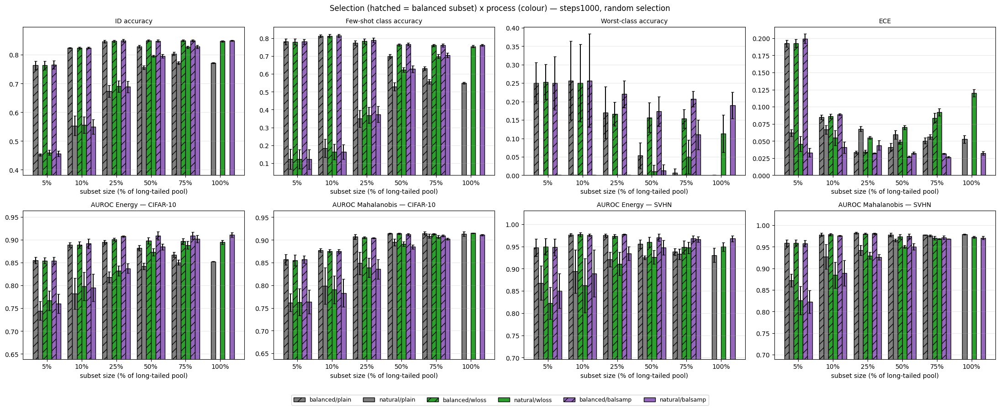

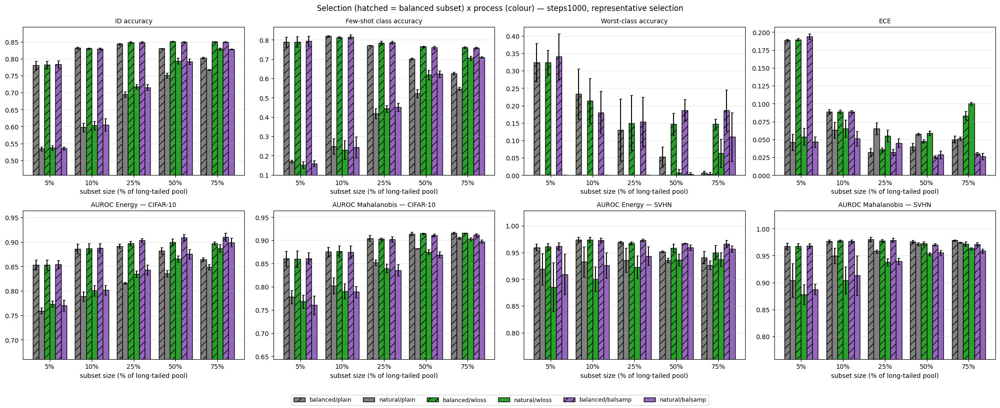

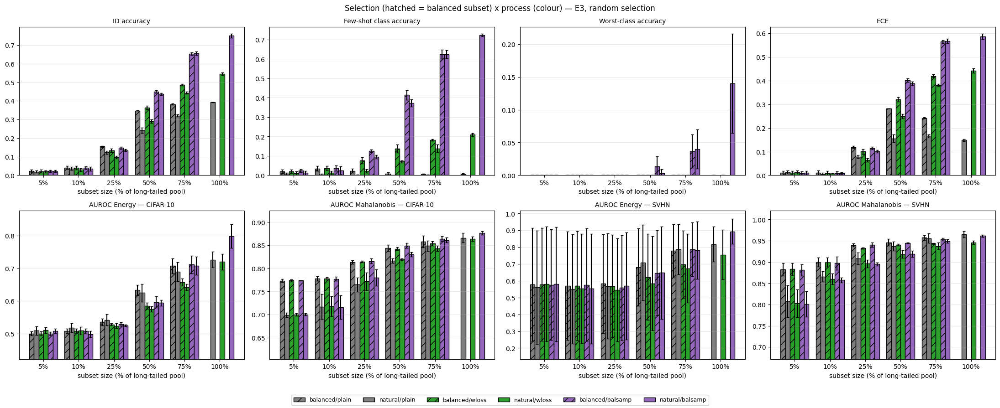

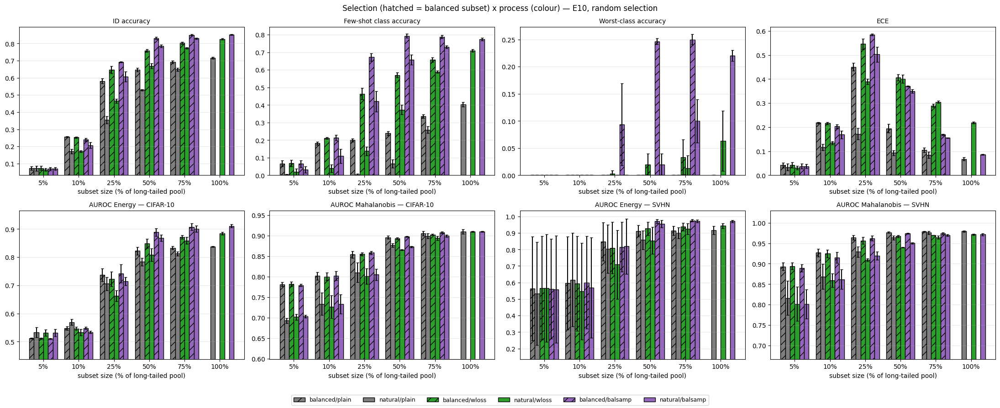

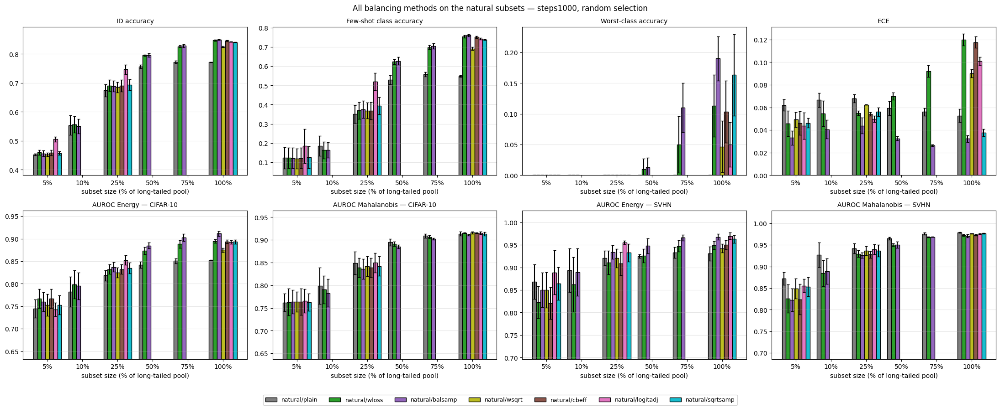

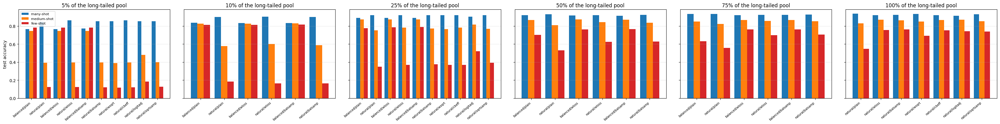

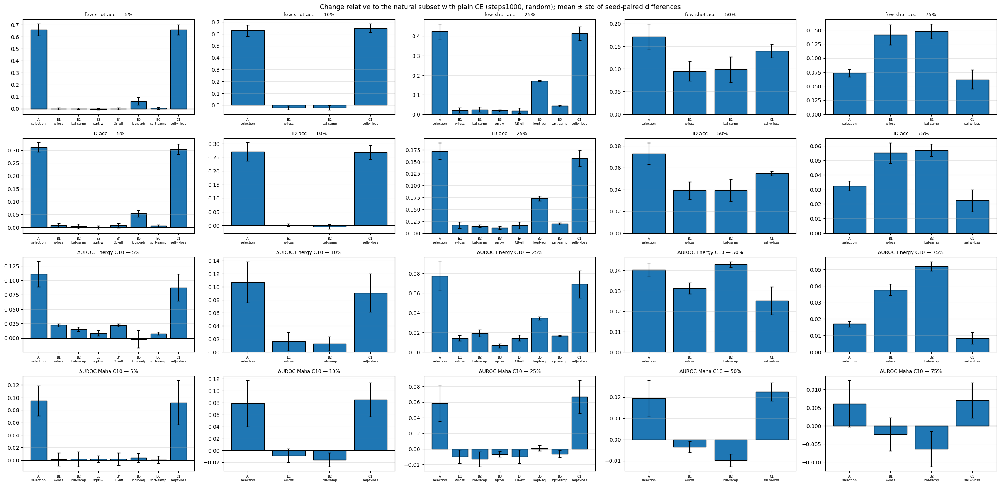

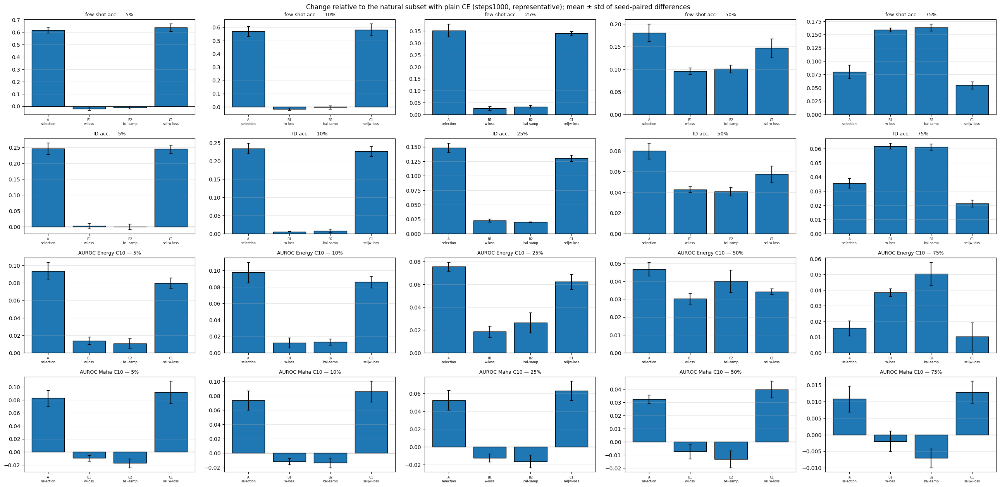

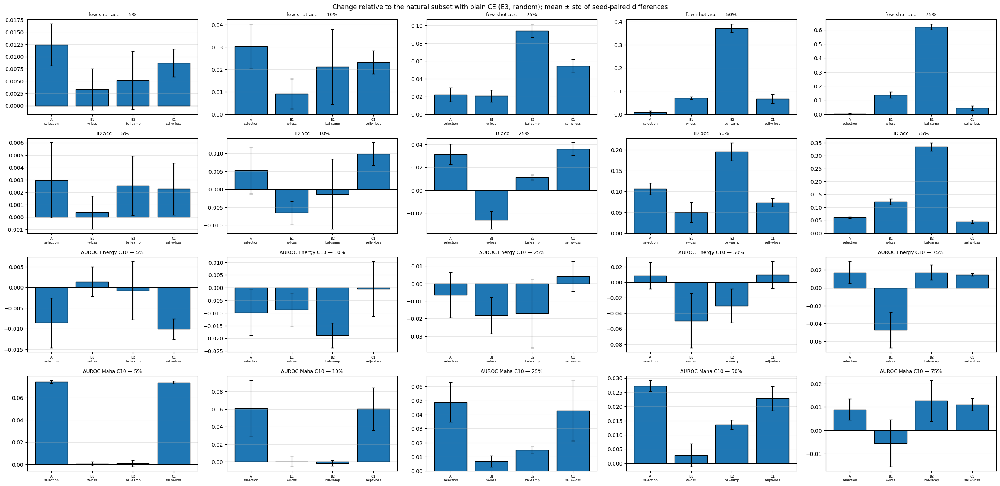

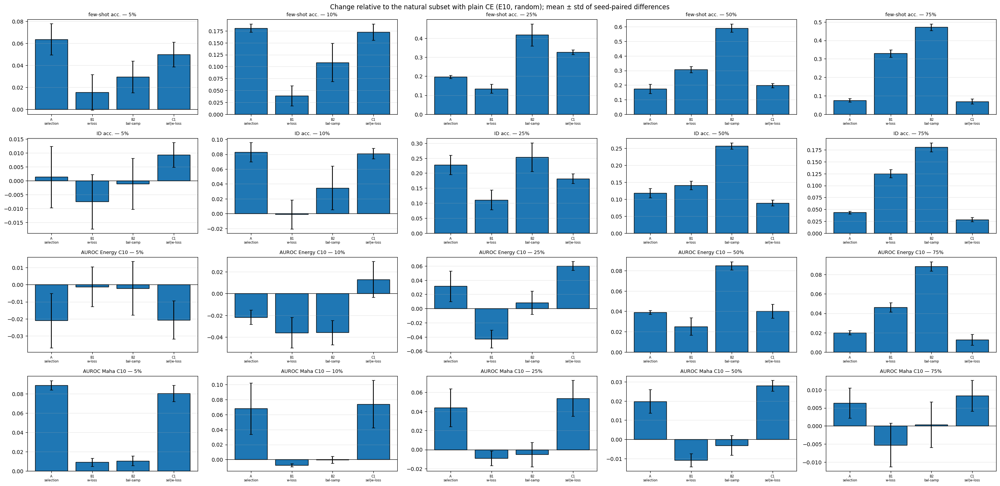

[27.6 controls figures] finished and marked as done.


In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.6 controls figures", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    ctrl_tests = get_ctrl_tests()
    A_COL = {"plain": "tab:gray", "wloss": "tab:green", "balsamp": "tab:purple", "wsqrt": "tab:olive", "cbeff": "tab:brown",
             "logitadj": "tab:pink", "sqrtsamp": "tab:cyan"}
    panels = [("id_acc", "ID accuracy"), ("acc_few", "Few-shot class accuracy"), ("worst_class_acc", "Worst-class accuracy"), ("ece", "ECE"),
              ("auroc_energy_cifar10", "AUROC Energy — CIFAR-10"), ("auroc_maha_train_cifar10", "AUROC Mahalanobis — CIFAR-10"),
              ("auroc_energy_svhn", "AUROC Energy — SVHN"), ("auroc_maha_train_svhn", "AUROC Mahalanobis — SVHN")]
    def plot_controls(proto, sel, arms, fname, title):
        d0 = res_ctrl[(res_ctrl.protocol == proto) & (res_ctrl.selection == sel) & res_ctrl.arm.isin(arms)]
        if not len(d0): return
        fr = sorted(d0.fraction.unique()); arms = [a for a in arms if a in set(d0.arm)]; w = 0.8 / max(len(arms), 1)
        fig, axes = plt.subplots(2, 4, figsize=(22, 9))
        for ax, (col, ttl) in zip(axes.ravel(), panels):
            for k, arm in enumerate(arms):
                b_, p_ = arm.split("/"); d = d0[d0.arm == arm].groupby("fraction")[col]
                pos = [fr.index(f) + (k - (len(arms) - 1) / 2) * w for f in d.mean().index]
                ax.bar(pos, d.mean().values, w, yerr=d.std().fillna(0).values, color=A_COL[p_], hatch="//" if b_ == "balanced" else "",
                       edgecolor="k", capsize=2, label=arm)
            ax.set_xticks(range(len(fr))); ax.set_xticklabels([f"{f:.0%}" for f in fr]); ax.set_title(ttl, fontsize=10)
            ax.set_xlabel("subset size (% of long-tailed pool)"); ax.grid(alpha=0.3, axis="y")
            lo = d0[col].min(); ax.set_ylim(max(0, lo - 0.1 * abs(lo) - 0.02) if col != "ece" else 0, None)
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=min(len(arms), 8), fontsize=9)
        fig.suptitle(title); plt.tight_layout(rect=(0, 0.05, 1, 1)); save_fig3(fname); plt.show()

    CORE_ARMS = [a for a in ARMS if a.split("/")[1] in CTRL_PROCESSES]
    for proto in CPROTOS:
        for sel in CSELS:
            plot_controls(proto, sel, CORE_ARMS, f"E3_controls_metrics_{proto}_{sel}.png",
                          f"Selection (hatched = balanced subset) x process (colour) — {proto}, {sel} selection")
    plot_controls("steps1000", "random", [a for a in ARMS if a.startswith("natural/")], "E3_controls_all_balancing_methods.png",
                  "All balancing methods on the natural subsets — steps1000, random selection")

    # many / medium / few-shot accuracy for every arm
    d_ = res_ctrl[(res_ctrl.protocol == "steps1000") & (res_ctrl.selection == "random")]
    fr = sorted(d_.fraction.unique())
    fig, axes = plt.subplots(1, len(fr), figsize=(5.5 * len(fr), 4.2), sharey=True, squeeze=False)
    for ax, f in zip(axes[0], fr):
        d = d_[d_.fraction == f].groupby("arm")[["acc_many", "acc_medium", "acc_few"]].mean()
        d = d.reindex([a for a in ARMS if a in d.index]); x = np.arange(len(d))
        for i, (gcol, c) in enumerate(zip(d.columns, ["tab:blue", "tab:orange", "tab:red"])):
            ax.bar(x + (i - 1) * 0.27, d[gcol], 0.27, color=c, label=gcol.replace("acc_", "") + "-shot")
        ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=40, ha="right", fontsize=7); ax.set_title(f"{f:.0%} of the long-tailed pool"); ax.grid(alpha=0.3, axis="y")
    axes[0, 0].set_ylabel("test accuracy"); axes[0, 0].legend(fontsize=8)
    plt.tight_layout(); save_fig3("E3_controls_accuracy_by_class_group.png"); plt.show()

    # selection effect vs. process effects (differences to the natural subset with plain CE)
    sub = [f for f in CTRL_FRACS if f < 1]
    metrics_f = [("acc_few", "few-shot acc."), ("id_acc", "ID acc."), ("auroc_energy_cifar10", "AUROC Energy C10"), ("auroc_maha_train_cifar10", "AUROC Maha C10")]
    LABS = [("A.", "A\nselection"), ("B1", "B1\nw-loss"), ("B2", "B2\nbal-samp"), ("B3", "B3\nsqrt-w"), ("B4", "B4\nCB-eff"),
            ("B5", "B5\nlogit-adj"), ("B6", "B6\nsqrt-samp"), ("C1", "C1\nsel|w-loss")]
    for proto in CPROTOS:
        for sel in CSELS:
            t0_ = ctrl_tests[(ctrl_tests.protocol == proto) & (ctrl_tests.selection == sel)]
            if not len(t0_): continue
            fig, axes = plt.subplots(len(metrics_f), len(sub), figsize=(5.2 * len(sub), 3.2 * len(metrics_f)), squeeze=False)
            for r_, (m, mt) in enumerate(metrics_f):
                for c_, f in enumerate(sub):
                    ax = axes[r_, c_]; vals, errs, labs = [], [], []
                    for pref, lab in LABS:
                        t = t0_[t0_.contrast.str.startswith(pref) & (t0_.fraction == f) & (t0_.metric == m)]
                        if len(t): vals.append(t.mean_diff.iloc[0]); errs.append(0 if np.isnan(t.std_diff.iloc[0]) else t.std_diff.iloc[0]); labs.append(lab)
                    ax.bar(range(len(vals)), vals, yerr=errs, color="tab:blue", capsize=3, edgecolor="k")
                    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(vals))); ax.set_xticklabels(labs, fontsize=6); ax.grid(alpha=0.3, axis="y")
                    ax.set_title(f"{mt} — {f:.0%}", fontsize=9)
            fig.suptitle(f"Change relative to the natural subset with plain CE ({proto}, {sel}); mean ± std of seed-paired differences")
            plt.tight_layout(); save_fig3(f"E3_selection_vs_process_effects_{proto}_{sel}.png"); plt.show()
    finish("27.6 controls figures")

## 27.7 Does the conclusion depend on the OOD score?

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.7 controls score agreement", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    M_ALL = [f"{m}_{sc}_{o}" for m in ("auroc", "fpr95") for sc in SCORES for o in OODS]
    ctrl_fams = []
    for (proto, sel), d in res_ctrl.groupby(["protocol", "selection"]):
        for name, (a, b) in CONTRASTS.items():
            if a in set(d.arm) and b in set(d.arm):
                ctrl_fams.append(fam(d[d.arm.isin([a, b])], f"{name} [{proto}, {sel}]", "arm", a, b, M_ALL))
    if ctrl_fams:
        _long, ctrl_effects, _w, ctrl_agree, ctrl_flips = agreement_tables(ctrl_fams)
        save_table3(ctrl_effects, "E3_auroc_effects_by_score.csv"); save_table3(ctrl_agree, "E3_score_agreement_by_family.csv")
        print("Agreement of the other scores with Energy on the direction of the AUROC effect (share of size levels x OOD sets):")
        display(ctrl_agree)
        print(f"\n{len(ctrl_flips)} comparisons change direction between Energy and another score (first 40):")
        display(ctrl_flips.round(4).head(40))
    finish("27.7 controls score agreement")

Agreement of the other scores with Energy on the direction of the AUROC effect (share of size levels x OOD sets):


,sign(msp)==sign(energy),significant only under msp,sign(maha_train)==sign(energy),significant only under maha_train,sign(maha_val)==sign(energy),significant only under maha_val,sign(knn)==sign(energy),significant only under knn,significant only under energy
family,,,,,,,,,
"A. selection: balanced - natural subset (plain CE) [E10, random]",0.68,0.36,0.80,0.28,0.36,0.00,0.76,0.36,0.16
"A. selection: balanced - natural subset (plain CE) [E3, random]",0.60,0.16,0.72,0.36,0.36,0.12,0.68,0.44,0.00
"A. selection: balanced - natural subset (plain CE) [steps1000, random]",1.00,0.04,0.96,0.08,0.68,0.08,0.72,0.08,0.08
"A. selection: balanced - natural subset (plain CE) [steps1000, representative]",0.88,0.12,0.72,0.04,0.52,0.08,0.72,0.12,0.08
"B1. process: class-weighted loss (natural subset) [E10, random]",0.60,0.17,0.50,0.13,0.57,0.13,0.70,0.13,0.10
"B1. process: class-weighted loss (natural subset) [E3, random]",0.53,0.30,0.67,0.07,0.73,0.17,0.60,0.07,0.17
"B1. process: class-weighted loss (natural subset) [steps1000, random]",0.80,0.13,0.63,0.10,0.70,0.00,0.73,0.20,0.03
"B1. process: class-weighted loss (natural subset) [steps1000, representative]",0.84,0.20,0.56,0.20,0.72,0.12,0.80,0.04,0.04
"B2. process: balanced sampling (natural subset) [E10, random]",0.77,0.17,0.30,0.03,0.33,0.10,0.27,0.00,0.03



480 comparisons change direction between Energy and another score (first 40):


score                                                                 msp  \
family                                             level ood                
A.  selection: balanced - natural subset (plain... 10%   cifar10  -0.0070   
                                                         mnist    -0.1337   
                                                         noise    -0.1362   
                                                         svhn     -0.0836   
                                                         textures -0.0884   
                                                   25%   mnist     0.0147   
                                                         noise    -0.0009   
                                                         textures  0.0754   
                                                   5%    cifar10  -0.0527   
                                                         mnist    -0.1105   
                                                         noise    -0.0669   
                                                         svhn     -0.0854   
                                                         textures -0.0980   
                                                   50%   mnist     0.0395   
                                                   75%   svhn      0.0111   
                                                         textures  0.0147   
A.  selection: balanced - natural subset (plain... 10%   cifar10  -0.0286   
                                                         mnist     0.0060   
                                                         noise     0.0245   
                                                         svhn     -0.0448   
                                                         textures -0.0342   
                                                   25%   cifar10  -0.0161   
                                                         mnist    -0.1389   
                                                         noise    -0.1474   
                                                         svhn     -0.0749   
                                                         textures -0.0842   
                                                   5%    cifar10  -0.0204   
                                                         mnist     0.0063   
                                                         noise     0.0038   
                                                         svhn     -0.0133   
                                                         textures -0.0141   
                                                   50%   mnist    -0.0377   
                                                         noise    -0.0694   
                                                         svhn     -0.0179   
                                                         textures -0.0028   
                                                   75%   mnist    -0.0305   
                                                         noise    -0.0216   
                                                         svhn     -0.0264   
                                                         textures  0.0085   
A.  selection: balanced - natural subset (plain... 10%   mnist    -0.0615   

score                                                              energy  \
family                                             level ood                
A.  selection: balanced - natural subset (plain... 10%   cifar10  -0.0218   
                                                         mnist     0.0116   
                                                         noise     0.1589   
                                                         svhn     -0.0208   
                                                         textures  0.0214   
                                                   25%   mnist     0.0407   
                                                         noise     0.0549   
                                                         textures  0.033

[27.7 controls score agreement] finished and marked as done.


## 27.8 ID/OOD trade-off inside the class-balancing experiment

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("27.8 controls tradeoff", needs=['27.2a', '27.2b', '27.2c', '27.2d']):
    res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    res_ctrl["cell"] = res_ctrl.protocol + "|" + res_ctrl.selection
    tr_ctrl = tradeoff_summary(res_ctrl, ["cell", "fraction"], SCORES, "class-balancing controls (all arms)")
    tr_ctrl_fs = tradeoff_summary(res_ctrl.assign(id_acc=res_ctrl.acc_few), ["cell", "fraction"], SCORES, "class-balancing controls (few-shot accuracy instead of ID acc.)")
    save_table3(pd.concat([tr_ctrl, tr_ctrl_fs]).round(4), "E3_tradeoff_correlations_controls.csv", index=False)
    display(pd.concat([tr_ctrl, tr_ctrl_fs]).round(3))
    finish("27.8 controls tradeoff")

,experiment,score,ood,n_runs,rho_acc_pooled,p_acc_pooled,rho_acc_within,p_acc_within,rho_drift_pooled,rho_drift_within
0,class-balancing controls (all arms),msp,cifar10,423,0.987,0.000,0.890,0.000,0.855,0.215
1,class-balancing controls (all arms),msp,svhn,423,0.929,0.000,0.699,0.000,0.762,0.258
2,class-balancing controls (all arms),msp,textures,423,0.974,0.000,0.738,0.000,0.839,0.323
3,class-balancing controls (all arms),msp,mnist,423,0.566,0.000,-0.295,0.000,0.647,-0.081
4,class-balancing controls (all arms),msp,noise,423,0.838,0.000,0.123,0.012,0.860,0.215
5,class-balancing controls (all arms),energy,cifar10,423,0.976,0.000,0.795,0.000,0.889,0.374
6,class-balancing controls (all arms),energy,svhn,423,0.885,0.000,0.327,0.000,0.802,0.215
7,class-balancing controls (all arms),energy,textures,423,0.949,0.000,0.560,0.000,0.891,0.446
8,class-balancing controls (all arms),energy,mnist,423,0.716,0.000,-0.139,0.004,0.772,-0.124
9,class-balancing controls (all arms),energy,noise,423,0.914,0.000,0.471,0.000,0.949,0.388


[27.8 controls tradeoff] finished and marked as done.


# 28. Fine-tuning regime and backbone

## 28.1 Run the regimes

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

run_block("28.1")

[28.1 fine-tuning regimes and second backbone] 36 runs | total training time 4.8 h
[1/36] reg_probe_random_0.05_seed0  (2250 images, 1000 steps = 56.9 epochs)
    step   250/1000  loss 3.2021  0.8 min
    step   500/1000  loss 1.1722  1.5 min
    step   750/1000  loss 0.7465  2.3 min
    step  1000/1000  loss 0.6643  3.0 min
    ID acc 0.7832 | AUROC CIFAR-10: energy 0.8422 maha 0.8126 knn 0.6583 | SVHN: energy 0.9339 maha 0.9361 | ECE 0.2075
[2/36] reg_probe_random_0.25_seed0  (11250 images, 1000 steps = 11.4 epochs)
    step   250/1000  loss 3.2841  0.7 min
    step   500/1000  loss 1.3448  1.5 min
    step   750/1000  loss 0.9495  2.2 min
    step  1000/1000  loss 0.8688  3.0 min
    ID acc 0.8007 | AUROC CIFAR-10: energy 0.8470 maha 0.8262 knn 0.7801 | SVHN: energy 0.9399 maha 0.9331 | ECE 0.2159
[3/36] reg_probe_random_1.00_seed0  (45000 images, 1000 steps = 2.8 epochs)
    step   250/1000  loss 3.3026  0.8 min
    step   500/1000  loss 1.3799  1.5 min
    step   750/1000  loss 0.

## 28.2 Collected results

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("28.2 regimes tables", needs=['28.1']):
    res_reg, REGS, REF21 = get_res_reg()
    save_table3(res_reg, "E4_regimes_all_runs.csv", index=False)
    g = res_reg.groupby(["regime", "fraction"])
    REG_SHOW = ["id_acc", "worst_class_acc", "feature_drift"] + [f"auroc_{sc}_{o}" for o in OODS_CORE for sc in SCORES] + ["ece"]
    mean_r, std_r = g[CORE].mean(), g[CORE].std().fillna(0)
    tab_r = (mean_r[REG_SHOW].round(4).astype(str) + " ± " + std_r[REG_SHOW].round(4).astype(str)).reindex(REGS, level="regime")
    save_table3(mean_r, "E4_regimes_mean.csv"); save_table3(tab_r, "E4_regimes_mean_std.csv")
    print(f"{len(res_reg)} rows; seeds per setting:"); display(g.seed.nunique().unstack("fraction").reindex(REGS))
    display(tab_r)
    print("Other OOD sets:")
    rows = [f"auroc_{sc}_{o}" for o in OODS if o not in OODS_CORE for sc in SCORES]
    display(mean_r[rows].round(4).reindex(REGS, level="regime"))
    finish("28.2 regimes tables")

45 rows; seeds per setting:


fraction,0.05,0.25,1.00
regime,,,
baseline,3,3,3
probe,3,3,3
lr0.1x,3,3,3
lr10x,3,3,3
in21k,3,3,3


id_acc  worst_class_acc    feature_drift  \
regime   fraction                                                      
baseline 0.05      0.8653 ± 0.0027    0.39 ± 0.0557  0.2341 ± 0.0008   
         0.25      0.8996 ± 0.0007  0.5733 ± 0.0462  0.2438 ± 0.0004   
         1.00      0.9053 ± 0.0008  0.5333 ± 0.0208  0.2344 ± 0.0004   
probe    0.05        0.78 ± 0.0032  0.2033 ± 0.0737        0.0 ± 0.0   
         0.25      0.8002 ± 0.0019  0.3133 ± 0.0751        0.0 ± 0.0   
         1.00      0.8033 ± 0.0034    0.34 ± 0.0656        0.0 ± 0.0   
lr0.1x   0.05      0.8586 ± 0.0028     0.3 ± 0.0872  0.1137 ± 0.0029   
         0.25      0.8719 ± 0.0005  0.4633 ± 0.0611  0.1176 ± 0.0006   
         1.00      0.8744 ± 0.0011  0.4533 ± 0.0153  0.1183 ± 0.0005   
lr10x    0.05      0.8379 ± 0.0034    0.42 ± 0.0557  0.3482 ± 0.0036   
         0.25      0.9016 ± 0.0014  0.6133 ± 0.0321  0.3969 ± 0.0052   
         1.00       0.9241 ± 0.001  0.7133 ± 0.0306  0.3595 ± 0.0043   
in21k    0.05      0.8296 ± 0.0031  0.0233 ± 0.0252  0.2974 ± 0.0027   
         0.25       0.8643 ± 0.004    0.08 ± 0.0819  0.3032 ± 0.0004   
         1.00      0.8745 ± 0.0042    0.21 ± 0.1473  0.3021 ± 0.0015   

                  auroc_msp_cifar10 auroc_energy_cifar10  \
regime   fraction                                          
baseline 0.05       0.9186 ± 0.0017      0.9281 ± 0.0069   
         0.25       0.9291 ± 0.0062      0.9431 ± 0.0053   
         1.00       0.9316 ± 0.0032       0.946 ± 0.0037   
probe    0.05       0.8529 ± 0.0085       0.844 ± 0.0073   
         0.25       0.8586 ± 0.0034      0.8506 ± 0.0031   
         1.00       0.8572 ± 0.0022      0.8484 ± 0.0024   
lr0.1x   0.05       0.9155 ± 0.0028      0.9218 ± 0.0041   
         0.25        0.921 ± 0.0066      0.9288 ± 0.0034   
         1.00         0.92 ± 0.0045      0.9276 ± 0.0026   
lr10x    0.05       0.8598 ± 0.0093      0.8719 ± 0.0102   
         0.25       0.9099 ± 0.0045      0.9212 ± 0.0056   
         1.00       0.9147 ± 0.0051      0.9315 ± 0.0098   
in21k    0.05        0.892 ± 0.0207      0.8842 ± 0.0269   
         0.25       0.8917 ± 0.0074      0.8742 ± 0.0202   
         1.00       0.8866 ± 0.0027      0.8592 ± 0.0125   

                  auroc_maha_train_cifar10 auroc_maha_val_cifar10  \
regime   fraction                                                   
baseline 0.05                0.93 ± 0.0044        0.9281 ± 0.0015   
         0.25              0.9515 ± 0.0034        0.9461 ± 0.0026   
         1.00              0.9532 ± 0.0019        0.9475 ± 0.0016   
probe    0.05              0.8114 ± 0.0071           0.8241 ± 0.0   
         0.25                0.825 ± 0.002           0.8241 ± 0.0   
         1.00                  0.828 ± 0.0           0.8241 ± 0.0   
lr0.1x   0.05              0.8892 ± 0.0034        0.8959 ± 0.0016   
         0.25               0.9015 ± 0.002        0.8963 ± 0.0023   
         1.00              0.9035 ± 0.0022        0.8957 ± 0.0021   
lr10x    0.05              0.8839 ± 0.0084        0.8898 ± 0.0083   
         0.25              0.9344 ± 0.0051         0.9327 ± 0.004   
         1.00              0.9528 ± 0.0043        0.9489 ± 0.0044   
in21k    0.05              0.9167 ± 0.0061         0.908 ± 0.0044   
         0.25              0.9354 ± 0.0044        0.9301 ± 0.0029   
         1.00              0.9367 ± 0.0029         0.9309 ± 0.002   

                  auroc_knn_cifar10   auroc_msp_svhn auroc_energy_svhn  \
regime   fraction                                                        
baseline 0.05       0.8763 ± 0.0144  0.9455 ± 0.0131   0.9639 ± 0.0078   
         0.25       0.9427 ± 0.0058  0.9539 ± 0.0059   0.9724 ± 0.0037   
         1.00       0.9438 ± 0.0034  0.9555 ± 0.0027   0.9753 ± 0.0007   
probe    0.05       0.6656 ± 0.0067  0.9376 ± 0.0136   0.9449 ± 0.0106   
         0.25       0.7815 ± 0.0015  0.9451 ± 0.0096   0.9507 ± 0.0101   
         1.00          0.7798 ± 0.0  0.9456 ± 0.0106   0.9526 ± 0.0103   
lr0.1x   0.05   

Other OOD sets:


auroc_msp_textures  auroc_energy_textures  \
regime   fraction                                              
baseline 0.05                  0.9549                 0.9654   
         0.25                  0.9617                 0.9728   
         1.00                  0.9631                 0.9745   
probe    0.05                  0.9034                 0.8920   
         0.25                  0.9079                 0.8981   
         1.00                  0.9094                 0.8991   
lr0.1x   0.05                  0.9506                 0.9546   
         0.25                  0.9539                 0.9578   
         1.00                  0.9546                 0.9584   
lr10x    0.05                  0.9337                 0.9553   
         0.25                  0.9531                 0.9689   
         1.00                  0.9540                 0.9736   
in21k    0.05                  0.9515                 0.9560   
         0.25                  0.9543                 0.9566   
         1.00                  0.9547                 0.9543   

                   auroc_maha_train_textures  auroc_maha_val_textures  \
regime   fraction                                                       
baseline 0.05                         0.9702                   0.9729   
         0.25                         0.9778                   0.9776   
         1.00                         0.9792                   0.9786   
probe    0.05                         0.9354                   0.9384   
         0.25                         0.9394                   0.9384   
         1.00                         0.9399                   0.9384   
lr0.1x   0.05                         0.9609                   0.9624   
         0.25                         0.9646                   0.9631   
         1.00                         0.9648                   0.9630   
lr10x    0.05                         0.9660                   0.9759   
         0.25                         0.9758                   0.9795   
         1.00                         0.9819                   0.9828   
in21k    0.05                         0.9696                   0.9766   
         0.25                         0.9761                   0.9770   
         1.00                         0.9769                   0.9771   

                   auroc_knn_textures  auroc_msp_mnist  auroc_energy_mnist  \
regime   fraction                                                            
baseline 0.05                  0.9411           0.5581              0.6382   
         0.25                  0.9729           0.5396              0.6503   
         1.00                  0.9745           0.5518              0.6675   
probe    0.05                  0.9108           0.6767              0.7681   
         0.25                  0.9457           0.7124              0.7989   
         1.00                  0.9458           0.7066              0.7972   
lr0.1x   0.05                  0.9470           0.6258              0.7236   
         0.25                  0.9661           0.6425              0.7453   
         1.00                  0.9659           0.6334              0.7368   
lr10x    0.05                  0.8949           0.4474              0.4924   
         0.25                  0.9671           0.6014              0.6605   
         1.00                  0.9720           0.5426              0.5942   
in21k    0.05                  0.9224           0.5225              0.6306   
         0.25                  0.9675           0.6186              0.8050   
         1.00                  0.9675           0.6128              0.8079   

                   auroc_maha_train_mnist  auroc_maha_val_mnist  \
regime   fraction                                                 
baseline 0.05                      0.7300                0.7476   
         0.25                      0.8036                0.7866   
         1.00                      0.8077                0.7996   
probe    0.05             

[28.2 regimes tables] finished and marked as done.


## 28.3 Paired comparison with the baseline recipe

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("28.3 regimes tests", needs=['28.1']):
    res_reg, REGS, REF21 = get_res_reg()
    reg_tests = concat_nonempty([paired_compare(res_reg[res_reg.regime.isin([r, "baseline"])], "regime", r, "baseline", CORE).assign(comparison=f"{r} - baseline")
                                 for r in REGS if r != "baseline"])
    save_table3(reg_tests.round(5), "E4_paired_tests_regime_vs_baseline.csv", index=False)
    SHOWR = ["id_acc", "worst_class_acc", "feature_drift", "ece"] + [f"auroc_{sc}_{o}" for o in OODS_CORE for sc in SCORES]
    display(star_pivot(reg_tests[reg_tests.metric.isin(SHOWR)], ["comparison", "metric"]).reindex(SHOWR, level="metric"))
    finish("28.3 regimes tests")

5%       25%      100%
comparison        metric                                                
in21k - baseline  id_acc                    -0.0357*  -0.0353*  -0.0308*
                  worst_class_acc           -0.3667*  -0.4933*   -0.3233
                  feature_drift             +0.0632*  +0.0594*  +0.0676*
                  ece                       +0.4794*  +0.5608*  +0.5776*
                  auroc_msp_cifar10          -0.0267  -0.0374*  -0.0450*
                  auroc_energy_cifar10       -0.0439  -0.0690*  -0.0868*
                  auroc_maha_train_cifar10  -0.0133*  -0.0161*  -0.0165*
                  auroc_maha_val_cifar10    -0.0201*  -0.0160*  -0.0166*
                  auroc_knn_cifar10         -0.0289*  -0.0215*  -0.0252*
                  auroc_msp_svhn             -0.0077   +0.0059   -0.0015
                  auroc_energy_svhn          -0.0124   +0.0029   -0.0051
                  auroc_maha_train_svhn      +0.0044  +0.0051*  +0.0023*
                  auroc_maha_val_svhn        +0.0062  +0.0055*  +0.0033*
                  auroc_knn_svhn             -0.0183   +0.0041   -0.0008
lr0.1x - baseline id_acc                     -0.0067  -0.0277*  -0.0308*
                  worst_class_acc            -0.0900  -0.1100*   -0.0800
                  feature_drift             -0.1204*  -0.1262*  -0.1162*
                  ece                       +0.1274*  +0.1214*  +0.1057*
                  auroc_msp_cifar10          -0.0032  -0.0080*  -0.0115*
                  auroc_energy_cifar10       -0.0063  -0.0143*  -0.0185*
                  auroc_maha_train_cifar10  -0.0408*  -0.0500*  -0.0496*
                  auroc_maha_val_cifar10    -0.0322*  -0.0498*  -0.0518*
                  auroc_knn_cifar10         -0.0559*  -0.0598*  -0.0627*
                  auroc_msp_svhn             +0.0018   +0.0026   +0.0006
                  auroc_energy_svhn          +0.0002   -0.0029   -0.0056
                  auroc_maha_train_svhn     -0.0115*  -0.0150*  -0.0167*
                  auroc_maha_val_svhn        -0.0128  -0.0160*  -0.0161*
                  auroc_knn_svhn             +0.0178   +0.0014   -0.0014
lr10x - baseline  id_acc                    -0.0274*  +0.0020*  +0.0188*
                  worst_class_acc            +0.0300   +0.0400  +0.1800*
                  feature_drift             +0.1140*  +0.1531*  +0.1251*
                  ece                        +0.0118   -0.0097  -0.0569*
                  auroc_msp_cifar10         -0.0588*  -0.0192*   -0.0168
                  auroc_energy_cifar10      -0.0562*  -0.0219*   -0.0145
                  auroc_maha_train_cifar10  -0.0460*  -0.0171*   -0.0003
                  auroc_maha_val_cifar10    -0.0383*  -0.0133*   +0.0014
                  auroc_knn_cifar10         -0.0809*  -0.0221*   -0.0041
                  auroc_msp_svhn             -0.0327   -0.0199   -0.0208
                  auroc_energy_svhn          -0.0252   -0.0143   -0.0111
                  auroc_maha_train_svhn      -0.0205   -0.0162   -0.0057
                  auroc_maha_val_svhn        -0.0106   -0.0120   -0.0035
                  auroc_knn_svhn            -0.0827*   -0.0278   -0.0186
probe - baseline  id_acc                    -0.0853*  -0.0994*  -0.1020*
                  worst_class_acc           -0.1867*  -0.2600*   -0.1933
                  feature_drift             -0.2341*  -0.2438*  -0.2344*
                  ece                       +0.1754*  +0.1678*  +0.1521*
                  auroc_msp_cifar10         -0.0658*  -0.0705*  -0.0744*
                  auroc_energy_cifar10      -0.0841*  -0.0925*  -0.0976*
                  auroc_maha_train_cifar10  -0.1186*  -0.1265*  -0.1252*
                  auroc_maha_val_cifar10    -0.1040*  -0.1220*  -0.1234*
                  auroc_knn_cifar10         -0.2107*  -0.1613*  -0.1640*
                  auroc_msp_svhn             -0.0080   -0.0088   -0.0100
                  auroc_energy_svhn          -0.0190   -0.0217   -0.0227
                  auroc_maha_train_

[28.3 regimes tests] finished and marked as done.


## 28.4 Figures

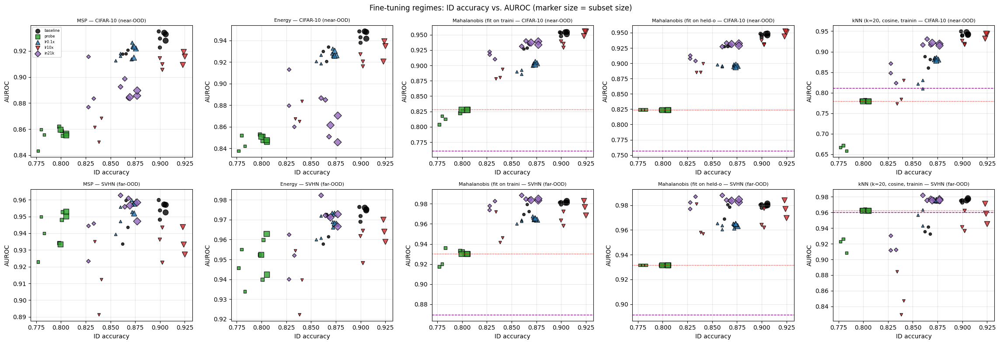

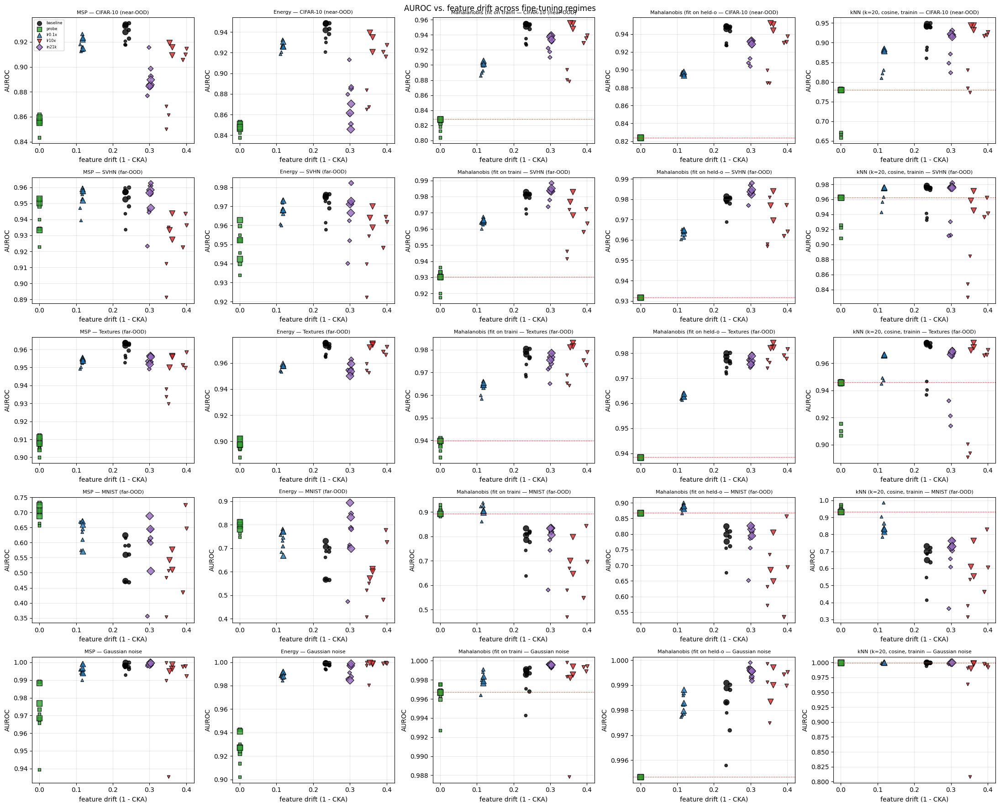

[28.4 regimes figures] finished and marked as done.


In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("28.4 regimes figures", needs=['28.1']):
    res_reg, REGS, REF21 = get_res_reg()
    R_COL = dict(zip(["baseline", "probe", "lr0.1x", "lr10x", "in21k"], ["black", "tab:green", "tab:blue", "tab:red", "tab:purple"]))
    R_MK = dict(zip(["baseline", "probe", "lr0.1x", "lr10x", "in21k"], ["o", "s", "^", "v", "D"]))
    fig, axes = plt.subplots(len(OODS_CORE), len(SCORES), figsize=(4.6 * len(SCORES), 4 * len(OODS_CORE)), squeeze=False)
    for r_, o in enumerate(OODS_CORE):
        for c_, sc in enumerate(SCORES):
            ax = axes[r_, c_]; col = f"auroc_{sc}_{o}"
            for rg in REGS:
                d = res_reg[res_reg.regime == rg]
                ax.scatter(d.id_acc, d[col], c=R_COL[rg], marker=R_MK[rg], s=18 + 60 * d.fraction.values, edgecolors="k", alpha=0.8, label=rg)
            for bb, rf, ls in [("in1k", PRETRAINED_REF, ":"), ("in21k", REF21, "--")]:
                if col in rf: ax.axhline(rf[col], color="red" if bb == "in1k" else "purple", ls=ls, lw=1, label=f"pretrained {bb}")
            ax.set_xlabel("ID accuracy"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3); ax.set_title(f"{SCORE_NAME[sc][:26]} — {OOD_NAME[o][:20]}", fontsize=8)
    axes[0, 0].legend(fontsize=6); fig.suptitle("Fine-tuning regimes: ID accuracy vs. AUROC (marker size = subset size)")
    plt.tight_layout(); save_fig3("E4_regimes_tradeoff.png"); plt.show()

    fig, axes = plt.subplots(len(OODS), len(SCORES), figsize=(4.4 * len(SCORES), 3.6 * len(OODS)), squeeze=False)
    for r_, o in enumerate(OODS):
        for c_, sc in enumerate(SCORES):
            ax = axes[r_, c_]; col = f"auroc_{sc}_{o}"
            for rg in REGS:
                d = res_reg[res_reg.regime == rg]
                ax.scatter(d.feature_drift, d[col], c=R_COL[rg], marker=R_MK[rg], s=18 + 60 * d.fraction.values, edgecolors="k", alpha=0.8, label=rg)
            if col in PRETRAINED_REF: ax.axhline(PRETRAINED_REF[col], color="red", ls=":", lw=1)
            ax.set_xlabel("feature drift (1 - CKA)"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3); ax.set_title(f"{SCORE_NAME[sc][:26]} — {OOD_NAME[o][:20]}", fontsize=8)
    axes[0, 0].legend(fontsize=6); fig.suptitle("AUROC vs. feature drift across fine-tuning regimes")
    plt.tight_layout(); save_fig3("E4_regimes_auroc_vs_drift.png"); plt.show()
    finish("28.4 regimes figures")

## 28.5 Trade-off statistics across regimes

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("28.5 regimes tradeoff", needs=['28.1']):
    res_reg, REGS, REF21 = get_res_reg()
    disc_reg = discordance(res_reg, ["fraction"], SCORES, OODS, "fine-tuning regimes (same size)")
    save_table3(disc_reg.round(4), "E4_regimes_discordance.csv", index=False)
    display(disc_reg.round(3))
    rows = []
    for rg in REGS:
        for f in REGIME_FRACS:
            d = res_reg[(res_reg.regime == rg) & (res_reg.fraction == f)]
            if not len(d): continue
            rf = REF21 if rg == "in21k" else PRETRAINED_REF
            rows.append(dict(regime=rg, fraction=f, id_acc=d.id_acc.mean(), feature_drift=d.feature_drift.mean(),
                             **{f"{k}_{o}": d[f"auroc_{k}_{o}"].mean() - rf.get(f"auroc_{k}_{o}", np.nan) for k in ("maha_train", "knn") for o in OODS_CORE}))
    reg_vs_pre = pd.DataFrame(rows)
    save_table3(reg_vs_pre.round(4), "E4_regimes_auroc_minus_pretrained.csv", index=False)
    print("AUROC of the fine-tuned model minus AUROC of its own pretrained features (negative = fine-tuning lost OOD information):")
    display(reg_vs_pre.round(4))
    finish("28.5 regimes tradeoff")

,experiment,score,ood,pairs,discordant_share,rho_within,p_within
0,fine-tuning regimes (same size),msp,cifar10,312,0.231,0.691,0.000
1,fine-tuning regimes (same size),msp,svhn,312,0.535,-0.112,0.463
2,fine-tuning regimes (same size),msp,textures,312,0.256,0.600,0.000
3,fine-tuning regimes (same size),msp,mnist,312,0.705,-0.554,0.000
4,fine-tuning regimes (same size),msp,noise,312,0.375,0.338,0.023
5,fine-tuning regimes (same size),energy,cifar10,312,0.231,0.750,0.000
6,fine-tuning regimes (same size),energy,svhn,312,0.397,0.319,0.033
7,fine-tuning regimes (same size),energy,textures,312,0.199,0.857,0.000
8,fine-tuning regimes (same size),energy,mnist,312,0.740,-0.647,0.000
9,fine-tuning regimes (same size),energy,noise,312,0.196,0.745,0.000


AUROC of the fine-tuned model minus AUROC of its own pretrained features (negative = fine-tuning lost OOD information):


,regime,fraction,id_acc,feature_drift,maha_train_cifar10,maha_train_svhn,knn_cifar10,knn_svhn
0,baseline,0.05,0.8653,0.2341,0.1020,0.0433,0.0965,-0.0262
1,baseline,0.25,0.8996,0.2438,0.1235,0.0504,0.1629,0.0118
2,baseline,1.00,0.9053,0.2344,0.1252,0.0514,0.1640,0.0142
3,probe,0.05,0.7800,0.0000,-0.0166,-0.0057,-0.1141,-0.0434
4,probe,0.25,0.8002,0.0000,-0.0030,0.0018,0.0017,0.0009
5,probe,1.00,0.8033,0.0000,-0.0000,0.0000,-0.0000,0.0000
6,lr0.1x,0.05,0.8586,0.1137,0.0612,0.0318,0.0406,-0.0084
7,lr0.1x,0.25,0.8719,0.1176,0.0735,0.0353,0.1031,0.0131
8,lr0.1x,1.00,0.8744,0.1183,0.0755,0.0346,0.1014,0.0129
9,lr10x,0.05,0.8379,0.3482,0.0560,0.0228,0.0156,-0.1089


[28.5 regimes tradeoff] finished and marked as done.


# 29. Mechanism diagnostics

Mean diagnostics per experiment group and subset size:


diag_eff_rank  diag_nc1  diag_feat_norm_id  \
experiment_group fraction                                               
controls         0.05            597.660     1.681             25.695   
                 0.10            587.137     1.487             25.697   
                 0.25            571.416     1.200             25.737   
                 0.50            561.728     1.041             25.739   
                 0.75            555.075     0.943             25.751   
                 1.00            549.417     0.870             25.771   
protocols        0.05            569.476     1.182             25.696   
                 0.10            558.859     1.020             25.700   
                 0.25            537.794     0.763             25.773   
                 0.50            523.196     0.628             25.827   
                 0.75            519.029     0.594             25.849   
                 1.00            517.000     0.577             25.869   
regimes          0.05            548.099     1.035             21.836   
                 0.25            529.760     0.900             21.855   
                 1.00            525.631     0.873             21.834   

                           diag_maxlogit_id  feature_drift  
experiment_group fraction                                   
controls         0.05                 3.475          0.094  
                 0.10                 3.784          0.099  
                 0.25                 4.780          0.142  
                 0.50                 5.073          0.159  
                 0.75                 5.425          0.175  
                 1.00                 5.768          0.189  
protocols        0.05                 4.380          0.132  
                 0.10                 4.628          0.151  
                 0.25                 6.302          0.210  
                 0.50                 7.399          0.235  
                 0.75                 8.019          0.247  
                 1.00                 8.406          0.254  
regimes          0.05                 6.327          0.199  
                 0.25                 6.491          0.212  
                 1.00                 6.332          0.203

score                      energy   knn  maha_train  maha_val   msp
diagnostic        ood                                              
diag_eff_rank     cifar10   -0.57 -0.60       -0.68     -0.71 -0.50
                  svhn      -0.51  0.12       -0.55     -0.58 -0.37
diag_feat_norm_id cifar10    0.79  0.63        0.57      0.73  0.74
                  svhn       0.65 -0.28        0.40      0.65  0.63
diag_maxlogit_id  cifar10    0.89  0.73        0.71      0.85  0.84
                  svhn       0.78 -0.29        0.51      0.75  0.72
diag_nc1          cifar10   -0.80 -0.79       -0.79     -0.89 -0.75
                  svhn      -0.72  0.17       -0.64     -0.82 -0.64

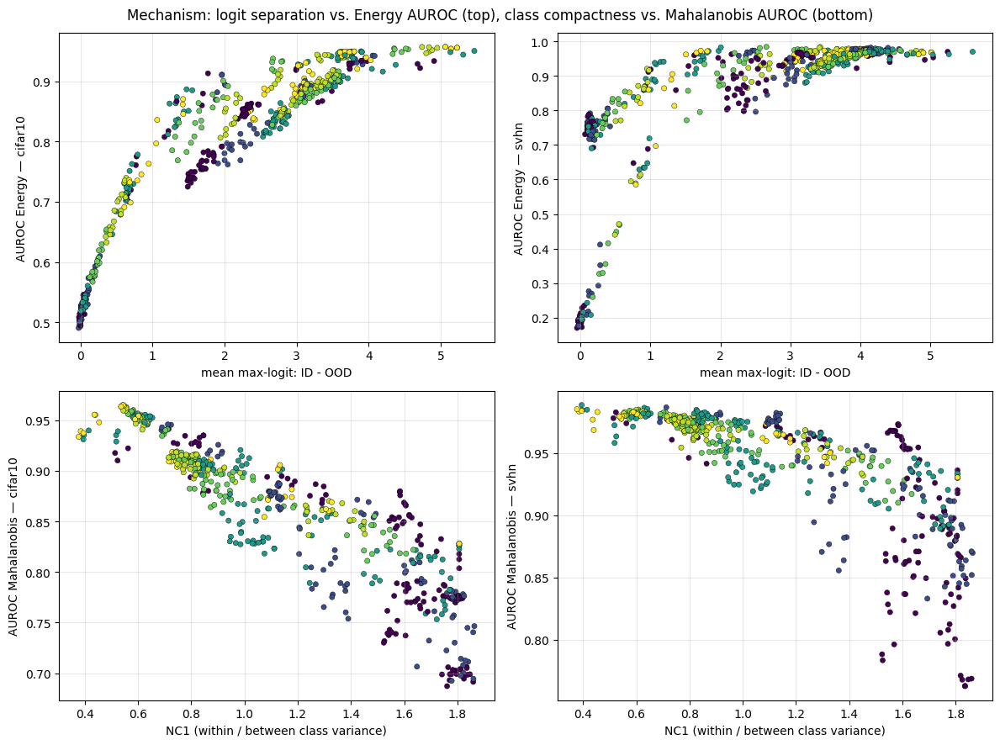

[29 mechanism] finished and marked as done.


In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("29 mechanism", needs=['25.2a', '25.2b', '27.2a', '27.2b', '27.2c', '27.2d', '28.1']):
    res_proto, PROTOS = get_res_proto(); res_reg, REGS, REF21 = get_res_reg(); res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    DIAG = ["diag_eff_rank", "diag_nc1", "diag_feat_norm_id", "diag_maxlogit_id"] + [f"diag_maxlogit_{o}" for o in OODS] + [f"diag_feat_norm_{o}" for o in OODS]
    frames = [res_proto.assign(experiment_group="protocols"), res_reg.assign(experiment_group="regimes"),
              res_ctrl.assign(experiment_group="controls")]
    diag_all = pd.concat([f[[c for c in ["experiment_group", "protocol", "regime", "arm", "strategy", "selection", "fraction", "seed", "id_acc", "feature_drift"]
                             + DIAG + AUROC_COLS if c in f.columns]] for f in frames], ignore_index=True)
    diag_all = diag_all[diag_all.diag_eff_rank.notna()]
    save_table3(diag_all, "E5_diagnostics_all_runs.csv", index=False)
    print("Mean diagnostics per experiment group and subset size:")
    display(diag_all.groupby(["experiment_group", "fraction"])[DIAG[:4] + ["feature_drift"]].mean().round(3))
    rows = []
    for dg in DIAG[:4]:
        for sc in SCORES:
            for o in OODS_CORE:
                a = assoc(diag_all, dg, f"auroc_{sc}_{o}", ["experiment_group", "fraction"])
                rows.append(dict(diagnostic=dg, score=sc, ood=o, rho_pooled=a["rho_pooled"], rho_within=a["rho_within"], p_within=a["p_within"], n_runs=a["n_runs"]))
    mech = pd.DataFrame(rows)
    save_table3(mech.round(4), "E5_diagnostics_vs_auroc.csv", index=False)
    display(mech.pivot_table(index=["diagnostic", "ood"], columns="score", values="rho_within").round(2))

    d = diag_all
    fig, axes = plt.subplots(2, len(OODS_CORE), figsize=(6 * len(OODS_CORE), 9), squeeze=False)
    for c_, o in enumerate(OODS_CORE):
        ax = axes[0, c_]; x = d.diag_maxlogit_id - d[f"diag_maxlogit_{o}"]
        ax.scatter(x, d[f"auroc_energy_{o}"], c=np.log10(d.fraction * 100), cmap="viridis", s=20, edgecolors="k", lw=0.3)
        ax.set_xlabel("mean max-logit: ID - OOD"); ax.set_ylabel(f"AUROC Energy — {o}"); ax.grid(alpha=0.3)
        ax = axes[1, c_]; ax.scatter(d.diag_nc1, d[f"auroc_maha_train_{o}"], c=np.log10(d.fraction * 100), cmap="viridis", s=20, edgecolors="k", lw=0.3)
        ax.set_xlabel("NC1 (within / between class variance)"); ax.set_ylabel(f"AUROC Mahalanobis — {o}"); ax.grid(alpha=0.3)
    fig.suptitle("Mechanism: logit separation vs. Energy AUROC (top), class compactness vs. Mahalanobis AUROC (bottom)")
    plt.tight_layout(); save_fig3("E5_mechanism.png"); plt.show()
    finish("29 mechanism")

# 30. Consolidated answer: is there an ID/OOD trade-off?

Share of discordant pairs (higher ID accuracy but LOWER AUROC); 0.5 = no relation, > 0.5 = trade-off, < 0.5 = both improve together:


score                                                msp  energy  maha_train  \
experiment                                ood                                  
class balancing (arms)                    cifar10   0.15    0.18        0.30   
                                          mnist     0.65    0.61        0.63   
                                          noise     0.46    0.34        0.46   
                                          svhn      0.22    0.29        0.39   
                                          textures  0.17    0.22        0.36   
fine-tuning regime / backbone             cifar10   0.23    0.23        0.21   
                                          mnist     0.71    0.74        0.69   
                                          noise     0.38    0.20        0.43   
                                          svhn      0.54    0.40        0.39   
                                          textures  0.26    0.20        0.25   
selection rule (random vs representative) cifar10   0.51    0.53        0.53   
                                          mnist     0.60    0.63        0.52   
                                          noise     0.51    0.55        0.53   
                                          svhn      0.49    0.52        0.48   
                                          textures  0.49    0.45        0.44   
training length (protocols + step sweep)  cifar10   0.16    0.18        0.14   
                                          mnist     0.55    0.54        0.76   
                                          noise     0.35    0.22        0.56   
                                          svhn      0.51    0.43        0.37   
                                          textures  0.37    0.14        0.16   

score                                               maha_val   knn  
experiment                                ood                       
class balancing (arms)                    cifar10       0.25  0.36  
                                          mnist         0.60  0.35  
                                          noise         0.62  0.60  
                                          svhn          0.52  0.36  
                                          textures      0.38  0.32  
fine-tuning regime / backbone             cifar10       0.20  0.22  
                                          mnist         0.68  0.72  
                                          noise         0.37  0.70  
                                          svhn          0.38  0.49  
                                          textures      0.27  0.28  
selection rule (random vs representative) cifar10       0.55  0.61  
                                          mnist         0.45  0.51  
                                          noise         0.55  0.60  
                                          svhn          0.44  0.49  
                                          textures      0.44  0.40  
training length (protocols + step sweep)  cifar10       0.13  0.18  
                                          mnist         0.76  0.74  
                                          noise         0.53  0.72  
                                          svhn          0.37  0.68  
                                          textures      0.14  0.22

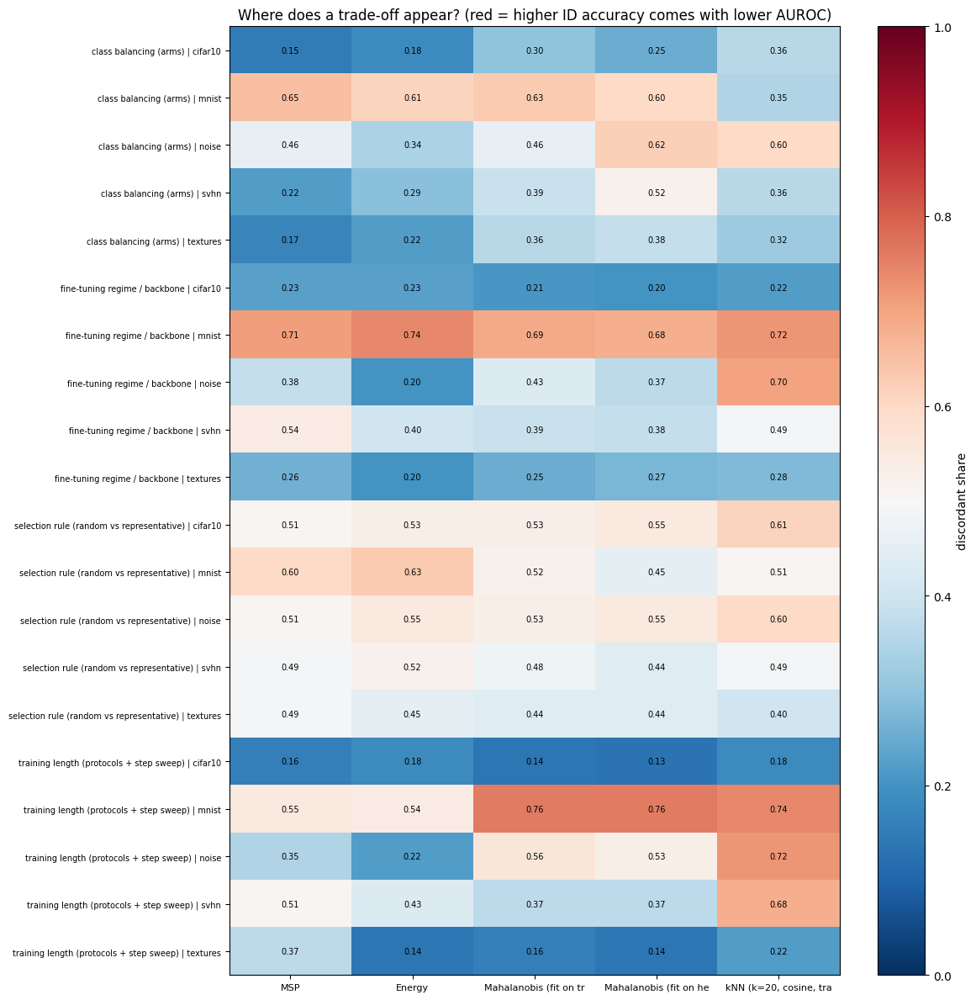

Cells of the consolidated table with a trade-off signal (discordant share > 0.6 AND within-cell rho < 0):
                               experiment      score     ood  pairs  discordant_share  rho_within  p_within
 training length (protocols + step sweep) maha_train   mnist    532             0.758      -0.645     0.000
 training length (protocols + step sweep)   maha_val   mnist    532             0.763      -0.655     0.000
 training length (protocols + step sweep)        knn    svhn    532             0.679      -0.000     0.997
 training length (protocols + step sweep)        knn   mnist    532             0.741      -0.702     0.000
 training length (protocols + step sweep)        knn   noise    532             0.720      -0.254     0.007
            fine-tuning regime / backbone        msp   mnist    312             0.705      -0.554     0.000
            fine-tuning regime / backbone     energy   mnist    312             0.740      -0.647     0.000
            fine-tuning regime

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("30 consolidated", needs=['25.2a', '25.2b', '27.2a', '27.2b', '27.2c', '27.2d', '28.1']):
    res_proto, PROTOS = get_res_proto(); res_reg, REGS, REF21 = get_res_reg(); res_ctrl, ARMS, CPROTOS, CSELS = get_res_ctrl()
    cons = [discordance(res_proto[~res_proto.shared_full_run], ["strategy", "fraction"], SCORES, OODS, "training length (protocols + step sweep)"),
            discordance(res_reg, ["fraction"], SCORES, OODS, "fine-tuning regime / backbone"),
            discordance(res_ctrl[res_ctrl.protocol == "steps1000"], ["selection", "fraction"], SCORES, OODS, "class balancing (arms)")]
    base_only = base_v2[~base_v2.shared_full_run]
    cons.append(discordance(base_only, ["fraction"], SCORES, OODS, "selection rule (random vs representative)"))
    consolidated = pd.concat(cons, ignore_index=True)
    save_table3(consolidated.round(4), "E6_consolidated_tradeoff.csv", index=False)
    cons_p = consolidated.pivot_table(index=["experiment", "ood"], columns="score", values="discordant_share")[SCORES].round(2)
    save_table3(cons_p, "E6_consolidated_discordant_share.csv")
    print("Share of discordant pairs (higher ID accuracy but LOWER AUROC); 0.5 = no relation, > 0.5 = trade-off, < 0.5 = both improve together:")
    display(cons_p)

    fig, ax = plt.subplots(figsize=(12, 0.5 * len(cons_p) + 2))
    im = ax.imshow(cons_p.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(SCORES))); ax.set_xticklabels([SCORE_NAME[s][:22] for s in SCORES], fontsize=8)
    ax.set_yticks(range(len(cons_p))); ax.set_yticklabels([f"{a} | {b}" for a, b in cons_p.index], fontsize=7)
    for i in range(cons_p.shape[0]):
        for j in range(cons_p.shape[1]): ax.text(j, i, f"{cons_p.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, label="discordant share"); ax.set_title("Where does a trade-off appear? (red = higher ID accuracy comes with lower AUROC)")
    plt.tight_layout(); save_fig3("E6_consolidated_tradeoff.png"); plt.show()

    print("Cells of the consolidated table with a trade-off signal (discordant share > 0.6 AND within-cell rho < 0):")
    sig = consolidated[(consolidated.discordant_share > 0.6) & (consolidated.rho_within < 0)]
    print(sig.round(3).to_string(index=False) if len(sig) else "  none")
    print("\nAverage discordant share per experiment axis (all scores and OOD sets):")
    print(consolidated.groupby("experiment").discordant_share.mean().round(3).to_string())
    finish("30 consolidated")

# 31. Save the Part E outputs

In [ ]:
import os
if not os.path.exists("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    from google.colab import drive; drive.mount("/content/drive")
if globals().get("LIB_MTIME") != os.path.getmtime("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py"):
    exec(open("/content/drive/MyDrive/OOD_ID_Baseline_Results/ood_lib.py").read())

if start("31 save settings", needs=['25.2a', '25.2b', '27.2a', '27.2b', '27.2c', '27.2d', '28.1']):
    json.dump({"baseline_dir": BASELINE_DIR, "part2_dir": PART2_DIR, "train_steps_baseline": TRAIN_STEPS, "batch_size": BATCH_SIZE,
               "epoch_budgets": EPOCH_BUDGETS, "step_sweep": {str(k): v for k, v in STEP_SWEEP.items()}, "seeds": SEEDS,
               "control_fractions": CTRL_FRACS, "control_balances": CTRL_BALANCES, "control_selections": CTRL_SELECTIONS,
               "control_processes": CTRL_PROCESSES, "control_ext_processes": CTRL_EXT_PROCESSES, "control_ext_fractions": CTRL_EXT_FRACS,
               "control_epoch_protocols": CTRL_EPOCH_PROTOCOLS, "regimes": {k: str(v) for k, v in REGIMES.items()}, "regime_fractions": REGIME_FRACS,
               "backbones": BACKBONES, "scores": SCORES, "ood_sets": OODS,
               "mahalanobis": {"max_images_per_class": MAHA_MAX_PER_CLASS, "shrinkage": MAHA_SHRINK, "features": "[CLS] of the last layer (after final LayerNorm)"},
               "knn": {"k": KNN_K, "metric": "cosine on L2-normalised features"},
               "class_weighted_loss": "w_c = N / (C_present * n_c) from the training subset",
               "balanced_sampling": "class chosen uniformly among present classes, image uniform within class, with replacement",
               "imbalance_ratio": IMB_RATIO, "lt_seed": LT_SEED, "n_lt_pool": int(N_LT)},
              open(os.path.join(PART3_DIR, "part3_settings.json"), "w"), indent=2, default=str)
    snap = {"base_v2": base_v2, "res_proto": get_res_proto()[0], "res_ctrl": get_res_ctrl()[0], "res_reg": get_res_reg()[0], "ctrl_tests": get_ctrl_tests()}
    for k, f in [("consolidated", "E6_consolidated_tradeoff.csv"), ("reg_tests", "E4_paired_tests_regime_vs_baseline.csv"),
                 ("proto_tests", "E1_paired_tests_protocol_vs_steps1000.csv"), ("tradeoff", "E2_tradeoff_correlations.csv")]:
        p = os.path.join(DIRS3["tables"], f)
        if os.path.exists(p): snap[k] = pd.read_csv(p)
    with open(os.path.join(DIRS3["tables"], "snapshot_result_tables.pkl.tmp"), "wb") as fh: pickle.dump(snap, fh)
    os.replace(os.path.join(DIRS3["tables"], "snapshot_result_tables.pkl.tmp"), os.path.join(DIRS3["tables"], "snapshot_result_tables.pkl"))
    print("snapshot saved:", list(snap))
    print(f"All Part E outputs are saved in {PART3_DIR}")
    for sub_, path in DIRS3.items():
        files = sorted(os.listdir(path))
        size = sum(os.path.getsize(os.path.join(path, f)) for f in files if os.path.isfile(os.path.join(path, f)))
        print(f"  {sub_:<12} {len(files):>4} files  ({size/1e6:.1f} MB)")
    finish("31 save settings")

snapshot saved: ['base_v2', 'res_proto', 'res_ctrl', 'res_reg', 'ctrl_tests', 'consolidated', 'reg_tests', 'proto_tests', 'tradeoff']
All Part E outputs are saved in /content/drive/MyDrive/OOD_ID_Baseline_Results/2026-10-03_13-22/outputs_part3
  figures        22 files  (7.4 MB)
  tables         51 files  (6.4 MB)
  runs          537 files  (9.4 MB)
  posthoc        33 files  (0.1 MB)
  predictions   537 files  (6280.8 MB)
[31 save settings] finished and marked as done.
